# Multi-TPC original group-disjoint held-out evaluation


In [1]:
# Configuration (final evaluation mode)
from pathlib import Path
import os
import numpy as np
import pandas as pd
from IPython.display import display
if globals().get('_V17_PROFESSIONAL_FINAL_KERNEL_SENTINEL', False):
    raise RuntimeError('R11 audited development/final runs require a fresh kernel for every Run All. Restart the kernel, set the intended phase flags in Cell 1, then Run All from the top.')
_root_env = os.environ.get('MULTITPC_ROOT', '').strip()
_root_candidates = []
if _root_env:
    _root_candidates.append(Path(_root_env).expanduser())
for _base in [Path.cwd(), *Path.cwd().parents]:
    _root_candidates.extend([
        _base / 'data' / 'Multi-TPC',
        _base / 'Multi-TPC',
    ])
MULTITPC_ROOT = next((p.resolve() for p in _root_candidates if p.exists()), None)
if MULTITPC_ROOT is None:
    raise FileNotFoundError(
        "Set MULTITPC_ROOT to the Multi-TPC dataset/project root before running."
    )
USER_MULTITPC_ROOT = str(MULTITPC_ROOT)
RUN_VERSION = 'r11_taskabc_aux_audio_v7_fresh_kernel_audited'
CACHE_SCHEMA_REV = '2026-08-24-v17.4-professional-final-r4'
FINAL_RESULT_SCHEMA_REV = '2026-08-28-r11-taskabc-aux-audio-v7'
ALIGNMENT_CONTRACT_REV = 'offset-only-exact-60hz-v17.4-absolute-final-r3'
SEED = 1212
R11_ROOT = MULTITPC_ROOT / 'runs' / 'MultiTPC_MASTER_R11_TASKABC_AUX_AUDIO_V7'
R11_MODEL_ROOT = R11_ROOT / 'models'
R11_RESULT_ROOT = R11_ROOT / 'results'
R11_FIG_ROOT = R11_ROOT / 'figures'
R11_DEV_ROOT = R11_ROOT / 'development'
R11_FINAL_ROOT = R11_ROOT / 'final'
R11_CACHE_ROOT = R11_ROOT / 'cache'
R10_ROOT = R11_ROOT / 'protected_r10_1_baseline'
R10_MODEL_ROOT = R10_ROOT / 'models'
R10_RESULT_ROOT = R10_ROOT / 'results'
R10_FIG_ROOT = R10_ROOT / 'figures'
R10_DEV_ROOT = R10_ROOT / 'development'
R10_FINAL_ROOT = R10_ROOT / 'final'
for _d in [R11_ROOT, R11_MODEL_ROOT, R11_RESULT_ROOT, R11_FIG_ROOT, R11_DEV_ROOT, R11_FINAL_ROOT, R11_CACHE_ROOT, R10_ROOT, R10_MODEL_ROOT, R10_RESULT_ROOT, R10_FIG_ROOT, R10_DEV_ROOT, R10_FINAL_ROOT]:
    _d.mkdir(parents=True, exist_ok=True)
R10_FAST_DEVELOPMENT = True
R10_SYS1_TARGET_RECALL = 0.9
R10_SYS1_PREFERRED_RECALL = 0.95
R10_SYS1_MAX_CPM = 150.0
R10_SYS1_NMS_GRID_S = [0.12, 0.18, 0.25, 0.35, 0.5]
R10_SYS1_SCORE_QUANTILES = [0.45, 0.55, 0.65, 0.72, 0.78, 0.84, 0.88, 0.91, 0.94, 0.96, 0.975, 0.985, 0.992]
R10_SYS1_POS_WEIGHT_MULT = 1.35
R10_SYS1_NUM_LEAVES = 47
R10_SYS1_N_ESTIMATORS = 900
R10_SYS1_LEARNING_RATE = 0.02
R10_VERIFIER_N_ESTIMATORS = 700
R10_VERIFIER_LEARNING_RATE = 0.015
R10_VERIFIER_NUM_LEAVES = 31
R10_VERIFIER_MIN_CHILD = 40
R10_META_N_ESTIMATORS = 400
R10_META_LEARNING_RATE = 0.03
R10_META_NUM_LEAVES = 15
R10_META_MIN_CHILD = 60
R10_POS_WEIGHT_MULT = 1.25
R10_CONTEXT_WINDOWS_S = [0.3, 1.0, 2.0]
R10_TIMING_CLIP_S = 0.6
R10_EVENT_NMS_GRID_S = [0.2, 0.3, 0.4, 0.55, 0.7, 0.9, 1.1, 1.4]
R10_EVENT_SCORE_QUANTILES = [0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.5, 0.6, 0.7, 0.78, 0.84, 0.88, 0.92, 0.95]
R10_PRIMARY_FAP_ONLY = True
R10_BC_FAP_AUXILIARY = True
R10_FREEZE_MIN_SYS1_RECALL = 0.9
R10_FREEZE_MAX_SYS1_CPM = 150.0
R10_FREEZE_MIN_TASKC_P = 0.4
R10_FREEZE_MIN_TASKC_R = 0.5
R10_FREEZE_MIN_TASKC_F1 = 0.5
R10_FREEZE_PATH = R10_DEV_ROOT / 'r10_frozen_settings.json'
R10_STATUS_PATH = R10_DEV_ROOT / 'r10_development_status.json'
R10_MODEL_BUNDLE_PATH = R10_MODEL_ROOT / 'r10_candidate_meta_models.pkl'
R10_ACTIVITY_BUNDLE_PATH = R10_MODEL_ROOT / 'r10_activity_full.pt'
R10_FAP_BUNDLE_PATH = R10_MODEL_ROOT / 'r10_fap_full.pt'
R10_RESUME_IN_MEMORY = True
R10_STACK_REV = 'r10_1_bc_focal_logo_v1'
R11_STACK_REV = 'r11_taskabc_aux_audio_v7_fresh_kernel_audited'
R11_REJECT_N_ESTIMATORS = 500
R11_REJECT_LEARNING_RATE = 0.02
R11_REJECT_NUM_LEAVES = 15
R11_REJECT_MIN_CHILD = 55
R11_HARD_NEGATIVE_WEIGHT = 3.5
R11_HIGH_SCORE_NEGATIVE_WEIGHT = 2.0
R11_REJECT_SCORE_MODES = ('meta', 'rr_fap', 'rejector', 'meta_reject_geomean', 'rr_reject_geomean', 'triple_geomean', 'robust_blend')
R11_PAST_DENSITY_WINDOWS_S = (0.5, 1.0, 2.0)
R11_REJECT_FEATURE_REV = 'compact_rich_dynamics_role_relative_v1'
R11_TIMING_ROUTE = 'oof_subtype_head_with_proposer_fallback'
R11_ROBUST_STD_PENALTY = 0.5
R11_ROBUST_MIN_F1_BONUS = 0.1
R11_OOF_MIN_MEAN_PRECISION = 0.4
R11_OOF_MIN_MEAN_RECALL = 0.55
R11_EVENT_NMS_GRID_S = (0.5, 0.7, 0.9, 1.1, 1.4, 1.7, 2.0)
R11_EVENT_SCORE_QUANTILES = (0.08, 0.12, 0.16, 0.2, 0.25, 0.3, 0.35, 0.4, 0.5, 0.6, 0.7, 0.78, 0.84, 0.88, 0.92, 0.95)
R11_TIMING_CLIP_S = 1.0
R11_TIMING_MIN_POSITIVES = 24
R11_ADOPTION_MIN_DELTA_F1 = 0.003
R11_MAX_ALLOWED_PRECISION_DROP = 0.01
R11_FREEZE_MIN_P = 0.4
R11_FREEZE_MIN_R = 0.5
R11_FREEZE_MIN_F1 = 0.51
R11_FREEZE_MIN_SYS1_RECALL = 0.9
R11_RUN_WAVLM_ECAPA_ABLATION = True
R11_WAVLM_MODEL_NAME = 'microsoft/wavlm-large'
R11_ECAPA_MODEL_SOURCE = 'speechbrain/spkrec-ecapa-voxceleb'
R11_WAVLM_CONTEXT_S = 4.0
R11_WAVLM_RECENT_S = 0.5
R11_WAVLM_PROJECTION_DIM = 48
R11_ECAPA_SEGMENT_S = 1.25
R11_ECAPA_MIN_SEG_S = 0.25
R11_AUDIO_PRE_GATE_FACTOR = 0.75
R11_AUDIO_MAX_TRAIN_REGIONS = 2500
R11_AUDIO_CALIBRATOR_C = 0.3
R11_RUN_FROZEN_VOX_ABLATION = True
R11_VOX_PROJECTION_DIM = 48
R11_VOX_MAX_TRAIN_REGIONS = 1500
R11_VOX_CALIBRATOR_C = 0.3
PRIMARY_EVENT_TOLERANCE = 1.0
EVENT_TOLERANCES = [0.5, 0.7, 1.0]
R11V5_TASKA_NEGATIVE_RATIO = 2.0
R11V5_TASKA_THRESHOLD_OBJECTIVE = 'MacroF1_then_F1_then_BAcc'
R11V5_TASKB_TOLERANCES = tuple((float(x) for x in EVENT_TOLERANCES))
R11V5_AUDIO_FUSION_ALPHAS = (0.25, 0.5, 0.75)
R11V5_AUDIO_NEUTRAL_PROB = 0.5
R11V5_AUDIO_GATE_DIAGNOSTIC_TOLS = tuple((float(x) for x in EVENT_TOLERANCES))
R11V6_REQUIRE_WAVLM_ECAPA_RESULT = True
R11V6_REPORT_NEXT_SPEAKER = True
R11V5_COMPONENTS = ('baseline_oof', 'timing_only', 'rejector_only', 'rejector_plus_timing')
R11V5_TASKA_PATH = R11_RESULT_ROOT / 'r11v5_taskA_oracle_shift_hold.csv'
R11V5_TASKB_PATH = R11_RESULT_ROOT / 'r11v5_taskB_candidate_classification.csv'
R11V5_TASKC_PATH = R11_RESULT_ROOT / 'r11v5_taskC_component_audio_comparison.csv'
R11V5_GATE_PATH = R11_RESULT_ROOT / 'r11v5_audio_gate_diagnostics.csv'
R11_STATUS_PATH = R11_DEV_ROOT / 'r11_development_status.json'
R11_FREEZE_PATH = R11_DEV_ROOT / 'r11_frozen_settings.json'
R11_MODEL_BUNDLE_PATH = R11_MODEL_ROOT / 'r11_models.pkl'
R11_VAL_PRED_PATH = R11_RESULT_ROOT / 'r11_val_predictions.csv'
R11_BRANCH_TABLE_PATH = R11_RESULT_ROOT / 'r11_branch_comparison.csv'
R11_OOF_SEARCH_PATH = R11_RESULT_ROOT / 'r11_oof_operating_point_search.csv'
R11_INTERVAL_PATH = R11_RESULT_ROOT / 'r11_transition_interval_metrics.json'
RUN_MODE = 'final'
DEVELOPMENT_VAL_GROUP_INDEX = 1
DEVELOPMENT_LOCKED_TEST_GROUP_INDEX = 0
FINAL_ARCHITECTURE_FROZEN = True
FINAL_VAL_OFFSET = 1
FRAME_HZ = 60.0
TARGET_SR = 16000
RESOURCE_PROFILE = 'single_12gb_gpu_gpu_first_sequential_v17'
CUDA_MIN_FREE_GB_FOR_MAIN = float(os.environ.get('CUDA_MIN_FREE_GB_FOR_MAIN', '6.0'))
FORCE_MAIN_CPU = bool(int(os.environ.get('FORCE_MAIN_CPU', '0')))
ASR_FORCE_CPU = False
os.environ.setdefault('PYTORCH_CUDA_ALLOC_CONF', 'expandable_segments:True')
os.environ.setdefault('TOKENIZERS_PARALLELISM', 'false')
LEE24_TRAIN_BATCH_SIZE = 128
LEE24_EVAL_BATCH_SIZE = 256
DISTILBERT_BATCH_SIZE = 8
TRIADIC_VAP_MAX_PHYSICAL_BATCH = 1
ALIGNMENT_SEARCH_MAX_S = 2.0
ALIGNMENT_WARN_ABS_S = 0.5
ALIGNMENT_BOUNDARY_MARGIN_S = 0.05
MODALITY_ROW_MISMATCH_MAX_S = 1.0
NATIVE_NTT_MIN_GAP_S = 0.2
ITT_RESOLUTION_S = 1.0
ITT_MIN_SUCCESSFUL_FLOOR_S = 0.3
RESEARCH_EVENT_ONTOLOGY_REV = 'unique-event-frame-ambiguous-prev-aware-r1'
IPU_PAUSE_S = 0.2
IPU_MAX_FRAMES = 1755
LEE24_WINDOW_S = 0.5
LEE24_STEP_S = 0.1
LEE24_TEXT_HISTORY_S = 100.0
RUN_LEE24_CONTINUOUS = False
RUN_TRIADIC_VAP_STRICT = False
RUN_MODALITY_ABLATIONS = False
V17_MODALITY_ABLATION_MODES = ('audio_only', 'activity_only', 'fap_only', 'text_only', 'gaze_only', 'prosody_only', 'motion_only', 'audio_activity', 'audio_fap', 'audio_text', 'audio_gaze', 'activity_fap_text', 'audio_activity_fap', 'without_audio', 'full_no_fap', 'full')
AUTO_INSTALL_LIGHT_DEPENDENCIES = False
TRIADIC_VAP_EFFECTIVE_BATCH_SIZE = 8
TRIADIC_VAP_ALLOW_OOM_FALLBACK = True
TRIADIC_VAP_CHUNK_S = 20.0
TRIADIC_VAP_CHUNK_STRIDE_S = 20.0
TRIADIC_VAP_FRAME_HZ = 50.0
ANNOTATION_SCHEMA_OVERRIDE = None
PROSODY_COLUMN_OVERRIDE = None
V17_PROPOSED_SCALER = 'standard'
V17_DIAGNOSTIC_SCALER = 'minmax'
V17_SCALER_CLIP = 8.0
PROPOSED_TEXT_SOURCE = 'strict_online_none'
RUN_OFFLINE_ASR_DIAGNOSTIC = False
ASR_MODEL_NAME = 'small.en'
V17_DIAG_WINDOW_S = 0.5
V17_DIAG_STEP_S = 0.1
V17_DIAG_HIDDEN = 256
V17_DIAG_EPOCHS = 20
V17_DIAG_PATIENCE = 4
V17_DIAG_LR = 0.001
V17_DIAG_BATCH_SIZE = 128
V17_DIAG_WINDOW_F1_GATE = 0.65
V17_DIAG_WINDOW_AUROC_GATE = 0.8
V17_ACTIVITY_CONTEXT_S = 2.0
V17_ACTIVITY_STEP_S = 0.1
V17_ACTIVITY_HIDDEN = 96
V17_ACTIVITY_EPOCHS = 18
V17_ACTIVITY_PATIENCE = 4
V17_ACTIVITY_BATCH_SIZE = 192
V17_ACTIVITY_LR = 0.0008
V17_ACTIVITY_MACRO_F1_GATE = 0.65
V17_ACTIVITY_BC_F1_GATE = 0.3
V17_ACTIVITY_THRESHOLD_GRID = np.linspace(0.1, 0.9, 17)
V17_ACTIVITY_BC_BALANCE = 'inverse_prevalence'
V17_ACTIVITY_BC_POS_WEIGHT_CAP = 16.0
V17_ACTIVITY_BC_FOCAL_GAMMA = 2.0
V17_ACTIVITY_BC_LOSS_SCALE = 2.5
V17_ACTIVITY_SELECT_BC_BLEND = 0.5
V17_ACTIVITY_BC_THRESHOLD_GRID = np.unique(np.r_[0.02, 0.05, 0.075, V17_ACTIVITY_THRESHOLD_GRID]).astype(float)
V17_FAP_CONTEXT_S = 3.0
V17_FAP_STEP_S = 0.1
V17_FAP_BINS = [(0.0, 0.5), (0.5, 1.0), (1.0, 1.5), (1.5, 2.0)]
V17_FAP_HIDDEN = 128
V17_FAP_EPOCHS = 18
V17_FAP_PATIENCE = 4
V17_FAP_BATCH_SIZE = 160
V17_FAP_LR = 0.0008
V17_FAP_PRIMARY_OCCUPANCY = 0.5
V17_FAP_BC_ANY_OCCURRENCE = True
V17_FAP_THRESHOLD_GRID = np.linspace(0.05, 0.8, 31)
V17_FAP_POS_WEIGHT_CAP = 20.0
V17_FAP_BC_POS_WEIGHT_CAP = 40.0
V17_FAP_BC_FOCAL_GAMMA = 2.0
V17_FAP_BC_LOSS_SCALE = 3.0
V17_FAP_SELECT_BC_BLEND = 0.75
V17_SYS2_STEP_S = 0.1
V17_SYS2_CONTEXT_S = 4.0
V17_SYS2_FORECAST_S = 0.5
V17_SYS2_HIDDEN = 256
V17_SYS2_FAP_EMBED = 64
V17_SYS2_EPOCHS = 16
V17_SYS2_PATIENCE = 4
V17_SYS2_BATCH_SIZE = 128
V17_SYS2_EVAL_BATCH_SIZE = 256
V17_SYS2_LR = 0.001
V17_SYS2_DROPOUT = 0.1
V17_SYS2_GRAD_CLIP = 3.0
V17_SYS2_VAL_PRECISION_FLOOR = 0.5
V17_SYS2_VAL_RECALL_FLOOR = 0.5
V17_SYS2_WINDOW_F1_GATE = 0.65
V17_SYS2_WINDOW_AUROC_GATE = 0.8
V17_SYS2_THRESHOLD_GRID = np.linspace(0.05, 0.95, 37)
V17_LOSS_SHIFT = 1.0
V17_LOSS_NEXT = 0.2
V17_LOSS_TTE = 0.2
V17_LOSS_CONFUSION = 0.25
V17_LOSS_TYPE_SHIFT = 0.25
V17_CONFIRM_CLEAN_HOLD_RATIO = 1.0
V17_CONSENSUS_EPS = 1e-05
V17_AUGMENTATION_CONDITIONS = ('no_aug', 'synthetic_only', 'diffusion_only', 'full')
V17_MIXUP_ALPHA = 0.25
V17_MIXUP_PROB = 0.25
V17_DIFFUSION_STEPS = 24
V17_DIFFUSION_EPOCHS = 2
V17_DIFFUSION_MAX_WINDOWS = 12000
V17_DIFFUSION_APPLY_P = 0.2
V17_DIFFUSION_STRENGTH_STEP = 5
V17_ROBUST_NOISE_STD = 0.015
V17_MODALITY_DROPOUT_P = 0.12
V17_TIME_MASK_P = 0.1
SYS1_COVERAGE_ANCHOR_S = 0.5
SYS1_TARGET_RECALL = 0.9
SYS1_MAX_CANDIDATES_PER_MIN = 60.0
SYS1_BUDGET_GRID = [30.0, 45.0, 60.0]
SYS1_NMS_S = 0.22
SYS1_NMS_GRID_S = [0.16, 0.22, 0.3]
SYS1_RELEVANCE_SIGMA_S = 0.22
SYS1_CAUSAL_ROLLING_WINDOW_S = 2.0
SYS1_CAUSAL_THRESHOLD_GRID = np.linspace(0.01, 0.99, 99)
V17_REGION_LINK_S = 0.6
V17_REGION_MAX_SPAN_S = 1.2
V17_REGION_RANK_C = 0.5
V17_REGION_PRECISION_FLOOR = 0.5
V17_REGION_RECALL_FLOOR = 0.5
RUN_VOX_TRANSFER = False
VOX_FEATURE_BATCH_SIZE = int(os.environ.get('VOX_FEATURE_BATCH_SIZE', '1'))
KNOWN_VOX_CHECKPOINT = ''  # set VOX_SYS1_CHECKPOINT explicitly if this optional comparator branch is used
VOX_SYS1_CHECKPOINT = os.environ.get('VOX_SYS1_CHECKPOINT', '').strip()
if not VOX_SYS1_CHECKPOINT and Path(KNOWN_VOX_CHECKPOINT).expanduser().exists():
    VOX_SYS1_CHECKPOINT = KNOWN_VOX_CHECKPOINT
VOX_EXPERIMENT_ROOT = os.environ.get('VOX_EXPERIMENT_ROOT', '').strip()
VOX_MODEL_NAME_OVERRIDE = os.environ.get('VOX_MODEL_NAME', '').strip() or None
_vox_ctx_env = os.environ.get('VOX_CONTEXT_S', '').strip()
VOX_TRANSFER_CONTEXT_S = float(_vox_ctx_env) if _vox_ctx_env else None
VOX_TEMPORAL_PYRAMID_S = [(0.0, 0.25), (0.25, 0.5), (0.5, 1.0), (1.0, 2.0), (2.0, 3.0)]
V17_VOX_PROJECTOR_DIM = 32
V17_VOX_PROJECTOR_MAX_TRAIN_POINTS = 128
V17_VOX_PROJECTOR_MIN_GAP_S = 1.0
V17_VOX_CALIBRATOR_C = 0.25
V17_VOX_PRIMARY_MIN_DELTA_F1 = 1e-06
V17_UPSTREAM_DIAGNOSTIC_POLICY = 'report_only'
V17_DEVELOPMENT_PERFORMANCE_POLICY = 'complete_then_freeze_if_hard_gates_pass'
V17_SYS2_PRIMARY_SCORE = 'shift_probability'
V17_ENFORCE_DEVELOPMENT_GATES = True
V17_ALLOW_GATE_OVERRIDE = bool(int(os.environ.get('V17_ALLOW_GATE_OVERRIDE', '0')))
RUN_CONFIRMATORY_LOCKED_TEST = True
RUN_SEVEN_GROUP_ROBUSTNESS = False
RESUME_FINAL_FOLDS = True
RUN_RESEARCH_NATIVE_DENSE_BASELINE = True
RUN_FEATURE_MATCHED_DENSE_BASELINE = True
RUN_FINAL_COMPARATOR_FOLDS = True
RUN_FINAL_FAP_ABLATION = True
V17_DENSE_BASELINE_OFFSET_GRID = [0.1, 0.2, 0.3, 0.4, 0.5]
V17_DENSE_BASELINE_NMS_GRID_S = [0.15, 0.25, 0.35, 0.5]
V17_NEXT_FAP_BIN_WEIGHTS = np.asarray([1.0, 0.75, 0.5, 0.25], dtype=np.float32)
if not MULTITPC_ROOT.exists():
    raise FileNotFoundError(f'Multi-TPC root does not exist: {MULTITPC_ROOT}\nSet USER_MULTITPC_ROOT or export MULTITPC_ROOT=/absolute/path/to/Multi-TPC.')
RUN_ROOT = R11_ROOT / 'upstream_v17_contract'
CACHE_ROOT = RUN_ROOT / f'cache_{CACHE_SCHEMA_REV}'
MODEL_ROOT = RUN_ROOT / 'models'
RESULT_ROOT = RUN_ROOT / 'results'
FIG_ROOT = RUN_ROOT / 'figures'
V17_TIMELINE_ROOT = CACHE_ROOT / 'v17_timeline'
V17_STACK_ROOT = CACHE_ROOT / 'v17_fold_stacks'
V17_DEV_ROOT = RUN_ROOT / 'development'
V17_FINAL_ROOT = RUN_ROOT / 'final_evaluation'
for _d in [RUN_ROOT, CACHE_ROOT, MODEL_ROOT, RESULT_ROOT, FIG_ROOT, V17_TIMELINE_ROOT, V17_STACK_ROOT, V17_DEV_ROOT, V17_FINAL_ROOT]:
    _d.mkdir(parents=True, exist_ok=True)
DETERMINISTIC_CACHE_ROOT = CACHE_ROOT / 'deterministic_alignment'
DETERMINISTIC_CACHE_ROOT.mkdir(parents=True, exist_ok=True)
ALLOW_LEGACY_ALIGNMENT_CACHE_REUSE = False
VOXCONVERSE_RESULTS_JSON = os.environ.get('VOXCONVERSE_RESULTS_JSON', '').strip()
print('Multi-TPC root:', MULTITPC_ROOT)
print('Run version:', RUN_VERSION)
print('Run root:', RUN_ROOT)
print('R11/R10 System-1 max CPM:', R10_SYS1_MAX_CPM, '(legacy V17 diagnostic cap:', SYS1_MAX_CANDIDATES_PER_MIN, ')')
print('V17 FAP bins:', V17_FAP_BINS)
print('Development gates enforced:', V17_ENFORCE_DEVELOPMENT_GATES, 'override:', V17_ALLOW_GATE_OVERRIDE)
print('Strict-online headline text source:', PROPOSED_TEXT_SOURCE)
print('Final TEST flags: confirmatory=', RUN_CONFIRMATORY_LOCKED_TEST, 'robustness=', RUN_SEVEN_GROUP_ROBUSTNESS)
if float(PRIMARY_EVENT_TOLERANCE) != 1.0:
    raise RuntimeError('V7 primary Task-C tolerance drifted from ±1.00 s.')
if tuple(map(float, EVENT_TOLERANCES)) != (0.5, 0.7, 1.0):
    raise RuntimeError('V7 EVENT_TOLERANCES drifted from the frozen evaluation contract.')
if tuple(map(float, R11V5_TASKB_TOLERANCES)) != tuple(map(float, EVENT_TOLERANCES)):
    raise RuntimeError('V7 Task-B tolerances do not match EVENT_TOLERANCES.')
if tuple(map(float, R11V5_AUDIO_GATE_DIAGNOSTIC_TOLS)) != tuple(map(float, EVENT_TOLERANCES)):
    raise RuntimeError('V7 audio gate diagnostic tolerances do not match EVENT_TOLERANCES.')
_V17_PROFESSIONAL_FINAL_KERNEL_SENTINEL = True
print('V7 Cell-1 bootstrap audit: PASS')

# Final-mode safety checks; not user settings.
FINAL_TEST_GROUP_ID = "01-28-2022"
FINAL_TEST_PROTOCOL_REV = "2026-09-07-final-locked-test-v6-disk-resume"
if RUN_MODE != "final" or not FINAL_ARCHITECTURE_FROZEN or not RUN_CONFIRMATORY_LOCKED_TEST:
    raise RuntimeError("This notebook is final-only and requires the frozen confirmatory TEST flags.")
for _forbidden_name in [n for n in globals() if n.startswith("FORCE_")]:
    if bool(globals()[_forbidden_name]):
        raise RuntimeError(f"Retraining/override flag must be False in FINAL_TEST: {_forbidden_name}")

Multi-TPC root: <MULTITPC_ROOT>
Run version: r11_taskabc_aux_audio_v7_fresh_kernel_audited
Run root: <MULTITPC_ROOT>/runs/MultiTPC_MASTER_R11_TASKABC_AUX_AUDIO_V7/upstream_v17_contract
R11/R10 System-1 max CPM: 150.0 (legacy V17 diagnostic cap: 60.0 )
V17 FAP bins: [(0.0, 0.5), (0.5, 1.0), (1.0, 1.5), (1.5, 2.0)]
Development gates enforced: True override: False
Strict-online headline text source: strict_online_none
Final TEST flags: confirmatory= True robustness= False
V7 Cell-1 bootstrap audit: PASS


In [2]:
# Reproducibility, hashing and resource helpers
from IPython.display import display
import hashlib
import time
import sys,re,json,math,time,random,hashlib,pickle,warnings,subprocess,importlib.util,importlib.metadata,gc,inspect
from functools import lru_cache
from typing import Dict,List,Tuple,Optional,Any
warnings.filterwarnings("default")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.optimize import linear_sum_assignment
from scipy.signal import find_peaks
from scipy.stats import t as student_t
from sklearn.metrics import (
    precision_recall_fscore_support,f1_score,accuracy_score,
    balanced_accuracy_score,confusion_matrix,roc_auc_score,
    average_precision_score,classification_report,matthews_corrcoef
)
from sklearn.preprocessing import MinMaxScaler,StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import GroupKFold
from sklearn.ensemble import HistGradientBoostingClassifier,RandomForestClassifier,RandomForestRegressor

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset,DataLoader,TensorDataset,Subset

try:
    import soundfile as sf
except Exception as e:
    raise ImportError("soundfile is required. Install with: pip install soundfile") from e

LIGHTGBM_AVAILABLE=importlib.util.find_spec("lightgbm") is not None
TRANSFORMERS_AVAILABLE=importlib.util.find_spec("transformers") is not None
FASTER_WHISPER_AVAILABLE=importlib.util.find_spec("faster_whisper") is not None
XGBOOST_AVAILABLE=importlib.util.find_spec("xgboost") is not None
CATBOOST_AVAILABLE=importlib.util.find_spec("catboost") is not None

if AUTO_INSTALL_LIGHT_DEPENDENCIES:
    missing=[]
    for package,ok in [
        ("lightgbm",LIGHTGBM_AVAILABLE),
        ("transformers",TRANSFORMERS_AVAILABLE),
        ("faster-whisper",FASTER_WHISPER_AVAILABLE),
        ("xgboost",XGBOOST_AVAILABLE),
        ("catboost",CATBOOST_AVAILABLE),
    ]:
        if not ok: missing.append(package)
    if missing:
        subprocess.check_call([sys.executable,"-m","pip","install","-q",*missing])
        importlib.invalidate_caches()
        LIGHTGBM_AVAILABLE=importlib.util.find_spec("lightgbm") is not None
        TRANSFORMERS_AVAILABLE=importlib.util.find_spec("transformers") is not None
        FASTER_WHISPER_AVAILABLE=importlib.util.find_spec("faster_whisper") is not None
        XGBOOST_AVAILABLE=importlib.util.find_spec("xgboost") is not None
        CATBOOST_AVAILABLE=importlib.util.find_spec("catboost") is not None

if RUN_OFFLINE_ASR_DIAGNOSTIC and not FASTER_WHISPER_AVAILABLE:
    raise ImportError(
        "RUN_OFFLINE_ASR_DIAGNOSTIC=True requires faster-whisper. "
        "Install with `python -m pip install faster-whisper` or set RUN_OFFLINE_ASR_DIAGNOSTIC=False."
    )
if PROPOSED_TEXT_SOURCE not in {"strict_online_none","reference_words"}:
    raise ValueError(
        "Headline PROPOSED_TEXT_SOURCE must be 'strict_online_none' or 'reference_words'. "
        "Whole-recording automatic ASR is intentionally prohibited from the strict-online headline path."
    )
if (RUN_LEE24_CONTINUOUS or RUN_VOX_TRANSFER) and not TRANSFORMERS_AVAILABLE:
    raise ImportError(
        "transformers is required by the selected Lee2024/Vox branches. "
        "Install with `python -m pip install transformers`."
    )

random.seed(SEED);np.random.seed(SEED);torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)

def stable_seed(tag, base=SEED):
    """Stable per-stage seed independent of Python's randomized hash()."""
    raw=f"{int(base)}::{str(tag)}".encode("utf8")
    return int.from_bytes(hashlib.sha256(raw).digest()[:4],"little") & 0x7fffffff

def set_run_seed(tag, base=SEED):
    """Reset Python/NumPy/PyTorch RNGs for a reproducible training stage."""
    sd=stable_seed(tag,base)
    random.seed(sd);np.random.seed(sd);torch.manual_seed(sd)
    if torch.cuda.is_available():torch.cuda.manual_seed_all(sd)
    return sd

def _v17_sha256_json(obj, n=24):
    raw=json.dumps(obj,sort_keys=True,default=str,separators=(",",":")).encode("utf8")
    return hashlib.sha256(raw).hexdigest()[:int(n)]

def _v17_file_stat_record(path):
    p=Path(path)
    st=p.stat()
    return dict(path=str(p.resolve()),size=int(st.st_size),mtime_ns=int(st.st_mtime_ns))

V17_FILE_HASH_INDEX_PATH = CACHE_ROOT / "required_file_sha256_index.json"
try:
    _V17_FILE_HASH_INDEX = json.loads(V17_FILE_HASH_INDEX_PATH.read_text()) if V17_FILE_HASH_INDEX_PATH.exists() else {}
except Exception:
    _V17_FILE_HASH_INDEX = {}

def _v17_sha256_file(path, block_bytes=8*1024*1024):
    p=Path(path)
    h=hashlib.sha256()
    with p.open("rb") as f:
        while True:
            b=f.read(int(block_bytes))
            if not b:break
            h.update(b)
    return h.hexdigest()

def _v17_file_identity(path):
    """Content identity with a stat guard so unchanged large audio files are not rehashed every run."""
    p=Path(path).resolve();st=p.stat();key=str(p)
    cached=_V17_FILE_HASH_INDEX.get(key,{})
    same=(int(cached.get("size",-1))==int(st.st_size) and int(cached.get("mtime_ns",-1))==int(st.st_mtime_ns) and bool(cached.get("sha256")))
    sha=str(cached["sha256"]) if same else _v17_sha256_file(p)
    rec=dict(path=key,size=int(st.st_size),mtime_ns=int(st.st_mtime_ns),sha256=sha)
    _V17_FILE_HASH_INDEX[key]=rec
    return rec

def _v17_flush_file_hash_index():
    V17_FILE_HASH_INDEX_PATH.write_text(json.dumps(_V17_FILE_HASH_INDEX,indent=2,sort_keys=True))

def _v17_table_fingerprint(df, columns):
    q=df.loc[:,list(columns)].copy() if len(df) else pd.DataFrame(columns=list(columns))
    return _v17_sha256_json(q.sort_values(list(columns)[:2] if len(columns)>=2 else list(columns)).to_dict("records"))

def _v17_package_version(name):
    try:return importlib.metadata.version(name)
    except Exception:return "unknown"

def _cuda_memory_snapshot():
    """Return a fail-safe CUDA memory snapshot in GiB."""
    out={"available":bool(torch.cuda.is_available()),"free_gb":0.0,"total_gb":0.0}
    if not torch.cuda.is_available():
        return out
    try:
        free_b,total_b=torch.cuda.mem_get_info()
        out.update(
            free_gb=float(free_b)/(1024**3),
            total_gb=float(total_b)/(1024**3),
        )
    except Exception as exc:
        out["error"]=repr(exc)
    return out

CUDA_START=_cuda_memory_snapshot()
_cuda_ok=(
    CUDA_START.get("available",False)
    and not FORCE_MAIN_CPU
    and CUDA_START.get("free_gb",0.0)>=float(CUDA_MIN_FREE_GB_FOR_MAIN)
)

DEVICE=torch.device("cuda" if _cuda_ok else "cpu")
AUX_DEVICE=DEVICE
LEGACY_AUX_DEVICE=AUX_DEVICE
LEE24_DEVICE=AUX_DEVICE
TEXT_DEVICE=AUX_DEVICE
TRIADIC_DEVICE=DEVICE
VOX_DEVICE=DEVICE

def release_resources(*objs,note=""):
    """Move supplied torch modules to CPU and release this kernel's CUDA cache."""
    for obj in objs:
        try:
            if isinstance(obj,torch.nn.Module):
                obj.to("cpu")
        except Exception:
            pass
    gc.collect()
    if torch.cuda.is_available():
        try:
            torch.cuda.empty_cache()
            torch.cuda.ipc_collect()
        except Exception:
            pass
    if note:
        snap=_cuda_memory_snapshot()
        print(f"[resource cleanup] {note}: free CUDA={snap.get('free_gb',0.0):.2f} GiB")

def ensure_min_cuda_free(stage,min_free_gb=None):
    """Diagnostic guard; returns False rather than causing a CUDA OOM."""
    if DEVICE.type!="cuda":
        return False
    need=float(CUDA_MIN_FREE_GB_FOR_MAIN if min_free_gb is None else min_free_gb)
    release_resources(note=f"before {stage}")
    snap=_cuda_memory_snapshot()
    ok=snap.get("free_gb",0.0)>=need
    if not ok:
        print(
            f"WARNING: {stage} requested CUDA but only {snap.get('free_gb',0.0):.2f} GiB "
            f"is free (<{need:.2f} GiB). This usually means another process owns the GPU."
        )
    return ok

try:
    torch.set_float32_matmul_precision("high")
except Exception:
    pass

print("Resource profile:",RESOURCE_PROFILE)
print("Main device:",DEVICE)
print("Auxiliary comparator/text device (GPU-first, sequential):",AUX_DEVICE)
if torch.cuda.is_available():
    print("GPU:",torch.cuda.get_device_name(0))
    print(
        f"CUDA at start: total={CUDA_START.get('total_gb',0.0):.2f} GiB, "
        f"free={CUDA_START.get('free_gb',0.0):.2f} GiB; "
        f"main-CUDA minimum={CUDA_MIN_FREE_GB_FOR_MAIN:.2f} GiB"
    )
    if DEVICE.type!="cuda":
        print(
            "CUDA is present but not selected for the main pipeline. "
            "Close other GPU kernels/processes and restart this notebook for CUDA speed."
        )

RESOURCE_RUNTIME_STATUS={
    "profile":RESOURCE_PROFILE,
    "cuda_available":bool(torch.cuda.is_available()),
    "cuda_total_gb":float(CUDA_START.get("total_gb",0.0)),
    "cuda_free_gb_at_start":float(CUDA_START.get("free_gb",0.0)),
    "main_device":str(DEVICE),
    "aux_device":str(AUX_DEVICE),
    "legacy_aux_device":str(LEGACY_AUX_DEVICE),
    "lee24_device":str(LEE24_DEVICE),
    "text_device":str(TEXT_DEVICE),
    "vox_feature_batch":int(VOX_FEATURE_BATCH_SIZE),
    "v17_system2_train_batch":int(V17_SYS2_BATCH_SIZE),
    "v17_system2_eval_batch":int(V17_SYS2_EVAL_BATCH_SIZE),
    "triadic_max_physical_batch":int(TRIADIC_VAP_MAX_PHYSICAL_BATCH),
}
display(pd.DataFrame([RESOURCE_RUNTIME_STATUS]))

print(dict(
    lightgbm=LIGHTGBM_AVAILABLE,
    transformers=TRANSFORMERS_AVAILABLE,
    faster_whisper=FASTER_WHISPER_AVAILABLE,
    xgboost=XGBOOST_AVAILABLE,
    catboost=CATBOOST_AVAILABLE,
))

Resource profile: single_12gb_gpu_gpu_first_sequential_v17
Main device: cuda
Auxiliary comparator/text device (GPU-first, sequential): cuda
GPU: NVIDIA GeForce RTX 4070
CUDA at start: total=11.72 GiB, free=11.35 GiB; main-CUDA minimum=6.00 GiB


,profile,cuda_available,cuda_total_gb,cuda_free_gb_at_start,main_device,aux_device,legacy_aux_device,lee24_device,text_device,vox_feature_batch,v17_system2_train_batch,v17_system2_eval_batch,triadic_max_physical_batch
0,single_12gb_gpu_gpu_first_sequential_v17,True,11.720581,11.353455,cuda,cuda,cuda,cuda,cuda,1,128,256,1


{'lightgbm': True, 'transformers': True, 'faster_whisper': True, 'xgboost': False, 'catboost': False}


In [3]:
# Comparator frozen-path configuration
COMPARATOR_VERSION="multitpc_comparators_final_v1_1_locked_lee24_triadic_muvap"
COMPARATOR_ROOT = R11_ROOT / 'comparators_final_v1'
MODEL_ROOT = COMPARATOR_ROOT / 'models'
RESULT_ROOT = COMPARATOR_ROOT / 'results'
FIG_ROOT = COMPARATOR_ROOT / 'figures'
DEPENDENCY_ROOT = COMPARATOR_ROOT / 'dependencies'
MUVAP_CACHE_ROOT = COMPARATOR_ROOT / 'muvap_cache'
LEE24_AUTO_CACHE_ROOT = COMPARATOR_ROOT / 'lee24_auto_cache'
for _p in (COMPARATOR_ROOT, MODEL_ROOT, RESULT_ROOT, FIG_ROOT, DEPENDENCY_ROOT, MUVAP_CACHE_ROOT, LEE24_AUTO_CACHE_ROOT):
    _p.mkdir(parents=True, exist_ok=True)
RUN_LEE24_CONTINUOUS = False
RUN_LEE24_IPU_BASELINE = False
RUN_LEE24_FOUR_CLASS = True
RUN_LEE24_ANNOTATION_ASSISTED = True
RUN_LEE24_AUTOMATIC_CAUSAL = True
RUN_TRIADIC_VAP_STRICT = True
RUN_MUVAP_ADAPTED = True
RUN_CONFIRMATORY_LOCKED_TEST = True
RUN_SEVEN_GROUP_ROBUSTNESS = False
USE_FROZEN_VOX_REPRESENTATION = False
COMPARATOR_AUTO_INSTALL = bool(int(os.environ.get('COMPARATOR_AUTO_INSTALL', '1')))
FORCE_RETRAIN_COMPARATORS = False
MUVAP_EFFECTIVE_BATCH_SIZE = int(os.environ.get('MUVAP_EFFECTIVE_BATCH_SIZE', '16'))
MUVAP_MAX_PHYSICAL_BATCH = int(os.environ.get('MUVAP_MAX_PHYSICAL_BATCH', '4'))
MUVAP_NUM_WORKERS = int(os.environ.get('MUVAP_NUM_WORKERS', '0'))
MUVAP_ROLE_RELEASE_NAME = os.environ.get('MUVAP_ROLE_RELEASE_NAME', 'vap-role-cpc')
MUVAP_REPO_ENV = os.environ.get('MUVAP_REPO', '').strip()
MUVAP_RELEASE_ENV = os.environ.get('MUVAP_ROLE_VAP_RELEASE', '').strip()
if RUN_MODE != 'final':
    raise RuntimeError('FINAL_TEST comparator replay requires RUN_MODE=final.')
if not np.isclose(float(PRIMARY_EVENT_TOLERANCE), 1.0):
    raise RuntimeError('Primary Multi-TPC Task-C tolerance must remain ±1.00 s.')
if RUN_LEE24_IPU_BASELINE:
    raise RuntimeError('Lee 2024 IPU baseline is disabled because it inherits the unresolved Lee-2023 IPU contract.')
print('Comparator root:', COMPARATOR_ROOT)
print('Comparator version:', COMPARATOR_VERSION)
print('Run flags:', dict(lee24=True, lee24_auto=RUN_LEE24_AUTOMATIC_CAUSAL, triadic=RUN_TRIADIC_VAP_STRICT, muvap=RUN_MUVAP_ADAPTED))

FINAL_COMPARATOR_ROOT = COMPARATOR_ROOT / "final_locked_test"
FINAL_COMPARATOR_MODEL_ROOT = FINAL_COMPARATOR_ROOT / "frozen"
FINAL_PRED_ROOT = FINAL_COMPARATOR_ROOT / "predictions"
FINAL_RESULT_ROOT = FINAL_COMPARATOR_ROOT / "results"
FINAL_FIG_ROOT = FINAL_COMPARATOR_ROOT / "figures"
for _p in (FINAL_COMPARATOR_ROOT, FINAL_COMPARATOR_MODEL_ROOT, FINAL_PRED_ROOT, FINAL_RESULT_ROOT, FINAL_FIG_ROOT):
    _p.mkdir(parents=True, exist_ok=True)
COMPARATOR_FREEZE_PATH = Path(os.environ.get(
    "MULTITPC_COMPARATOR_FREEZE",
    str(MODEL_ROOT / "comparator_locked_freeze.pkl")
)).expanduser().resolve()
COMPARATOR_FREEZE_MANIFEST_PATH = COMPARATOR_FREEZE_PATH.with_suffix(".json")
EXPECTED_COMPARATOR_DEVELOPMENT_NOTEBOOK_SHA256 = "1927ab6cf2f7aa63d1ff916fe387954f3a463afd58ea8199916281626fd25150"

# Stop early if the development freeze is missing.
_missing_comparator_freeze = [
    str(p) for p in (COMPARATOR_FREEZE_PATH, COMPARATOR_FREEZE_MANIFEST_PATH)
    if not p.is_file()
]
if _missing_comparator_freeze:
    raise FileNotFoundError(
        "FINAL_TEST has not been authorised because the exact comparator freeze is missing: "
        + " | ".join(_missing_comparator_freeze)
        + ". Run MultiTPC_COMPARATORS_V1_2_DEVELOPMENT_FREEZE_EXPORT.ipynb first. "
          "After its final export cell reports PASS, restart the kernel and Run All here. "
          "Do not reconstruct the MuVAP probe or annotation-assisted Lee-2024 bundle in FINAL_TEST."
    )

# Resume from an existing prediction commit.
PREDICTION_COMMIT_PATH = FINAL_PRED_ROOT / "prediction_commit_before_test_scoring.json"
RESUME_FROM_EXISTING_COMMIT = PREDICTION_COMMIT_PATH.is_file()
if RESUME_FROM_EXISTING_COMMIT:
    print("DISK RECOVERY MODE: existing continuous TEST prediction commit detected.")
    print("Continuous TEST inference will be skipped; committed files will be verified and loaded.")
else:
    print("NEW CONFIRMATORY MODE: no prior prediction commit detected.")

Comparator root: <MULTITPC_ROOT>/runs/MultiTPC_MASTER_R11_TASKABC_AUX_AUDIO_V7/comparators_final_v1
Comparator version: multitpc_comparators_final_v1_1_locked_lee24_triadic_muvap
Run flags: {'lee24': True, 'lee24_auto': True, 'triadic': True, 'muvap': True}
DISK RECOVERY MODE: existing continuous TEST prediction commit detected.
Continuous TEST inference will be skipped; committed files will be verified and loaded.


In [4]:
# Dependency and repository resolution
import shutil
def _cmp_install(packages):
    if not packages:
        return
    subprocess.check_call([sys.executable,"-m","pip","install","-q",*packages])
    importlib.invalidate_caches()

_need=[]
for _mod,_pkg in [("transformers","transformers"),("huggingface_hub","huggingface_hub"),("einops","einops"),("yaml","pyyaml")]:
    if importlib.util.find_spec(_mod) is None:
        _need.append(_pkg)
if _need:
    if not COMPARATOR_AUTO_INSTALL:
        raise ImportError("Missing comparator dependencies: "+", ".join(_need))
    _cmp_install(_need)

TRANSFORMERS_AVAILABLE=importlib.util.find_spec("transformers") is not None
if RUN_LEE24_CONTINUOUS and not TRANSFORMERS_AVAILABLE:
    raise ImportError("Lee2024 requires transformers.")

def _valid_muvap_repo(p):
    p=Path(p).expanduser()
    return p.exists() and (p/"projection_window.py").exists() and (p/"models"/"vap.py").exists() and (p/"models"/"modules"/"cpc_encoder.py").exists()

def _resolve_muvap_repo():
    if MUVAP_REPO_ENV:
        p = Path(MUVAP_REPO_ENV).expanduser()
        if not _valid_muvap_repo(p):
            raise FileNotFoundError(
                f"MUVAP_REPO does not contain the required released source: {p}"
            )
        return p.resolve(), "explicit_env"

    for _base in [Path.cwd(), *Path.cwd().parents]:
        p = _base / "third_party" / "muvap" / "MuVAP-main"
        if _valid_muvap_repo(p):
            return p.resolve(), "vendored_commit_a1ef9c8"

    raise FileNotFoundError(
        "Vendored MuVAP source not found. Run from the repository checkout "
        "or set MUVAP_REPO to third_party/muvap/MuVAP-main."
    )

MUVAP_REPO_ROOT,MUVAP_REPO_SOURCE=_resolve_muvap_repo()
if str(MUVAP_REPO_ROOT) not in sys.path:
    sys.path.insert(0,str(MUVAP_REPO_ROOT))
from projection_window import ProjectionWindow as MuProjectionWindow
from models.vap import build_vap as mu_build_vap
from models.release import load_weights as mu_load_weights, resolve as mu_release_resolve
from models.modules.cpc_encoder import CPC as MuCPC
from models.modules.attention import TransformerModel as MuTransformerModel, MultiHeadAttention as MuMultiHeadAttention
import yaml

MUVAP_SOURCE_STATUS={
    "repo":str(MUVAP_REPO_ROOT),
    "source":MUVAP_REPO_SOURCE,
    "has_vap":(MUVAP_REPO_ROOT/"models"/"vap.py").exists(),
    "has_asd":(MUVAP_REPO_ROOT/"models"/"asd.py").exists(),
    "has_projection_window":(MUVAP_REPO_ROOT/"projection_window.py").exists(),
}
display(pd.DataFrame([MUVAP_SOURCE_STATUS]))

In [5]:
# Dataset discovery
ANNOT_RE = re.compile(r"(?P<date>\d{2}-\d{2}-\d{4})_Session_(?P<session>\d+)_audio_gaze_gback\.csv$", re.I)

def resolve_dir(*names):
    for n in names:
        p=MULTITPC_ROOT/n
        if p.exists(): return p
    return MULTITPC_ROOT/names[0]

AUDIO_DIR=resolve_dir("Audio","audio")
ANNOT_DIR=resolve_dir("AudioGazeGBack","audiogazegback")
WORD_DIR=resolve_dir("Word","word")
PROSODY_DIR=resolve_dir("Prosody","prosody")
MOCAP_DIR=resolve_dir("Mocap","mocap")
GAZE_DIR=resolve_dir("Gaze","gaze")

def session_id(date,n):
    mm,dd,yyyy=date.split("-")
    return f"mtpc_{yyyy}{mm}{dd}_s{int(n):02d}"

def discover_sessions():
    if not ANNOT_DIR.exists():
        raise FileNotFoundError(f"Missing annotation directory: {ANNOT_DIR}")
    rows=[]
    for ap in sorted(ANNOT_DIR.glob("*_audio_gaze_gback.csv")):
        m=ANNOT_RE.search(ap.name)
        if not m: continue
        date=m.group("date"); sn=int(m.group("session")); sid=session_id(date,sn)
        r=dict(session=sid,date=date,group_id=date,session_number=sn,annotation_path=str(ap),
               prosody_path=str(PROSODY_DIR/f"{date}_Session_{sn}_prosody.csv"))
        for p in (1,2,3):
            r[f"p{p}_audio_path"]=str(AUDIO_DIR/date/f"Session_{sn}_PC_{p}_audio.wav")
            r[f"p{p}_word_path"]=str(WORD_DIR/date/f"Session_{sn}_PC_{p}_words.csv")
            r[f"p{p}_mocap_path"]=str(MOCAP_DIR/date/f"Session_{sn}_PC_{p}_mocap_data.txt")
            g1=GAZE_DIR/date/f"Session_{sn}_PC_{p}_EyeTracker_data_gapfilled.txt"
            g2=GAZE_DIR/date/f"Session_{sn}_PC_{p}_EyeTracker_data.txt"
            r[f"p{p}_gaze_path"]=str(g1 if g1.exists() else g2)
        rows.append(r)
    mf=pd.DataFrame(rows).sort_values(["date","session_number"]).reset_index(drop=True)
    if mf.empty: raise RuntimeError("No Multi-TPC sessions discovered.")
    mf["group_index"]=mf["group_id"].map({g:i for i,g in enumerate(sorted(mf.group_id.unique()))})
    return mf

MANIFEST=discover_sessions()
print("Discovered sessions:",len(MANIFEST),"groups:",MANIFEST.group_id.nunique())
if len(MANIFEST)!=24:
    print(
        "NOTE: the Scientific Data paper reports 24 sessions. "
        f"This local release contains {len(MANIFEST)} complete discovered annotation sessions; "
        "the notebook uses exactly what is present and records the count."
    )
display(MANIFEST[["session","group_id","session_number"]])

DISCOVERY_AUDIT=[]
for r in MANIFEST.itertuples(index=False):
    paths=[r.annotation_path,r.prosody_path]
    paths += [getattr(r,f"p{p}_{k}_path") for p in (1,2,3) for k in ("audio","word","mocap","gaze")]
    missing=[x for x in paths if not Path(x).exists()]
    DISCOVERY_AUDIT.append(dict(session=r.session,n_missing=len(missing),missing=" | ".join(missing)))
DISCOVERY_AUDIT=pd.DataFrame(DISCOVERY_AUDIT)
display(DISCOVERY_AUDIT)
if DISCOVERY_AUDIT.n_missing.gt(0).any():
    bad=DISCOVERY_AUDIT[DISCOVERY_AUDIT.n_missing.gt(0)]
    raise FileNotFoundError(
        "The discovered Multi-TPC release is incomplete for the selected master experiment.\n"
        + bad[["session","missing"]].to_string(index=False)
    )
_V17_FINGERPRINT_PATHS=[]
for r in MANIFEST.itertuples(index=False):
    _V17_FINGERPRINT_PATHS.extend([r.annotation_path,r.prosody_path])
    for _p in (1,2,3):
        _V17_FINGERPRINT_PATHS.extend([getattr(r,f"p{_p}_audio_path"),getattr(r,f"p{_p}_word_path"),getattr(r,f"p{_p}_mocap_path"),getattr(r,f"p{_p}_gaze_path")])
V17_REQUIRED_FILE_IDENTITIES=[_v17_file_identity(p) for p in sorted(set(_V17_FINGERPRINT_PATHS))]
_v17_flush_file_hash_index()
MULTITPC_DATA_FINGERPRINT=_v17_sha256_json(V17_REQUIRED_FILE_IDENTITIES)
print("Multi-TPC content fingerprint:",MULTITPC_DATA_FINGERPRINT,"files:",len(V17_REQUIRED_FILE_IDENTITIES))

Discovered sessions: 23 groups: 7
NOTE: the Scientific Data paper reports 24 sessions. This local release contains 23 complete discovered annotation sessions; the notebook uses exactly what is present and records the count.


,session,group_id,session_number
0,mtpc_20220128_s01,01-28-2022,1
1,mtpc_20220128_s02,01-28-2022,2
2,mtpc_20220128_s03,01-28-2022,3
3,mtpc_20220128_s04,01-28-2022,4
4,mtpc_20220128_s05,01-28-2022,5
5,mtpc_20220128_s06,01-28-2022,6
6,mtpc_20220211_s02,02-11-2022,2
7,mtpc_20220211_s03,02-11-2022,3
8,mtpc_20220304_s01,03-04-2022,1
9,mtpc_20220304_s02,03-04-2022,2


,session,n_missing,missing
0,mtpc_20220128_s01,0,
1,mtpc_20220128_s02,0,
2,mtpc_20220128_s03,0,
3,mtpc_20220128_s04,0,
4,mtpc_20220128_s05,0,
5,mtpc_20220128_s06,0,
6,mtpc_20220211_s02,0,
7,mtpc_20220211_s03,0,
8,mtpc_20220304_s01,0,
9,mtpc_20220304_s02,0,


Multi-TPC content fingerprint: bafe12cb3b50f703626cd357 files: 322


In [6]:
# Annotation loader
SESSION_ROW={r.session:r._asdict() for r in MANIFEST.itertuples(index=False)}

def _normcol(c):
    return re.sub(r"[^a-z0-9]+","",str(c).lower())

def _participant_col(cols,p,kind):
    """Resolve one official participant column without depending on file column order."""
    pn=f"p{int(p)}"
    candidates=[]
    for c in cols:
        n=_normcol(c)
        if pn not in n:
            continue
        if kind=="audio" and "audio" in n:
            candidates.append(c)
        elif kind=="gaze" and "gaze" in n:
            candidates.append(c)
        elif kind=="headshake" and ("headshak" in n or "shaking" in n):
            candidates.append(c)
        elif kind=="nodding" and ("nodd" in n):
            candidates.append(c)
    return candidates[0] if len(candidates)==1 else None

@lru_cache(maxsize=64)
def load_annotation(session):
    """Load the audited native 60-Hz annotation using named columns only.

    The executed V16 audit confirmed the local release names:
      P1/P2/P3 audio, P1/P2/P3 Gaze,
      p1/p2/p3_headshaking and p1/p2/p3_nodding.
    A future release with renamed columns must be mapped explicitly through
    ANNOTATION_SCHEMA_OVERRIDE; silent positional guessing is prohibited.
    """
    row=SESSION_ROW[str(session)]
    df=pd.read_csv(row["annotation_path"])
    cols=list(df.columns)

    if ANNOTATION_SCHEMA_OVERRIDE is not None:
        sch=dict(ANNOTATION_SCHEMA_OVERRIDE)
        audio=list(sch.get("audio",[]));gaze=list(sch.get("gaze",[]));head=list(sch.get("head",[]))
    else:
        audio=[_participant_col(cols,p,"audio") for p in (1,2,3)]
        gaze=[_participant_col(cols,p,"gaze") for p in (1,2,3)]
        head=[]
        for p in (1,2,3):
            head.extend([_participant_col(cols,p,"headshake"),_participant_col(cols,p,"nodding")])

    missing=[x for x in audio+gaze+head if x is None or x not in cols]
    if missing:
        raise RuntimeError(
            f"{session}: could not resolve the audited named annotation schema. "
            f"Observed columns={cols}. Set ANNOTATION_SCHEMA_OVERRIDE explicitly if this is a renamed release."
        )
    if len(audio)!=3 or len(gaze)!=3 or len(head)!=6 or len(set(audio+gaze+head))!=12:
        raise RuntimeError(f"{session}: invalid annotation schema mapping: audio={audio}, gaze={gaze}, head={head}")

    out={
        "df":df,
        "audio":df[audio].apply(pd.to_numeric,errors="coerce").fillna(0).to_numpy(np.int16),
        "gaze":df[gaze].apply(pd.to_numeric,errors="coerce").fillna(0).to_numpy(np.int16),
        "head":df[head].apply(pd.to_numeric,errors="coerce").fillna(0).to_numpy(np.float32),
        "audio_cols":list(audio),"gaze_cols":list(gaze),"head_cols":list(head),
    }
    if out["audio"].shape[1]!=3 or out["gaze"].shape[1]!=3 or out["head"].shape[1]!=6:
        raise RuntimeError(f"{session}: annotation tensor dimensions violate the 3/3/6 contract")
    if not set(np.unique(out["audio"]).tolist()).issubset({0,1,2}):
        raise RuntimeError(f"{session}: unexpected native activity state outside {{0,1,2}}")
    if not set(np.unique(out["gaze"]).tolist()).issubset({0,1,2}):
        raise RuntimeError(f"{session}: unexpected native gaze code outside {{0,1,2}}")
    return out

AUDIT_ROWS=[]
for s in MANIFEST.session:
    a=load_annotation(s)
    states=set(np.unique(a["audio"]).tolist())
    gazes=set(np.unique(a["gaze"]).tolist())
    AUDIT_ROWS.append(dict(
        session=s,
        n_frames=len(a["audio"]),
        duration_s=len(a["audio"])/FRAME_HZ,
        audio_states=sorted(states),
        gaze_states=sorted(gazes),
        audio_cols=" | ".join(map(str,a["audio_cols"])),
        gaze_cols=" | ".join(map(str,a["gaze_cols"])),
        head_cols=" | ".join(map(str,a["head_cols"])),
    ))

ANNOT_AUDIT=pd.DataFrame(AUDIT_ROWS)
display(ANNOT_AUDIT)
assert all(set(x).issubset({0,1,2}) for x in ANNOT_AUDIT.audio_states), "Unexpected native audio-state code."
assert all(set(x).issubset({0,1,2}) for x in ANNOT_AUDIT.gaze_states), "Unexpected native gaze code."

,session,n_frames,duration_s,audio_states,gaze_states,audio_cols,gaze_cols,head_cols
0,mtpc_20220128_s01,19377,322.950000,"[0, 1, 2]","[0, 1, 2]",P1 audio | P2 audio | P3 audio,P1 Gaze | P2 Gaze | P3 Gaze,p1_headshaking | p1_nodding | p2_headshaking |...
1,mtpc_20220128_s02,33463,557.716667,"[0, 1, 2]","[0, 1, 2]",P1 audio | P2 audio | P3 audio,P1 Gaze | P2 Gaze | P3 Gaze,p1_headshaking | p1_nodding | p2_headshaking |...
2,mtpc_20220128_s03,21566,359.433333,"[0, 1, 2]","[0, 1, 2]",P1 audio | P2 audio | P3 audio,P1 Gaze | P2 Gaze | P3 Gaze,p1_headshaking | p1_nodding | p2_headshaking |...
3,mtpc_20220128_s04,36625,610.416667,"[0, 1, 2]","[0, 1, 2]",P1 audio | P2 audio | P3 audio,P1 Gaze | P2 Gaze | P3 Gaze,p1_headshaking | p1_nodding | p2_headshaking |...
4,mtpc_20220128_s05,25730,428.833333,"[0, 1, 2]","[0, 1, 2]",P1 audio | P2 audio | P3 audio,P1 Gaze | P2 Gaze | P3 Gaze,p1_headshaking | p1_nodding | p2_headshaking |...
5,mtpc_20220128_s06,19681,328.016667,"[0, 1, 2]","[0, 1, 2]",P1 audio | P2 audio | P3 audio,P1 Gaze | P2 Gaze | P3 Gaze,p1_headshaking | p1_nodding | p2_headshaking |...
6,mtpc_20220211_s02,43968,732.800000,"[0, 1, 2]","[0, 1, 2]",P1 audio | P2 audio | P3 audio,P1 Gaze | P2 Gaze | P3 Gaze,p1_headshaking | p1_nodding | p2_headshaking |...
7,mtpc_20220211_s03,68872,1147.866667,"[0, 1, 2]","[0, 1, 2]",P1 audio | P2 audio | P3 audio,P1 Gaze | P2 Gaze | P3 Gaze,p1_headshaking | p1_nodding | p2_headshaking |...
8,mtpc_20220304_s01,47308,788.466667,"[0, 1, 2]","[0, 1, 2]",P1 audio | P2 audio | P3 audio,P1 Gaze | P2 Gaze | P3 Gaze,p1_headshaking | p1_nodding | p2_headshaking |...
9,mtpc_20220304_s02,49953,832.550000,"[0, 1, 2]","[0, 1, 2]",P1 audio | P2 audio | P3 audio,P1 Gaze | P2 Gaze | P3 Gaze,p1_headshaking | p1_nodding | p2_headshaking |...


In [7]:
# Word alignment helpers
def parse_time_seconds(v):
    if v is None or (isinstance(v,float) and np.isnan(v)): return np.nan
    if isinstance(v,(int,float,np.integer,np.floating)): return float(v)
    s=str(v).strip()
    if not s: return np.nan
    try: return float(s)
    except Exception: pass
    parts=s.split(":")
    try:
        if len(parts)==3: return float(parts[0])*3600.0+float(parts[1])*60.0+float(parts[2])
        if len(parts)==2: return float(parts[0])*60.0+float(parts[1])
    except Exception: pass
    return np.nan

@lru_cache(maxsize=256)
def load_words_raw(session,p):
    path=Path(SESSION_ROW[str(session)][f"p{int(p)}_word_path"])
    columns=["source_row","id","start","end","word","SID","participant","row_class","zero_duration"]
    if not path.exists(): return pd.DataFrame(columns=columns)
    df=pd.read_csv(path,keep_default_na=False)
    lower={_normcol(c):c for c in df.columns}
    sc,ec,wc=lower.get("start"),lower.get("end"),lower.get("word")
    sidc,idc=lower.get("sid"),lower.get("id")
    if sc is None or ec is None or wc is None:
        raise RuntimeError(f"Unexpected word schema: {path} -> {list(df.columns)}")
    rows=[]
    for source_row,r in df.iterrows():
        raw_word=str(r[wc]).strip()
        raw_sid=str(r[sidc]).strip() if sidc is not None else ""
        raw_id=str(r[idc]).strip() if idc is not None else ""
        st=parse_time_seconds(r[sc]); en=parse_time_seconds(r[ec])
        fully_blank=(raw_word=="" and raw_sid=="" and raw_id=="" and not np.isfinite(st) and not np.isfinite(en))
        if fully_blank:
            rows.append(dict(source_row=int(source_row),id=raw_id,start=np.nan,end=np.nan,word="",SID="",participant=int(p),row_class="blank_sid_separator",zero_duration=False))
            continue
        valid=np.isfinite(st) and np.isfinite(en) and raw_word!="" and en>=st
        if valid:
            rows.append(dict(source_row=int(source_row),id=raw_id,start=float(st),end=float(en),word=raw_word,SID=raw_sid,participant=int(p),
                             row_class="valid_word",zero_duration=bool(abs(float(en)-float(st))<1e-12)))
        else:
            rows.append(dict(source_row=int(source_row),id=raw_id,start=st,end=en,word=raw_word,SID=raw_sid,participant=int(p),
                             row_class="malformed_or_partial",zero_duration=False))
    return pd.DataFrame(rows,columns=columns)

def usable_words_raw(session,p):
    w=load_words_raw(session,p)
    if w.empty:return w.copy()
    return w[w.row_class.eq("valid_word")].copy().sort_values(["start","end","source_row"]).reset_index(drop=True)

def _raster_words(words,n_frames,shift_s):
    y=np.zeros(n_frames,np.uint8)
    for r in words.itertuples(index=False):
        lo=max(0,int(math.floor((float(r.start)+shift_s)*FRAME_HZ)))
        hi=min(n_frames,int(math.ceil((float(r.end)+shift_s)*FRAME_HZ)))
        if hi>lo:y[lo:hi]=1
    return y

def _binary_f1(a,b):
    a=np.asarray(a,bool);b=np.asarray(b,bool)
    tp=np.sum(a&b);fp=np.sum(a&~b);fn=np.sum(~a&b)
    p=tp/max(1,tp+fp);r=tp/max(1,tp+fn)
    return 2*p*r/max(1e-12,p+r)

WORD_OFFSET_CACHE=DETERMINISTIC_CACHE_ROOT/f"word_offset_{ALIGNMENT_CONTRACT_REV}_{MULTITPC_DATA_FINGERPRINT}.csv"
WORD_OFFSETS=pd.read_csv(WORD_OFFSET_CACHE) if WORD_OFFSET_CACHE.exists() else pd.DataFrame(
    columns=["session","participant","shift_s","f1","boundary_solution","warning"]
)

def estimate_word_shift(session,p,max_abs_s=ALIGNMENT_SEARCH_MAX_S):
    global WORD_OFFSETS
    hit=WORD_OFFSETS[(WORD_OFFSETS.session.astype(str)==str(session))&(WORD_OFFSETS.participant.astype(int)==int(p))]
    if len(hit): return float(hit.iloc[0]["shift_s"]),float(hit.iloc[0]["f1"])
    target=(load_annotation(session)["audio"][:,int(p)-1]>0).astype(np.uint8)
    words=usable_words_raw(session,p)
    if words.empty:return 0.0,0.0
    coarse=np.arange(-float(max_abs_s),float(max_abs_s)+1e-9,0.10)
    vals=[_binary_f1(target,_raster_words(words,len(target),x)) for x in coarse]
    best=float(coarse[int(np.argmax(vals))])
    fine_lo=max(-float(max_abs_s),best-0.15);fine_hi=min(float(max_abs_s),best+0.15)
    fine=np.arange(fine_lo,fine_hi+1e-9,1.0/FRAME_HZ)
    fvals=[_binary_f1(target,_raster_words(words,len(target),x)) for x in fine]
    shift=float(fine[int(np.argmax(fvals))]);score=float(max(fvals))
    boundary=abs(abs(shift)-float(max_abs_s))<=ALIGNMENT_BOUNDARY_MARGIN_S
    warning=(abs(shift)>ALIGNMENT_WARN_ABS_S) or boundary
    row=dict(session=str(session),participant=int(p),shift_s=shift,f1=score,boundary_solution=boundary,warning=warning)
    WORD_OFFSETS=pd.concat([WORD_OFFSETS,pd.DataFrame([row])],ignore_index=True)
    WORD_OFFSETS.to_csv(WORD_OFFSET_CACHE,index=False)
    return shift,score

@lru_cache(maxsize=256)
def load_words(session,p):
    raw=usable_words_raw(session,p).copy()
    shift,score=estimate_word_shift(session,p)
    raw["raw_start_s"]=raw.start.astype(float)
    raw["raw_end_s"]=raw.end.astype(float)
    raw["corrected_start_s"]=raw.raw_start_s+shift
    raw["corrected_end_s"]=raw.raw_end_s+shift
    raw["correction_method"]="verified_offset_only"
    raw["alignment_f1"]=score
    raw["start"]=raw.corrected_start_s
    raw["end"]=raw.corrected_end_s
    return raw

word_audit=[]
for s in MANIFEST.session:
    for p in (1,2,3):
        raw=load_words_raw(s,p)
        sh,sc=estimate_word_shift(s,p)
        word_audit.append(dict(
            session=s,participant=p,source_rows=len(raw),
            valid_words=int(raw.row_class.eq("valid_word").sum()) if len(raw) else 0,
            blank_sid_separators=int(raw.row_class.eq("blank_sid_separator").sum()) if len(raw) else 0,
            malformed_or_partial=int(raw.row_class.eq("malformed_or_partial").sum()) if len(raw) else 0,
            zero_duration_words=int(raw.zero_duration.sum()) if len(raw) else 0,
            shift_s=sh,alignment_f1=sc,
            warning=bool(abs(sh)>ALIGNMENT_WARN_ABS_S or abs(abs(sh)-ALIGNMENT_SEARCH_MAX_S)<=ALIGNMENT_BOUNDARY_MARGIN_S)
        ))
WORD_ALIGNMENT_AUDIT=pd.DataFrame(word_audit)
WORD_ALIGNMENT_FINGERPRINT=_v17_table_fingerprint(WORD_ALIGNMENT_AUDIT,["session","participant","shift_s","alignment_f1","warning"])
print("Word-alignment fingerprint:",WORD_ALIGNMENT_FINGERPRINT)
display(WORD_ALIGNMENT_AUDIT)
if WORD_ALIGNMENT_AUDIT.warning.any():
    print("WARNING: some word offsets are larger than the expected small-offset regime. They remain offset-only; inspect the audit table.")

Word-alignment fingerprint: 9a5afbc7517d95096f6e7d4f


,session,participant,source_rows,valid_words,blank_sid_separators,malformed_or_partial,zero_duration_words,shift_s,alignment_f1,warning
0,mtpc_20220128_s01,1,367,309,58,0,4,-1.666667e-02,0.952796,False
1,mtpc_20220128_s01,2,415,362,53,0,1,1.748601e-15,0.819301,False
2,mtpc_20220128_s01,3,426,367,59,0,0,-1.666667e-02,0.855864,False
3,mtpc_20220128_s02,1,743,637,106,0,1,-1.666667e-02,0.951813,False
4,mtpc_20220128_s02,2,297,233,64,0,1,1.748601e-15,0.698486,False
...,...,...,...,...,...,...,...,...,...,...
64,mtpc_20211215_s03,2,1105,994,111,0,3,1.748601e-15,0.901489,False
65,mtpc_20211215_s03,3,721,652,69,0,1,1.748601e-15,0.969633,False
66,mtpc_20211215_s04,1,1024,914,110,0,1,1.748601e-15,0.905247,False
67,mtpc_20211215_s04,2,1139,1014,125,0,1,-1.666667e-02,0.826786,False


In [8]:
# Audio alignment and acoustic cache
def resample_linear(x, orig_sr, target_sr):
    x = np.asarray(x, np.float32)

    if int(orig_sr) == int(target_sr):
        return x

    if len(x) == 0:
        return np.zeros(0, dtype=np.float32)

    n = max(
        1,
        int(
            round(
                len(x)
                * float(target_sr)
                / float(orig_sr)
            )
        ),
    )

    old = np.linspace(
        0.0,
        1.0,
        len(x),
        endpoint=False,
    )

    new = np.linspace(
        0.0,
        1.0,
        n,
        endpoint=False,
    )

    return np.interp(
        new,
        old,
        x.astype(float),
    ).astype(np.float32)

@lru_cache(maxsize=16)
def read_participant_audio(session, p):
    session = str(session)
    p = int(p)

    if session not in SESSION_ROW:
        raise KeyError(
            f"Session {session!r} is not present in SESSION_ROW."
        )

    key = f"p{p}_audio_path"

    if key not in SESSION_ROW[session]:
        raise KeyError(
            f"{key!r} is missing for session {session!r}."
        )

    path = Path(
        SESSION_ROW[session][key]
    )

    if not path.exists():
        raise FileNotFoundError(
            f"Participant audio not found: {path}"
        )

    x, sr = sf.read(
        str(path),
        dtype="float32",
        always_2d=False,
    )

    x = np.asarray(x)

    if x.ndim > 1:
        x = x.mean(axis=1)

    x = np.nan_to_num(
        x,
        nan=0.0,
        posinf=0.0,
        neginf=0.0,
    ).astype(np.float32)

    if int(sr) != int(TARGET_SR):
        x = resample_linear(
            x,
            int(sr),
            int(TARGET_SR),
        )
        sr = int(TARGET_SR)

    return x, int(sr)

def _audio_frame_rms(x, sr, hz=60.0):
    """RMS on an exact `hz` clock using sample-index boundaries round(k*sr/hz).

    At 16 kHz / 60 Hz the bins necessarily alternate between 266 and 267 samples.
    Using one fixed 267-sample block would create an artificial ~59.925-Hz clock and
    cumulative drift, so fixed-length reshape is explicitly prohibited here.
    """
    x=np.asarray(x,np.float32)
    sr=float(sr);hz=float(hz)
    if len(x)==0:return np.zeros(0,dtype=np.float32)
    if not (sr>0 and hz>0):raise ValueError(f"Invalid sr/hz: sr={sr}, hz={hz}")
    n_frames=int(np.floor(len(x)*hz/sr + 1e-12))
    if n_frames<=0:return np.zeros(0,dtype=np.float32)
    edges=np.rint(np.arange(n_frames+1,dtype=np.float64)*sr/hz).astype(np.int64)
    edges=np.clip(edges,0,len(x))
    if np.any(np.diff(edges)<=0):raise RuntimeError("Exact audio-frame boundaries are not strictly increasing")
    sq=np.asarray(x,dtype=np.float64)**2
    cs=np.concatenate(([0.0],np.cumsum(sq,dtype=np.float64)))
    sums=cs[edges[1:]]-cs[edges[:-1]]
    counts=(edges[1:]-edges[:-1]).astype(np.float64)
    return np.sqrt(sums/counts + 1e-10).astype(np.float32)

AUDIO_OFFSET_PATH = (
    DETERMINISTIC_CACHE_ROOT
    / f"audio_offset_{ALIGNMENT_CONTRACT_REV}_{MULTITPC_DATA_FINGERPRINT}.csv"
)

AUDIO_OFFSET_COLUMNS = [
    "session",
    "participant",
    "lag_frames",
    "offset_s",
    "corr",
    "boundary_solution",
    "warning",
]

if AUDIO_OFFSET_PATH.exists():

    AUDIO_OFFSETS = pd.read_csv(
        AUDIO_OFFSET_PATH
    )

    for col in AUDIO_OFFSET_COLUMNS:
        if col not in AUDIO_OFFSETS.columns:
            if col in (
                "lag_frames",
                "offset_s",
                "corr",
            ):
                AUDIO_OFFSETS[col] = np.nan

            elif col in (
                "boundary_solution",
                "warning",
            ):
                AUDIO_OFFSETS[col] = False

            else:
                AUDIO_OFFSETS[col] = ""

    AUDIO_OFFSETS["session"] = (
        AUDIO_OFFSETS["session"]
        .astype(str)
    )

    AUDIO_OFFSETS["participant"] = pd.to_numeric(
        AUDIO_OFFSETS["participant"],
        errors="coerce",
    )

    AUDIO_OFFSETS["lag_frames"] = pd.to_numeric(
        AUDIO_OFFSETS["lag_frames"],
        errors="coerce",
    )

    AUDIO_OFFSETS["offset_s"] = pd.to_numeric(
        AUDIO_OFFSETS["offset_s"],
        errors="coerce",
    )

    AUDIO_OFFSETS["corr"] = pd.to_numeric(
        AUDIO_OFFSETS["corr"],
        errors="coerce",
    )

    AUDIO_OFFSETS = (
        AUDIO_OFFSETS[
            AUDIO_OFFSET_COLUMNS
        ]
        .dropna(
            subset=[
                "participant",
                "offset_s",
                "corr",
            ]
        )
        .copy()
    )

    AUDIO_OFFSETS["participant"] = (
        AUDIO_OFFSETS["participant"]
        .astype(int)
    )

else:

    AUDIO_OFFSETS = pd.DataFrame(
        columns=AUDIO_OFFSET_COLUMNS
    )

def estimate_audio_offset(
    session,
    p,
    max_abs_s=ALIGNMENT_SEARCH_MAX_S,
):
    global AUDIO_OFFSETS

    session = str(session)
    p = int(p)

    hit = AUDIO_OFFSETS[
        (
            AUDIO_OFFSETS[
                "session"
            ].astype(str)
            == session
        )
        &
        (
            AUDIO_OFFSETS[
                "participant"
            ].astype(int)
            == p
        )
    ]

    if len(hit):

        row = hit.iloc[0]

        offset_s = float(
            row["offset_s"]
        )

        corr = float(
            row["corr"]
        )

        if np.isfinite(offset_s) and np.isfinite(corr):
            return offset_s, corr

        print(
            f"WARNING: invalid cached audio offset for "
            f"{session} P{p}; recomputing."
        )

    x, sr = read_participant_audio(
        session,
        p,
    )

    env = _audio_frame_rms(
        x,
        sr,
        FRAME_HZ,
    )

    ann = load_annotation(
        session
    )

    target = (
        ann["audio"][:, p - 1]
        > 0
    ).astype(np.float32)

    if len(env) == 0 or len(target) == 0:
        print(
            f"WARNING: empty audio/alignment signal for "
            f"{session} P{p}; using zero offset."
        )
        return 0.0, 0.0

    pos = env[env > 0]

    scale = (
        float(np.median(pos))
        if len(pos)
        else 1.0
    )

    env = np.log1p(
        env / max(1e-8, scale)
    )

    env = (
        env - env.mean()
    ) / (
        env.std() + 1e-8
    )

    target = (
        target - target.mean()
    ) / (
        target.std() + 1e-8
    )

    maxlag = int(
        round(
            float(max_abs_s)
            * float(FRAME_HZ)
        )
    )

    best_lag = 0
    best_corr = -np.inf

    for lag in range(
        -maxlag,
        maxlag + 1,
        2,
    ):

        i0 = max(
            0,
            -lag,
        )

        i1 = min(
            len(target),
            len(env) - lag,
        )

        if i1 - i0 < 300:
            continue

        c = float(
            np.mean(
                target[i0:i1]
                * env[
                    i0 + lag:
                    i1 + lag
                ]
            )
        )

        if np.isfinite(c) and c > best_corr:
            best_lag = int(lag)
            best_corr = float(c)

    coarse = int(best_lag)

    for lag in range(
        max(
            -maxlag,
            coarse - 4,
        ),
        min(
            maxlag,
            coarse + 4,
        )
        + 1,
    ):

        i0 = max(
            0,
            -lag,
        )

        i1 = min(
            len(target),
            len(env) - lag,
        )

        if i1 - i0 < 300:
            continue

        c = float(
            np.mean(
                target[i0:i1]
                * env[
                    i0 + lag:
                    i1 + lag
                ]
            )
        )

        if np.isfinite(c) and c > best_corr:
            best_lag = int(lag)
            best_corr = float(c)

    if not np.isfinite(best_corr):
        print(
            f"WARNING: no valid offset correlation for "
            f"{session} P{p}; using zero offset."
        )

        best_lag = 0
        best_corr = 0.0

    lag = int(best_lag)
    corr = float(best_corr)

    offset_s = float(
        lag / float(FRAME_HZ)
    )

    boundary = bool(
        abs(
            abs(offset_s)
            - float(max_abs_s)
        )
        <= float(
            ALIGNMENT_BOUNDARY_MARGIN_S
        )
    )

    warning = bool(
        abs(offset_s)
        > float(
            ALIGNMENT_WARN_ABS_S
        )
        or boundary
    )

    row = {
        "session": session,
        "participant": p,
        "lag_frames": lag,
        "offset_s": offset_s,
        "corr": corr,
        "boundary_solution": boundary,
        "warning": warning,
    }

    AUDIO_OFFSETS = AUDIO_OFFSETS[
        ~(
            (
                AUDIO_OFFSETS[
                    "session"
                ].astype(str)
                == session
            )
            &
            (
                AUDIO_OFFSETS[
                    "participant"
                ].astype(int)
                == p
            )
        )
    ].copy()

    AUDIO_OFFSETS = pd.concat(
        [
            AUDIO_OFFSETS,
            pd.DataFrame([row]),
        ],
        ignore_index=True,
    )

    AUDIO_OFFSETS = (
        AUDIO_OFFSETS[
            AUDIO_OFFSET_COLUMNS
        ]
        .sort_values(
            [
                "session",
                "participant",
            ]
        )
        .reset_index(drop=True)
    )

    AUDIO_OFFSETS.to_csv(
        AUDIO_OFFSET_PATH,
        index=False,
    )

    return offset_s, corr

def annotation_time_to_raw_audio(
    session,
    p,
    t,
):
    offset_s, _ = estimate_audio_offset(
        session,
        p,
    )

    return (
        float(t)
        + float(offset_s)
    )

audio_audit = []

for s in MANIFEST["session"].astype(str):

    for p in (1, 2, 3):

        audio_path = Path(
            SESSION_ROW[s][
                f"p{p}_audio_path"
            ]
        )

        if not audio_path.exists():
            continue

        off, corr = estimate_audio_offset(
            s,
            p,
        )

        warning = bool(
            abs(off)
            > float(
                ALIGNMENT_WARN_ABS_S
            )
            or abs(
                abs(off)
                - float(
                    ALIGNMENT_SEARCH_MAX_S
                )
            )
            <= float(
                ALIGNMENT_BOUNDARY_MARGIN_S
            )
        )

        audio_audit.append(
            {
                "session": s,
                "participant": p,
                "offset_s": float(off),
                "corr": float(corr),
                "warning": warning,
            }
        )

AUDIO_ALIGNMENT_AUDIT = pd.DataFrame(
    audio_audit
)
AUDIO_ALIGNMENT_FINGERPRINT=_v17_table_fingerprint(AUDIO_ALIGNMENT_AUDIT,["session","participant","offset_s","corr","warning"])
print("Audio-alignment fingerprint:",AUDIO_ALIGNMENT_FINGERPRINT)

display(
    AUDIO_ALIGNMENT_AUDIT
)

if (
    len(AUDIO_ALIGNMENT_AUDIT)
    and AUDIO_ALIGNMENT_AUDIT[
        "warning"
    ].any()
):

    print(
        "WARNING: some audio offsets are outside the "
        "expected small-offset regime. "
        "No affine scaling is ever applied."
    )

ACOUSTIC_CACHE_DIR = (
    DETERMINISTIC_CACHE_ROOT
    / f"cheap_audio_10hz_{AUDIO_ALIGNMENT_FINGERPRINT}"
)

ACOUSTIC_CACHE_DIR.mkdir(
    exist_ok=True,
    parents=True,
)

def build_cheap_audio_cache(
    session,
):
    session = str(session)

    path = (
        ACOUSTIC_CACHE_DIR
        / f"{session}.npz"
    )

    if path.exists():
        try:
            _old=np.load(path,allow_pickle=False)
            _ok=(
                "data_fingerprint" in _old.files and str(_old["data_fingerprint"].item())==str(MULTITPC_DATA_FINGERPRINT)
                and "audio_alignment_fingerprint" in _old.files and str(_old["audio_alignment_fingerprint"].item())==str(AUDIO_ALIGNMENT_FINGERPRINT)
                and "alignment_contract_rev" in _old.files and str(_old["alignment_contract_rev"].item())==str(ALIGNMENT_CONTRACT_REV)
            )
            _old.close()
            if _ok:return path
        except Exception:pass
        path.unlink(missing_ok=True)

    ann = load_annotation(
        session
    )

    dur = (
        len(ann["audio"])
        / float(FRAME_HZ)
    )

    times = np.arange(
        0.05,
        dur,
        0.10,
        dtype=np.float32,
    )

    feats = np.zeros(
        (
            len(times),
            3,
            3,
        ),
        dtype=np.float32,
    )

    for pi, p in enumerate(
        (1, 2, 3)
    ):

        x, sr = read_participant_audio(
            session,
            p,
        )

        off, _ = estimate_audio_offset(
            session,
            p,
        )

        for i, t in enumerate(times):

            raw_t = (
                float(t)
                + float(off)
            )

            hi = int(
                round(
                    raw_t
                    * float(sr)
                )
            )

            lo = int(
                round(
                    (
                        raw_t
                        - 0.10
                    )
                    * float(sr)
                )
            )

            lo = max(
                0,
                lo,
            )

            hi = min(
                len(x),
                hi,
            )

            if hi <= lo:
                continue

            seg = x[lo:hi]

            if len(seg) == 0:
                continue

            feats[
                i,
                pi,
                0,
            ] = np.sqrt(
                np.mean(
                    seg * seg
                )
                + 1e-10
            )

            if len(seg) > 1:
                feats[
                    i,
                    pi,
                    1,
                ] = np.mean(
                    np.abs(
                        np.diff(seg)
                    )
                )

            feats[
                i,
                pi,
                2,
            ] = np.max(
                np.abs(seg)
            )

    np.savez_compressed(
        path,
        times=times,
        features=feats,
        alignment_method=np.asarray(
            "verified_offset_only"
        ),
        scale=np.float32(1.0),
        frame_hz=np.float32(10.0),
        data_fingerprint=np.asarray(MULTITPC_DATA_FINGERPRINT),
        audio_alignment_fingerprint=np.asarray(AUDIO_ALIGNMENT_FINGERPRINT),
        alignment_contract_rev=np.asarray(ALIGNMENT_CONTRACT_REV),
    )

    return path

built = 0
skipped = 0

for s in MANIFEST[
    "session"
].astype(str):

    have_all_audio = all(
        Path(
            SESSION_ROW[s][
                f"p{p}_audio_path"
            ]
        ).exists()
        for p in (1, 2, 3)
    )

    if not have_all_audio:
        skipped += 1
        print(
            f"WARNING: skipping cheap audio cache for {s}: "
            f"one or more participant WAV files are missing."
        )
        continue

    build_cheap_audio_cache(
        s
    )

    built += 1

print(
    f"Cheap acoustic caches ready: "
    f"{built} sessions built/reused, "
    f"{skipped} skipped."
)

Audio-alignment fingerprint: 4d70e1fe040bb42987946b87


,session,participant,offset_s,corr,warning
0,mtpc_20220128_s01,1,0.150000,0.412716,False
1,mtpc_20220128_s01,2,0.150000,0.418396,False
2,mtpc_20220128_s01,3,0.150000,0.444368,False
3,mtpc_20220128_s02,1,0.150000,0.456755,False
4,mtpc_20220128_s02,2,0.183333,0.294372,False
...,...,...,...,...,...
64,mtpc_20211215_s03,2,0.150000,0.590542,False
65,mtpc_20211215_s03,3,0.133333,0.583576,False
66,mtpc_20211215_s04,1,0.150000,0.398898,False
67,mtpc_20211215_s04,2,0.166667,0.554771,False


Cheap acoustic caches ready: 23 sessions built/reused, 0 skipped.


In [9]:
# Prosody and motion loaders
MODALITY_ALIGNMENT_AUDIT=[]

def _safe_row_align_numeric(num,n_native,session,modality,participant=None):
    num=np.asarray(num,np.float32)
    if num.ndim==1:num=num[:,None]
    mismatch_frames=int(len(num)-int(n_native))
    mismatch_s=float(mismatch_frames/FRAME_HZ)
    safe=abs(mismatch_s)<=MODALITY_ROW_MISMATCH_MAX_S
    inactive_tail_exception=False
    if (not safe) and len(num)<int(n_native):
        ann_audio=load_annotation(str(session))["audio"]
        tail=ann_audio[len(num):int(n_native)]
        inactive_tail_exception=bool(len(tail) and np.all(tail==0))
        safe=inactive_tail_exception
    out=np.full((int(n_native),num.shape[1]),np.nan,np.float32)
    valid=np.zeros(int(n_native),bool)
    if safe:
        m=min(int(n_native),len(num))
        if m>0:
            out[:m]=num[:m]
            valid[:m]=np.isfinite(out[:m]).any(axis=1)
        action="safe_shorter_inactive_native_tail" if inactive_tail_exception else "row_aligned_with_small_tail_pad_or_trim"
    else:
        action="invalidated_large_length_mismatch"
    MODALITY_ALIGNMENT_AUDIT.append(dict(
        session=str(session),modality=str(modality),participant=participant,
        native_frames=int(n_native),source_frames=int(len(num)),
        mismatch_frames=mismatch_frames,mismatch_s=mismatch_s,safe=bool(safe),action=action
    ))
    return out,valid

PROSODY_COLUMN_AUDIT=[]

def _norm_colname(x):
    return re.sub(r"[^a-z0-9]+","_",str(x).strip().lower()).strip("_")

@lru_cache(maxsize=64)
def load_prosody(session):
    path=Path(SESSION_ROW[str(session)]["prosody_path"]);n=len(load_annotation(session)["audio"])
    if not path.exists():
        MODALITY_ALIGNMENT_AUDIT.append(dict(session=str(session),modality="prosody",participant=None,native_frames=n,source_frames=0,
                                             mismatch_frames=-n,mismatch_s=-n/FRAME_HZ,safe=False,action="missing"))
        PROSODY_COLUMN_AUDIT.append(dict(session=str(session),mode="missing",columns=[]))
        return np.full((n,6),np.nan,np.float32),np.zeros(n,bool)

    df=pd.read_csv(path)
    normalized={_norm_colname(c):c for c in df.columns}
    wanted=["p1_pitch","p1_intensity","p2_pitch","p2_intensity","p3_pitch","p3_intensity"]
    if PROSODY_COLUMN_OVERRIDE is not None:
        selected=list(PROSODY_COLUMN_OVERRIDE)
        if len(selected)!=6 or any(c not in df.columns for c in selected):
            raise RuntimeError(f"{session}: invalid PROSODY_COLUMN_OVERRIDE={selected}; observed={list(df.columns)}")
        mode="explicit_override"
    elif all(k in normalized for k in wanted):
        selected=[normalized[k] for k in wanted];mode="named_pitch_intensity"
    else:
        raise RuntimeError(
            f"{session}: canonical p1/p2/p3 pitch+intensity columns were not found. "
            f"Observed columns={list(df.columns)}. Set PROSODY_COLUMN_OVERRIDE explicitly for a renamed release."
        )
    num=df[selected].apply(pd.to_numeric,errors="coerce").to_numpy(np.float32)
    PROSODY_COLUMN_AUDIT.append(dict(session=str(session),mode=mode,columns=[str(x) for x in selected]))
    return _safe_row_align_numeric(num,n,session,"prosody",None)

@lru_cache(maxsize=128)
def load_mocap(session,p):
    path=Path(SESSION_ROW[str(session)][f"p{int(p)}_mocap_path"]);n=len(load_annotation(session)["audio"])
    if not path.exists():
        MODALITY_ALIGNMENT_AUDIT.append(dict(session=str(session),modality="mocap",participant=int(p),native_frames=n,source_frames=0,
                                             mismatch_frames=-n,mismatch_s=-n/FRAME_HZ,safe=False,action="missing"))
        return np.full((n,0),np.nan,np.float32),np.zeros(n,bool)
    try:df=pd.read_csv(path,sep=None,engine="python",header=None)
    except Exception:df=pd.read_csv(path,sep=r"\s+",header=None)
    num=df.apply(pd.to_numeric,errors="coerce").to_numpy(np.float32)
    return _safe_row_align_numeric(num,n,session,"mocap",int(p))

VALIDITY=[]
for s in MANIFEST.session:
    n=len(load_annotation(s)["audio"])
    pr,pv=load_prosody(s);mvals=[]
    for p in (1,2,3):
        m,mv=load_mocap(s,p);mvals.append(float(mv.mean()) if len(mv) else 0.0)
    VALIDITY.append(dict(session=s,native_frames=n,prosody_valid=float(pv.mean()) if len(pv) else 0.0,mocap_valid_mean=float(np.mean(mvals))))
VALIDITY_DF=pd.DataFrame(VALIDITY)
MODALITY_ALIGNMENT_AUDIT_DF=pd.DataFrame(MODALITY_ALIGNMENT_AUDIT).drop_duplicates(
    ["session","modality","participant"],keep="last"
).reset_index(drop=True)
PROSODY_COLUMN_AUDIT_DF=pd.DataFrame(PROSODY_COLUMN_AUDIT).drop_duplicates("session",keep="last").reset_index(drop=True)
display(VALIDITY_DF)
display(MODALITY_ALIGNMENT_AUDIT_DF.sort_values(["safe","session","modality"]))
display(PROSODY_COLUMN_AUDIT_DF)

,session,native_frames,prosody_valid,mocap_valid_mean
0,mtpc_20220128_s01,19377,0.998607,1.0
1,mtpc_20220128_s02,33463,0.999253,1.0
2,mtpc_20220128_s03,21566,0.656589,1.0
3,mtpc_20220128_s04,36625,0.999317,1.0
4,mtpc_20220128_s05,25730,0.834823,1.0
5,mtpc_20220128_s06,19681,0.998730,1.0
6,mtpc_20220211_s02,43968,0.999454,0.0
7,mtpc_20220211_s03,68872,0.999593,1.0
8,mtpc_20220304_s01,47308,0.999408,1.0
9,mtpc_20220304_s02,49953,0.999459,1.0


,session,modality,participant,native_frames,source_frames,mismatch_frames,mismatch_s,safe,action
25,mtpc_20220211_s02,mocap,1.0,43968,55534,11566,192.766667,False,invalidated_large_length_mismatch
26,mtpc_20220211_s02,mocap,2.0,43968,55534,11566,192.766667,False,invalidated_large_length_mismatch
27,mtpc_20220211_s02,mocap,3.0,43968,55534,11566,192.766667,False,invalidated_large_length_mismatch
77,mtpc_20211215_s01,mocap,1.0,36298,36298,0,0.000000,True,row_aligned_with_small_tail_pad_or_trim
78,mtpc_20211215_s01,mocap,2.0,36298,36298,0,0.000000,True,row_aligned_with_small_tail_pad_or_trim
...,...,...,...,...,...,...,...,...,...
68,mtpc_20220312_s02,prosody,NaN,52719,52692,-27,-0.450000,True,row_aligned_with_small_tail_pad_or_trim
73,mtpc_20220312_s03,mocap,1.0,60370,60370,0,0.000000,True,row_aligned_with_small_tail_pad_or_trim
74,mtpc_20220312_s03,mocap,2.0,60370,60370,0,0.000000,True,row_aligned_with_small_tail_pad_or_trim
75,mtpc_20220312_s03,mocap,3.0,60370,60370,0,0.000000,True,row_aligned_with_small_tail_pad_or_trim


,session,mode,columns
0,mtpc_20220128_s01,named_pitch_intensity,"[p1_pitch, p1_intensity, p2_pitch, p2_intensit..."
1,mtpc_20220128_s02,named_pitch_intensity,"[p1_pitch, p1_intensity, p2_pitch, p2_intensit..."
2,mtpc_20220128_s03,named_pitch_intensity,"[p1_pitch, p1_intensity, p2_pitch, p2_intensit..."
3,mtpc_20220128_s04,named_pitch_intensity,"[p1_pitch, p1_intensity, p2_pitch, p2_intensit..."
4,mtpc_20220128_s05,named_pitch_intensity,"[p1_pitch, p1_intensity, p2_pitch, p2_intensit..."
5,mtpc_20220128_s06,named_pitch_intensity,"[p1_pitch, p1_intensity, p2_pitch, p2_intensit..."
6,mtpc_20220211_s02,named_pitch_intensity,"[p1_pitch, p1_intensity, p2_pitch, p2_intensit..."
7,mtpc_20220211_s03,named_pitch_intensity,"[p1_pitch, p1_intensity, p2_pitch, p2_intensit..."
8,mtpc_20220304_s01,named_pitch_intensity,"[p1_pitch, p1_intensity, p2_pitch, p2_intensit..."
9,mtpc_20220304_s02,named_pitch_intensity,"[p1_pitch, p1_intensity, p2_pitch, p2_intensit..."


In [10]:
# Frozen 5/1/1 split reconstruction
GROUPS=sorted(MANIFEST.group_id.unique())
if len(GROUPS)!=7:
    raise RuntimeError(f"Expected seven conversational groups; discovered {len(GROUPS)}: {GROUPS}")
GROUP_TO_SESS={g:MANIFEST.loc[MANIFEST.group_id.eq(g),"session"].astype(str).tolist() for g in GROUPS}

def make_split(test_index,val_offset=FINAL_VAL_OFFSET):
    ti=int(test_index)%7; vi=(ti+int(val_offset))%7
    test_g=GROUPS[ti]; val_g=GROUPS[vi]; train_g=[g for i,g in enumerate(GROUPS) if i not in {ti,vi}]
    return dict(train_groups=train_g,val_group=val_g,test_group=test_g,
                train_sessions=sum([GROUP_TO_SESS[g] for g in train_g],[]),
                val_sessions=GROUP_TO_SESS[val_g],test_sessions=GROUP_TO_SESS[test_g])

if RUN_MODE=="development":
    if DEVELOPMENT_VAL_GROUP_INDEX==DEVELOPMENT_LOCKED_TEST_GROUP_INDEX: raise ValueError("VAL and locked TEST group must differ")
    _expected_dev_val_index=(int(DEVELOPMENT_LOCKED_TEST_GROUP_INDEX)+int(FINAL_VAL_OFFSET))%len(GROUPS)
    if int(DEVELOPMENT_VAL_GROUP_INDEX)!=int(_expected_dev_val_index):
        raise RuntimeError(
            "Development split is inconsistent with the final 5/1/1 rotation: "
            f"DEVELOPMENT_VAL_GROUP_INDEX={DEVELOPMENT_VAL_GROUP_INDEX}, but locked TEST index "
            f"{DEVELOPMENT_LOCKED_TEST_GROUP_INDEX} with FINAL_VAL_OFFSET={FINAL_VAL_OFFSET} requires VAL index {_expected_dev_val_index}."
        )
    test_g=GROUPS[DEVELOPMENT_LOCKED_TEST_GROUP_INDEX]; val_g=GROUPS[DEVELOPMENT_VAL_GROUP_INDEX]
    train_g=[g for i,g in enumerate(GROUPS) if i not in {DEVELOPMENT_LOCKED_TEST_GROUP_INDEX,DEVELOPMENT_VAL_GROUP_INDEX}]
    ACTIVE_SPLIT=dict(train_groups=train_g,val_group=val_g,test_group=test_g,
                      train_sessions=sum([GROUP_TO_SESS[g] for g in train_g],[]),val_sessions=GROUP_TO_SESS[val_g],test_sessions=GROUP_TO_SESS[test_g])
    EVALUATE_TEST=False
else:
    if not FINAL_ARCHITECTURE_FROZEN:
        raise RuntimeError("Set FINAL_ARCHITECTURE_FROZEN=True before any final TEST evaluation.")
    _expected_dev_val_index=(int(DEVELOPMENT_LOCKED_TEST_GROUP_INDEX)+int(FINAL_VAL_OFFSET))%len(GROUPS)
    if int(DEVELOPMENT_VAL_GROUP_INDEX)!=int(_expected_dev_val_index):
        raise RuntimeError(
            "Final split config drift: DEVELOPMENT_VAL_GROUP_INDEX no longer matches "
            "the development rotation that must have produced the frozen artifacts."
        )
    ACTIVE_SPLIT=make_split(DEVELOPMENT_LOCKED_TEST_GROUP_INDEX,FINAL_VAL_OFFSET)
    _expected_val=GROUPS[_expected_dev_val_index]
    if str(ACTIVE_SPLIT["val_group"])!=str(_expected_val):
        raise RuntimeError("Final split reconstruction disagrees with the frozen development rotation.")
    EVALUATE_TEST=True

print("Groups (local sorted capture-date IDs; not asserted to equal Lee paper group numbering):",{i+1:g for i,g in enumerate(GROUPS)})
if ACTIVE_SPLIT:
    print("TRAIN groups",ACTIVE_SPLIT["train_groups"],"VAL",ACTIVE_SPLIT["val_group"],"LOCKED TEST",ACTIVE_SPLIT["test_group"])

Groups (local sorted capture-date IDs; not asserted to equal Lee paper group numbering): {1: '01-28-2022', 2: '02-11-2022', 3: '03-04-2022', 4: '03-05-2022', 5: '03-11-2022', 6: '03-12-2022', 7: '12-15-2021'}
TRAIN groups ['03-04-2022', '03-05-2022', '03-11-2022', '03-12-2022', '12-15-2021'] VAL 02-11-2022 LOCKED TEST 01-28-2022


In [11]:
# Dataset integrity contract
AUDITED_RELEASE_EXPECTATIONS = {'sessions': 23, 'word_files': 69, 'word_source_rows': 81880, 'blank_sid_separator_rows': 7679, 'usable_word_rows': 74201, 'zero_duration_words': 232, 'malformed_or_partial_rows': 0}
tot_source = tot_blank = tot_valid = tot_zero = tot_bad = 0
word_files = 0
for s in MANIFEST['session'].astype(str):
    for p in (1, 2, 3):
        path = Path(SESSION_ROW[s][f'p{p}_word_path'])
        if path.exists():
            word_files += 1
        w = load_words_raw(s, p)
        tot_source += len(w)
        if len(w):
            tot_blank += int(w['row_class'].eq('blank_sid_separator').sum())
            tot_valid += int(w['row_class'].eq('valid_word').sum())
            tot_zero += int(w['zero_duration'].sum())
            tot_bad += int(w['row_class'].eq('malformed_or_partial').sum())
AUDITED_RELEASE_OBSERVED = {'sessions': int(len(MANIFEST)), 'word_files': int(word_files), 'word_source_rows': int(tot_source), 'blank_sid_separator_rows': int(tot_blank), 'usable_word_rows': int(tot_valid), 'zero_duration_words': int(tot_zero), 'malformed_or_partial_rows': int(tot_bad)}
display(pd.DataFrame([{'field': k, 'expected': AUDITED_RELEASE_EXPECTATIONS[k], 'observed': AUDITED_RELEASE_OBSERVED[k], 'match': AUDITED_RELEASE_EXPECTATIONS[k] == AUDITED_RELEASE_OBSERVED[k]} for k in AUDITED_RELEASE_EXPECTATIONS]))
bad = [k for k in AUDITED_RELEASE_EXPECTATIONS if AUDITED_RELEASE_EXPECTATIONS[k] != AUDITED_RELEASE_OBSERVED[k]]
if bad:
    raise RuntimeError(f'The Multi-TPC files on this machine do not match the uploaded words-fixed audit for fields {bad}. Do not train the V17.4 absolute-final paper run until the data copy is reconciled.\nExpected={AUDITED_RELEASE_EXPECTATIONS}\nObserved={AUDITED_RELEASE_OBSERVED}')
print('✅ Local Multi-TPC release matches the supplied words-fixed integrity audit.')

,field,expected,observed,match
0,sessions,23,23,True
1,word_files,69,69,True
2,word_source_rows,81880,81880,True
3,blank_sid_separator_rows,7679,7679,True
4,usable_word_rows,74201,74201,True
5,zero_duration_words,232,232,True
6,malformed_or_partial_rows,0,0,True


✅ Local Multi-TPC release matches the supplied words-fixed integrity audit.


In [12]:
# Native state mappings
LEFT_RIGHT_TO_RECIPIENT = {1: {1: 2, 2: 3}, 2: {1: 3, 2: 1}, 3: {1: 1, 2: 2}}

def paper_isv(native):
    x = np.asarray(native, np.int16)
    y = np.zeros_like(x)
    y[x == 1] = 2
    y[x == 2] = 1
    return y

def paper_gtv(relative):
    x = np.asarray(relative, np.int16)
    y = np.zeros_like(x)
    for pi, p in enumerate((1, 2, 3)):
        y[:, pi] = np.where(x[:, pi] == 0, 0, np.where(x[:, pi] == 1, LEFT_RIGHT_TO_RECIPIENT[p][1], LEFT_RIGHT_TO_RECIPIENT[p][2]))
    return y

In [13]:
# Development-only event diagnostics; TEST remains absent
def runs(mask):
    x=np.asarray(mask,bool)
    d=np.diff(np.r_[False,x,False].astype(np.int8))
    return list(zip(np.where(d==1)[0],np.where(d==-1)[0]))

def _primary_segments(session):
    a=load_annotation(session)["audio"]
    seg=[]
    for p in range(3):
        for st,en in runs(a[:,p]==1):
            if en-st>=2:
                seg.append((int(st),int(en),int(p)))
    return sorted(seg,key=lambda z:(z[0],z[1],z[2]))

def _v17_resolve_same_transfer_frame_candidates(rows):
    """
    Collapse duplicate transfer interpretations caused only by >1 incumbent.

    A duplicate is collapsible iff native frame, event subtype, and recipient
    are identical. The transfer itself is therefore unambiguous; only `prev`
    is ambiguous. We keep one deterministic representative `prev` for table
    compatibility and expose the ambiguity explicitly:

      * ITT: prefer the incumbent that releases latest after the incoming onset
        (the last incumbent to yield the floor);
      * ties / NTT: prefer the most recently started incumbent segment;
      * final deterministic tie-break: lower participant id.

    The representative is NOT treated as oracle truth in previous-holder-
    dependent next-speaker evaluation when prev_ambiguous=True.
    """
    cols=[
        "session","time","event","prev","next",
        "floor_release_time","floor_acquisition_time",
        "transition_interval_start","transition_interval_end",
        "prev_ambiguous","prev_candidates",
    ]
    if not rows:
        return pd.DataFrame(columns=cols)

    q=pd.DataFrame(rows).copy()
    q["native_frame"]=np.rint(
        pd.to_numeric(q["time"],errors="raise").to_numpy(float)*FRAME_HZ
    ).astype(np.int64)

    resolved=[]
    group_cols=["session","native_frame","event","next"]
    for (_,native_frame,_,_),g in q.groupby(group_cols,sort=True,dropna=False):
        g=g.copy()
        prevs=tuple(sorted({int(x) for x in g["prev"].tolist()}))

        g=g.sort_values(
            ["floor_release_time","_prev_start_time","prev"],
            ascending=[False,False,True],
            kind="mergesort",
        )
        r=g.iloc[0].copy()
        r["time"]=float(int(native_frame)/FRAME_HZ)
        r["prev_ambiguous"]=bool(len(prevs)>1)
        r["prev_candidates"]="|".join(map(str,prevs))
        resolved.append(r)

    out=pd.DataFrame(resolved)

    dup=out.duplicated(["session","native_frame"],keep=False)
    if dup.any():
        bad=out.loc[
            dup,
            ["session","native_frame","time","event","prev","next","prev_ambiguous","prev_candidates"],
        ].sort_values(["session","native_frame","event","next","prev"])
        raise RuntimeError(
            "Conflicting simultaneous research transfer events remain after "
            "same-event/same-recipient incumbent collapse. Resolve the event "
            "ontology before training:\n"+bad.to_string(index=False)
        )

    out=out.drop(columns=["native_frame","_prev_start_time"],errors="ignore")
    return (
        out[cols]
        .sort_values(["time","event","next","prev"])
        .reset_index(drop=True)
    )

@lru_cache(maxsize=64)
def derive_floor_events(session):
    """
    Frozen research event contract.

    NTT:
      current primary speaker releases;
      chronologically next primary run is another participant;
      gap >= 200 ms;
      timestamp = outgoing release.

    ITT:
      another primary speaker starts before current speaker releases;
      outgoing speaker resolves within ITT_RESOLUTION_S;
      incoming speaker maintains primary speech for at least
      ITT_MIN_SUCCESSFUL_FLOOR_S after outgoing release;
      timestamp = incoming onset.

    Triadic ambiguity:
      if multiple incumbents generate the same transfer frame/subtype/recipient,
      emit ONE event with prev_ambiguous=True and prev_candidates recorded.
    """
    session=str(session)
    seg=_primary_segments(session)
    rr=[]

    for st,en,p in seg:
        inter=[]
        for qst,qen,qp in seg:
            if qp==p or not (st<qst<en):
                continue
            resolution=(en-qst)/FRAME_HZ
            successful_after=(qen-en)/FRAME_HZ
            if (
                resolution<=ITT_RESOLUTION_S+1e-9
                and successful_after>=ITT_MIN_SUCCESSFUL_FLOOR_S-1e-9
            ):
                inter.append((qst,qen,qp))

        if inter:
            qst,qen,qp=min(inter,key=lambda z:(z[0],z[1],z[2]))
            rr.append(dict(
                session=session,
                time=float(qst/FRAME_HZ),
                event="interruption",
                prev=int(p+1),
                next=int(qp+1),
                floor_release_time=float(en/FRAME_HZ),
                floor_acquisition_time=float(qst/FRAME_HZ),
                transition_interval_start=float(qst/FRAME_HZ),
                transition_interval_end=float(en/FRAME_HZ),
                _prev_start_time=float(st/FRAME_HZ),
            ))
            continue

        after=[q for q in seg if q[0]>=en]
        if after:
            qst,qen,qp=min(after,key=lambda z:(z[0],z[1],z[2]))
            gap=(qst-en)/FRAME_HZ
            if qp!=p and gap>=NATIVE_NTT_MIN_GAP_S-1e-9:
                rr.append(dict(
                    session=session,
                    time=float(en/FRAME_HZ),
                    event="turn_taking",
                    prev=int(p+1),
                    next=int(qp+1),
                    floor_release_time=float(en/FRAME_HZ),
                    floor_acquisition_time=float(qst/FRAME_HZ),
                    transition_interval_start=float(en/FRAME_HZ),
                    transition_interval_end=float(qst/FRAME_HZ),
                    _prev_start_time=float(st/FRAME_HZ),
                ))

    return _v17_resolve_same_transfer_frame_candidates(rr)

@lru_cache(maxsize=64)
def derive_behavior_diagnostics(session):
    """
    Native-state diagnostic events used ONLY to label structured negatives.
    They are never promoted to transfer positives.
    """
    session=str(session)
    a=load_annotation(session)["audio"]
    seg=_primary_segments(session)
    rows=[]

    for p in range(3):
        for st,en in runs(a[:,p]==2):
            if en-st>=1:
                rows.append(dict(
                    session=session,time=st/FRAME_HZ,
                    event="backchannel",participant=p+1
                ))

    true_itt=set(
        (int(round(r.time*FRAME_HZ)),int(r.next))
        for r in derive_floor_events(session).itertuples(index=False)
        if str(r.event)=="interruption"
    )
    for st,en,p in seg:
        for qst,qen,qp in seg:
            if qp==p or not (st<qst<en):
                continue
            key=(int(qst),int(qp+1))
            if key not in true_itt:
                rows.append(dict(
                    session=session,time=qst/FRAME_HZ,
                    event="nontransfer_overlap",participant=qp+1
                ))

    byp={p:[] for p in range(3)}
    for st,en,p in seg:
        byp[p].append((st,en))
    for p,ss in byp.items():
        ss=sorted(ss)
        for (st,en),(nst,nen) in zip(ss[:-1],ss[1:]):
            gap=(nst-en)/FRAME_HZ
            if gap>=NATIVE_NTT_MIN_GAP_S:
                intervening=[x for x in seg if en<=x[0]<nst and x[2]!=p]
                if not intervening:
                    rows.append(dict(
                        session=session,time=en/FRAME_HZ,
                        event="same_speaker_continuation",participant=p+1
                    ))

    return (
        pd.DataFrame(rows)
        if rows else
        pd.DataFrame(columns=["session","time","event","participant"])
    )

def _v17_assert_unique_transfer_events(events):
    """Fail only if >1 transfer interpretation still remains at one native frame."""
    if events is None or not len(events):
        return True
    q=events.copy()
    q["native_frame"]=np.rint(
        pd.to_numeric(q["time"],errors="raise").to_numpy(float)*FRAME_HZ
    ).astype(np.int64)
    dup=q.duplicated(["session","native_frame"],keep=False)
    if dup.any():
        cols=["session","native_frame","time","event","prev","next"]
        for extra in ["prev_ambiguous","prev_candidates"]:
            if extra in q.columns:
                cols.append(extra)
        bad=q.loc[dup,cols].sort_values(["session","native_frame","event","next","prev"])
        raise RuntimeError(
            "Conflicting simultaneous research transfer events remain at the same "
            "native 60-Hz frame after ambiguity resolution:\n"+bad.to_string(index=False)
        )
    return True

if ACTIVE_SPLIT is None:
    raise RuntimeError("Research-event construction requires an active frozen split.")
EVENT_DIAGNOSTIC_SESSIONS=list(map(str,ACTIVE_SPLIT["train_sessions"]+ACTIVE_SPLIT["val_sessions"]))
_LOCKED_TEST_SESSIONS=set(map(str,ACTIVE_SPLIT["test_sessions"]))
if set(EVENT_DIAGNOSTIC_SESSIONS) & _LOCKED_TEST_SESSIONS:
    raise RuntimeError("Locked TEST session entered TRAIN+VAL research-event diagnostics.")

EVENTS_ALL=pd.concat(
    [derive_floor_events(s) for s in EVENT_DIAGNOSTIC_SESSIONS],
    ignore_index=True,
)
_v17_assert_unique_transfer_events(EVENTS_ALL)

AMBIGUOUS_PREV_EVENTS=(
    EVENTS_ALL[EVENTS_ALL["prev_ambiguous"].astype(bool)].copy()
    if len(EVENTS_ALL) and "prev_ambiguous" in EVENTS_ALL.columns
    else EVENTS_ALL.iloc[0:0].copy()
)

BEHAVIOR_DIAGNOSTICS=pd.concat(
    [derive_behavior_diagnostics(s) for s in EVENT_DIAGNOSTIC_SESSIONS],
    ignore_index=True,
)
if set(EVENTS_ALL["session"].astype(str)) & _LOCKED_TEST_SESSIONS:
    raise RuntimeError("Locked TEST event labels were materialised before final evaluation.")
if set(BEHAVIOR_DIAGNOSTICS["session"].astype(str)) & _LOCKED_TEST_SESSIONS:
    raise RuntimeError("Locked TEST behaviour labels were materialised before final evaluation.")

print("Research transfer events:")
display(EVENTS_ALL["event"].value_counts().rename_axis("event").reset_index(name="count"))
print(
    "Ambiguous previous-holder transfers retained for Task A/B/C but excluded "
    f"from previous-holder-dependent next-speaker supervision/evaluation: {len(AMBIGUOUS_PREV_EVENTS)}"
)
if len(AMBIGUOUS_PREV_EVENTS):
    display(
        AMBIGUOUS_PREV_EVENTS[
            ["session","time","event","next","prev","prev_candidates"]
        ].head(25)
    )
print("Structured negative diagnostics:")
display(BEHAVIOR_DIAGNOSTICS["event"].value_counts().rename_axis("event").reset_index(name="count"))

Research transfer events:


,event,count
0,turn_taking,1294
1,interruption,863


Ambiguous previous-holder transfers retained for Task A/B/C but excluded from previous-holder-dependent next-speaker supervision/evaluation: 36


,session,time,event,next,prev,prev_candidates
14,mtpc_20220304_s01,105.350000,interruption,1,2,2|3
210,mtpc_20220304_s03,29.866667,interruption,3,2,1|2
326,mtpc_20220305_s01,13.666667,interruption,2,3,1|3
413,mtpc_20220305_s01,458.983333,interruption,2,3,1|3
637,mtpc_20220311_s02,323.266667,interruption,1,2,2|3
697,mtpc_20220311_s02,714.766667,interruption,3,2,1|2
701,mtpc_20220311_s02,731.583333,interruption,3,2,1|2
704,mtpc_20220311_s02,763.883333,turn_taking,3,2,1|2
772,mtpc_20220311_s03,218.866667,interruption,3,2,1|2
924,mtpc_20220312_s01,302.666667,turn_taking,1,2,2|3


Structured negative diagnostics:


,event,count
0,same_speaker_continuation,2039
1,nontransfer_overlap,1152
2,backchannel,485


In [14]:
# Lee 2024 event/index definitions; TEST index disabled
def _frame_window(arr,t,window_s=LEE24_WINDOW_S):
    hi=max(0,min(len(arr),int(round(float(t)*FRAME_HZ))))
    lo=max(0,hi-int(round(float(window_s)*FRAME_HZ)))
    x=np.asarray(arr[lo:hi])
    need=int(round(float(window_s)*FRAME_HZ))
    if len(x)<need:
        pad=np.zeros((need-len(x),)+x.shape[1:],dtype=x.dtype) if x.ndim>1 else np.zeros(need-len(x),dtype=x.dtype)
        x=np.concatenate([pad,x],axis=0)
    return x[-need:]

def lee24_numeric_window(session,t,feature_set="all"):
    """
    Reconstruct the paper's 500-ms numerical stream.

    ISV/GTV/gestural-backchannel come from the audited 60-Hz native annotation.
    Prosody is loaded through the validity-aware aligned loader. Text is handled
    separately by the frozen DistilBERT context branch in Cell 16.
    """
    ann=load_annotation(session)
    parts=[]
    if feature_set in {"all","isv","no_gaze","no_prosody","no_gback","no_text"}:
        parts.append(paper_isv(_frame_window(ann["audio"],t)).astype(np.float32))
    if feature_set in {"all","gaze","no_isv","no_prosody","no_gback","no_text"}:
        parts.append(paper_gtv(_frame_window(ann["gaze"],t)).astype(np.float32))
    if feature_set in {"all","prosody","no_isv","no_gaze","no_gback","no_text"}:
        pr,pv=load_prosody(session)
        parts.append(_frame_window(np.nan_to_num(pr),t).astype(np.float32))
    if feature_set in {"all","gback","no_isv","no_gaze","no_prosody","no_text"}:
        parts.append(_frame_window(ann["head"],t).astype(np.float32))
    if not parts:
        return np.zeros((int(round(LEE24_WINDOW_S*FRAME_HZ)),1),np.float32)
    return np.concatenate(parts,axis=1)

def _lee24_add_interval(rows,session,start,end,label4,event_time,prev=None,next=None,boundary=""):
    """Append one non-empty comparator interval with explicit provenance."""
    start=max(0.0,float(start)); end=float(end)
    if not np.isfinite(start) or not np.isfinite(end) or end<=start+1e-9:
        return
    rows.append(dict(
        session=str(session),
        start=start,end=end,label4=int(label4),
        event_time=float(event_time),
        prev=(np.nan if prev is None else int(prev)),
        next=(np.nan if next is None else int(next)),
        boundary=str(boundary),
    ))

@lru_cache(maxsize=64)
def lee24_event_intervals(session):
    """
    Comparator-only event intervals reconstructed from PRIMARY state == 1.

    label4
      1 = interruption
      2 = overlap
      3 = turn-taking

    INTERruption
      Another participant begins primary speech while an outgoing participant
      is still primary AND remains primary through the outgoing release.
      Positive samples span the union of:
        [release-500 ms, release)       paper's pre-EOT forecast interval
        [incoming onset, release)       interruption intersection
      which is represented compactly as
        [min(release-500 ms, incoming onset), release).

    TURN-TAKING
      After an outgoing primary release, the next chronologically exclusive
      primary onset is a different participant and there is >=200 ms mutual
      silence. Positive samples are [release-500 ms, release).

    OVERLAP
      A non-takeover overlap is represented around both interaction boundaries:
        (a) overlap onset:      [onset-500 ms, onset)
        (b) overlap resolution:[resolution-500 ms, resolution)
      This follows the paper's description that overlap prediction concerns the
      turn before simultaneous speech and when the overlap concludes.

    Native backchannel state == 2 is intentionally ignored for EOT construction.
    """
    session=str(session)
    a=np.asarray(load_annotation(session)["audio"],dtype=np.int8)
    primary=(a==1)  # BC (state 2) excluded.
    n=len(primary)
    rows=[]

    seg=[]
    for p in range(3):
        for st,en in runs(primary[:,p]):
            if en-st>=2:
                seg.append((int(st),int(en),int(p)))
    seg=sorted(seg,key=lambda z:(z[0],z[1],z[2]))

    for st,en,p in seg:
        incoming=[q for q in seg if q[2]!=p and st<q[0]<en]

        takeover=[q for q in incoming if q[1]>en]
        if takeover:
            qst,qen,qp=min(takeover,key=lambda z:(z[0],z[1],z[2]))
            release=en/FRAME_HZ
            onset=qst/FRAME_HZ
            _lee24_add_interval(
                rows,session,
                min(release-LEE24_WINDOW_S,onset),
                release,1,release,
                prev=p+1,next=qp+1,
                boundary="interruption_pre_eot_plus_intersection",
            )
            continue

        after=[q for q in seg if q[0]>=en]
        if after:
            qst,qen,qp=min(after,key=lambda z:(z[0],z[1],z[2]))
            gap=(qst-en)/FRAME_HZ
            if qp!=p and gap>=0.200-1e-9:
                release=en/FRAME_HZ
                _lee24_add_interval(
                    rows,session,
                    release-LEE24_WINDOW_S,release,3,release,
                    prev=p+1,next=qp+1,
                    boundary="turn_taking_eot",
                )

    active_count=primary.sum(axis=1)
    overlap_mask=active_count>=2
    for ost,oen in runs(overlap_mask):
        if oen-ost<2:
            continue

        pre=max(0,ost-1)
        prev_active=np.flatnonzero(primary[pre]) if n else np.array([],int)
        during_counts=primary[ost:oen].sum(axis=0)
        overlap_spk=np.flatnonzero(during_counts>0)

        after_active=np.flatnonzero(primary[oen]) if oen<n else np.array([],int)
        takeover_like=(
            len(prev_active)==1 and len(after_active)==1
            and int(after_active[0])!=int(prev_active[0])
            and int(after_active[0]) in set(overlap_spk.tolist())
        )
        if takeover_like:
            continue

        onset=ost/FRAME_HZ
        resolution=oen/FRAME_HZ
        prev=(int(prev_active[0])+1) if len(prev_active)==1 else None

        nxt=None
        if prev is not None:
            others=[int(x)+1 for x in overlap_spk if int(x)+1!=prev]
            if others:nxt=others[0]

        _lee24_add_interval(
            rows,session,onset-LEE24_WINDOW_S,onset,2,onset,
            prev=prev,next=nxt,boundary="overlap_onset",
        )
        _lee24_add_interval(
            rows,session,resolution-LEE24_WINDOW_S,resolution,2,resolution,
            prev=prev,next=nxt,boundary="overlap_resolution",
        )

    if not rows:
        return pd.DataFrame(columns=[
            "session","start","end","label4","event_time","prev","next","boundary"
        ])

    out=pd.DataFrame(rows)

    out=(out.sort_values(["event_time","label4","start","end"])
           .drop_duplicates(["start","end","label4","event_time","prev","next","boundary"])
           .reset_index(drop=True))
    return out

def lee24_label_at_time(session,t,four_class=False):
    """Return paper-constrained EOT label for one 100-ms sample time."""
    iv=lee24_event_intervals(str(session))
    if iv.empty:return 0
    h=iv[(iv["start"]<=float(t)+1e-9)&(iv["end"]>float(t)+1e-9)]
    if h.empty:return 0
    if not four_class:return 1

    pri={1:0,2:1,3:2}
    h=h.copy();h["_pri"]=h["label4"].map(pri).fillna(9)
    return int(h.sort_values(["_pri","event_time"]).iloc[0]["label4"])

def build_lee24_index(sessions,max_per_session=None):
    """Sample comparator windows at the paper's fixed 100-ms cadence."""
    rows=[]
    rng=np.random.default_rng(SEED)
    for s in sessions:
        dur=len(load_annotation(s)["audio"])/FRAME_HZ
        ts=np.arange(LEE24_WINDOW_S,max(LEE24_WINDOW_S,dur-0.01),LEE24_STEP_S)
        if max_per_session and len(ts)>max_per_session:
            keep=np.sort(rng.choice(len(ts),max_per_session,replace=False))
            ts=ts[keep]
        for t in ts:
            l4=lee24_label_at_time(s,t,True)
            rows.append(dict(session=str(s),time=float(t),label=int(l4>0),label4=int(l4)))
    return pd.DataFrame(rows)

LEE24_INDEX_CONTRACT=dict(
    schema="lee24_paper_semantics_absolute_final_r3",data_fingerprint=MULTITPC_DATA_FINGERPRINT,
    frame_hz=float(FRAME_HZ),window_s=float(LEE24_WINDOW_S),step_s=float(LEE24_STEP_S),
    ntt_pause_s=0.200,backchannel_creates_eot=False,
)
LEE24_INDEX_FINGERPRINT=_v17_sha256_json(LEE24_INDEX_CONTRACT)
LEE24_INDEX_CACHE=CACHE_ROOT/f"lee24_index_{LEE24_INDEX_FINGERPRINT}.pkl"
LEE24_INDEX_META=LEE24_INDEX_CACHE.with_suffix(".meta.json")
_LEE24_SCOPE_SESSIONS=list(map(str,ACTIVE_SPLIT["train_sessions"]+ACTIVE_SPLIT["val_sessions"]))
LEE24_INDEX_CONTRACT["scope_sessions"]=list(_LEE24_SCOPE_SESSIONS)
LEE24_INDEX_CONTRACT["locked_test_excluded"]=True
LEE24_INDEX_FINGERPRINT=_v17_sha256_json(LEE24_INDEX_CONTRACT)
LEE24_INDEX_CACHE=CACHE_ROOT/f"lee24_index_{LEE24_INDEX_FINGERPRINT}.pkl"
LEE24_INDEX_META=LEE24_INDEX_CACHE.with_suffix(".meta.json")

LEE24_INDEX=pd.DataFrame(columns=["session","time","label","label4"])
if RUN_LEE24_CONTINUOUS:
    if LEE24_INDEX_CACHE.exists() and LEE24_INDEX_META.exists():
        try:
            if json.loads(LEE24_INDEX_META.read_text())==LEE24_INDEX_CONTRACT:
                LEE24_INDEX=pd.read_pickle(LEE24_INDEX_CACHE)
        except Exception:
            LEE24_INDEX=pd.DataFrame(columns=["session","time","label","label4"])
    if not len(LEE24_INDEX):
        LEE24_INDEX=build_lee24_index(_LEE24_SCOPE_SESSIONS)
        LEE24_INDEX.to_pickle(LEE24_INDEX_CACHE)
        LEE24_INDEX_META.write_text(json.dumps(LEE24_INDEX_CONTRACT,indent=2,sort_keys=True))
    if set(LEE24_INDEX["session"].astype(str)) & set(map(str,ACTIVE_SPLIT["test_sessions"])):
        raise RuntimeError("Lee24 preprocessing materialised locked TEST labels.")

LEE24_PAPER_RATIOS={0:0.806,1:0.111,2:0.042,3:0.041}
LEE24_LOCAL_COUNTS=(
    LEE24_INDEX["label4"].value_counts().reindex([0,1,2,3],fill_value=0).astype(int)
)
LEE24_LOCAL_RATIOS=(
    LEE24_LOCAL_COUNTS/max(int(LEE24_LOCAL_COUNTS.sum()),1)
).to_dict()
LEE24_BINARY_POS_RATE=float(1.0-LEE24_LOCAL_RATIOS.get(0,1.0))

print("Lee24 windows:",len(LEE24_INDEX))
print("Lee24 binary positive rate:",LEE24_BINARY_POS_RATE)
print("Lee24 4-class counts:",LEE24_LOCAL_COUNTS.to_dict())
print("Lee24 local ratios:",{k:round(float(v),4) for k,v in LEE24_LOCAL_RATIOS.items()})
print("Lee24 paper ratios:",LEE24_PAPER_RATIOS)

LEE24_LABEL_PLAUSIBILITY={
    "positive_rate":LEE24_BINARY_POS_RATE,
    "positive_rate_plausible":bool(0.12<=LEE24_BINARY_POS_RATE<=0.30),
    "paper_total":167042,
    "paper_ratios":LEE24_PAPER_RATIOS,
    "local_ratios":{int(k):float(v) for k,v in LEE24_LOCAL_RATIOS.items()},
}
if RUN_LEE24_CONTINUOUS and not LEE24_LABEL_PLAUSIBILITY["positive_rate_plausible"]:
    print("WARNING: Lee24 reconstructed EOT prevalence is far from the published regime; inspect before interpreting comparator scores.")
elif not RUN_LEE24_CONTINUOUS:
    print("Lee24 comparator disabled: no Lee24 label index was materialised.")

LEE24_LABEL_AUDIT={
    "step_s":float(LEE24_STEP_S),
    "window_s":float(LEE24_WINDOW_S),
    "backchannel_creates_eot":False,
    "interruption_intersection_included":True,
    "overlap_onset_and_resolution_included":True,
    "research_events_reused":False,
    "class_priority":"interruption > overlap > turn-taking",
    "exact_author_annotation_generator_public":False,
    "status":"PAPER-CONSTRAINED RECONSTRUCTION",
}
print("Lee24 V14 label audit:",LEE24_LABEL_AUDIT)

Lee24 windows: 0
Lee24 binary positive rate: 1.0
Lee24 4-class counts: {0: 0, 1: 0, 2: 0, 3: 0}
Lee24 local ratios: {0: 0.0, 1: 0.0, 2: 0.0, 3: 0.0}
Lee24 paper ratios: {0: 0.806, 1: 0.111, 2: 0.042, 3: 0.041}
Lee24 comparator disabled: no Lee24 label index was materialised.
Lee24 V14 label audit: {'step_s': 0.1, 'window_s': 0.5, 'backchannel_creates_eot': False, 'interruption_intersection_included': True, 'overlap_onset_and_resolution_included': True, 'research_events_reused': False, 'class_priority': 'interruption > overlap > turn-taking', 'exact_author_annotation_generator_public': False, 'status': 'PAPER-CONSTRAINED RECONSTRUCTION'}


In [15]:
# Text helpers
def build_reference_text_table(sessions):
    rows=[]
    for s in sessions:
        for p in (1,2,3):
            w=load_words(s,p)
            for r in w.itertuples(index=False):
                rows.append(dict(session=str(s),participant=p,start=float(r.start),end=float(r.end),available_time=float(r.end),word=str(r.word),source="reference_words"))
    return pd.DataFrame(rows).sort_values(["session","end"]).reset_index(drop=True)

_TEXT_DIAGNOSTIC_SESSIONS=list(map(str,ACTIVE_SPLIT["train_sessions"]+ACTIVE_SPLIT["val_sessions"]))
REFERENCE_TEXT=build_reference_text_table(_TEXT_DIAGNOSTIC_SESSIONS)
if len(REFERENCE_TEXT) and (set(REFERENCE_TEXT["session"].astype(str)) & set(map(str,ACTIVE_SPLIT["test_sessions"]))):
    raise RuntimeError("Reference-text preprocessing materialised locked TEST text.")
STRICT_ONLINE_TEXT_TABLE=pd.DataFrame(columns=["session","participant","start","end","available_time","word","source"])

FASTER_WHISPER_VERSION=_v17_package_version("faster-whisper")
ASR_CACHE_CONTRACT=dict(
    schema_rev=CACHE_SCHEMA_REV,
    data_fingerprint=MULTITPC_DATA_FINGERPRINT,
    audio_alignment_fingerprint=AUDIO_ALIGNMENT_FINGERPRINT,
    alignment_contract_rev=ALIGNMENT_CONTRACT_REV,
    asr_model=ASR_MODEL_NAME,
    faster_whisper_version=FASTER_WHISPER_VERSION,
    sample_rate=TARGET_SR,
    transcription_mode="offline_whole_recording_diagnostic_only",
    scope_sessions=list(_TEXT_DIAGNOSTIC_SESSIONS),
    locked_test_excluded=True,
)
ASR_CACHE_FINGERPRINT=_v17_sha256_json(ASR_CACHE_CONTRACT)
ASR_CACHE=CACHE_ROOT/f"offline_asr_{ASR_MODEL_NAME.replace('/','_')}_{ASR_CACHE_FINGERPRINT}.pkl"
ASR_META=ASR_CACHE.with_suffix(".meta.json")

def _compatible_offline_asr_cache(path,meta_path):
    try:
        if not Path(path).exists() or not Path(meta_path).exists():return None
        meta=json.loads(Path(meta_path).read_text())
        if meta!=ASR_CACHE_CONTRACT:return None
        q=pd.read_pickle(path)
        required={"session","participant","start","end","available_time","word","source"}
        if not required.issubset(q.columns):return None
        if set(q["session"].astype(str))!=set(_TEXT_DIAGNOSTIC_SESSIONS):return None
        if q[["start","end","available_time"]].apply(pd.to_numeric,errors="coerce").isna().any().any():return None
        return q.sort_values(["session","end"]).reset_index(drop=True)
    except Exception:return None

def build_offline_asr_diagnostic():
    hit=_compatible_offline_asr_cache(ASR_CACHE,ASR_META)
    if hit is not None:
        print("Reusing current-contract OFFLINE-ASR diagnostic cache:",ASR_CACHE)
        return hit
    if not FASTER_WHISPER_AVAILABLE:
        raise ImportError("faster-whisper is required when RUN_OFFLINE_ASR_DIAGNOSTIC=True")
    from faster_whisper import WhisperModel
    device="cpu" if ASR_FORCE_CPU else ("cuda" if DEVICE.type=="cuda" else "cpu")
    ctype="int8" if device=="cpu" else "float16"
    model=WhisperModel(ASR_MODEL_NAME,device=device,compute_type=ctype);rows=[]
    for s in _TEXT_DIAGNOSTIC_SESSIONS:
        for p in (1,2,3):
            path=Path(SESSION_ROW[s][f"p{p}_audio_path"]);off,_=estimate_audio_offset(s,p)
            segs,_=model.transcribe(str(path),language="en",beam_size=5,word_timestamps=True,vad_filter=True)
            for seg in segs:
                for w in (seg.words or []):
                    if not str(w.word).strip():continue
                    st=float(w.start)-off;en=float(w.end)-off
                    rows.append(dict(session=s,participant=p,start=st,end=en,available_time=en,word=str(w.word).strip(),source="offline_whole_recording_asr"))
    out=pd.DataFrame(rows,columns=STRICT_ONLINE_TEXT_TABLE.columns).sort_values(["session","end"]).reset_index(drop=True)
    out.to_pickle(ASR_CACHE);ASR_META.write_text(json.dumps(ASR_CACHE_CONTRACT,indent=2,sort_keys=True))
    del model;release_resources(note="offline ASR diagnostic complete")
    return out

OFFLINE_ASR_TEXT_TABLE=(build_offline_asr_diagnostic() if RUN_OFFLINE_ASR_DIAGNOSTIC else STRICT_ONLINE_TEXT_TABLE.copy())

if PROPOSED_TEXT_SOURCE=="reference_words":
    TEXT_TABLE=REFERENCE_TEXT
elif PROPOSED_TEXT_SOURCE=="strict_online_none":
    TEXT_TABLE=STRICT_ONLINE_TEXT_TABLE
else:
    raise RuntimeError("Whole-recording ASR cannot be selected as the strict-online headline input.")

def text_context(table,session,t,history_s=LEE24_TEXT_HISTORY_S,max_words=220):
    q=table[table.session.astype(str)==str(session)]
    if q.empty:return ""
    avail=pd.to_numeric(q["available_time"],errors="coerce") if "available_time" in q else pd.to_numeric(q["end"],errors="coerce")
    end=pd.to_numeric(q["end"],errors="coerce")
    g=q[(avail<=float(t)+1e-12)&(end>=float(t)-float(history_s))]
    if g.empty:return ""
    g=g.sort_values(["available_time" if "available_time" in g else "end","end"]).tail(max_words)
    return " ".join([f"P{int(r.participant)}:{r.word}" for r in g.itertuples(index=False)])

print("Headline text contract:",PROPOSED_TEXT_SOURCE,"rows=",len(TEXT_TABLE))
print("Offline-ASR diagnostic enabled:",RUN_OFFLINE_ASR_DIAGNOSTIC,"rows=",len(OFFLINE_ASR_TEXT_TABLE),"fingerprint=",ASR_CACHE_FINGERPRINT)

Headline text contract: strict_online_none rows= 0
Offline-ASR diagnostic enabled: False rows= 0 fingerprint= 8508bbc2ae36bdc06bc5452a


In [16]:
# Frozen text embedding helpers
DISTIL_MODEL_ID="distilbert-base-uncased"
DISTIL_EMBED_CONTRACT=dict(model_id=DISTIL_MODEL_ID,transformers_version=_v17_package_version("transformers"),pooling="last_hidden_state_cls_token",max_length=512,dtype_cache="float16")
DISTIL_EMBED_FINGERPRINT=_v17_sha256_json(DISTIL_EMBED_CONTRACT)
DISTIL_CACHE=CACHE_ROOT/f"distilbert_context_embeddings_{DISTIL_EMBED_FINGERPRINT}"; DISTIL_CACHE.mkdir(exist_ok=True,parents=True)
DISTIL_READY=False
if RUN_LEE24_CONTINUOUS and TRANSFORMERS_AVAILABLE:
    from transformers import AutoTokenizer, AutoModel
    DISTIL_TOKENIZER=AutoTokenizer.from_pretrained(DISTIL_MODEL_ID)
    DISTIL_MODEL=AutoModel.from_pretrained(DISTIL_MODEL_ID).to("cpu").eval()
    for p in DISTIL_MODEL.parameters(): p.requires_grad=False
    DISTIL_DIM=int(DISTIL_MODEL.config.hidden_size); DISTIL_READY=True
else:
    DISTIL_DIM=768

@torch.no_grad()
def distil_embed_texts(texts,batch=DISTILBERT_BATCH_SIZE):
    if not DISTIL_READY: raise RuntimeError("transformers/DistilBERT unavailable")
    dev=DEVICE if DEVICE.type=="cuda" else torch.device("cpu");DISTIL_MODEL.to(dev).eval();outs=[]
    try:
        for i in range(0,len(texts),batch):
            tok=DISTIL_TOKENIZER(texts[i:i+batch],padding=True,truncation=True,max_length=512,return_tensors="pt").to(dev)
            h=DISTIL_MODEL(**tok).last_hidden_state[:,0,:]
            outs.append(h.cpu().numpy().astype(np.float32))
    finally:
        DISTIL_MODEL.to("cpu").eval()
        if torch.cuda.is_available():torch.cuda.empty_cache()
    return np.concatenate(outs,axis=0) if outs else np.zeros((0,DISTIL_DIM),np.float32)

def lee24_text_embeddings(frame,table=REFERENCE_TEXT):
    contexts=[text_context(table,str(r.session),float(r.time)) or "[silence]" for r in frame.itertuples(index=False)]
    keys=[hashlib.sha1(x.encode("utf8")).hexdigest() for x in contexts]
    uniq={}; missing=[]
    for k,x in zip(keys,contexts):
        fp=DISTIL_CACHE/f"{k}.npy"
        if fp.exists(): uniq[k]=np.load(fp)
        elif k not in uniq: uniq[k]=None; missing.append((k,x))
    if missing:
        emb=distil_embed_texts([x for _,x in missing])
        for (k,_),e in zip(missing,emb): np.save(DISTIL_CACHE/f"{k}.npy",e.astype(np.float16)); uniq[k]=e
    return np.stack([np.asarray(uniq[k] if uniq[k] is not None else np.load(DISTIL_CACHE/f"{k}.npy"),np.float32) for k in keys])

In [17]:
# Lee 2024 model and metric definitions
from sklearn.metrics import accuracy_score, balanced_accuracy_score, matthews_corrcoef, precision_recall_fscore_support, roc_auc_score, average_precision_score

def binary_metrics(y, p, threshold=0.5, pred_override=None):
    y = np.asarray(y, int)
    p = np.asarray(p, float)
    pred = np.asarray(pred_override, int) if pred_override is not None else (p >= float(threshold)).astype(int)
    P, R, F, _ = precision_recall_fscore_support(y, pred, average='binary', zero_division=0)
    mP, mR, mF, _ = precision_recall_fscore_support(y, pred, average='macro', zero_division=0)
    bacc = balanced_accuracy_score(y, pred) if len(np.unique(y)) > 1 else np.nan
    mcc = matthews_corrcoef(y, pred) if len(np.unique(y)) > 1 else np.nan
    try:
        auroc = roc_auc_score(y, p) if len(np.unique(y)) > 1 else np.nan
    except Exception:
        auroc = np.nan
    try:
        auprc = average_precision_score(y, p) if len(np.unique(y)) > 1 else np.nan
    except Exception:
        auprc = np.nan
    return dict(P=float(P), R=float(R), F1=float(F), MacroP=float(mP), MacroR=float(mR), MacroF1=float(mF), BAcc=float(bacc), Acc=float(accuracy_score(y, pred)), MCC=float(mcc), AUROC=float(auroc), AUPRC=float(auprc))

def multiclass_metrics(y, pred, labels=(0, 1, 2, 3)):
    y = np.asarray(y, int)
    pred = np.asarray(pred, int)
    mP, mR, mF, _ = precision_recall_fscore_support(y, pred, labels=list(labels), average='macro', zero_division=0)
    return dict(MacroP=float(mP), MacroR=float(mR), MacroF1=float(mF), Acc=float(accuracy_score(y, pred)), BAcc=float(balanced_accuracy_score(y, pred)) if len(np.unique(y)) > 1 else np.nan, MCC=float(matthews_corrcoef(y, pred)) if len(np.unique(y)) > 1 else np.nan)

class Lee24Dataset(Dataset):

    def __init__(self, frame, num_arrays, text_emb, labels='label'):
        self.frame = frame.reset_index(drop=True)
        self.num = num_arrays.astype(np.float32)
        self.text = text_emb.astype(np.float32)
        self.labels = labels

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, i):
        return (torch.from_numpy(self.num[i]), torch.from_numpy(self.text[i]), torch.tensor(float(self.frame.iloc[i][self.labels]), dtype=torch.float32))

class Lee24GRU(nn.Module):

    def __init__(self, num_dim, text_dim=DISTIL_DIM, hidden=256, dropout=0.1):
        super().__init__()
        self.gru = nn.GRU(num_dim, hidden, num_layers=1, batch_first=True)
        self.drop = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden + text_dim, 1)

    def forward(self, num, text):
        _, h = self.gru(num)
        z = torch.cat([h[-1], text], dim=-1)
        return self.fc(self.drop(z)).squeeze(-1)

def prepare_lee24_numeric(frame, feature_set='all', scaler=None, fit=False):
    xs = [lee24_numeric_window(str(r.session), float(r.time), feature_set) for r in frame.itertuples(index=False)]
    X = np.stack(xs).astype(np.float32)
    shape = X.shape
    flat = X.reshape(-1, shape[-1])
    if scaler is None:
        scaler = MinMaxScaler()
    flat = scaler.fit_transform(flat) if fit else scaler.transform(flat)
    return (flat.reshape(shape).astype(np.float32), scaler)

class Lee24MulticlassDataset(Dataset):

    def __init__(self, frame, num_arrays, text_emb, label_col='label4'):
        self.frame = frame.reset_index(drop=True)
        self.num = num_arrays.astype(np.float32)
        self.text = text_emb.astype(np.float32)
        self.label_col = str(label_col)

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, i):
        return (torch.from_numpy(self.num[i]), torch.from_numpy(self.text[i]), torch.tensor(int(self.frame.iloc[i][self.label_col]), dtype=torch.long))

class Lee24GRU4(nn.Module):

    def __init__(self, num_dim, text_dim=DISTIL_DIM, hidden=256, dropout=0.1, n_classes=4):
        super().__init__()
        self.gru = nn.GRU(num_dim, hidden, num_layers=1, batch_first=True)
        self.drop = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden + text_dim, n_classes)

    def forward(self, num, text):
        _, h = self.gru(num)
        z = torch.cat([h[-1], text], dim=-1)
        return self.fc(self.drop(z))

@torch.no_grad()
def predict_lee24_fourclass(model, frame, scaler, feature_set='all', include_text=True):
    X, _ = prepare_lee24_numeric(frame, feature_set, scaler, False)
    T = lee24_text_embeddings(frame, REFERENCE_TEXT) if include_text else np.zeros((len(frame), 1), np.float32)
    dl = DataLoader(Lee24MulticlassDataset(frame, X, T), batch_size=LEE24_EVAL_BATCH_SIZE, shuffle=False)
    ys = []
    pred = []
    model = model.to(LEE24_DEVICE).eval()
    try:
        for x, t, y in dl:
            logits = model(x.to(LEE24_DEVICE), t.to(LEE24_DEVICE))
            ys.extend(y.numpy())
            pred.extend(torch.argmax(logits, dim=-1).cpu().numpy())
    finally:
        model.to('cpu')
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
    return (np.asarray(ys, int), np.asarray(pred, int))

In [18]:
# Triadic contract constants
TRI_BINS = [(0.0, 0.2), (0.2, 0.6)]
TRIADIC_VAP_STATUS = {'ready': True, 'reason': 'MuVAP released CPC + causal ALiBi stack available', 'repo_package': str(MUVAP_REPO_ROOT)}

def triadic_state_label(session, t):
    act = (load_annotation(session)['audio'] > 0).astype(np.float32)
    bits = []
    for p in range(3):
        for a, b in TRI_BINS:
            lo = max(0, int(round((float(t) + a) * FRAME_HZ)))
            hi = min(len(act), int(round((float(t) + b) * FRAME_HZ)))
            bits.append(int(hi > lo and float(act[lo:hi, p].mean()) >= 0.5))
    idx = 0
    for bit in bits:
        idx = idx << 1 | int(bit)
    return int(idx)
TRIADIC_VAP_REPO_ALIGNMENT = pd.DataFrame([['Audio sample rate', '16 kHz', '16 kHz', 'MATCH'], ['Acoustic front-end', 'released pretrained CPC', 'pretrained CPC', 'MATCH'], ['Frame rate', '50 Hz', '50 Hz', 'MATCH'], ['Context', '20 s', '20 s', 'MATCH'], ['Future bins', '0-.2 / .2-.6 s', '0-.2 / .2-.6 s', 'MATCH'], ['State space', '64', '64', 'MATCH'], ['Current VAD auxiliary', 'BCE', 'VAD multitask', 'MATCH'], ['Self attention', '1-layer causal ALiBi', '1 layer', 'MATCH'], ['Cross attention', '3 shared causal 64-d layers', '3-layer 64-d multi-channel', 'PAPER-CONSTRAINED'], ['Batch', '8 effective', '8', 'MATCH'], ['Epochs', '10', '10', 'MATCH'], ['LR', '3.64e-4', '3.64e-4', 'MATCH'], ['Weight decay', '.001', '.001', 'MATCH']], columns=['item', 'notebook', 'paper', 'status'])

In [19]:
# Triadic VAP inference definitions
def resolve_triadic_cpc_encoder():
    try:
        obj = MuCPC(frame_hz=float(TRIADIC_VAP_FRAME_HZ)).eval()
        for p in obj.parameters():
            p.requires_grad_(False)
        return obj
    except Exception as e:
        raise RuntimeError('Triadic CPC initialization failed. Run the MuVAP frontend fetch or provide network access.') from e

class TriadicTemporalCrossLayer(nn.Module):

    def __init__(self, dim=64, num_heads=4, dropout=0.1):
        super().__init__()
        self.ln = nn.LayerNorm(dim)
        self.cross = MuMultiHeadAttention(dim=dim, num_heads=num_heads, dropout=dropout, causal=True, pos_encoding='alibi')
        self.ffn = nn.Sequential(nn.LayerNorm(dim), nn.Linear(dim, dim * 3), nn.GELU(), nn.Dropout(dropout), nn.Linear(dim * 3, dim))
        self.drop = nn.Dropout(dropout)

    def forward(self, xs):
        out = []
        for i, x in enumerate(xs):
            q = self.ln(x)
            pair = []
            for j, src in enumerate(xs):
                if i == j:
                    continue
                pair.append(self.cross(q, src, src))
            z = x + self.drop(torch.stack(pair, 0).mean(0))
            z = z + self.drop(self.ffn(z))
            out.append(z)
        return out

class TriadicVAPPredictor(nn.Module):

    def __init__(self, cpc):
        super().__init__()
        self.cpc = cpc
        for p in self.cpc.parameters():
            p.requires_grad_(False)
        self.self_enc = MuTransformerModel(dict(d_model=256, m_ff=3, n_layers=1, n_heads=4, activation='GELU', dropout=0.1, causal=True, pos_encoding='alibi', ffn='mlp', norm='layer', max_frames=2048))
        self.to_cross = nn.Linear(256, 64)
        self.cross_layers = nn.ModuleList([TriadicTemporalCrossLayer(64, 4, 0.1) for _ in range(3)])
        self.state = nn.Linear(192, 64)
        self.vad = nn.Linear(192, 3)

    def forward(self, wave, target_steps=None):
        if wave.ndim != 3 or wave.shape[1] != 3:
            raise RuntimeError(f'Expected (B,3,T), got {tuple(wave.shape)}')
        with torch.no_grad():
            raw = [self.cpc(wave[:, p:p + 1]) for p in range(3)]
        streams = [self.to_cross(self.self_enc(z)) for z in raw]
        T = min((z.shape[1] for z in streams))
        streams = [z[:, :T] for z in streams]
        if target_steps is not None and int(T) != int(target_steps):
            raise RuntimeError(f'Triadic CPC produced {T} frames; expected {target_steps}.')
        for layer in self.cross_layers:
            streams = layer(streams)
        joint = torch.cat(streams, -1)
        return (self.state(joint), self.vad(joint))

def _raw_audio_interval(session, p, start_t, end_t):
    start_t = float(start_t)
    end_t = float(end_t)
    out_n = max(1, int(round(max(0.0, end_t - start_t) * TARGET_SR)))
    out = np.zeros(out_n, np.float32)
    if end_t <= start_t:
        return out[:0]
    path = Path(SESSION_ROW[str(session)][f'p{int(p)}_audio_path'])
    off, _ = estimate_audio_offset(session, p)
    raw0 = start_t + float(off)
    raw1 = end_t + float(off)
    info = sf.info(str(path))
    sr = int(info.samplerate)
    dur = float(info.frames) / sr
    clip0 = max(0.0, raw0)
    clip1 = min(dur, raw1)
    if clip1 <= clip0:
        return out
    s0 = max(0, int(math.floor(clip0 * sr)))
    s1 = min(int(info.frames), int(math.ceil(clip1 * sr)))
    x, _ = sf.read(str(path), start=s0, frames=max(0, s1 - s0), dtype='float32', always_2d=False)
    x = np.asarray(x, np.float32)
    if x.ndim > 1:
        x = x.mean(1)
    x = np.nan_to_num(x).astype(np.float32)
    if sr != TARGET_SR:
        x = resample_linear(x, sr, TARGET_SR)
    dst = int(round((s0 / sr - raw0) * TARGET_SR))
    if dst < 0:
        x = x[-dst:]
        dst = 0
    if dst < out_n and len(x):
        take = min(len(x), out_n - dst)
        out[dst:dst + take] = x[:take]
    return out

def triadic_chunk_targets(session, start_t, seconds=20.0, hz=50.0):
    steps = int(round(seconds * hz))
    times = float(start_t) + (np.arange(steps) + 1) / hz
    state = np.asarray([triadic_state_label(session, float(t)) for t in times], np.int64)
    a = (load_annotation(session)['audio'] > 0).astype(np.float32)
    idx = np.clip(np.round(times * FRAME_HZ).astype(int), 0, len(a) - 1)
    return (state, a[idx].astype(np.float32))

class TriadicChunkDataset(Dataset):

    def __init__(self, sessions, chunk_s=TRIADIC_VAP_CHUNK_S, stride_s=TRIADIC_VAP_CHUNK_STRIDE_S):
        self.rows = []
        self.chunk_s = float(chunk_s)
        for s in map(str, sessions):
            dur = len(load_annotation(s)['audio']) / FRAME_HZ
            max_start = max(0.0, dur - self.chunk_s - 0.61)
            self.rows += [(s, float(st)) for st in np.arange(0.0, max_start + 1e-09, float(stride_s))]

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, i):
        s, st = self.rows[i]
        ed = st + self.chunk_s
        wave = np.stack([_raw_audio_interval(s, p, st, ed) for p in (1, 2, 3)], 0)
        state, vad = triadic_chunk_targets(s, st, self.chunk_s, TRIADIC_VAP_FRAME_HZ)
        return (torch.from_numpy(wave), torch.from_numpy(state), torch.from_numpy(vad))

def _triadic_contract(split):
    return dict(contract_rev='triadic_multitpc_v1_dense_stitch', frame_hz=50.0, chunk_s=20.0, bins=TRI_BINS, state_classes=64, self_layers=1, cross_layers=3, cross_dim=64, epochs=10, lr=0.000364, wd=0.001, data_fingerprint=str(MULTITPC_DATA_FINGERPRINT), audio_alignment_fingerprint=str(AUDIO_ALIGNMENT_FINGERPRINT), alignment_contract_rev=str(ALIGNMENT_CONTRACT_REV), train_groups=tuple(map(str, split['train_groups'])), val_group=str(split['val_group']))

def _triadic_state_bit_table():
    bits = np.zeros((64, 3, 2), np.float32)
    for state in range(64):
        bits[state] = np.asarray([state >> 5 - j & 1 for j in range(6)], np.float32).reshape(3, 2)
    return bits
TRIADIC_STATE_BITS = _triadic_state_bit_table()

@torch.no_grad()
def triadic_session_probability_grid(model, session):
    dur = len(load_annotation(session)['audio']) / FRAME_HZ
    starts = [0.0]
    while starts[-1] + TRIADIC_VAP_CHUNK_S < dur:
        starts.append(starts[-1] + TRIADIC_VAP_CHUNK_STRIDE_S)
    out_t = []
    out_p = []
    out_v = []
    model = model.to(TRIADIC_DEVICE).eval()
    overlap = max(0.0, float(TRIADIC_VAP_CHUNK_S) - float(TRIADIC_VAP_CHUNK_STRIDE_S))
    for wi, st in enumerate(starts):
        wave = np.stack([_raw_audio_interval(session, p, st, st + TRIADIC_VAP_CHUNK_S) for p in (1, 2, 3)], 0)[None]
        slog, vlog = model(torch.from_numpy(wave).to(TRIADIC_DEVICE), int(round(TRIADIC_VAP_CHUNK_S * TRIADIC_VAP_FRAME_HZ)))
        prob = torch.softmax(slog[0], -1).cpu().numpy()
        sp = np.einsum('ts,spb->tp', prob, TRIADIC_STATE_BITS) / 2.0
        vp = torch.sigmoid(vlog[0]).cpu().numpy()
        tt = st + (np.arange(len(sp)) + 1) / TRIADIC_VAP_FRAME_HZ
        keep = tt <= dur + 1e-09
        if wi > 0:
            keep &= tt > st + overlap + 1e-09
        out_t.append(tt[keep])
        out_p.append(sp[keep])
        out_v.append(vp[keep])
    tt = np.concatenate(out_t).astype(np.float32)
    pp = np.concatenate(out_p).astype(np.float32)
    vv = np.concatenate(out_v).astype(np.float32)
    if len(tt) > 1 and float(np.max(np.diff(tt))) > 1.5 / float(TRIADIC_VAP_FRAME_HZ):
        raise RuntimeError(f'Triadic inference grid is discontinuous for {session}.')
    return (tt, pp, vv)

def _last_primary_speaker_before(a, frame):
    if frame <= 0:
        return -1
    last = [int(np.where(a[:frame, p] == 1)[0][-1]) if np.any(a[:frame, p] == 1) else -1 for p in range(3)]
    m = max(last)
    return -1 if m < 0 else int(np.argmax(last)) + 1

def triadic_next_speaker_events(sessions):
    rows = []
    for s in map(str, sessions):
        a = load_annotation(s)['audio']
        any_active = (a > 0).any(1)
        for st, en in runs(~any_active):
            if (en - st) / FRAME_HZ < 0.1 or en >= len(a):
                continue
            primary = np.where(a[en] == 1)[0]
            if len(primary) != 1:
                continue
            p = int(primary[0])
            te = min(len(a), en + int(round(FRAME_HZ)))
            if te - en < int(round(FRAME_HZ)) or not np.all(a[en:te, p] == 1) or np.any(a[en:te, [q for q in range(3) if q != p]] > 0):
                continue
            rows.append(dict(session=s, silence_start=st / FRAME_HZ, silence_end=en / FRAME_HZ, next_time=en / FRAME_HZ, next_speaker=p + 1, last_speaker=_last_primary_speaker_before(a, st)))
    return pd.DataFrame(rows)

def triadic_next_speaker_eval(model, sessions):
    ev = triadic_next_speaker_events(sessions)
    if ev.empty:
        return dict(model_accuracy=np.nan, baseline_accuracy=np.nan, n_events=0, n_scored=0)
    cache = {}
    mp = []
    bp = []
    yy = []
    for r in ev.itertuples(index=False):
        if r.session not in cache:
            cache[r.session] = triadic_session_probability_grid(model, r.session)
        tt, pp, vv = cache[r.session]
        lo = max(float(r.silence_start), float(r.next_time) - 0.6)
        mask = (tt >= lo - 1e-06) & (tt < float(r.next_time) - 1e-06)
        if not np.any(mask):
            continue
        mp.append(int(np.argmax(pp[mask].mean(0))) + 1)
        bp.append(int(r.last_speaker))
        yy.append(int(r.next_speaker))
    if not yy:
        return dict(model_accuracy=np.nan, baseline_accuracy=np.nan, n_events=int(len(ev)), n_scored=0)
    return dict(model_accuracy=float(np.mean(np.asarray(mp) == yy)), baseline_accuracy=float(np.mean(np.asarray(bp) == yy)), n_events=int(len(ev)), n_scored=int(len(yy)))

In [20]:
# Causal acoustic and activity features
@lru_cache(maxsize=64)
def _load_acoustic_cache(session):
    """Load one deterministic 10-Hz acoustic cache once per process."""
    path=ACOUSTIC_CACHE_DIR/f"{str(session)}.npz"
    if not path.exists():
        return (
            np.empty(0,np.float32),
            np.zeros((0,3,3),np.float32),
        )
    with np.load(path) as d:
        tt=np.asarray(d["times"],np.float32).copy()
        ff=np.asarray(d["features"],np.float32).copy()
    return tt,ff

def session_duration_s(session):
    """Operational recording duration from the automatic acoustic cache, not labels."""
    tt,_=_load_acoustic_cache(str(session))
    if len(tt):
        step=float(np.median(np.diff(tt))) if len(tt)>1 else 0.10
        return float(max(0.0,float(tt[-1])+max(step,0.01)))
    row=SESSION_ROW.get(str(session),{})
    ap=row.get("p1_audio_path",None)
    if ap and Path(ap).exists():
        try:
            return float(sf.info(str(ap)).duration)
        except Exception:
            pass
    return 0.0

def cheap_audio_at(session,t,context_s=2.0):
    """
    Past-only summary from the automatic 10-Hz participant-audio cache.
    3 participants x 3 acoustic measures x 4 summaries = 36 dims.
    """
    tt,f=_load_acoustic_cache(str(session))
    if len(tt)==0:
        return np.zeros(3*3*4,np.float32)
    tt=np.asarray(tt,float)
    f=np.asarray(f,np.float32)
    lo=np.searchsorted(tt,float(t)-float(context_s))
    hi=np.searchsorted(tt,float(t),side="right")
    w=f[lo:hi]
    if len(w)==0:
        return np.zeros(3*3*4,np.float32)
    out=[]
    for p in range(3):
        for k in range(3):
            v=np.nan_to_num(w[:,p,k].astype(float))
            q=max(1,len(v)//4)
            out += [
                float(v.mean()),
                float(v.std()),
                float(v.max()),
                float(v[-q:].mean()-v[:q].mean()),
            ]
    return np.asarray(out,np.float32)

def cheap_audio_sequence(session,t,context_s=V17_FAP_CONTEXT_S,hz=10.0):
    """
    Fixed-length causal sequence [T,3,3] ending at t.
    No native future state is used.
    """
    need=max(1,int(round(float(context_s)*float(hz))))
    tt,f=_load_acoustic_cache(str(session))
    if len(tt)==0:
        return np.zeros((need,3,3),np.float32)
    lo=np.searchsorted(tt,float(t)-float(context_s))
    hi=np.searchsorted(tt,float(t),side="right")
    w=f[lo:hi]
    if len(w)>need:w=w[-need:]
    if len(w)<need:
        pad=np.zeros((need-len(w),3,3),np.float32)
        w=np.concatenate([pad,w],axis=0)
    w=np.sign(w)*np.log1p(np.abs(w)*100.0)
    return np.nan_to_num(w).astype(np.float32)

def future_state_targets(session,t):
    """
    Training targets only; inference never reads future annotations.

    Output shape: [3 participants, 4 bins, 2 states]
      state 0 = PRIMARY speech occupancy >= V17_FAP_PRIMARY_OCCUPANCY
      state 1 = BACKCHANNEL occurrence (any frame by default because BCs are brief)

    This explicitly fixes V12's `audio > 0`, which made primary speech and
    backchannels indistinguishable.
    """
    native=np.asarray(load_annotation(session)["audio"],np.int16)
    out=np.zeros((3,len(V17_FAP_BINS),2),np.float32)
    for p in range(3):
        for bi,(a,b) in enumerate(V17_FAP_BINS):
            lo=max(0,int(round((float(t)+a)*FRAME_HZ)))
            hi=min(len(native),int(round((float(t)+b)*FRAME_HZ)))
            if hi<=lo:
                continue
            w=native[lo:hi,p]
            out[p,bi,0]=float(np.mean(w==1)>=V17_FAP_PRIMARY_OCCUPANCY)
            out[p,bi,1]=float(np.any(w==2) if V17_FAP_BC_ANY_OCCURRENCE else np.mean(w==2)>=0.5)
    return out

def future_activity_targets(session,t):
    return future_state_targets(session,t)[:,:,0].reshape(-1)

def causal_sensor_summary(session,t,window_s=3.0):
    """
    V14 causal temporal-pyramid multimodal representation.

    V13 compressed the whole past window into one mean/std/delta summary. That
    erased ordering cues such as gaze shift -> prosodic fall -> floor release.
    V14 keeps five non-overlapping past sub-windows. Every feature is computed
    strictly from frames ending at or before t.

    Sub-windows are defined by VOX_TEMPORAL_PYRAMID_S as (recent_age_start,
    recent_age_end), e.g. (0,.25) means [t-.25,t].
    """
    ann=load_annotation(str(session))
    n=len(ann["audio"])
    out=[];names=[]
    pr,pv=load_prosody(str(session))
    mocap_cache={p:load_mocap(str(session),p) for p in (1,2,3)}

    for wi,(age0,age1) in enumerate(VOX_TEMPORAL_PYRAMID_S):
        hi=max(0,min(n,int(round((float(t)-float(age0))*FRAME_HZ))))
        lo=max(0,min(hi,int(round((float(t)-float(age1))*FRAME_HZ))))
        tag=f"w{wi}_{age0:.2f}_{age1:.2f}"

        g=ann["gaze"][lo:hi]
        for p in range(3):
            gp=g[:,p] if len(g) else np.asarray([],dtype=float)
            for val in (0,1,2):
                out.append(float(np.mean(gp==val)) if len(gp) else 0.0)
                names.append(f"gaze_{tag}_p{p+1}_v{val}")
            out.append(float(np.mean(np.diff(gp)!=0)) if len(gp)>1 else 0.0)
            names.append(f"gaze_{tag}_p{p+1}_change")

        h=ann["head"][lo:hi]
        for j in range(h.shape[1]):
            v=np.asarray(h[:,j],float) if len(h) else np.asarray([],float)
            v=v[np.isfinite(v)]
            out.extend([
                float(v.mean()) if len(v) else 0.0,
                float(v.std()) if len(v) else 0.0,
                float(v[-1]-v[0]) if len(v)>1 else 0.0,
            ])
            names.extend([
                f"head_{tag}_{j}_mean",
                f"head_{tag}_{j}_std",
                f"head_{tag}_{j}_delta",
            ])

        pw=pr[lo:hi]
        for j in range(pw.shape[1]):
            v=np.asarray(pw[:,j],float) if len(pw) else np.asarray([],float)
            v=v[np.isfinite(v)]
            out.extend([
                float(v.mean()) if len(v) else 0.0,
                float(v.std()) if len(v) else 0.0,
                float(v[-1]-v[0]) if len(v)>1 else 0.0,
            ])
            names.extend([
                f"prosody_{tag}_{j}_mean",
                f"prosody_{tag}_{j}_std",
                f"prosody_{tag}_{j}_delta",
            ])
        out.append(float(pv[lo:hi].mean()) if hi>lo and len(pv) else 0.0)
        names.append(f"prosody_{tag}_valid_fraction")

        for p in (1,2,3):
            m,mv=mocap_cache[p]
            mw=m[lo:hi]
            valid=mw[np.isfinite(mw).any(axis=1)] if mw.ndim==2 and mw.shape[1] else np.empty((0,0))
            if len(valid)>1:
                vel=np.nanmean(np.abs(np.diff(valid,axis=0)),axis=1)
                vals=[float(np.nanmean(vel)),float(np.nanstd(vel)),float(np.nanmax(vel))]
            else:
                vals=[0.0,0.0,0.0]
            out.extend(vals)
            names.extend([
                f"motion_{tag}_p{p}_vel_mean",
                f"motion_{tag}_p{p}_vel_std",
                f"motion_{tag}_p{p}_vel_max",
            ])
            out.append(float(mv[lo:hi].mean()) if hi>lo and len(mv) else 0.0)
            names.append(f"motion_{tag}_p{p}_valid_fraction")

    return np.nan_to_num(np.asarray(out,np.float32)),names

def automatic_floor_history_features(session,t,window_s=1.2):
    """
    Automatic participant-floor history from participant waveform energy only.
    This is NOT the native AudioGazeGBack label.
    """
    tt,f=_load_acoustic_cache(str(session))
    if len(tt)==0:
        return np.zeros(13,np.float32)
    lo=np.searchsorted(tt,float(t)-float(window_s))
    hi=np.searchsorted(tt,float(t),side="right")
    w=f[lo:hi,:,0]  # RMS only
    if len(w)==0:return np.zeros(13,np.float32)

    e=np.log1p(np.maximum(w,0)*100.0)
    recent=e[-min(len(e),5):]
    mean=e.mean(0);last=recent.mean(0)
    order=np.argsort(last)[::-1]
    owner=np.zeros(3,np.float32);owner[int(order[0])]=1.0
    margin=float(last[order[0]]-last[order[1]])
    trend=(e[-1]-e[0]) if len(e)>1 else np.zeros(3)
    return np.r_[
        mean.astype(np.float32),
        last.astype(np.float32),
        trend.astype(np.float32),
        owner,
        np.float32(margin),
    ].astype(np.float32)

VOX_TRANSFER_ADAPTER=None
VOX_TRANSFER_STATUS={"status":"disabled"}

VOX_EXPECTED_FILENAMES=[
    "wavlm_dense_multiscale_sys1_best.pt",
    "wavlm_sys1_dense_multiscale_best.pt",
    "wavlm_head.pt",
]

def _controlled_vox_search_roots():
    roots=[]
    if VOX_EXPERIMENT_ROOT:
        roots.append(Path(VOX_EXPERIMENT_ROOT).expanduser())
    roots += [
        Path.cwd(),
        MULTITPC_ROOT.parent,
    ]
    out=[]
    seen=set()
    for r in roots:
        try:r=r.resolve()
        except Exception:continue
        if r.exists() and str(r) not in seen:
            seen.add(str(r));out.append(r)
    return out

def discover_vox_checkpoint():
    if VOX_SYS1_CHECKPOINT:
        p=Path(VOX_SYS1_CHECKPOINT).expanduser().resolve()
        if not p.exists():
            raise FileNotFoundError(f"VOX_SYS1_CHECKPOINT does not exist: {p}")
        return p,{"source":"environment_or_config","candidates":[str(p)]}

    hits=[]
    for root in _controlled_vox_search_roots():
        for name in VOX_EXPECTED_FILENAMES:
            try:
                hits.extend(root.rglob(name))
            except Exception:
                pass
    uniq=[]
    seen=set()
    for p in hits:
        try:p=p.resolve()
        except Exception:continue
        if str(p) not in seen:
            seen.add(str(p));uniq.append(p)

    if not uniq:
        raise FileNotFoundError(
            "RUN_VOX_TRANSFER=True but no Vox System-1 checkpoint was found.\n"
            "Set it explicitly before rerunning this cell:\n"
            "  export VOX_SYS1_CHECKPOINT=/absolute/path/wavlm_dense_multiscale_sys1_best.pt\n"
            f"Controlled search roots were: {[str(x) for x in _controlled_vox_search_roots()]}"
        )

    exact=[p for p in uniq if p.name=="wavlm_dense_multiscale_sys1_best.pt"]
    pool=exact if exact else uniq
    if len(pool)>1:
        raise RuntimeError(
            "Multiple plausible Vox checkpoints were found. Set VOX_SYS1_CHECKPOINT explicitly.\n"
            +"\n".join(str(p) for p in pool)
        )
    return pool[0],{"source":"controlled_auto_discovery","candidates":[str(p) for p in uniq]}

def _strip_module_prefix(state):
    if not isinstance(state,dict):return state
    if any(str(k).startswith("module.") for k in state):
        return {
            (str(k)[7:] if str(k).startswith("module.") else str(k)):v
            for k,v in state.items()
        }
    return state

class _VoxDenseMultiScaleTCNHead(nn.Module):
    def __init__(self,in_dim,hidden=256,n_actions=5,dropout=.15):
        super().__init__()
        self.proj=nn.Conv1d(int(in_dim),int(hidden),1)
        self.blocks=nn.ModuleList()
        for dilation in [1,2,4,8,16]:
            self.blocks.append(nn.Sequential(
                nn.Conv1d(hidden,hidden,3,padding=dilation,dilation=dilation),
                nn.GELU(),
                nn.Dropout(dropout),
                nn.Conv1d(hidden,hidden,1),
                nn.GELU(),
                nn.Dropout(dropout),
            ))
        self.boundary=nn.Conv1d(hidden,1,1)
        self.action=nn.Conv1d(hidden,n_actions,1)

    def encode(self,feats):
        h=self.proj(feats.transpose(1,2))
        for block in self.blocks:
            h=h+block(h)
        return h.transpose(1,2)

    def forward(self,feats):
        h=self.encode(feats)
        ht=h.transpose(1,2)
        return self.boundary(ht).squeeze(1),self.action(ht).transpose(1,2),h

class VoxWavLMTransferAdapter(nn.Module):
    """
    Frozen VoxConverse representation transfer.

    - Uses an aligned global mixture AND participant waveforms, all from [t-context,t].
    - Loads the exact trained TCN weights from the Vox checkpoint.
    - Exposes both task probabilities and the learned hidden representation.
    - Does NOT reuse Vox labels, thresholds, candidate times or predictions.
    """
    def __init__(self,checkpoint_path):
        super().__init__()
        if not TRANSFORMERS_AVAILABLE:
            raise ImportError("transformers is required for Vox transfer.")

        self.checkpoint_path=Path(checkpoint_path).expanduser().resolve()
        _st=self.checkpoint_path.stat()
        self._checkpoint_stat_token=f"{self.checkpoint_path}|{_st.st_size}|{_st.st_mtime_ns}"
        try:
            ckpt=torch.load(self.checkpoint_path,map_location="cpu",weights_only=False)
        except TypeError:
            ckpt=torch.load(self.checkpoint_path,map_location="cpu")
        if not isinstance(ckpt,dict):
            raise RuntimeError("Vox checkpoint must be a dictionary.")

        full=ckpt.get("model",ckpt.get("state_dict"))
        if not isinstance(full,dict):
            raise RuntimeError(
                "Vox checkpoint must contain a `model` or `state_dict` dictionary."
            )
        full=_strip_module_prefix(full)

        model_name=(
            ckpt.get("model_name")
            or ckpt.get("wavlm_model_name")
            or VOX_MODEL_NAME_OVERRIDE
        )
        if not model_name:
            raise RuntimeError(
                "Vox checkpoint has no WavLM model-name metadata. "
                "Set the known source model explicitly, e.g.\n"
                "  export VOX_MODEL_NAME=<exact model used in the Vox run>\n"
                "Do not guess this value."
            )

        context=(
            ckpt.get("sys1_context_s")
            or ckpt.get("context_s")
            or ckpt.get("time_buffer_s")
            or ckpt.get("time_buffer")
        )
        if VOX_TRANSFER_CONTEXT_S is not None:
            context=float(VOX_TRANSFER_CONTEXT_S)
            context_source="user_override"
        elif context is not None:
            context=float(context)
            context_source="checkpoint"
        else:
            raise RuntimeError(
                "Vox checkpoint has no context metadata. "
                "Set the exact historical context with `export VOX_CONTEXT_S=<seconds>`."
            )

        self.checkpoint_fingerprint=hashlib.sha256(
            (
                self._checkpoint_stat_token
                +f"|model={model_name}|context={float(context):.6f}"
                +f"|actions={ckpt.get('action_names',None)}"
            ).encode("utf8")
        ).hexdigest()[:20]

        hstate={k[len("head."):]:v for k,v in full.items() if str(k).startswith("head.")}
        if not hstate:
            if "proj.weight" in full and "boundary.weight" in full:
                hstate=dict(full)
            else:
                raise RuntimeError(
                    "Could not find the expected dense multi-scale head weights. "
                    f"Example keys: {list(full)[:25]}"
                )

        proj_w=hstate.get("proj.weight")
        action_w=hstate.get("action.weight")
        if proj_w is None or action_w is None:
            raise RuntimeError(
                "Vox head is incompatible with the expected DenseMultiScaleTCN structure."
            )
        hidden=int(proj_w.shape[0])
        in_dim=int(proj_w.shape[1])
        n_actions=int(action_w.shape[0])

        from transformers import WavLMModel
        self.model_name=str(model_name)
        self.context_s=float(context)
        self.context_source=str(context_source)
        self.wavlm=WavLMModel.from_pretrained(self.model_name)

        if int(self.wavlm.config.hidden_size)!=in_dim:
            raise RuntimeError(
                f"WavLM hidden size {self.wavlm.config.hidden_size} does not match "
                f"Vox head input dimension {in_dim}. Wrong checkpoint/model pair."
            )

        self.action_names=list(
            ckpt.get(
                "action_names",
                ["NA","NTT","ITT","BC","BI"] if n_actions==5 else [f"A{i}" for i in range(n_actions)]
            )
        )
        if len(self.action_names)!=n_actions:
            raise RuntimeError(
                f"action_names has {len(self.action_names)} entries but head has {n_actions} outputs."
            )

        self.head=_VoxDenseMultiScaleTCNHead(
            in_dim=in_dim,
            hidden=hidden,
            n_actions=n_actions,
            dropout=.15,
        )
        missing,unexpected=self.head.load_state_dict(hstate,strict=False)
        if missing or unexpected:
            raise RuntimeError(
                f"Vox TCN state mismatch. missing={missing}, unexpected={unexpected}"
            )

        for q in self.wavlm.parameters():q.requires_grad=False
        for q in self.head.parameters():q.requires_grad=False
        self.wavlm.eval();self.head.eval()

        self.hidden_dim=hidden
        self.vox_cache_contract=dict(
            checkpoint_fingerprint=str(self.checkpoint_fingerprint),model_name=str(self.model_name),
            context_s=float(self.context_s),target_sr=int(TARGET_SR),data_fingerprint=str(MULTITPC_DATA_FINGERPRINT),
            audio_alignment_fingerprint=str(AUDIO_ALIGNMENT_FINGERPRINT),alignment_contract_rev=str(ALIGNMENT_CONTRACT_REV),
        )
        self.vox_cache_contract_fingerprint=_v17_sha256_json(self.vox_cache_contract)
        self.cache_dir=(CACHE_ROOT/f"vox_candidate_features_{self.vox_cache_contract_fingerprint}")
        self.cache_dir.mkdir(parents=True,exist_ok=True)
        self.shared_cache_dir=None
        self.cache_source="v17_4_checkpoint_fingerprinted_local"
        self.to(VOX_DEVICE).eval()

    def _cache_filename(self,session,t):
        frame=int(round(float(t)*FRAME_HZ))
        safe=re.sub(r"[^a-zA-Z0-9_.-]+","_",str(session))
        return f"{safe}_f{frame:08d}.npz"

    def _cache_write_path(self,session,t):
        return self.cache_dir/self._cache_filename(session,t)

    def _cache_path(self,session,t):
        return self._cache_write_path(session,t)

    def _load_cached_feature(self,fp):
        try:
            with np.load(fp,allow_pickle=False) as d:
                required={"checkpoint_fingerprint","vox_cache_contract_fingerprint","data_fingerprint","audio_alignment_fingerprint","alignment_contract_rev"}
                if not required.issubset(d.files):return None
                if str(d["checkpoint_fingerprint"].item())!=str(self.checkpoint_fingerprint):return None
                if str(d["vox_cache_contract_fingerprint"].item())!=str(self.vox_cache_contract_fingerprint):return None
                if str(d["data_fingerprint"].item())!=str(MULTITPC_DATA_FINGERPRINT):return None
                if str(d["audio_alignment_fingerprint"].item())!=str(AUDIO_ALIGNMENT_FINGERPRINT):return None
                if str(d["alignment_contract_rev"].item())!=str(ALIGNMENT_CONTRACT_REV):return None
                feat=np.asarray(d["feature"],np.float32)
                names=[str(x) for x in d["names"].astype(str)]
            return feat,names
        except Exception:
            return None

    @torch.no_grad()
    def _encode_wave(self,wave):
        self.to(VOX_DEVICE).eval()
        wave=np.asarray(wave,np.float32)
        if len(wave)<320:
            wave=np.pad(wave,(max(0,320-len(wave)),0))
        x=torch.from_numpy(wave[None]).to(VOX_DEVICE)
        with torch.autocast(device_type="cuda",dtype=torch.float16,enabled=(VOX_DEVICE.type=="cuda")):
            z=self.wavlm(x).last_hidden_state
            b,a,h=self.head(z)
        frames_per_s=max(1.0,h.shape[1]/max(1e-6,self.context_s))
        tail=max(1,int(round(.20*frames_per_s)))
        bp=float(torch.sigmoid(b[:,-tail:]).mean().item())
        ap=torch.softmax(a[:,-tail:,:],dim=-1).mean(dim=1)[0].detach().cpu().numpy().astype(np.float32)
        hv=h[:,-tail:,:].mean(dim=1)[0].detach().cpu().numpy().astype(np.float32)
        return bp,ap,hv

    @torch.no_grad()
    def _participant_repr(self,session,p,t):
        wave=_raw_audio_interval(str(session),int(p),float(t)-self.context_s,float(t))
        return self._encode_wave(wave)

    @torch.no_grad()
    def _global_repr(self,session,t):
        """Global interaction pathway approximating the VoxConverse single-channel mixture.

        Each near-field participant waveform is aligned by the audited annotation→raw
        offset, peak-normalized conservatively, and averaged. No future samples are used.
        """
        waves=[_raw_audio_interval(str(session),p,float(t)-self.context_s,float(t)) for p in (1,2,3)]
        n=max([len(w) for w in waves]+[320]);aligned=[]
        for w in waves:
            w=np.asarray(w,np.float32)
            if len(w)<n:w=np.pad(w,(n-len(w),0))
            elif len(w)>n:w=w[-n:]
            peak=float(np.quantile(np.abs(w),.995)) if len(w) else 0.0
            if peak>1e-6:w=w/max(1.0,peak)
            aligned.append(w)
        mix=np.mean(np.stack(aligned,axis=0),axis=0).astype(np.float32)
        return self._encode_wave(mix)

    def transform(self,session,t):
        fp=self._cache_path(session,t)
        if fp.exists():
            hit=self._load_cached_feature(fp)
            if hit is not None:return hit
            print("Rebuilding stale/incompatible Vox cache:",fp.name)
            try:fp.unlink()
            except Exception:pass

        gb,ga,gh=self._global_repr(session,t)
        b=[];acts=[];hidden=[]
        for p in (1,2,3):
            bp,ap,hv=self._participant_repr(session,p,t);b.append(bp);acts.append(ap);hidden.append(hv)
        b=np.asarray(b,np.float32);acts=np.stack(acts).astype(np.float32);hidden=np.stack(hidden).astype(np.float32)

        feat=[];names=[]
        feat.append(float(gb));names.append("vox_global_boundary")
        for j,nm in enumerate(self.action_names):
            feat.append(float(ga[j]));names.append(f"vox_global_action_{nm}")
        feat.extend(gh.tolist());names.extend([f"vox_global_h{j}" for j in range(self.hidden_dim)])

        for p in range(3):
            feat.append(float(b[p]));names.append(f"vox_p{p+1}_boundary")
            for j,nm in enumerate(self.action_names):
                feat.append(float(acts[p,j]));names.append(f"vox_p{p+1}_action_{nm}")
            feat.extend(hidden[p].tolist());names.extend([f"vox_p{p+1}_h{j}" for j in range(self.hidden_dim)])

        feat += [float(b.max()),float(b.mean()),float(b.std()),float(np.sort(b)[-1]-np.sort(b)[-2])]
        names += ["vox_boundary_max","vox_boundary_mean","vox_boundary_std","vox_boundary_top_margin"]
        feat=np.asarray(feat,np.float32)
        np.savez_compressed(self._cache_write_path(session,t),feature=feat,names=np.asarray(names,dtype="U"),
                            checkpoint_fingerprint=str(self.checkpoint_fingerprint),vox_cache_contract_fingerprint=str(self.vox_cache_contract_fingerprint),
                            data_fingerprint=str(MULTITPC_DATA_FINGERPRINT),audio_alignment_fingerprint=str(AUDIO_ALIGNMENT_FINGERPRINT),
                            alignment_contract_rev=str(ALIGNMENT_CONTRACT_REV),model_name=str(self.model_name),context_s=np.float32(self.context_s))
        return feat,names

def initialize_v17_vox_transfer():
    """Load frozen Vox/WavLM only after clean V17 gates have passed."""
    global VOX_TRANSFER_ADAPTER,VOX_TRANSFER_STATUS,VOX_DEVICE
    if not RUN_VOX_TRANSFER:return None
    if VOX_TRANSFER_ADAPTER is not None:return VOX_TRANSFER_ADAPTER
    _vox_path,_vox_discovery=discover_vox_checkpoint();print("Vox checkpoint selected:",_vox_path);print("Vox checkpoint discovery:",_vox_discovery)
    if VOX_DEVICE.type=="cuda" and not ensure_min_cuda_free("load frozen Vox/WavLM",5.0):
        print("Falling back to CPU for frozen Vox/WavLM because CUDA headroom is insufficient.");VOX_DEVICE=torch.device("cpu")
    VOX_TRANSFER_ADAPTER=VoxWavLMTransferAdapter(_vox_path);VOX_TRANSFER_STATUS={"status":"loaded","checkpoint":str(_vox_path),"model_name":VOX_TRANSFER_ADAPTER.model_name,"actions":VOX_TRANSFER_ADAPTER.action_names,"context_s":VOX_TRANSFER_ADAPTER.context_s,"context_source":VOX_TRANSFER_ADAPTER.context_source,"hidden_dim":VOX_TRANSFER_ADAPTER.hidden_dim,"checkpoint_fingerprint":VOX_TRANSFER_ADAPTER.checkpoint_fingerprint,"vox_cache_contract_fingerprint":VOX_TRANSFER_ADAPTER.vox_cache_contract_fingerprint,"cache_source":getattr(VOX_TRANSFER_ADAPTER,"cache_source","unknown"),"transfer_mode":"frozen_past_only_representation"}
    VOX_TRANSFER_ADAPTER.to("cpu").eval();release_resources(note="Vox initialized then offloaded");print("Vox transfer:",VOX_TRANSFER_STATUS);return VOX_TRANSFER_ADAPTER

print("Vox transfer deferred until clean V17 gate. Requested:",RUN_VOX_TRANSFER)

Vox transfer deferred until clean V17 gate. Requested: False


In [21]:
# Frozen candidate-proposal definitions
TEST_TRANSITION_EVENT_LABELS_UNLOCKED = False

def transition_events(session):
    session = str(session)
    if session in _LOCKED_TEST_SESSIONS and not TEST_TRANSITION_EVENT_LABELS_UNLOCKED:
        raise RuntimeError(
            f"Locked TEST transition-event labels requested before prediction commit: {session}"
        )
    e=derive_floor_events(session)
    return e[e["event"].isin(["turn_taking","interruption"])].copy()

def _robust_z(v):
    v=np.asarray(v,float)
    med=np.nanmedian(v)
    mad=np.nanmedian(np.abs(v-med))*1.4826
    if not np.isfinite(mad) or mad<1e-6:
        mad=np.nanstd(v)
    if not np.isfinite(mad) or mad<1e-6:
        mad=1.0
    return np.nan_to_num((v-med)/mad)

def _merge_proposal_rows(rows,tol_s=0.075):
    if not rows:
        return pd.DataFrame(columns=[
            "session","time","source_score","source_count",
            "src_release","src_onset","src_change","src_coverage"
        ])
    df=pd.DataFrame(rows).sort_values(["session","time"]).reset_index(drop=True)
    out=[]
    for s,g in df.groupby("session",sort=False):
        current=[]
        prev=None
        for r in g.itertuples(index=False):
            if prev is None or float(r.time)-float(prev)<=float(tol_s):
                current.append(r)
            else:
                gg=current
                best=max(gg,key=lambda z:float(z.score))
                src={str(z.source) for z in gg}
                out.append(dict(
                    session=str(s),time=float(best.time),
                    source_score=float(max(float(z.score) for z in gg)),
                    source_count=int(len(src)),
                    src_release=float("release" in src),
                    src_onset=float("onset" in src),
                    src_change=float("change" in src),
                    src_coverage=float("coverage" in src),
                ))
                current=[r]
            prev=float(r.time)
        if current:
            best=max(current,key=lambda z:float(z.score))
            src={str(z.source) for z in current}
            out.append(dict(
                session=str(s),time=float(best.time),
                source_score=float(max(float(z.score) for z in current)),
                source_count=int(len(src)),
                src_release=float("release" in src),
                src_onset=float("onset" in src),
                src_change=float("change" in src),
                src_coverage=float("coverage" in src),
            ))
    return pd.DataFrame(out)

def _causal_rolling_z(v,window_n):
    """Past-and-current robust z-score; never uses future frames."""
    v=np.asarray(v,float)
    out=np.zeros_like(v,dtype=float)
    window_n=max(3,int(window_n))
    for i in range(len(v)):
        h=v[max(0,i-window_n+1):i+1]
        med=float(np.nanmedian(h))
        mad=float(np.nanmedian(np.abs(h-med))*1.4826)
        if not np.isfinite(mad) or mad<1e-6:
            mad=float(np.nanstd(h))
        if not np.isfinite(mad) or mad<1e-6:
            mad=1.0
        out[i]=(float(v[i])-med)/mad
    return np.nan_to_num(out)

def session_raw_proposals(session,prominence=0.05):
    """
    Fully causal 10-Hz System-1 opportunity grid.

    V16.1 used whole-session robust normalization + scipy.find_peaks, whose
    prominence/local-maximum calculation can depend on future frames. V16.2
    instead emits the cheap 10-Hz opportunity grid and describes each point
    with past-only release/onset/change evidence. A TRAIN-calibrated fixed
    score threshold plus chronological refractory suppression determines the
    operational candidate stream downstream.
    """
    session=str(session)
    tt,feats=_load_acoustic_cache(session)
    if len(tt)==0:
        path=ACOUSTIC_CACHE_DIR/f"{session}.npz"
        raise FileNotFoundError(f"Missing cheap acoustic cache: {path}")
    tt=np.asarray(tt,float)
    feats=np.asarray(feats,np.float32)
    if len(tt)==0:
        return pd.DataFrame(columns=[
            "session","time","source_score","source_count",
            "src_release","src_onset","src_change","src_coverage"
        ])

    rms=np.maximum(feats[:,:,0].astype(float),0.0)
    loge=np.log1p(rms*100.0)
    roll_n=max(3,int(round(SYS1_CAUSAL_ROLLING_WINDOW_S/0.10)))
    z=np.stack([_causal_rolling_z(loge[:,p],roll_n) for p in range(3)],axis=1)

    dz=np.diff(z,axis=0,prepend=z[[0]])
    release=np.maximum(-dz,0.0).max(axis=1)
    onset=np.maximum(dz,0.0).max(axis=1)
    change=np.abs(dz).max(axis=1)

    phase=np.mod(tt,max(float(SYS1_COVERAGE_ANCHOR_S),0.10))
    coverage=np.minimum(phase,np.abs(float(SYS1_COVERAGE_ANCHOR_S)-phase))<=0.051

    source_score=np.maximum.reduce([release,onset,change])
    source_count=(
        (release>=0.50).astype(int)
        +(onset>=0.50).astype(int)
        +(change>=0.50).astype(int)
        +coverage.astype(int)
    )
    return pd.DataFrame(dict(
        session=np.repeat(session,len(tt)),
        time=tt.astype(float),
        source_score=source_score.astype(np.float32),
        source_count=source_count.astype(np.float32),
        src_release=release.astype(np.float32),
        src_onset=onset.astype(np.float32),
        src_change=change.astype(np.float32),
        src_coverage=coverage.astype(np.float32),
    ))

def raw_proposal_table(sessions,prominence=0.05):
    parts=[session_raw_proposals(s,prominence) for s in sessions]
    parts=[p for p in parts if isinstance(p,pd.DataFrame) and len(p)]
    if not parts:return pd.DataFrame()
    return pd.concat(parts,ignore_index=True).sort_values(["session","time"]).reset_index(drop=True)

def event_match_counts(candidate_times,event_times,tol):
    p=np.asarray(candidate_times,float)
    e=np.asarray(event_times,float)
    if len(p)==0 or len(e)==0:
        return 0,len(p),len(e)
    cost=np.abs(p[:,None]-e[None,:])
    big=float(tol)+1e6
    rr,cc=linear_sum_assignment(np.where(cost<=float(tol),cost,big))
    tp=sum(cost[a,b]<=float(tol) for a,b in zip(rr,cc))
    return int(tp),int(len(p)-tp),int(len(e)-tp)

def candidate_ceiling(cands,sessions,tol=PRIMARY_EVENT_TOLERANCE):
    tp=gt=0
    for s in sessions:
        e=transition_events(s)["time"].to_numpy(float)
        p=(
            cands.loc[cands["session"].eq(str(s)),"time"].to_numpy(float)
            if len(cands) else np.empty(0)
        )
        m,_,_=event_match_counts(p,e,tol)
        tp+=m;gt+=len(e)
    return float(tp/max(1,gt))

def candidate_burden(cands,sessions):
    mins=sum(session_duration_s(s) for s in sessions)/60.0
    return float(len(cands)/max(mins,1e-9))

def _predict_model_score(model,X):
    if hasattr(model,"predict_proba"):
        p=np.asarray(model.predict_proba(X))
        return p[:,1] if p.ndim==2 else p.reshape(-1)
    return np.asarray(model.predict(X),float).reshape(-1)

def _nearest_transfer_distance(session,t):
    ev=transition_events(str(session))
    if ev.empty:return np.inf
    return float(np.min(np.abs(ev["time"].to_numpy(float)-float(t))))

def label_proposals(frame,tol=PRIMARY_EVENT_TOLERANCE):
    out=frame.copy().reset_index(drop=True)
    d=np.asarray([
        _nearest_transfer_distance(str(r.session),float(r.time))
        for r in out.itertuples(index=False)
    ],float)
    out["nearest_event_distance"]=d
    out["label"]=(d<=float(tol)+1e-9).astype(int)
    rel=np.exp(-0.5*(np.minimum(d,10.0)/max(1e-6,SYS1_RELEVANCE_SIGMA_S))**2)
    rel[~np.isfinite(d)]=0.0
    out["target_relevance"]=rel.astype(np.float32)
    out["sample_weight"]=np.where(out["label"].to_numpy(int)==1,1.0+2.0*rel,1.0).astype(np.float32)
    return out

def proposal_feature_row_cheap(r):
    session=str(r.session);t=float(r.time)
    audio=cheap_audio_at(session,t,V17_FAP_CONTEXT_S)
    floor=automatic_floor_history_features(session,t,1.2)
    src=np.asarray([
        float(getattr(r,"source_score",0.0)),
        float(getattr(r,"source_count",0.0)),
        float(getattr(r,"src_release",0.0)),
        float(getattr(r,"src_onset",0.0)),
        float(getattr(r,"src_change",0.0)),
        float(getattr(r,"src_coverage",0.0)),
    ],np.float32)
    return np.r_[src,audio,floor].astype(np.float32)

def proposal_features_cheap(frame):
    if not len(frame):
        return np.zeros((0,55),np.float32)
    return np.stack([
        proposal_feature_row_cheap(r) for r in frame.itertuples(index=False)
    ]).astype(np.float32)

def fit_sys1_suppressor(X,y,relevance=None,sample_weight=None,seed=SEED):
    """
    Two complementary TRAIN-only candidate heads:
      classifier  -> is this candidate within the event tolerance?
      relevance   -> how close is it to the nearest transfer event?

    The relevance head fixes a structural weakness of V12/V13-binary-only
    suppression: every candidate inside the current event-matching window otherwise receives the same
    target even though only one local candidate should ultimately survive.
    """
    y=np.asarray(y,int)
    rel=np.asarray(relevance if relevance is not None else y,dtype=float)
    if len(np.unique(y))<2:
        class Constant:
            def __init__(self,p):self.p=float(p)
            def predict_proba(self,X):
                p=np.full(len(X),self.p,float);return np.c_[1-p,p]
        cls=Constant(float(y.mean()) if len(y) else 0.0)
    elif LIGHTGBM_AVAILABLE:
        import lightgbm as lgb
        cls=lgb.LGBMClassifier(
            objective="binary",n_estimators=520,learning_rate=.022,
            num_leaves=47,max_depth=9,min_child_samples=25,
            subsample=.90,colsample_bytree=.80,reg_lambda=2.0,
            class_weight="balanced",random_state=seed,verbosity=-1,n_jobs=-1,
        )
        cls.fit(X,y,sample_weight=sample_weight)
    else:
        cls=HistGradientBoostingClassifier(
            max_iter=420,learning_rate=.03,max_leaf_nodes=31,
            l2_regularization=1.5,random_state=seed
        )
        cls.fit(X,y,sample_weight=sample_weight)

    rel_weight=1.0+6.0*np.clip(rel,0.0,1.0)
    if sample_weight is not None:
        rel_weight=rel_weight*np.asarray(sample_weight,float)
    if LIGHTGBM_AVAILABLE:
        import lightgbm as lgb
        reg=lgb.LGBMRegressor(
            objective="regression_l1",n_estimators=420,learning_rate=.025,
            num_leaves=31,max_depth=8,min_child_samples=25,
            subsample=.90,colsample_bytree=.82,reg_lambda=2.0,
            random_state=seed+1000,verbosity=-1,n_jobs=-1,
        )
    else:
        reg=RandomForestRegressor(
            n_estimators=260,max_depth=12,min_samples_leaf=5,
            random_state=seed+1000,n_jobs=-1
        )
    reg.fit(X,rel,sample_weight=rel_weight)
    return {"classifier":cls,"relevance":reg,"kind":"classification_plus_local_relevance"}

def predict_sys1_components(model,X):
    if len(X)==0:
        z=np.zeros(0,np.float32)
        return {"classifier":z,"relevance":z,"hybrid":z}
    pc=np.clip(_predict_model_score(model["classifier"],X),0.0,1.0)
    pr=np.clip(np.asarray(model["relevance"].predict(X),float),0.0,1.0)
    ph=np.clip(0.60*pc+0.40*pr,0.0,1.0)
    return {
        "classifier":pc.astype(np.float32),
        "relevance":pr.astype(np.float32),
        "hybrid":ph.astype(np.float32),
    }

def group_oof_sys1_components(frame,X,seed=SEED):
    gmap=MANIFEST.set_index("session")["group_id"].to_dict()
    groups=frame["session"].map(gmap).astype(str).to_numpy()
    y=frame["label"].to_numpy(int)
    rel=frame["target_relevance"].to_numpy(float)
    sw=frame["sample_weight"].to_numpy(float) if "sample_weight" in frame else None
    out={k:np.zeros(len(frame),np.float32) for k in ("classifier","relevance","hybrid")}
    uniq=np.unique(groups)
    if len(uniq)<2:return out
    for fi,(tr,va) in enumerate(GroupKFold(n_splits=len(uniq)).split(X,y,groups)):
        m=fit_sys1_suppressor(
            X[tr],y[tr],rel[tr],
            None if sw is None else sw[tr],seed+fi
        )
        comp=predict_sys1_components(m,X[va])
        for k in out:out[k][va]=comp[k]
    return out

def select_proposals_causal(frame,scores,sessions,threshold,min_gap_s=SYS1_NMS_S):
    """
    Runtime-causal fixed-threshold selector.

    Candidates are visited chronologically. Once a candidate is emitted, only
    later candidates can be suppressed by the refractory interval. No future
    score ranking or whole-session top-k is used.
    """
    f=frame.copy().reset_index(drop=True)
    f["sys1_score"]=np.asarray(scores,float)
    out=[]
    for sess in map(str,sessions):
        g=f[f["session"].astype(str).eq(sess)].copy().sort_values("time").reset_index(drop=True)
        if g.empty:
            continue
        last=-np.inf
        keep=[]
        for j,r in g.iterrows():
            t=float(r["time"])
            if float(r["sys1_score"])<float(threshold):
                continue
            if t-float(last) <= float(min_gap_s)+1e-12:
                continue
            keep.append(j)
            last=t
        if keep:
            out.append(g.loc[keep])
    if not out:
        return f.iloc[0:0].copy()
    return pd.concat(out,ignore_index=True).sort_values(["session","time"]).reset_index(drop=True)

def calibrate_causal_threshold_for_budget(frame,scores,sessions,cpm,min_gap_s=SYS1_NMS_S):
    """
    TRAIN-only burden calibration for a fixed causal System-1 threshold.

    No event labels are used here. The selected threshold is the one whose
    chronological output burden is the largest value not exceeding the target
    CPM; if none is below target, the least-burden candidate is used.
    """
    scores=np.asarray(scores,float)
    grid=np.unique(np.r_[SYS1_CAUSAL_THRESHOLD_GRID,0.0,1.0,np.quantile(scores,np.linspace(0,1,51))])
    rows=[]
    for th in np.sort(grid):
        pool=select_proposals_causal(frame,scores,sessions,float(th),float(min_gap_s))
        burden=candidate_burden(pool,sessions)
        rows.append((float(th),float(burden),len(pool)))
    feasible=[r for r in rows if r[1] <= float(cpm)+1e-9]
    if feasible:
        best=max(feasible,key=lambda r:(r[1],r[0]))
    else:
        best=min(rows,key=lambda r:(r[1],-r[0]))
    return float(best[0]),pd.DataFrame(rows,columns=["threshold","burden_cpm","n_candidates"])

def choose_binary_threshold(y,p,metric="binary_f1"):
    y=np.asarray(y,int);p=np.asarray(p,float);best=None
    for th in np.linspace(.03,.97,95):
        pred=(p>=float(th)).astype(int);avg="macro" if metric=="macro_f1" else "binary"
        sc=f1_score(y,pred,average=avg,zero_division=0);key=(float(sc),-abs(float(th)-.5))
        if best is None or key>best[0]:best=(key,float(th))
    return float(best[1])

def event_metrics_from_frames(cands,sessions,tol=.50):
    tp=fp=fn=0
    for s in map(str,sessions):
        gt=transition_events(s)["time"].to_numpy(float)
        pr=cands.loc[cands.session.astype(str).eq(s),"time"].to_numpy(float) if len(cands) else np.zeros(0,float)
        a,b,c=event_match_counts(pr,gt,tol);tp+=a;fp+=b;fn+=c
    P=tp/max(1,tp+fp);R=tp/max(1,tp+fn);F=2*P*R/max(1e-12,P+R)
    return dict(TP=int(tp),FP=int(fp),FN=int(fn),P=float(P),R=float(R),F1=float(F))

def _sys1_component_scores_final(model, X):
    return predict_sys1_components(model, X)

def build_fast_system1_bank(split, include_test=False, tag="dev"):
    """
    Fold-safe fast process using only cheap past-observed/source features.

    The suppressor is trained on TRAIN groups. Operational candidate streams
    use one fixed score threshold per (score-mode, burden target, refractory
    gap), calibrated on TRAIN to candidate burden only and then applied
    chronologically to VAL/TEST. No whole-session top-k is used.
    """
    train_raw=label_proposals(
        raw_proposal_table(split["train_sessions"]),
        PRIMARY_EVENT_TOLERANCE
    )
    X=proposal_features_cheap(train_raw)
    comps=group_oof_sys1_components(train_raw,X,SEED+1300)

    mode_rows=[]
    train_banks={}
    oof_thresholds={}
    for mode,score in comps.items():
        for cpm in SYS1_BUDGET_GRID:
            for gap in SYS1_NMS_GRID_S:
                th,_=calibrate_causal_threshold_for_budget(
                    train_raw,score,split["train_sessions"],cpm,gap
                )
                pool=select_proposals_causal(
                    train_raw,score,split["train_sessions"],th,gap
                )
                met=event_metrics_from_frames(
                    pool,split["train_sessions"],PRIMARY_EVENT_TOLERANCE
                )
                mode_rows.append(dict(
                    score_mode=mode,cpm=float(cpm),nms_s=float(gap),
                    sys1_threshold=float(th),**met,
                    burden_cpm=candidate_burden(pool,split["train_sessions"])
                ))
                train_banks[(mode,float(cpm),float(gap))]=pool
                oof_thresholds[(mode,float(cpm),float(gap))]=float(th)
    search=pd.DataFrame(mode_rows)

    final=fit_sys1_suppressor(
        X,train_raw.label.to_numpy(int),
        train_raw.target_relevance.to_numpy(float),
        train_raw.sample_weight.to_numpy(float),SEED+1311
    )

    train_comp=predict_sys1_components(final,X)
    final_thresholds={}
    for mode,score in train_comp.items():
        for cpm in SYS1_BUDGET_GRID:
            for gap in SYS1_NMS_GRID_S:
                th,_=calibrate_causal_threshold_for_budget(
                    train_raw,score,split["train_sessions"],cpm,gap
                )
                final_thresholds[(mode,float(cpm),float(gap))]=float(th)

    def scored_bank(sessions):
        raw=raw_proposal_table(sessions)
        xx=proposal_features_cheap(raw)
        cc=predict_sys1_components(final,xx)
        out={}
        for mode,score in cc.items():
            for cpm in SYS1_BUDGET_GRID:
                for gap in SYS1_NMS_GRID_S:
                    key=(mode,float(cpm),float(gap))
                    out[key]=select_proposals_causal(
                        raw,score,sessions,final_thresholds[key],gap
                    )
        return out

    val_banks=scored_bank(split["val_sessions"])
    test_banks=scored_bank(split["test_sessions"]) if include_test else {}
    return dict(
        train_frame=train_raw,train_banks=train_banks,
        val_banks=val_banks,test_banks=test_banks,
        search=search,model=final,
        oof_thresholds=oof_thresholds,
        final_thresholds=final_thresholds,
        selection_mode="fixed_threshold_plus_chronological_refractory"
    )

In [22]:
# Observed timeline definitions
V17_STATE_NAMES=("silence","primary","backchannel")
V17_BC_WORDS={"yeah","yep","yes","mhm","mm","uh-huh","uhhuh","okay","ok","right","sure","wow","oh","hm","hmm"}
V17_TIMELINE_CONTRACT="v17_4_absolute_final_10hz_observed_audio_gaze_prosody_motion_strict_online_text_native_state_targets_r3"
V17_SYS2_MODALITY_SLICES={"audio":(0,9),"gaze":(9,12),"prosody":(12,19),"motion":(19,31),"text":(31,43),"activity":(43,52)}
V17_TEXT_CONTRACT=dict(source=str(PROPOSED_TEXT_SOURCE),strict_online=bool(PROPOSED_TEXT_SOURCE=="strict_online_none"),text_rows=int(len(TEXT_TABLE)),offline_asr_is_diagnostic_only=True)
V17_TEXT_CONTRACT_FINGERPRINT=_v17_sha256_json(V17_TEXT_CONTRACT)
V17_TIMELINE_PROVENANCE=dict(data_fingerprint=str(MULTITPC_DATA_FINGERPRINT),audio_alignment_fingerprint=str(AUDIO_ALIGNMENT_FINGERPRINT),alignment_contract_rev=str(ALIGNMENT_CONTRACT_REV),text_contract_fingerprint=str(V17_TEXT_CONTRACT_FINGERPRINT))
V17_TIMELINE_PROVENANCE_FINGERPRINT=_v17_sha256_json(V17_TIMELINE_PROVENANCE)

def _v17_recent_text_features(session,times,history_s=0.60):
    """Past-available lexical features. In the headline strict-online condition TEXT_TABLE is empty, so this modality is zeroed rather than future-dependent."""
    out=np.zeros((len(times),12),np.float32)
    g=TEXT_TABLE[TEXT_TABLE.session.astype(str).eq(str(session))].copy()
    if g.empty:return out
    g["word_norm"]=g.word.astype(str).str.lower().str.strip(".,!?;:'\"()[]{}")
    for p in (1,2,3):
        q=g[g.participant.astype(int).eq(p)].sort_values("end")
        if q.empty:continue
        ends=q.end.to_numpy(float); starts=q.start.to_numpy(float); words=q.word_norm.to_numpy(str)
        for i,t in enumerate(times):
            hi=np.searchsorted(ends,float(t),side="right")
            lo=np.searchsorted(ends,float(t)-float(history_s),side="left")
            if hi<=lo:continue
            ww=words[lo:hi]; ee=ends[lo:hi]; ss=starts[lo:hi]
            b=(p-1)*4
            out[i,b+0]=min(len(ww),8)/8.0
            out[i,b+1]=float(any(w in V17_BC_WORDS for w in ww))
            out[i,b+2]=float(words[hi-1] in V17_BC_WORDS)
            out[i,b+3]=float(max(0.0,float(t)-float(ee[-1]))<0.30)
    return out

def _v17_timeline_valid(path,session):
    try:
        d=np.load(path,allow_pickle=False)
        req={"times","activity_input","system2_observed","native_state","gaze_numeric","contract","schema_rev","session","data_fingerprint","audio_alignment_fingerprint","alignment_contract_rev","text_contract_fingerprint","timeline_provenance_fingerprint"}
        if not req.issubset(d.files):return False
        if str(d["contract"].item())!=V17_TIMELINE_CONTRACT:return False
        if str(d["schema_rev"].item())!=str(CACHE_SCHEMA_REV):return False
        if str(d["session"].item())!=str(session):return False
        if str(d["data_fingerprint"].item())!=str(MULTITPC_DATA_FINGERPRINT):return False
        if str(d["audio_alignment_fingerprint"].item())!=str(AUDIO_ALIGNMENT_FINGERPRINT):return False
        if str(d["alignment_contract_rev"].item())!=str(ALIGNMENT_CONTRACT_REV):return False
        if str(d["text_contract_fingerprint"].item())!=str(V17_TEXT_CONTRACT_FINGERPRINT):return False
        if str(d["timeline_provenance_fingerprint"].item())!=str(V17_TIMELINE_PROVENANCE_FINGERPRINT):return False
        n=len(d["times"])
        return n>0 and all(len(d[k])==n for k in ["activity_input","system2_observed","native_state","gaze_numeric"])
    except Exception:return False

def build_v17_timeline(session):
    session=str(session);path=V17_TIMELINE_ROOT/f"{session}.npz"
    if path.exists() and _v17_timeline_valid(path,session):return path
    if path.exists():path.unlink()

    ap=ACOUSTIC_CACHE_DIR/f"{session}.npz"
    if not ap.exists():build_cheap_audio_cache(session)
    a=np.load(ap);times=np.asarray(a["times"],np.float32);raw=np.asarray(a["features"],np.float32)
    audio=np.sign(raw.reshape(len(times),-1))*np.log1p(np.abs(raw.reshape(len(times),-1))*100.0)

    ann=load_annotation(session);idx=np.clip(np.floor(times*FRAME_HZ+1e-9).astype(int),0,len(ann["audio"])-1)
    _is_locked_test=bool(ACTIVE_SPLIT is not None and str(session) in set(map(str,ACTIVE_SPLIT["test_sessions"])))
    if _is_locked_test:
        native=np.full((len(times),3),-1,dtype=np.int8)
    else:
        native=np.asarray(ann["audio"],np.int8)[idx]
    gaze=paper_gtv(np.asarray(ann["gaze"],np.int16)[idx]).astype(np.float32)/3.0

    pr,pv=load_prosody(session);pi=np.clip(idx,0,len(pr)-1)
    pros=np.nan_to_num(np.asarray(pr,np.float32)[pi]).astype(np.float32)
    pvalid=np.asarray(pv,np.float32)[pi,None]
    motion=[]
    for pidx in (1,2,3):
        m,mv=load_mocap(session,pidx);m=np.asarray(m,np.float32);mv=np.asarray(mv,np.float32);vals=np.zeros((len(times),4),np.float32)
        if len(m) and m.ndim==2 and m.shape[1]:
            mi=np.clip(idx,0,len(m)-1);prev_i=np.clip(mi-int(round(.20*FRAME_HZ)),0,len(m)-1);diff=np.abs(np.nan_to_num(m[mi])-np.nan_to_num(m[prev_i]));vals[:,0]=np.nanmean(diff,axis=1);vals[:,1]=np.nanstd(diff,axis=1);vals[:,2]=np.nanmax(diff,axis=1);vals[:,3]=mv[mi] if len(mv) else 1.0
        motion.append(vals)
    motion=np.concatenate(motion,axis=1)
    txt=_v17_recent_text_features(session,times)

    system2_observed=np.concatenate([audio,gaze,pros,pvalid,motion,txt],axis=1).astype(np.float32)
    activity_input=system2_observed.copy()
    activity_input=np.nan_to_num(activity_input).astype(np.float32)
    system2_observed=np.nan_to_num(system2_observed).astype(np.float32)

    np.savez_compressed(path,times=times,activity_input=activity_input,system2_observed=system2_observed,
                        native_state=native,gaze_numeric=gaze,contract=V17_TIMELINE_CONTRACT,
                        schema_rev=str(CACHE_SCHEMA_REV),session=session,data_fingerprint=str(MULTITPC_DATA_FINGERPRINT),
                        audio_alignment_fingerprint=str(AUDIO_ALIGNMENT_FINGERPRINT),alignment_contract_rev=str(ALIGNMENT_CONTRACT_REV),
                        text_contract_fingerprint=str(V17_TEXT_CONTRACT_FINGERPRINT),timeline_provenance_fingerprint=str(V17_TIMELINE_PROVENANCE_FINGERPRINT))
    return path

@lru_cache(maxsize=64)
def load_v17_timeline(session):
    p=build_v17_timeline(str(session));d=np.load(p,allow_pickle=False)
    return {k:np.asarray(d[k]).copy() for k in ["times","activity_input","system2_observed","native_state","gaze_numeric"]}

if RUN_MODE=="development":
    V17_TIMELINE_PREBUILD_SESSIONS=list(map(str,ACTIVE_SPLIT["train_sessions"]+ACTIVE_SPLIT["val_sessions"]))
else:
    V17_TIMELINE_PREBUILD_SESSIONS=list(map(str,ACTIVE_SPLIT["test_sessions"]))

for _s in V17_TIMELINE_PREBUILD_SESSIONS:
    build_v17_timeline(_s)
_V17_TL_ROWS=[]
for _s in V17_TIMELINE_PREBUILD_SESSIONS:
    _d=load_v17_timeline(_s)
    _V17_TL_ROWS.append(dict(
        session=_s,n=len(_d["times"]),
        activity_dim=_d["activity_input"].shape[1],
        system2_dim=_d["system2_observed"].shape[1],
        native_target_redacted=bool(np.all(np.asarray(_d["native_state"])==-1)),
    ))
display(pd.DataFrame(_V17_TL_ROWS))

class V17ObservedScaler:
    """Feature-wise scaler fitted on TRAIN observed timeline frames only."""
    def __init__(self,kind=V17_PROPOSED_SCALER,clip=V17_SCALER_CLIP):
        self.kind=str(kind);self.clip=float(clip);self.fit_sessions=[];self.fitted=False
        if self.kind=="standard":self.scaler=StandardScaler()
        elif self.kind=="minmax":self.scaler=MinMaxScaler()
        else:raise ValueError(f"Unknown scaler kind: {self.kind}")
    def partial_fit(self,arr):
        x=np.nan_to_num(np.asarray(arr,np.float32))
        if len(x):self.scaler.partial_fit(x);self.fitted=True
        return self
    def transform(self,arr):
        if not self.fitted:raise RuntimeError("V17ObservedScaler used before fit")
        x=self.scaler.transform(np.nan_to_num(np.asarray(arr,np.float32))).astype(np.float32)
        if self.kind=="standard" and self.clip>0:x=np.clip(x,-self.clip,self.clip)
        elif self.kind=="minmax":x=np.clip(x,0.0,1.0)
        return x.astype(np.float32)
    def signature(self):
        return dict(kind=self.kind,clip=self.clip,fit_sessions=tuple(self.fit_sessions),n_features=int(getattr(self.scaler,"n_features_in_",0)))

def fit_v17_observed_scaler(sessions,key="system2_observed",kind=V17_PROPOSED_SCALER):
    """Fit only on the supplied TRAIN sessions; never accepts VAL/TEST implicitly."""
    sc=V17ObservedScaler(kind=kind)
    sc.fit_sessions=list(map(str,sessions))
    for s in sc.fit_sessions:sc.partial_fit(load_v17_timeline(s)[key])
    if not sc.fitted:raise RuntimeError(f"No frames available to fit V17 scaler for {key}")
    return sc

,session,n,activity_dim,system2_dim,native_target_redacted
0,mtpc_20220128_s01,3229,43,43,True
1,mtpc_20220128_s02,5577,43,43,True
2,mtpc_20220128_s03,3594,43,43,True
3,mtpc_20220128_s04,6104,43,43,True
4,mtpc_20220128_s05,4288,43,43,True
5,mtpc_20220128_s06,3280,43,43,True


In [23]:
# Frozen activity-model inference
def _v17_leftpad(arr, end_idx, need):
    end_idx = int(end_idx)
    need = int(need)
    lo = max(0, end_idx - need + 1)
    w = np.asarray(arr[lo:end_idx + 1])
    if len(w) < need:
        pad = np.zeros((need - len(w),) + w.shape[1:], dtype=w.dtype)
        w = np.concatenate([pad, w], axis=0)
    return w

class V17ActivityDataset(Dataset):

    def __init__(self, sessions, scaler):
        self.sessions = list(map(str, sessions))
        self.scaler = scaler
        self.need = max(1, int(round(V17_ACTIVITY_CONTEXT_S / V17_ACTIVITY_STEP_S)))
        self.index = []
        self.obs = {}
        for s in self.sessions:
            d = load_v17_timeline(s)
            self.obs[s] = scaler.transform(d['activity_input'])
            for i in range(len(d['times'])):
                self.index.append((s, i))
        self.input_dim = self.obs[self.sessions[0]].shape[1] if self.sessions else 1

    def __len__(self):
        return len(self.index)

    def __getitem__(self, j):
        s, i = self.index[j]
        x = _v17_leftpad(self.obs[s], i, self.need).astype(np.float32)
        st = load_v17_timeline(s)['native_state'][i].astype(np.int64)
        return (torch.from_numpy(x), torch.from_numpy(st))

class V17HierarchicalActivityGRU(nn.Module):

    def __init__(self, input_dim, hidden=V17_ACTIVITY_HIDDEN):
        super().__init__()
        self.gru = nn.GRU(input_dim, hidden, batch_first=True)
        self.drop = nn.Dropout(0.1)
        self.speech = nn.Linear(hidden, 3)
        self.bc = nn.Linear(hidden, 3)

    def forward(self, x):
        _, h = self.gru(x)
        z = self.drop(h[-1])
        return (self.speech(z), self.bc(z))

def v17_activity_probs_from_logits(speech_logit, bc_logit):
    ps = torch.sigmoid(speech_logit)
    pb = torch.sigmoid(bc_logit)
    return torch.stack([1 - ps, ps * (1 - pb), ps * pb], dim=-1)

def _v17_activity_bc_pos_weight(train_sessions):
    """TRAIN-only moderate balance for rare BC-vs-primary classification."""
    pos = 0
    neg = 0
    for s in map(str, train_sessions):
        st = np.asarray(load_v17_timeline(s)['native_state'], np.int8).reshape(-1)
        speech = st > 0
        pos += int(np.sum(st[speech] == 2))
        neg += int(np.sum(st[speech] == 1))
    if pos <= 0:
        raise RuntimeError('Activity TRAIN split contains no backchannel speech frames')
    ratio = float(neg / max(1, pos))
    if V17_ACTIVITY_BC_BALANCE == 'sqrt_inverse_prevalence':
        w = float(np.sqrt(max(1.0, ratio)))
    elif V17_ACTIVITY_BC_BALANCE == 'inverse_prevalence':
        w = float(max(1.0, ratio))
    elif V17_ACTIVITY_BC_BALANCE == 'none':
        w = 1.0
    else:
        raise ValueError(f'Unknown V17_ACTIVITY_BC_BALANCE={V17_ACTIVITY_BC_BALANCE!r}')
    return (float(np.clip(w, 1.0, float(V17_ACTIVITY_BC_POS_WEIGHT_CAP))), dict(bc_positive=int(pos), primary_negative=int(neg), bc_rate_given_speech=float(pos / max(1, pos + neg)), raw_neg_pos_ratio=ratio))

def _v17_focal_bce_logits(logit, target, pos_weight=1.0, gamma=0.0):
    """Elementwise BCE, optional positive-class weight and focal modulation.

    pos_weight may be a scalar or a tensor broadcastable to logit/target.
    gamma=0 recovers weighted BCE.
    """
    target = target.to(dtype=logit.dtype)
    bce = F.binary_cross_entropy_with_logits(logit, target, reduction='none')
    pw = torch.as_tensor(pos_weight, device=logit.device, dtype=logit.dtype)
    bce = torch.where(target > 0.5, bce * pw, bce)
    if float(gamma) > 0:
        p = torch.sigmoid(logit)
        pt = torch.where(target > 0.5, p, 1.0 - p)
        bce = (1.0 - pt).clamp(min=0.0).pow(float(gamma)) * bce
    return bce.mean()

def v17_activity_loss(speech_logit, bc_logit, state, bc_pos_weight=1.0):
    speech = (state > 0).float()
    bc = (state == 2).float()
    l1 = F.binary_cross_entropy_with_logits(speech_logit, speech)
    mask = speech.bool()
    if mask.any():
        l2 = _v17_focal_bce_logits(bc_logit[mask], bc[mask], pos_weight=float(bc_pos_weight), gamma=float(V17_ACTIVITY_BC_FOCAL_GAMMA)) * float(V17_ACTIVITY_BC_LOSS_SCALE)
    else:
        l2 = speech_logit.sum() * 0
    return l1 + l2

def _v17_activity_metrics(y, p, speech_th=0.5, bc_th=0.5):
    y = np.asarray(y, int).reshape(-1)
    p = np.asarray(p, float).reshape(-1, 3)
    speech = 1 - p[:, 0]
    bc_cond = p[:, 2] / np.maximum(1e-08, p[:, 1] + p[:, 2])
    pred = np.zeros(len(y), int)
    sp = speech >= float(speech_th)
    pred[sp] = 1
    pred[sp & (bc_cond >= float(bc_th))] = 2
    pr, re, f, _ = precision_recall_fscore_support(y, pred, labels=[0, 1, 2], zero_division=0)
    return dict(accuracy=float(accuracy_score(y, pred)), macro_f1=float(np.mean(f)), bc_f1=float(f[2]), silence_f1=float(f[0]), primary_f1=float(f[1]), speech_threshold=float(speech_th), bc_threshold=float(bc_th))

def _v17_predict_activity_dataset(model, dataset, device):
    """Validation inference that preserves the caller's model device and train/eval state.

    This helper is called inside the activity training epoch loop. It must never
    offload the actively trained model to CPU between epochs.
    """
    try:
        original_device = next(model.parameters()).device
    except StopIteration:
        original_device = torch.device('cpu')
    was_training = bool(model.training)
    loader = DataLoader(dataset, batch_size=V17_ACTIVITY_BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=device.type == 'cuda')
    yy = []
    pp = []
    try:
        model.to(device).eval()
        with torch.no_grad():
            for x, y in loader:
                sl, bl = model(x.to(device, non_blocking=True))
                yy.append(y.numpy())
                pp.append(v17_activity_probs_from_logits(sl, bl).cpu().numpy())
    finally:
        if next(model.parameters()).device != original_device:
            model.to(original_device)
        model.train(was_training)
    return (np.concatenate(yy, 0), np.concatenate(pp, 0))

def _v17_activity_threshold_search(y, p):
    rows = [_v17_activity_metrics(y, p, st, bt) for st in V17_ACTIVITY_THRESHOLD_GRID for bt in V17_ACTIVITY_BC_THRESHOLD_GRID]
    df = pd.DataFrame(rows)
    df['select_score'] = df['macro_f1'] + float(V17_ACTIVITY_SELECT_BC_BLEND) * df['bc_f1']
    q = df.sort_values(['select_score', 'bc_f1', 'macro_f1', 'accuracy'], ascending=False).iloc[0]
    return (float(q.speech_threshold), float(q.bc_threshold), q.to_dict())

def predict_v17_activity_sessions(bundle, sessions):
    model = bundle['model']
    scaler = bundle['scaler']
    out = {}
    model.to(DEVICE).eval()
    need = max(1, int(round(V17_ACTIVITY_CONTEXT_S / V17_ACTIVITY_STEP_S)))
    with torch.no_grad():
        for s in map(str, sessions):
            d = load_v17_timeline(s)
            obs = scaler.transform(d['activity_input'])
            parts = []
            for lo in range(0, len(obs), V17_ACTIVITY_BATCH_SIZE * 4):
                hi = min(len(obs), lo + V17_ACTIVITY_BATCH_SIZE * 4)
                xs = np.stack([_v17_leftpad(obs, i, need) for i in range(lo, hi)]).astype(np.float32)
                for a in range(0, len(xs), V17_ACTIVITY_BATCH_SIZE):
                    x = torch.from_numpy(xs[a:a + V17_ACTIVITY_BATCH_SIZE]).to(DEVICE)
                    sl, bl = model(x)
                    parts.append(v17_activity_probs_from_logits(sl, bl).cpu().numpy())
            out[s] = np.concatenate(parts, 0).astype(np.float32)
    model.to('cpu')
    release_resources(note='activity prediction complete')
    return out

In [24]:
# Frozen FAP-model inference
def v17_fap_target_grid(session):
    d = load_v17_timeline(str(session))
    times = d['times']
    a = np.asarray(load_annotation(str(session))['audio'], np.int8)
    n = len(a)
    primary = (a == 1).astype(np.float32)
    bc = (a == 2).astype(np.float32)
    cp = np.vstack([np.zeros((1, 3), np.float32), np.cumsum(primary, 0)])
    cb = np.vstack([np.zeros((1, 3), np.float32), np.cumsum(bc, 0)])
    out = np.zeros((len(times), 3, 4, 2), np.float32)
    for bi, (aa, bb) in enumerate(V17_FAP_BINS):
        lo = np.clip(np.floor((times + aa) * FRAME_HZ + 1e-09).astype(int), 0, n)
        hi = np.clip(np.floor((times + bb) * FRAME_HZ + 1e-09).astype(int), 0, n)
        den = np.maximum(1, hi - lo)[:, None]
        pm = (cp[hi] - cp[lo]) / den
        bm = (cb[hi] - cb[lo]) / den
        out[:, :, bi, 0] = pm >= V17_FAP_PRIMARY_OCCUPANCY
        out[:, :, bi, 1] = bm > 0 if V17_FAP_BC_ANY_OCCURRENCE else bm >= 0.5
    return out.reshape(len(times), 24).astype(np.float32)

class V17FAPDataset(Dataset):

    def __init__(self, sessions, activity_probs, scaler):
        self.sessions = list(map(str, sessions))
        self.ap = activity_probs
        self.scaler = scaler
        self.need = max(1, int(round(V17_FAP_CONTEXT_S / V17_FAP_STEP_S)))
        self.index = []
        self.targets = {}
        self.obs = {}
        for s in self.sessions:
            self.targets[s] = v17_fap_target_grid(s)
            d = load_v17_timeline(s)
            self.obs[s] = scaler.transform(d['system2_observed'])
            for i in range(len(d['times'])):
                self.index.append((s, i))
        self.input_dim = next(iter(self.obs.values())).shape[1] + 9 if self.obs else 52

    def __len__(self):
        return len(self.index)

    def __getitem__(self, j):
        s, i = self.index[j]
        state = self.ap[s].reshape(len(self.obs[s]), 9)
        x = np.concatenate([self.obs[s], state], 1)
        x = _v17_leftpad(x, i, self.need).astype(np.float32)
        return (torch.from_numpy(x), torch.from_numpy(self.targets[s][i]))

class V17FAPGRU(nn.Module):

    def __init__(self, input_dim, hidden=V17_FAP_HIDDEN):
        super().__init__()
        self.gru = nn.GRU(input_dim, hidden, batch_first=True)
        self.head = nn.Linear(hidden, 24)

    def forward(self, x):
        _, h = self.gru(x)
        return self.head(h[-1])

def _v17_fap_metrics(y, p, pt=0.5, bt=0.5):
    y = np.asarray(y, int).reshape(-1, 3, 4, 2)
    p = np.asarray(p, float).reshape(-1, 3, 4, 2)
    pred = np.zeros_like(y)
    pred[:, :, :, 0] = p[:, :, :, 0] >= pt
    pred[:, :, :, 1] = p[:, :, :, 1] >= bt
    fpri = f1_score(y[:, :, :, 0].ravel(), pred[:, :, :, 0].ravel(), zero_division=0)
    fbc = f1_score(y[:, :, :, 1].ravel(), pred[:, :, :, 1].ravel(), zero_division=0)
    fm = f1_score(y.ravel(), pred.ravel(), zero_division=0)
    return dict(micro_f1=float(fm), primary_f1=float(fpri), backchannel_f1=float(fbc), primary_threshold=float(pt), bc_threshold=float(bt))

def _v17_fap_threshold_search(y, p):
    rows = [_v17_fap_metrics(y, p, pt, bt) for pt in V17_FAP_THRESHOLD_GRID for bt in V17_FAP_THRESHOLD_GRID]
    df = pd.DataFrame(rows)
    df['select_score'] = df['micro_f1'] + float(V17_FAP_SELECT_BC_BLEND) * df['backchannel_f1']
    return df.sort_values(['select_score', 'backchannel_f1', 'micro_f1', 'primary_f1'], ascending=False).iloc[0].to_dict()

def _v17_fap_pos_weights(dataset):
    """TRAIN-only class balance: sqrt-inverse for primary bins, full inverse for BC bins."""
    tgt = np.concatenate([dataset.targets[s] for s in dataset.sessions], 0).astype(np.float64)
    pos = np.maximum(1.0, tgt.sum(0))
    neg = np.maximum(1.0, len(tgt) - tgt.sum(0))
    ratio = neg / pos
    w = np.clip(np.sqrt(ratio), 1.0, float(V17_FAP_POS_WEIGHT_CAP))
    bc_idx = np.arange(24).reshape(3, 4, 2)[:, :, 1].ravel()
    w[bc_idx] = np.clip(ratio[bc_idx], 1.0, float(V17_FAP_BC_POS_WEIGHT_CAP))
    return w.astype(np.float32)

def v17_fap_loss(logit, target, pw):
    """Primary BCE + focal, upweighted BC BCE. pw is the 24-d TRAIN pos_weight vector."""
    logit = logit.reshape(-1, 3, 4, 2)
    target = target.reshape(-1, 3, 4, 2)
    pw = pw.reshape(3, 4, 2)
    l_pri = _v17_focal_bce_logits(logit[..., 0], target[..., 0], pos_weight=pw[..., 0], gamma=0.0)
    l_bc = _v17_focal_bce_logits(logit[..., 1], target[..., 1], pos_weight=pw[..., 1], gamma=float(V17_FAP_BC_FOCAL_GAMMA))
    return l_pri + float(V17_FAP_BC_LOSS_SCALE) * l_bc

def predict_v17_fap_sessions(bundle, sessions, activity_probs):
    ds = V17FAPDataset(sessions, activity_probs, bundle['scaler'])
    loader = DataLoader(ds, batch_size=V17_FAP_BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=DEVICE.type == 'cuda')
    parts = []
    bundle['model'].to(DEVICE).eval()
    with torch.no_grad():
        for x, _ in loader:
            parts.append(torch.sigmoid(bundle['model'](x.to(DEVICE))).cpu().numpy())
    allp = np.concatenate(parts, 0)
    out = {}
    k = 0
    for s in map(str, sessions):
        n = len(load_v17_timeline(s)['times'])
        out[s] = allp[k:k + n].astype(np.float32)
        k += n
    bundle['model'].to('cpu')
    release_resources(note='FAP prediction complete')
    return out

In [25]:
# Frozen candidate-proposal implementation
class R10ConstantBinaryPredictor:
    """Pickle-safe fallback for a single-class System-1 training partition."""
    def __init__(self,p):
        self.p=float(np.clip(p,0.0,1.0))
        self.classes_=np.asarray([0,1],dtype=int)
    def predict_proba(self,X):
        p=np.full(len(X),self.p,float)
        return np.c_[1.0-p,p]

R10_SYS1_SOURCE_COLS=[
    "source_score","source_count","src_release","src_onset","src_change","src_coverage"
]

def _r10_nearest_grid_indices(grid_times,query_times):
    grid=np.asarray(grid_times,float);q=np.asarray(query_times,float)
    if not len(grid):return np.zeros(len(q),dtype=int)
    j=np.searchsorted(grid,q,side="left")
    j=np.clip(j,0,len(grid)-1)
    jm=np.clip(j-1,0,len(grid)-1)
    choose=np.abs(grid[jm]-q)<=np.abs(grid[j]-q)
    return np.where(choose,jm,j).astype(int)

def _r10_role_feature_matrix(activity,fap,idx):
    """Role-relative current activity + predicted FAP for arbitrary 10-Hz indices."""
    activity=np.asarray(activity,np.float32).reshape(-1,3,3)
    fap=np.asarray(fap,np.float32).reshape(-1,3,4,2)
    idx=np.asarray(idx,int)
    lag=np.maximum(0,idx-5)
    ac=activity[idx];al=activity[lag]
    primary=ac[:,:,1]
    holder=np.argmax(primary,axis=1)
    fp=fap[idx,:,:,0]
    fb=fap[idx,:,:,1]
    recip=np.zeros(len(idx),int);other=np.zeros(len(idx),int)
    for i,h in enumerate(holder):
        alt=[p for p in range(3) if p!=int(h)]
        scores=[float(fp[i,p].sum()) for p in alt]
        recip[i]=alt[int(np.argmax(scores))]
        other[i]=alt[1-int(np.argmax(scores))]
    rows=[]
    for i,(h,r,o) in enumerate(zip(holder,recip,other)):
        z=[]
        for p in (h,r,o):
            z.extend(ac[i,p].tolist())
            z.extend((ac[i,p]-al[i,p]).tolist())
        hp=fp[i,h];rp=fp[i,r];op=fp[i,o]
        z.extend(hp.tolist());z.extend(rp.tolist());z.extend(op.tolist())
        z.extend((rp-hp).tolist())
        z.extend((np.maximum(rp,op)-hp).tolist())
        if R10_BC_FAP_AUXILIARY:
            z.extend(fb[i,h].tolist());z.extend(fb[i,r].tolist())
        z += [
            float(primary[i,h]),float(primary[i,r]),float(primary[i,o]),
            float(primary[i,r]-primary[i,h]),
            float(np.max(primary[i])-np.partition(primary[i],-2)[-2]),
            float(r+1),float(h+1),
        ]
        rows.append(z)
    return np.asarray(rows,np.float32)

def _r10_role_feature_names():
    n=[]
    for role in ("holder","recipient","other"):
        for state in ("silence","primary","bc"):n.append(f"rr_activity_{role}_{state}_now")
        for state in ("silence","primary","bc"):n.append(f"rr_activity_{role}_{state}_delta500")
    for role in ("holder","recipient","other"):
        for b in range(4):n.append(f"rr_fap_{role}_primary_b{b}")
    for b in range(4):n.append(f"rr_fap_recipient_minus_holder_b{b}")
    for b in range(4):n.append(f"rr_fap_best_alt_minus_holder_b{b}")
    if R10_BC_FAP_AUXILIARY:
        for role in ("holder","recipient"):
            for b in range(4):n.append(f"rr_fap_{role}_bc_b{b}")
    n += [
        "rr_primary_holder_now","rr_primary_recipient_now","rr_primary_other_now",
        "rr_primary_recipient_minus_holder","rr_primary_top_margin",
        "rr_recipient_index","rr_holder_index",
    ]
    return n

def r10_system1_features(frame,activity_probs,fap_probs):
    """Fast candidate features: source cues + current/delta observed state + RR activity/FAP."""
    if frame is None or not len(frame):
        return np.zeros((0,1),np.float32),[]
    parts=[];names=None
    for session,gp in frame.groupby("session",sort=False):
        s=str(session);g=gp.copy()
        d=load_v17_timeline(s);times=np.asarray(d["times"],float);obs=np.asarray(d["system2_observed"],np.float32)
        idx=_r10_nearest_grid_indices(times,g["time"].to_numpy(float))
        lag=np.maximum(0,idx-5)
        src=g[R10_SYS1_SOURCE_COLS].to_numpy(np.float32)
        cur=obs[idx];delta=cur-obs[lag]
        rr=_r10_role_feature_matrix(activity_probs[s],fap_probs[s],idx)
        X=np.concatenate([src,cur,delta,rr],axis=1).astype(np.float32)
        if names is None:
            names=(R10_SYS1_SOURCE_COLS+
                   [f"obs_now_{j}" for j in range(cur.shape[1])]+
                   [f"obs_delta500_{j}" for j in range(delta.shape[1])]+
                   _r10_role_feature_names())
        parts.append((g.index.to_numpy(),X))
    out=np.zeros((len(frame),len(names)),np.float32)
    pos={idx:i for i,idx in enumerate(frame.index.to_numpy())}
    for inds,X in parts:
        for k,ix in enumerate(inds):out[pos[ix]]=X[k]
    return out,names

def _r10_nearest_event_targets(session,times):
    ev=transition_events(str(session)).sort_values("time").reset_index(drop=True)
    q=np.asarray(times,float);n=len(q)
    out=dict(
        nearest_event_distance=np.full(n,np.inf,np.float32),
        target_event_time=np.full(n,np.nan,np.float32),
        target_type=np.full(n,-1,np.int16),
        target_next=np.full(n,-1,np.int16),
        target_prev=np.full(n,-1,np.int16),
        target_prev_ambiguous=np.zeros(n,bool),
    )
    if ev.empty:return out
    et=ev["time"].to_numpy(float)
    j=np.searchsorted(et,q,side="left");jr=np.clip(j,0,len(et)-1);jl=np.clip(j-1,0,len(et)-1)
    choose_l=np.abs(q-et[jl])<=np.abs(q-et[jr]);jj=np.where(choose_l,jl,jr)
    dist=np.abs(q-et[jj]);out["nearest_event_distance"]=dist.astype(np.float32)
    out["target_event_time"]=et[jj].astype(np.float32)
    types=np.where(ev["event"].astype(str).to_numpy()=="turn_taking",0,1)
    out["target_type"]=types[jj].astype(np.int16)
    out["target_next"]=ev["next"].to_numpy(int)[jj].astype(np.int16)
    out["target_prev"]=ev["prev"].to_numpy(int)[jj].astype(np.int16)
    amb=ev.get("prev_ambiguous",pd.Series(False,index=ev.index)).astype(bool).to_numpy()
    out["target_prev_ambiguous"]=amb[jj]
    return out

def r10_attach_targets(frame,tol=PRIMARY_EVENT_TOLERANCE):
    out=frame.copy().reset_index(drop=True)
    chunks=[]
    for s,gp in out.groupby("session",sort=False):
        t=_r10_nearest_event_targets(str(s),gp["time"].to_numpy(float))
        q=gp.copy()
        for k,v in t.items():q[k]=v
        chunks.append(q)
    out=pd.concat(chunks,ignore_index=True) if chunks else out
    d=out["nearest_event_distance"].to_numpy(float)
    out["label"]=(d<=float(tol)+1e-9).astype(np.int8)
    out["label_ntt"]=((out["label"].to_numpy(int)==1)&(out["target_type"].to_numpy(int)==0)).astype(np.int8)
    out["label_itt"]=((out["label"].to_numpy(int)==1)&(out["target_type"].to_numpy(int)==1)).astype(np.int8)
    out["target_offset"]=(out["target_event_time"].to_numpy(float)-out["time"].to_numpy(float)).astype(np.float32)
    rel=np.exp(-0.5*(np.minimum(d,2.0)/0.24)**2);rel[~np.isfinite(d)]=0
    out["target_relevance"]=rel.astype(np.float32)
    hard=np.zeros(len(out),bool)
    for s,gp in out.groupby("session",sort=False):
        dg=BEHAVIOR_DIAGNOSTICS[BEHAVIOR_DIAGNOSTICS.session.astype(str).eq(str(s))]
        if dg.empty:continue
        dt=np.sort(dg["time"].to_numpy(float));qt=gp["time"].to_numpy(float)
        j=np.searchsorted(dt,qt);jr=np.clip(j,0,len(dt)-1);jl=np.clip(j-1,0,len(dt)-1)
        md=np.minimum(np.abs(qt-dt[jl]),np.abs(qt-dt[jr]))
        hard[gp.index.to_numpy()]=md<=float(tol)+1e-9
    out["structured_hard_negative"]=(hard&(out["label"].to_numpy(int)==0))
    out["sample_weight"]=np.where(
        out["label"].to_numpy(int)==1,
        2.0+3.0*out["target_relevance"].to_numpy(float),
        np.where(out["structured_hard_negative"].to_numpy(bool),3.5,1.0)
    ).astype(np.float32)
    return out

def _r10_binary_model(X,y,w,seed,n_estimators,learning_rate,num_leaves,min_child=20):
    y=np.asarray(y,int);w=np.asarray(w,float)
    if len(np.unique(y))<2:
        return R10ConstantBinaryPredictor(float(y.mean()) if len(y) else 0.0)
    if LIGHTGBM_AVAILABLE:
        import lightgbm as lgb
        pos=max(1,int((y==1).sum()));neg=max(1,int((y==0).sum()))
        spw=float(np.clip(np.sqrt(neg/pos)*R10_SYS1_POS_WEIGHT_MULT,1.0,15.0))
        model=lgb.LGBMClassifier(
            objective="binary",n_estimators=int(n_estimators),learning_rate=float(learning_rate),
            num_leaves=int(num_leaves),max_depth=-1,min_child_samples=int(min_child),
            subsample=.88,colsample_bytree=.90,reg_lambda=2.0,reg_alpha=.05,
            scale_pos_weight=spw,random_state=int(seed),verbosity=-1,n_jobs=-1,
        )
        model.fit(X,y,sample_weight=w)
        return model
    model=HistGradientBoostingClassifier(
        max_iter=min(500,int(n_estimators)),learning_rate=max(.02,float(learning_rate)),
        max_leaf_nodes=min(63,int(num_leaves)),l2_regularization=2.0,random_state=int(seed)
    )
    model.fit(X,y,sample_weight=w);return model

def r10_fit_proposer_models(frame,X,seed):
    w=frame["sample_weight"].to_numpy(float)
    models={}
    for key,col in [("generic","label"),("ntt","label_ntt"),("itt","label_itt")]:
        models[key]=_r10_binary_model(
            X,frame[col].to_numpy(int),w,stable_seed(f"r10_proposer::{seed}::{key}"),
            R10_SYS1_N_ESTIMATORS,R10_SYS1_LEARNING_RATE,R10_SYS1_NUM_LEAVES,22
        )
    return models

def r10_score_proposer(models,X,frame):
    q=frame.copy().reset_index(drop=True)
    for key,m in models.items():q[f"p_{key}"]=_predict_model_score(m,X).astype(np.float32)
    q["proposer_score"]=(
        .55*q["p_generic"].to_numpy(float)
        +.45*np.maximum(q["p_ntt"].to_numpy(float),q["p_itt"].to_numpy(float))
    ).astype(np.float32)
    q["proposer_type"]=np.where(q["p_ntt"].to_numpy(float)>=q["p_itt"].to_numpy(float),0,1).astype(np.int8)
    return q

def r10_extract_system1_candidates(scored,threshold,nms_s):
    rows=[]
    for s,gp in scored.groupby("session",sort=False):
        last=-np.inf
        for r in gp.sort_values("time").itertuples(index=False):
            t=float(r.time)
            if float(r.proposer_score)<float(threshold):continue
            if t-last<float(nms_s)-1e-12:continue
            rows.append({k:getattr(r,k) for k in scored.columns})
            last=t
    return pd.DataFrame(rows,columns=scored.columns)

def _r10_subtype_candidate_recall(cands,sessions,event_name,tol=PRIMARY_EVENT_TOLERANCE):
    hit=tot=0
    for s in map(str,sessions):
        e=transition_events(s);e=e[e.event.astype(str).eq(str(event_name))]
        p=cands.loc[cands.session.astype(str).eq(s),"time"].to_numpy(float) if len(cands) else np.empty(0)
        m,_,_=event_match_counts(p,e["time"].to_numpy(float),tol);hit+=m;tot+=len(e)
    return float(hit/max(1,tot))

def r10_select_system1_operating_point(val_scored,val_sessions):
    scores=np.asarray(val_scored["proposer_score"],float)
    qs=np.unique(np.quantile(scores,R10_SYS1_SCORE_QUANTILES)).tolist() if len(scores) else [1.0]
    thresholds=sorted(set([float(x) for x in qs]+[.05,.10,.15,.20,.25,.30,.40,.50,.60,.70,.80,.90,.95]))
    rows=[];art={}
    for th in thresholds:
        for nms in R10_SYS1_NMS_GRID_S:
            c=r10_extract_system1_candidates(val_scored,th,nms)
            rec=candidate_ceiling(c,val_sessions,PRIMARY_EVENT_TOLERANCE)
            cpm=candidate_burden(c,val_sessions)
            ntt=_r10_subtype_candidate_recall(c,val_sessions,"turn_taking")
            itt=_r10_subtype_candidate_recall(c,val_sessions,"interruption")
            key=(float(th),float(nms));art[key]=c
            rows.append(dict(threshold=float(th),nms_s=float(nms),recall=float(rec),
                             ntt_recall=float(ntt),itt_recall=float(itt),burden_cpm=float(cpm),
                             feasible=bool(rec>=R10_SYS1_TARGET_RECALL and cpm<=R10_SYS1_MAX_CPM)))
    tab=pd.DataFrame(rows)
    preferred=tab[(tab.recall>=R10_SYS1_PREFERRED_RECALL)&(tab.burden_cpm<=R10_SYS1_MAX_CPM)]
    target=tab[(tab.recall>=R10_SYS1_TARGET_RECALL)&(tab.burden_cpm<=R10_SYS1_MAX_CPM)]
    under=tab[tab.burden_cpm<=R10_SYS1_MAX_CPM]
    if len(preferred):
        pick=preferred.sort_values(["burden_cpm","recall","itt_recall","ntt_recall"],ascending=[True,False,False,False]).iloc[0]
        reason="preferred_recall"
    elif len(target):
        pick=target.sort_values(["recall","burden_cpm","itt_recall","ntt_recall"],ascending=[False,True,False,False]).iloc[0]
        reason="target_recall"
    elif len(under):
        pick=under.sort_values(["recall","itt_recall","ntt_recall","burden_cpm"],ascending=[False,False,False,True]).iloc[0]
        reason="best_under_cpm"
    else:
        pick=tab.sort_values(["recall","burden_cpm"],ascending=[False,True]).iloc[0];reason="best_attempt"
    key=(float(pick.threshold),float(pick.nms_s))
    return dict(selected=pick.to_dict(),reason=reason,search=tab,artifact=art[key],
                gate_pass=bool(float(pick.recall)>=R10_FREEZE_MIN_SYS1_RECALL and float(pick.burden_cpm)<=R10_FREEZE_MAX_SYS1_CPM))

def r10_build_proposer_stack(split,activity_stack,fap_stack):
    """OOF TRAIN proposer scores + full-TRAIN proposer for VAL."""
    raw_train=raw_proposal_table(split["train_sessions"])
    raw_val=raw_proposal_table(split["val_sessions"])
    train=r10_attach_targets(raw_train);val=r10_attach_targets(raw_val)
    gmap=MANIFEST.set_index("session").group_id.astype(str).to_dict()
    train["group_id"]=train.session.astype(str).map(gmap)
    Xtr,names=r10_system1_features(train,activity_stack["oof_train"],fap_stack["oof_train"])
    Xva,names2=r10_system1_features(val,activity_stack["val"],fap_stack["val"])
    if names!=names2:raise RuntimeError("R10 System-1 feature-name mismatch TRAIN vs VAL")
    oof=np.full((len(train),4),np.nan,np.float32)
    for gi,g in enumerate(map(str,split["train_groups"])):
        hold=np.where(train["group_id"].astype(str).to_numpy()==g)[0]
        fit=np.where(train["group_id"].astype(str).to_numpy()!=g)[0]
        models=r10_fit_proposer_models(train.iloc[fit],Xtr[fit],f"oof_{gi}")
        tmp=r10_score_proposer(models,Xtr[hold],train.iloc[hold])
        oof[hold,0]=tmp.p_generic;oof[hold,1]=tmp.p_ntt;oof[hold,2]=tmp.p_itt;oof[hold,3]=tmp.proposer_score
    if not np.isfinite(oof).all():raise RuntimeError("R10 proposer cross-fit did not score every TRAIN opportunity")
    train["p_generic"]=oof[:,0];train["p_ntt"]=oof[:,1];train["p_itt"]=oof[:,2];train["proposer_score"]=oof[:,3]
    train["proposer_type"]=(train.p_itt.to_numpy(float)>train.p_ntt.to_numpy(float)).astype(np.int8)
    full=r10_fit_proposer_models(train,Xtr,"full_train")
    val_scored=r10_score_proposer(full,Xva,val)
    return dict(train_scored=train,val_scored=val_scored,models=full,feature_names=names)

print("R10 System-1 definition ready.")

R10 System-1 definition ready.


In [26]:
# Shared Task A/B/C scoring definitions
def cmp_oracle_points(sessions,negative_ratio=2.0,seed=SEED):
    rows=[]
    for s in map(str,sessions):
        ev=transition_events(s)
        for r in ev.itertuples(index=False):
            rows.append(dict(session=s,time=float(r.time),label=1,event=str(r.event),next=int(r.next),prev=int(r.prev)))
        d=derive_behavior_diagnostics(s)
        neg=[]
        for r in d.itertuples(index=False):
            if str(r.event) in {"same_speaker_continuation","backchannel","nontransfer_overlap"}:
                neg.append(dict(session=s,time=float(r.time),label=0,event=str(r.event),next=-1,prev=-1))
        cap=int(max(1,np.ceil(len(ev)*float(negative_ratio)))) if len(ev) else len(neg)
        if cap and len(neg)>cap:
            q=pd.DataFrame(neg)
            keep=[]
            for kind,g in q.groupby("event",sort=True):
                n=max(1,int(round(cap*len(g)/len(q))))
                keep.extend(g.sample(min(n,len(g)),random_state=stable_seed(f"cmpA::{s}::{kind}")).to_dict("records"))
            neg=keep[:cap]
        rows.extend(neg)
    out=pd.DataFrame(rows)
    if len(out) and len(np.unique(out.label))<2:
        raise RuntimeError("Task A requires both SHIFT and HOLD/confusion examples.")
    return out

def cmp_binary_metrics(y,score,threshold=.5):
    y=np.asarray(y,int); score=np.asarray(score,float)
    ok=np.isfinite(score)
    y=y[ok]; score=score[ok]
    if not len(y):
        return dict(Accuracy=np.nan,P=np.nan,R=np.nan,F1=np.nan,MacroF1=np.nan,AUROC=np.nan,AUPRC=np.nan,n=0,coverage=0.0,threshold=float(threshold))
    pred=(score>=float(threshold)).astype(int)
    p,r,f,_=precision_recall_fscore_support(y,pred,average="binary",zero_division=0)
    return dict(
        Accuracy=float(accuracy_score(y,pred)),P=float(p),R=float(r),F1=float(f),
        MacroF1=float(f1_score(y,pred,average="macro",zero_division=0)),
        AUROC=float(roc_auc_score(y,score)) if len(np.unique(y))>1 else np.nan,
        AUPRC=float(average_precision_score(y,score)) if len(np.unique(y))>1 else np.nan,
        n=int(len(y)),coverage=float(ok.mean()),threshold=float(threshold)
    )

def cmp_match_events(pred,sessions,tol):
    tp=fp=fn=0; matches=[]
    for s in map(str,sessions):
        gt=transition_events(s).copy()
        pr=pred[pred.session.astype(str).eq(s)].copy() if len(pred) else pd.DataFrame()
        g=gt.time.to_numpy(float); p=pr.time.to_numpy(float) if len(pr) else np.zeros(0)
        if len(g) and len(p):
            cost=np.abs(p[:,None]-g[None,:]); big=float(tol)+1e6
            rr,cc=linear_sum_assignment(np.where(cost<=float(tol),cost,big))
            up=set(); ug=set()
            for a,b in zip(rr,cc):
                if cost[a,b]<=float(tol):
                    up.add(a); ug.add(b)
                    rp=pr.iloc[a]; rg=gt.iloc[b]
                    decision=float(rp.decision_time) if "decision_time" in pr.columns else float(rp.time)
                    matches.append(dict(session=s,pred_time=float(rp.time),decision_time=decision,gt_time=float(rg.time),error=float(rp.time-rg.time),gt_event=str(rg.event),gt_next=int(rg.next),pred_next=int(rp.pred_next) if "pred_next" in pr.columns else -1))
            tp+=len(up); fp+=len(p)-len(up); fn+=len(g)-len(ug)
        else:
            fp+=len(p); fn+=len(g)
    P=tp/max(1,tp+fp); R=tp/max(1,tp+fn); F1=2*P*R/max(1e-12,P+R)
    mm=pd.DataFrame(matches)
    ae=np.abs(mm.error.to_numpy(float)) if len(mm) else np.zeros(0)
    mins=sum(session_duration_s(s) for s in map(str,sessions))/60.0
    return dict(TP=int(tp),FP=int(fp),FN=int(fn),P=float(P),R=float(R),F1=float(F1),predictions_per_min=float(len(pred)/max(mins,1e-9)),localization_mae_s=float(ae.mean()) if len(ae) else np.nan),mm

def cmp_match_diagnostics(matches,sessions):
    gt=pd.concat([transition_events(str(s))[["event","time"]] for s in map(str,sessions)],ignore_index=True) if len(sessions) else pd.DataFrame(columns=["event","time"])
    ntt=int((gt.event.astype(str)=="turn_taking").sum()) if len(gt) else 0;itt=int((gt.event.astype(str)=="interruption").sum()) if len(gt) else 0
    mn=int((matches.gt_event.astype(str)=="turn_taking").sum()) if len(matches) else 0;mi=int((matches.gt_event.astype(str)=="interruption").sum()) if len(matches) else 0
    valid=matches[matches.pred_next.astype(int)>0] if len(matches) and "pred_next" in matches.columns else pd.DataFrame()
    return dict(NTT_recall=float(mn/max(1,ntt)),ITT_recall=float(mi/max(1,itt)),matched_next_speaker_accuracy=float(np.mean(valid.pred_next.to_numpy(int)==valid.gt_next.to_numpy(int))) if len(valid) else np.nan,n_matched_next_speaker=int(len(valid)))

def cmp_taskb_labels(cands,sessions,tol):
    q=cands.reset_index(drop=True)
    y=np.zeros(len(q),int)
    for s,idxs in q.groupby("session",sort=False).groups.items():
        ii=np.asarray(list(idxs),int)
        gt=transition_events(str(s)).time.to_numpy(float)
        t=q.loc[ii,"time"].to_numpy(float)
        if len(gt):
            y[ii]=(np.min(np.abs(t[:,None]-gt[None,:]),axis=1)<=float(tol)).astype(int)
    return y

def cmp_score_at_points(score_df,points,max_gap=.25):
    out=np.full(len(points),np.nan,np.float32)
    for s,idxs in points.groupby("session",sort=False).groups.items():
        ii=np.asarray(list(idxs),int)
        g=score_df[score_df.session.astype(str).eq(str(s))].sort_values("time")
        if not len(g):
            continue
        tt=g.time.to_numpy(float); ss=g.score.to_numpy(float)
        qt=points.loc[ii,"time"].to_numpy(float)
        pos=np.searchsorted(tt,qt,side="right")-1
        good=pos>=0
        chosen=np.clip(pos,0,len(tt)-1)
        good&=(qt-tt[chosen])<=float(max_gap)+1e-12
        vals=np.full(len(ii),np.nan,np.float32)
        vals[good]=ss[chosen[good]]
        out[ii]=vals
    return out

def cmp_extract_events(score_df,threshold,offset_s,nms_s):
    rows=[]
    for s,g in score_df.groupby("session",sort=False):
        g=g[np.isfinite(g.score.to_numpy(float)) & (g.score.to_numpy(float)>=float(threshold))].copy().sort_values("time")
        if not len(g):
            continue
        t=g.time.to_numpy(float); sc=g.score.to_numpy(float)
        cuts=np.r_[0,np.where(np.diff(t)>=float(nms_s))[0]+1,len(g)]
        for a,b in zip(cuts[:-1],cuts[1:]):
            k=a+int(np.argmax(sc[a:b])); r=g.iloc[k]
            rows.append(dict(session=str(s),time=float(r.time)+float(offset_s),decision_time=float(r.time),score=float(r.score),pred_next=int(r.pred_next) if "pred_next" in g.columns else -1))
    return pd.DataFrame(rows,columns=["session","time","decision_time","score","pred_next"])

def cmp_select_binary_threshold(y,score):
    y=np.asarray(y,int); score=np.asarray(score,float); ok=np.isfinite(score); y=y[ok]; score=score[ok]
    if not len(y): return .5
    grid=np.unique(np.r_[.5,np.linspace(.05,.95,19),np.quantile(score,[.1,.2,.3,.4,.5,.6,.7,.8,.9,.95])])
    best=None
    for th in grid:
        m=cmp_binary_metrics(y,score,float(th)); key=(m["F1"],m["P"],m["R"])
        if best is None or key>best[0]: best=(key,float(th))
    return best[1]

def cmp_taskc_apply(score_df,sessions,cfg):
    pred=cmp_extract_events(score_df,float(cfg["threshold"]),float(cfg["offset_s"]),float(cfg["nms_s"]))
    bytol=[]
    for tol in EVENT_TOLERANCES:
        m,mm=cmp_match_events(pred,sessions,float(tol));bytol.append(dict(tolerance=float(tol),**m,**cmp_match_diagnostics(mm,sessions)))
    return pred,pd.DataFrame(bytol)

def cmp_taskc_select(score_df,sessions,horizon_s):
    finite=score_df.score.to_numpy(float); finite=finite[np.isfinite(finite)]
    if not len(finite):
        return None,pd.DataFrame(),pd.DataFrame()
    qs=np.array([.50,.60,.70,.75,.80,.85,.90,.925,.95,.97,.98,.99,.995])
    thresholds=np.unique(np.r_[0.5,np.quantile(finite,qs)])
    offsets=np.arange(0.0,float(horizon_s)+1e-9,0.1)
    nms_grid=np.array([.30,.50,.70,1.00,1.30,1.70],float)
    rows=[]; best=None
    for th in thresholds:
        for off in offsets:
            for nms in nms_grid:
                pr=cmp_extract_events(score_df,float(th),float(off),float(nms))
                met,_=cmp_match_events(pr,sessions,float(PRIMARY_EVENT_TOLERANCE))
                row=dict(threshold=float(th),offset_s=float(off),nms_s=float(nms),**met)
                rows.append(row)
                key=(float(met["F1"]),float(met["P"]),float(met["R"]),-float(met["predictions_per_min"]))
                if best is None or key>best[0]:
                    best=(key,row,pr)
    search=pd.DataFrame(rows)
    cfg=dict(best[1]); pred=best[2]
    bytol=[]
    for tol in EVENT_TOLERANCES:
        m,mm=cmp_match_events(pred,sessions,float(tol))
        bytol.append(dict(tolerance=float(tol),**m,**cmp_match_diagnostics(mm,sessions)))
    return cfg,pred,pd.DataFrame(bytol)

In [27]:
# Frozen model-bundle restoration
def cmp_load_r10_torch_bundle(path,kind):
    try:
        q=torch.load(path,map_location="cpu",weights_only=False)
    except TypeError:
        q=torch.load(path,map_location="cpu")
    if q.get("kind")!=kind:
        raise RuntimeError(f"Unexpected protected R10 bundle kind in {path}")
    if kind=="activity":
        m=V17HierarchicalActivityGRU(int(q["input_dim"])); m.load_state_dict(q["state"])
        return dict(model=m,scaler=q["scaler"],input_dim=int(q["input_dim"]),speech_threshold=float(q["speech_threshold"]),bc_threshold=float(q["bc_threshold"]),val_metrics=q.get("val_metrics",{}))
    m=V17FAPGRU(int(q["input_dim"])); m.load_state_dict(q["state"])
    return dict(model=m,scaler=q["scaler"],val_metrics=q.get("val_metrics",{}))

def cmp_restore_protected_candidates(sessions):
    sessions=list(map(str,sessions));required=[R10_STATUS_PATH,R10_MODEL_BUNDLE_PATH,R10_ACTIVITY_BUNDLE_PATH,R10_FAP_BUNDLE_PATH];missing=[str(x) for x in required if not Path(x).exists()]
    if missing:raise FileNotFoundError("Completed protected R10.1/R11 artifacts are required. Missing: "+str(missing))
    status=json.loads(Path(R10_STATUS_PATH).read_text());activity=cmp_load_r10_torch_bundle(R10_ACTIVITY_BUNDLE_PATH,"activity");ap=predict_v17_activity_sessions(activity,sessions);fap=cmp_load_r10_torch_bundle(R10_FAP_BUNDLE_PATH,"fap");fp=predict_v17_fap_sessions(fap,sessions,ap);raw=raw_proposal_table(sessions);frame=r10_attach_targets(raw);X,names=r10_system1_features(frame,ap,fp)
    with open(R10_MODEL_BUNDLE_PATH,"rb") as f:payload=pickle.load(f)
    if list(payload.get("sys1_feature_names",[]))!=list(names):raise RuntimeError("Protected R10.1 System-1 feature contract changed.")
    scored=r10_score_proposer(payload["proposer_models"],X,frame);op=status["system1_selected"];cand=r10_extract_system1_candidates(scored,float(op["threshold"]),float(op["nms_s"]));cand=r10_attach_targets(cand).reset_index(drop=True)
    if not len(cand):raise RuntimeError("Protected System-1 candidate restoration returned no candidates.")
    return cand,scored,status

COMPARATOR_TASKB_TRAIN_CANDIDATES,COMPARATOR_SYS1_TRAIN_GRID,PROTECTED_R10_STATUS=cmp_restore_protected_candidates(ACTIVE_SPLIT["train_sessions"])
COMPARATOR_TASKB_CANDIDATES,COMPARATOR_SYS1_VAL_GRID,_=cmp_restore_protected_candidates(ACTIVE_SPLIT["val_sessions"])
print("Restored protected System-1 candidates:",len(COMPARATOR_TASKB_TRAIN_CANDIDATES),len(COMPARATOR_TASKB_CANDIDATES))
print("Protected System-1 operating point:",PROTECTED_R10_STATUS["system1_selected"])

required_result_files=[R11_STATUS_PATH,R11_BRANCH_TABLE_PATH,R11V5_TASKA_PATH,R11V5_TASKB_PATH,R11V5_TASKC_PATH]
missing=[str(x) for x in required_result_files if not Path(x).exists()]
if missing:
    raise FileNotFoundError("Current completed R11 result files are required and were not found: "+str(missing))
CURRENT_R11_STATUS=json.loads(Path(R11_STATUS_PATH).read_text())
CURRENT_R11_BRANCH_TABLE=pd.read_csv(R11_BRANCH_TABLE_PATH)
CURRENT_R11_TASKA=pd.read_csv(R11V5_TASKA_PATH)
CURRENT_R11_TASKB=pd.read_csv(R11V5_TASKB_PATH)
CURRENT_R11_TASKC=pd.read_csv(R11V5_TASKC_PATH)
if str(CURRENT_R11_STATUS.get("selected_branch"))!="wavlm_ecapa" or not bool(CURRENT_R11_STATUS.get("freeze_ready",False)):
    raise RuntimeError("The comparator notebook expects the completed freeze-ready WavLM+ECAPA R11 development result.")
row=CURRENT_R11_BRANCH_TABLE[CURRENT_R11_BRANCH_TABLE.branch.astype(str).eq("wavlm_ecapa")]
if len(row)!=1:
    raise RuntimeError("Could not recover exactly one frozen WavLM+ECAPA branch row.")
CURRENT_PROPOSED_DEV=row.iloc[0].to_dict()
print("Preserved proposed result:",{k:CURRENT_PROPOSED_DEV.get(k) for k in ["branch","P","R","F1","TP","FP","FN"]})

[resource cleanup] activity prediction complete: free CUDA=11.30 GiB
[resource cleanup] FAP prediction complete: free CUDA=11.30 GiB


[resource cleanup] activity prediction complete: free CUDA=11.30 GiB
[resource cleanup] FAP prediction complete: free CUDA=11.30 GiB


Restored protected System-1 candidates: 20747 2898
Protected System-1 operating point: {'burden_cpm': 92.45001324211762, 'feasible': True, 'itt_recall': 0.9791666666666666, 'nms_s': 0.5, 'ntt_recall': 0.9790575916230366, 'recall': 0.9791044776119403, 'threshold': 0.3}
Preserved proposed result: {'branch': 'wavlm_ecapa', 'P': 0.4387755102040816, 'R': 0.6417910447761194, 'F1': 0.5212121212121212, 'TP': 215, 'FP': 275, 'FN': 120}


In [28]:
# MuVAP frozen inference definitions
MUVAP_FRAME_HZ = 25.0
MUVAP_BACKBONE_CHUNK_S = 20.0
MUVAP_BACKBONE_STRIDE_S = 10.0
MUVAP_FUSION_CHUNK_S = 8.0
MUVAP_FUSION_STRIDE_S = 4.0
MUVAP_EPOCHS = 5
MUVAP_LR = 0.001
MUVAP_MIN_LR = 0.0001
MUVAP_WD = 0.01
MUVAP_DEVICE = DEVICE
MUVAP_ROLE_WINDOW = MuProjectionWindow(bin_sec=(1.4, 0.6, 0.6, 1.4), num_hist_bins=2, frame_hz=MUVAP_FRAME_HZ, threshold=0.5, mode='role_relative', cut_center_frame=False)
MUVAP_SVAP_BINS = ((0.0, 0.2), (0.2, 0.6), (0.6, 1.2), (1.2, 2.0))
MUVAP_MODEL_PATH = MODEL_ROOT / 'muvap_multitpc_fusion.pt'
MUVAP_FEATURE_DIR = MUVAP_CACHE_ROOT / 'features25hz'

def resolve_muvap_role_release():
    if MUVAP_RELEASE_ENV:
        p = Path(MUVAP_RELEASE_ENV).expanduser().resolve()
        if (p / 'weights.pt').exists() and (p / 'config.yaml').exists():
            return p
        raise FileNotFoundError(f'Invalid MUVAP_ROLE_VAP_RELEASE: {p}')
    candidates = [MUVAP_REPO_ROOT / 'weights' / MUVAP_ROLE_RELEASE_NAME, DEPENDENCY_ROOT / 'muvap_weights' / MUVAP_ROLE_RELEASE_NAME]
    for p in candidates:
        if (p / 'weights.pt').exists() and (p / 'config.yaml').exists():
            return p.resolve()
    from huggingface_hub import snapshot_download
    local = DEPENDENCY_ROOT / 'muvap_weights'
    local.mkdir(parents=True, exist_ok=True)
    snapshot_download(repo_id='Haotian-Qi/MuVAP', allow_patterns=[f'{MUVAP_ROLE_RELEASE_NAME}/*'], local_dir=str(local))
    p = local / MUVAP_ROLE_RELEASE_NAME
    if not (p / 'weights.pt').exists():
        raise FileNotFoundError(f'MuVAP release {MUVAP_ROLE_RELEASE_NAME} was not downloaded.')
    return p.resolve()

def load_muvap_role_backbone():
    release = resolve_muvap_role_release()
    weights, config = mu_release_resolve(release)
    published = yaml.safe_load(Path(config).read_text()) or {}
    cfg = dict(published.get('vap', {}))
    model = mu_load_weights(mu_build_vap(cfg), weights).eval()
    for p in model.parameters():
        p.requires_grad_(False)
    if int(MUVAP_ROLE_WINDOW.n_classes) != 136:
        raise RuntimeError('Role-relative codebook must contain 136 classes.')
    return (model, release, cfg)

def _muvap_backbone_identity(release):
    w = Path(release) / 'weights.pt'
    return dict(release=str(Path(release).resolve()), weights_sha256=_v17_sha256_file(w), frame_hz=MUVAP_FRAME_HZ, backbone_chunk_s=MUVAP_BACKBONE_CHUNK_S, backbone_stride_s=MUVAP_BACKBONE_STRIDE_S, sensors='participant_isolated_CPC+gaze+head+prosody_no_activity_input', data_fingerprint=str(MULTITPC_DATA_FINGERPRINT), audio_alignment_fingerprint=str(AUDIO_ALIGNMENT_FINGERPRINT), alignment_contract_rev=str(ALIGNMENT_CONTRACT_REV))

@torch.no_grad()
def _muvap_vap_embeddings(model, wave):
    x = torch.from_numpy(np.asarray(wave, np.float32))[None, None].to(MUVAP_DEVICE)
    _, z = model(x, return_embeddings=True)
    return z[0].detach().cpu().numpy().astype(np.float32)

@torch.no_grad()
def _muvap_cpc_embeddings(model, wave):
    x = torch.from_numpy(np.asarray(wave, np.float32))[None, None].to(MUVAP_DEVICE)
    z = model.audio_encoder(x)
    return z[0].detach().cpu().numpy().astype(np.float32)

def _muvap_feature_cache_path(session):
    return MUVAP_FEATURE_DIR / f'{str(session)}.npz'

def build_muvap_features(session, backbone, release, force=False):
    session = str(session)
    path = _muvap_feature_cache_path(session)
    identity = _muvap_backbone_identity(release)
    contract = _v17_sha256_json(identity)
    if path.exists() and (not force):
        with np.load(path, allow_pickle=False) as d:
            if str(d['contract'].item()) == contract:
                return {k: np.asarray(d[k]) for k in ['times', 'zvap', 'zspeaker']}
    dur = len(load_annotation(session)['audio']) / FRAME_HZ
    n25 = int(np.floor(dur * MUVAP_FRAME_HZ))
    times = (np.arange(n25, dtype=np.float32) + 1) / MUVAP_FRAME_HZ
    zg = np.full((n25, 256), np.nan, np.float32)
    zs = np.full((n25, 3, 256), np.nan, np.float32)
    starts = [0.0]
    while starts[-1] + MUVAP_BACKBONE_CHUNK_S < dur:
        starts.append(starts[-1] + MUVAP_BACKBONE_STRIDE_S)
    backbone = backbone.to(MUVAP_DEVICE).eval()
    for wi, st in enumerate(starts):
        waves = np.stack([_raw_audio_interval(session, p, st, st + MUVAP_BACKBONE_CHUNK_S) for p in (1, 2, 3)], 0)
        mix = waves.mean(0)
        embg = _muvap_vap_embeddings(backbone, mix)
        embs = [_muvap_cpc_embeddings(backbone, waves[p]) for p in range(3)]
        T = min([len(embg), *(len(x) for x in embs)])
        idx25 = np.arange(T)
        local_t = (idx25 + 1) / MUVAP_FRAME_HZ
        global_t = st + local_t
        overlap = max(0.0, MUVAP_BACKBONE_CHUNK_S - MUVAP_BACKBONE_STRIDE_S)
        keep = (global_t <= dur + 1e-09) & ((wi == 0) | (local_t > overlap + 1e-09))
        gidx = np.rint(global_t[keep] * MUVAP_FRAME_HZ).astype(int) - 1
        good = (gidx >= 0) & (gidx < n25)
        gidx = gidx[good]
        sel = idx25[keep][good]
        zg[gidx] = embg[sel]
        for p in range(3):
            zs[gidx, p] = embs[p][sel]
    backbone.to('cpu')
    for arr in (zg, zs):
        if np.isnan(arr).any():
            flat = arr.reshape(n25, -1)
            for j in range(flat.shape[1]):
                v = flat[:, j]
                ok = np.isfinite(v)
                if not ok.any():
                    raise RuntimeError(f'MuVAP feature extraction produced an empty channel for {session}.')
                first = int(np.where(ok)[0][0])
                if first > 0:
                    v[:first] = 0.0
                last = float(v[first])
                for k in range(first, n25):
                    if np.isfinite(v[k]):
                        last = float(v[k])
                    else:
                        v[k] = last
                flat[:, j] = v.astype(np.float32)
    ann = load_annotation(session)
    fi = np.clip(np.floor(times * FRAME_HZ).astype(int), 0, len(ann['gaze']) - 1)
    g = ann['gaze'][fi]
    h = ann['head'][fi].reshape(-1, 3, 2).astype(np.float32)
    pros, pvalid = load_prosody(session)
    pr = np.nan_to_num(pros[fi], nan=0.0, posinf=0.0, neginf=0.0).reshape(-1, 3, 2).astype(np.float32)
    pv = pvalid[fi].astype(np.float32)
    extra = []
    for p in range(3):
        one = np.eye(3, dtype=np.float32)[np.clip(g[:, p].astype(int), 0, 2)]
        extra.append(np.c_[one, h[:, p], pr[:, p], pv].astype(np.float32))
    zspeaker = np.concatenate([zs, np.stack(extra, 1)], axis=-1).astype(np.float32)
    np.savez_compressed(path, contract=np.asarray(contract), times=times, zvap=zg.astype(np.float32), zspeaker=zspeaker)
    return dict(times=times, zvap=zg.astype(np.float32), zspeaker=zspeaker)

def muvap_targets(session, times):
    a = (load_annotation(str(session))['audio'] > 0).astype(np.float32)
    idx = np.clip(np.floor(np.asarray(times) * FRAME_HZ).astype(int), 0, len(a) - 1)
    vad25 = a[idx]
    labels = MUVAP_ROLE_WINDOW.get_labels(torch.from_numpy(vad25.T[None])).squeeze(0).numpy().astype(np.int64)
    sv = np.full((len(times), 3, 4), np.nan, np.float32)
    for i, t in enumerate(times):
        for b, (x0, x1) in enumerate(MUVAP_SVAP_BINS):
            lo = int(round((float(t) + x0) * FRAME_HZ))
            hi = int(round((float(t) + x1) * FRAME_HZ))
            if lo >= 0 and hi <= len(a) and (hi > lo):
                sv[i, :, b] = (a[lo:hi].mean(0) >= 0.5).astype(np.float32)
    valid = (np.asarray(times) >= 2.0) & (np.asarray(times) <= len(a) / FRAME_HZ - 2.0) & np.isfinite(sv).all(axis=(1, 2))
    return (labels, sv, valid)

class MuVAPFusionDataset(Dataset):

    def __init__(self, sessions, backbone, release):
        self.data = {}
        self.rows = []
        L = int(round(MUVAP_FUSION_CHUNK_S * MUVAP_FRAME_HZ))
        S = int(round(MUVAP_FUSION_STRIDE_S * MUVAP_FRAME_HZ))
        self.L = L
        self.S = S
        for s in map(str, sessions):
            f = build_muvap_features(s, backbone, release)
            g, sv, valid = muvap_targets(s, f['times'])
            self.data[s] = (f, g, sv, valid)
            n = len(f['times'])
            starts = [0]
            while starts[-1] + L < n:
                starts.append(starts[-1] + S)
            for wi, st in enumerate(starts):
                en = min(n, st + L)
                if en - st < max(16, L // 2):
                    continue
                self.rows.append((s, st, en, 0 if wi == 0 else min(S, en - st)))

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, i):
        s, st, en, keep = self.rows[i]
        f, g, sv, valid = self.data[s]
        zg = f['zvap'][st:en]
        zs = f['zspeaker'][st:en]
        yg = g[st:en]
        ys = sv[st:en]
        mask = valid[st:en].copy()
        mask[:keep] = False
        return (torch.from_numpy(zg), torch.from_numpy(zs), torch.from_numpy(yg), torch.from_numpy(np.nan_to_num(ys)), torch.from_numpy(mask.astype(bool)))

def muvap_collate(batch):
    L = max((x[0].shape[0] for x in batch))
    B = len(batch)
    D = batch[0][0].shape[-1]
    Ds = batch[0][1].shape[-1]
    zg = torch.zeros(B, L, D)
    zs = torch.zeros(B, L, 3, Ds)
    yg = torch.zeros(B, L, dtype=torch.long)
    ys = torch.zeros(B, L, 3, 4)
    m = torch.zeros(B, L, dtype=torch.bool)
    for i, (a, b, c, d, e) in enumerate(batch):
        n = len(a)
        zg[i, -n:] = a
        zs[i, -n:] = b
        yg[i, -n:] = c
        ys[i, -n:] = d
        m[i, -n:] = e
    return (zg, zs, yg, ys, m)

class MuVAPMultiTPC(nn.Module):

    def __init__(self, speaker_dim, d_model=256):
        super().__init__()
        self.global_proj = nn.Sequential(nn.Linear(256, d_model), nn.LayerNorm(d_model))
        self.speaker_proj = nn.Sequential(nn.Linear(speaker_dim, d_model), nn.LayerNorm(d_model))
        self.frame_attn = nn.MultiheadAttention(d_model, 4, dropout=0.1, batch_first=True)
        self.frame_norm1 = nn.LayerNorm(d_model)
        self.frame_ffn = nn.Sequential(nn.Linear(d_model, d_model * 4), nn.GELU(), nn.Dropout(0.1), nn.Linear(d_model * 4, d_model), nn.Dropout(0.1))
        self.frame_norm2 = nn.LayerNorm(d_model)
        self.temporal = MuTransformerModel(dict(d_model=d_model, m_ff=4, n_layers=1, n_heads=4, activation='GELU', dropout=0.1, causal=True, pos_encoding='alibi', ffn='mlp', norm='layer', max_frames=4096))
        self.gvap_head = nn.Linear(d_model, 136)
        self.gate = nn.Linear(d_model * 2, d_model)
        self.svap_head = nn.Linear(d_model, 4)

    def forward(self, zvap, zspeaker, return_embeddings=False):
        g = self.global_proj(zvap)
        s = self.speaker_proj(zspeaker)
        B, T, N, D = s.shape
        q = g.reshape(B * T, 1, D)
        kv = s.reshape(B * T, N, D)
        cross, _ = self.frame_attn(q, kv, kv, need_weights=False)
        g = self.frame_norm1(g + cross.reshape(B, T, D))
        g = self.frame_norm2(g + self.frame_ffn(g))
        zgvap = self.temporal(g)
        gl = self.gvap_head(zgvap)
        gg = zgvap.unsqueeze(2).expand(-1, -1, N, -1)
        gate = torch.sigmoid(self.gate(torch.cat([s, gg], -1)))
        zsvap = s + gate * gg
        sl = self.svap_head(zsvap)
        if return_embeddings:
            return (gl, sl, zgvap, zsvap)
        return (gl, sl)

def _muvap_contract(release, speaker_dim, train_sessions, val_sessions):
    return dict(contract_rev='muvap_multitpc_v1_paper_fusion', source='MuVAP paper + released role-VAP/CPC code', release_identity=_muvap_backbone_identity(release), fusion_frame_hz=25.0, speaker_anchor='isolated participant frozen CPC embedding + gaze/head/prosody', speaker_dim=int(speaker_dim), projection_order='Linear-LayerNorm', d_model=256, frame_heads=4, frame_ff_mult=4, temporal_layers=1, temporal_heads=4, ff_mult=4, svap_bins=MUVAP_SVAP_BINS, gvap_classes=136, epochs=5, effective_batch=MUVAP_EFFECTIVE_BATCH_SIZE, lr=0.001, min_lr=0.0001, wd=0.01, train_sessions=tuple(map(str, train_sessions)), val_sessions=tuple(map(str, val_sessions)), data_fingerprint=str(MULTITPC_DATA_FINGERPRINT), audio_alignment_fingerprint=str(AUDIO_ALIGNMENT_FINGERPRINT), alignment_contract_rev=str(ALIGNMENT_CONTRACT_REV))

def _muvap_eval(model, loader):
    model.eval()
    losses = []
    gc = 0
    gt = 0
    with torch.no_grad():
        for zg, zs, yg, ys, m in loader:
            zg = zg.to(MUVAP_DEVICE)
            zs = zs.to(MUVAP_DEVICE)
            yg = yg.to(MUVAP_DEVICE)
            ys = ys.to(MUVAP_DEVICE)
            m = m.to(MUVAP_DEVICE)
            gl, sl = model(zg, zs)
            if not m.any():
                continue
            loss = F.cross_entropy(gl[m], yg[m]) + F.binary_cross_entropy_with_logits(sl[m], ys[m])
            losses.append(float(loss.cpu()))
            gc += int((gl[m].argmax(-1) == yg[m]).sum())
            gt += int(m.sum())
    return (float(np.mean(losses)) if losses else np.inf, float(gc / max(1, gt)))

@torch.no_grad()
def muvap_infer_session(bundle, session):
    backbone, release, _ = load_muvap_role_backbone()
    f = build_muvap_features(str(session), backbone, release)
    model = bundle['model'].to(MUVAP_DEVICE).eval()
    n = len(f['times'])
    L = int(round(MUVAP_FUSION_CHUNK_S * MUVAP_FRAME_HZ))
    S = int(round(MUVAP_FUSION_STRIDE_S * MUVAP_FRAME_HZ))
    starts = [0]
    while starts[-1] + L < n:
        starts.append(starts[-1] + S)
    gl = np.full((n, 136), np.nan, np.float32)
    sl = np.full((n, 3, 4), np.nan, np.float32)
    zgout = np.full((n, 256), np.nan, np.float32)
    for wi, st in enumerate(starts):
        en = min(n, st + L)
        zg = torch.from_numpy(f['zvap'][st:en])[None].to(MUVAP_DEVICE)
        zs = torch.from_numpy(f['zspeaker'][st:en])[None].to(MUVAP_DEVICE)
        a, b, c, d = model(zg, zs, True)
        keep = 0 if wi == 0 else min(S, en - st)
        ii = np.arange(st + keep, en)
        gl[ii] = a[0, keep:].cpu().numpy()
        sl[ii] = torch.sigmoid(b[0, keep:]).cpu().numpy()
        zgout[ii] = c[0, keep:].cpu().numpy()
    model.to('cpu')
    if np.isnan(gl).any():
        raise RuntimeError(f'MuVAP inference left uncovered frames for {session}.')
    sh = MUVAP_ROLE_WINDOW.get_shift_hold(torch.from_numpy(gl))['p_shift'].numpy().astype(np.float32)
    return dict(times=f['times'], shift=sh, svap=sl, zgvap=zgout, gvap_logits=gl)
MUVAP_INFER_CACHE = {}

def muvap_grid(session, bundle):
    key = str(session)
    if key not in MUVAP_INFER_CACHE:
        MUVAP_INFER_CACHE[key] = muvap_infer_session(bundle, key)
    return MUVAP_INFER_CACHE[key]

def _muvap_inferred_prev(grid, i):
    i = int(i)
    shift = max(1, int(round(0.2 * MUVAP_FRAME_HZ)))
    hi = max(0, i - shift + 1)
    lo = max(0, hi - int(round(MUVAP_FRAME_HZ)))
    w = grid['svap'][lo:hi, :, 0]
    if len(w):
        return int(np.argmax(w.mean(0)))
    j = max(0, min(i - shift, len(grid['svap']) - 1))
    return int(np.argmax(grid['svap'][j, :, 0]))

def muvap_score_sessions(bundle, sessions, probe):
    rows = []
    for s in map(str, sessions):
        d = muvap_grid(s, bundle)
        score = probe.predict_proba(d['zgvap'])[:, 1]
        qt = np.arange(0.1, float(d['times'][-1]) + 1e-09, 0.1)
        for t in qt:
            i = int(np.searchsorted(d['times'], t, side='right') - 1)
            if i < 0:
                continue
            prev = _muvap_inferred_prev(d, i)
            ns = d['svap'][i, :, 2] + d['svap'][i, :, 3]
            ns = np.asarray(ns, float)
            ns[prev] = -np.inf
            pred = int(np.argmax(ns)) + 1
            rows.append(dict(session=s, time=float(t), score=float(score[i]), pred_next=pred))
    return pd.DataFrame(rows)

def muvap_downstream_events(sessions):
    rows = []
    for s in map(str, sessions):
        raw = load_annotation(s)['audio']
        voice = raw > 0
        active = voice.any(1)
        for p in range(3):
            solo = voice[:, p] & (voice.sum(1) == 1)
            for st, en in runs(solo):
                dur = (en - st) / FRAME_HZ
                if dur < 1.0 or en >= len(raw):
                    continue
                nxt = np.where(active[en:])[0]
                if not len(nxt):
                    continue
                onset = en + int(nxt[0])
                gap = (onset - en) / FRAME_HZ
                if gap < 0.1 - 1e-09 or gap > 3.0 + 1e-09:
                    continue
                who = np.where(voice[onset])[0]
                if len(who) != 1:
                    continue
                q = int(who[0])
                rows.append(dict(session=s, mode='silent', time=en / FRAME_HZ + 0.1, label=int(q != p), prev=p + 1, next=q + 1))
                if dur >= 1.1 - 1e-09:
                    rows.append(dict(session=s, mode='active', time=en / FRAME_HZ - 0.1, label=int(q != p), prev=p + 1, next=q + 1))
    return pd.DataFrame(rows)

def _muvap_embeddings_at(bundle, events):
    X = []
    keep = []
    for k, r in enumerate(events.itertuples(index=False)):
        d = muvap_grid(str(r.session), bundle)
        i = int(np.searchsorted(d['times'], float(r.time), side='right') - 1)
        if i >= 0:
            X.append(d['zgvap'][i])
            keep.append(k)
    return (np.asarray(X, np.float32), np.asarray(keep, int))

def muvap_native_metrics(bundle):
    required_columns = {'session', 'mode', 'time', 'label', 'prev', 'next'}
    tr_all = muvap_downstream_events(ACTIVE_SPLIT['train_sessions'])
    va_all = muvap_downstream_events(ACTIVE_SPLIT['val_sessions'])
    if not required_columns.issubset(tr_all.columns):
        missing = sorted(required_columns - set(tr_all.columns))
        raise RuntimeError(f'MuVAP TRAIN downstream-event columns missing: {missing}')
    if not required_columns.issubset(va_all.columns):
        missing = sorted(required_columns - set(va_all.columns))
        raise RuntimeError(f'MuVAP VAL downstream-event columns missing: {missing}')
    rows = []
    for mode in ('silent', 'active'):
        tr = tr_all.loc[tr_all['mode'].eq(mode)].reset_index(drop=True)
        va = va_all.loc[va_all['mode'].eq(mode)].reset_index(drop=True)
        if tr.empty or va.empty:
            raise RuntimeError(f'MuVAP native {mode} evaluation has insufficient TRAIN/VAL events: train={len(tr)}, val={len(va)}')
        Xtr, ktr = _muvap_embeddings_at(bundle, tr)
        Xv, kv = _muvap_embeddings_at(bundle, va)
        if not len(Xtr) or not len(Xv):
            raise RuntimeError(f'MuVAP native {mode} evaluation produced no usable embeddings.')
        ytr = tr.iloc[ktr]['label'].to_numpy(int)
        yv = va.iloc[kv]['label'].to_numpy(int)
        if len(np.unique(ytr)) < 2:
            raise RuntimeError(f'MuVAP native {mode} TRAIN split contains fewer than two Shift/Hold classes.')
        probe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight=None, random_state=SEED))
        probe.fit(Xtr, ytr)
        ps = probe.predict_proba(Xv)[:, 1]
        pred = (ps >= 0.5).astype(int)
        macro = float(f1_score(yv, pred, average='macro', zero_division=0))
        nsp = []
        nspg = []
        gt = []
        prevacc = []
        va_used = va.iloc[kv].reset_index(drop=True)
        for r in va_used.itertuples(index=False):
            d = muvap_grid(str(r.session), bundle)
            i = int(np.searchsorted(d['times'], float(r.time), side='right') - 1)
            if i < 0:
                continue
            prev = _muvap_inferred_prev(d, i)
            prevacc.append(int(prev + 1 == int(r.prev)))
            ns = d['svap'][i, :, 2] + d['svap'][i, :, 3]
            ns = np.asarray(ns, float)
            raw = int(np.argmax(ns))
            nsp.append(raw + 1)
            shift = float(probe.predict_proba(d['zgvap'][i:i + 1])[:, 1][0]) >= 0.5
            if shift:
                q = ns.copy()
                q[prev] = -np.inf
                nspg.append(int(np.argmax(q)) + 1)
            else:
                nspg.append(prev + 1)
            gt.append(int(r.next))
        if not gt:
            raise RuntimeError(f'MuVAP native {mode} evaluation produced no usable NSP examples.')
        gt_arr = np.asarray(gt, dtype=int)
        nsp_arr = np.asarray(nsp, dtype=int)
        nspg_arr = np.asarray(nspg, dtype=int)
        rows.append(dict(branch='MuVAP_MultiTPC', condition=mode, exactness='paper-constrained Multi-TPC adaptation; primary+backchannel mapped to VAD; isolated audio replaces visual ASD separation anchor', split='val', ShiftHold_MacroF1=macro, NSP_accuracy=float(np.mean(nsp_arr == gt_arr)), NSP_GVAP_accuracy=float(np.mean(nspg_arr == gt_arr)), PrevSpeaker_accuracy=float(np.mean(prevacc)), n=int(len(gt_arr)), val_loss=float(bundle['val_loss']), gvap_state_accuracy=float(bundle['val_state_accuracy'])))
    return pd.DataFrame(rows)

In [29]:
# Comparator frozen inference definitions
def cmp_restore_lee24_annotation_model():
    b = globals().get('LEE24_ANNOTATION_BUNDLE')
    if not isinstance(b, dict):
        return None
    m = Lee24GRU(int(b['num_dim']), int(b['text_dim']))
    m.load_state_dict(b['state'])
    return (m, b)

@torch.no_grad()
def cmp_lee24_annotation_score_frame(frame):
    restored = cmp_restore_lee24_annotation_model()
    if restored is None or not len(frame):
        return pd.DataFrame(columns=['session', 'time', 'score', 'pred_next'])
    model, b = restored
    model = model.to(LEE24_DEVICE).eval()
    q = frame[['session', 'time']].copy().reset_index(drop=True)
    X, _ = prepare_lee24_numeric(q, 'all', b['scaler'], False)
    T = np.zeros((len(q), 1), np.float32)
    out = []
    for lo in range(0, len(q), LEE24_EVAL_BATCH_SIZE):
        x = torch.from_numpy(X[lo:lo + LEE24_EVAL_BATCH_SIZE]).to(LEE24_DEVICE)
        t = torch.from_numpy(T[lo:lo + LEE24_EVAL_BATCH_SIZE]).to(LEE24_DEVICE)
        out.append(torch.sigmoid(model(x, t)).cpu().numpy())
    model.to('cpu')
    r = q.copy()
    r['score'] = np.concatenate(out).astype(np.float32)
    r['pred_next'] = -1
    return r
LEE24_ANNOT_TRAIN_GRID = cmp_lee24_annotation_score_frame(LEE24_INDEX[LEE24_INDEX.session.astype(str).isin(ACTIVE_SPLIT['train_sessions'])]) if len(LEE24_INDEX) and RUN_LEE24_ANNOTATION_ASSISTED else pd.DataFrame()
LEE24_ANNOT_VAL_GRID = cmp_lee24_annotation_score_frame(LEE24_INDEX[LEE24_INDEX.session.astype(str).isin(ACTIVE_SPLIT['val_sessions'])]) if len(LEE24_INDEX) and RUN_LEE24_ANNOTATION_ASSISTED else pd.DataFrame()

def _lee24_activity_probs_to_native_state(prob, speech_threshold, bc_threshold):
    p = np.asarray(prob, np.float32)
    if p.ndim != 3 or p.shape[1:] != (3, 3):
        raise RuntimeError(f'Expected activity probabilities [T,3,3], got {p.shape}')
    speech = 1.0 - p[:, :, 0]
    bc_cond = p[:, :, 2] / np.maximum(1e-08, p[:, :, 1] + p[:, :, 2])
    state = np.zeros((len(p), 3), np.int8)
    sp = speech >= float(speech_threshold)
    state[sp] = 1
    state[sp & (bc_cond >= float(bc_threshold))] = 2
    return state

def _lee24_auto_activity_contract():
    return dict(rev='lee24_auto_isv_crossfit_train_shared_r10_val_v1', train_groups=tuple(map(str, ACTIVE_SPLIT['train_groups'])), val_group=str(ACTIVE_SPLIT['val_group']), test_group=str(ACTIVE_SPLIT['test_group']), data_fingerprint=str(MULTITPC_DATA_FINGERPRINT), audio_alignment_fingerprint=str(AUDIO_ALIGNMENT_FINGERPRINT), alignment_contract_rev=str(ALIGNMENT_CONTRACT_REV), activity_context_s=float(V17_ACTIVITY_CONTEXT_S), activity_step_s=float(V17_ACTIVITY_STEP_S), activity_hidden=int(V17_ACTIVITY_HIDDEN), r10_activity_identity=_v17_file_identity(R10_ACTIVITY_BUNDLE_PATH), locked_test_excluded=True)

def _lee24_predicted_isv_window(session, t, state_map):
    session = str(session)
    if session not in state_map:
        raise KeyError(f'Missing automatic activity states for {session}')
    rec = state_map[session]
    src_t = np.asarray(rec['times'], float)
    src_state = np.asarray(rec['state'], np.int8)
    need = int(round(LEE24_WINDOW_S * FRAME_HZ))
    hi = max(0, int(round(float(t) * FRAME_HZ)))
    frame_idx = np.arange(hi - need, hi, dtype=int)
    out = np.zeros((need, 3), np.int8)
    valid = frame_idx >= 0
    if valid.any():
        target_t = frame_idx[valid] / FRAME_HZ
        j = np.searchsorted(src_t, target_t, side='right') - 1
        good = j >= 0
        tmp = np.zeros((valid.sum(), 3), np.int8)
        if good.any():
            tmp[good] = src_state[j[good]]
        out[valid] = tmp
    return paper_isv(out).astype(np.float32)

def lee24_numeric_window_automatic(session, t, state_map, feature_set='all'):
    ann = load_annotation(str(session))
    parts = []
    if feature_set in {'all', 'isv', 'no_gaze', 'no_prosody', 'no_gback', 'no_text'}:
        parts.append(_lee24_predicted_isv_window(session, t, state_map))
    if feature_set in {'all', 'gaze', 'no_isv', 'no_prosody', 'no_gback', 'no_text'}:
        parts.append(paper_gtv(_frame_window(ann['gaze'], t)).astype(np.float32))
    if feature_set in {'all', 'prosody', 'no_isv', 'no_gaze', 'no_gback', 'no_text'}:
        pr, pv = load_prosody(str(session))
        parts.append(_frame_window(np.nan_to_num(pr), t).astype(np.float32))
    if feature_set in {'all', 'gback', 'no_isv', 'no_gaze', 'no_prosody', 'no_text'}:
        parts.append(_frame_window(ann['head'], t).astype(np.float32))
    if not parts:
        return np.zeros((int(round(LEE24_WINDOW_S * FRAME_HZ)), 1), np.float32)
    return np.concatenate(parts, axis=1)

def prepare_lee24_numeric_automatic(frame, state_map, feature_set='all', scaler=None, fit=False):
    xs = [lee24_numeric_window_automatic(str(r.session), float(r.time), state_map, feature_set) for r in frame.itertuples(index=False)]
    if not xs:
        raise RuntimeError('Lee24 automatic numeric preparation received an empty frame.')
    X = np.stack(xs).astype(np.float32)
    shape = X.shape
    flat = X.reshape(-1, shape[-1])
    if scaler is None:
        scaler = MinMaxScaler()
    flat = scaler.fit_transform(flat) if fit else scaler.transform(flat)
    return (flat.reshape(shape).astype(np.float32), scaler)

def cmp_restore_lee24_automatic_model(bundle):
    if not isinstance(bundle, dict):
        return None
    m = Lee24GRU(int(bundle['num_dim']), int(bundle['text_dim']))
    m.load_state_dict(bundle['state'])
    return m

@torch.no_grad()
def cmp_lee24_automatic_score_frame(frame, bundle, state_map):
    if not len(frame):
        return pd.DataFrame(columns=['session', 'time', 'score', 'pred_next'])
    model = cmp_restore_lee24_automatic_model(bundle).to(LEE24_DEVICE).eval()
    q = frame[['session', 'time']].copy().reset_index(drop=True)
    X, _ = prepare_lee24_numeric_automatic(q, state_map, 'all', bundle['scaler'], False)
    T = np.zeros((len(q), 1), np.float32)
    out = []
    for lo in range(0, len(q), LEE24_EVAL_BATCH_SIZE):
        x = torch.from_numpy(X[lo:lo + LEE24_EVAL_BATCH_SIZE]).to(LEE24_DEVICE)
        t = torch.from_numpy(T[lo:lo + LEE24_EVAL_BATCH_SIZE]).to(LEE24_DEVICE)
        out.append(torch.sigmoid(model(x, t)).cpu().numpy())
    model.to('cpu')
    r = q.copy()
    r['score'] = np.concatenate(out).astype(np.float32)
    r['pred_next'] = -1
    return r

def cmp_load_triadic_model():
    path = MODEL_ROOT / 'triadic_vap_development_paper_constrained.pt'
    if not path.exists():
        return None
    try:
        q = torch.load(path, map_location='cpu', weights_only=False)
    except TypeError:
        q = torch.load(path, map_location='cpu')
    m = TriadicVAPPredictor(resolve_triadic_cpc_encoder())
    m.load_state_dict(q['model'])
    return m

@torch.no_grad()
def cmp_triadic_score_sessions(sessions):
    model = cmp_load_triadic_model()
    if model is None:
        return pd.DataFrame(columns=['session', 'time', 'score', 'pred_next'])
    rows = []
    for s in map(str, sessions):
        tt, pp, vv = triadic_session_probability_grid(model, s)
        qt = np.arange(0.1, float(tt[-1]) + 1e-09, 0.1)
        for t in qt:
            i = int(np.searchsorted(tt, t, side='right') - 1)
            if i < 0:
                continue
            lo = max(0, i - int(round(TRIADIC_VAP_FRAME_HZ)))
            prev = int(np.argmax(vv[lo:max(lo + 1, i), :].mean(0))) if i > 0 else int(np.argmax(vv[i]))
            future = np.asarray(pp[i], float)
            q = future.copy()
            q[prev] = -np.inf
            alt = int(np.argmax(q))
            den = max(1e-08, float(future[prev] + future[alt]))
            score = float(np.clip(future[alt] / den, 0, 1))
            rows.append(dict(session=s, time=float(t), score=score, pred_next=alt + 1))
    model.to('cpu')
    release_resources(note='Triadic adapted scoring complete')
    return pd.DataFrame(rows)
INPUT_CONTRACTS = {'Lee2024_annotation_assisted': ('annotation-derived current ISV + observed gaze/prosody/head; no text', False), 'Lee2024_automatic_causal': ('automatic causal predicted ISV + observed gaze/prosody/head; no text', True), 'TriadicVAP_adapted': ('causal participant-isolated audio; triadic CPC future activity', True), 'MuVAP_adapted': ('causal global/participant-isolated audio + gaze/head/prosody; no activity-label input', True), 'Proposed_WavLM_ECAPA_frozen': ('automatic causal dual-process multimodal system', True)}
rows = []
pa = (CURRENT_R11_STATUS.get('taskA_oracle_shift_hold') or {}).get('val') or {}
pb = CURRENT_R11_TASKB[CURRENT_R11_TASKB.branch.astype(str).eq('wavlm_ecapa_aux') & np.isclose(CURRENT_R11_TASKB.tolerance.astype(float), float(PRIMARY_EVENT_TOLERANCE))]
pc = CURRENT_R11_TASKC[CURRENT_R11_TASKC.branch.astype(str).eq('wavlm_ecapa_aux')]
contract, headline = INPUT_CONTRACTS['Proposed_WavLM_ECAPA_frozen']
native = []

In [30]:
# Frozen proposal/verifier feature definitions
R10_META_DIRECT_PREFIXES = ('p_', 'proposer_', 'source_', 'src_', 'rr_')

def _r10_context_mean(arr, idx, window_n):
    arr = np.asarray(arr, np.float32)
    idx = np.asarray(idx, int)
    window_n = max(1, int(window_n))
    cs = np.vstack([np.zeros((1, arr.shape[1]), np.float64), np.cumsum(arr.astype(np.float64), axis=0)])
    lo = np.maximum(0, idx - window_n + 1)
    hi = idx + 1
    den = np.maximum(1, hi - lo)[:, None]
    return ((cs[hi] - cs[lo]) / den).astype(np.float32)

def _r10_causal_zscore(obs):
    """Expanding per-session z-score using only past frames (deployable online).

    Raw observation levels shift between capture dates/groups, which drove the
    verifier below chance on the held-out group; per-session standardisation
    removes those offsets without touching future frames.
    """
    obs64 = np.asarray(obs, np.float64)
    if not len(obs64):
        return np.asarray(obs, np.float32)
    cnt = np.arange(1, len(obs64) + 1, dtype=np.float64)[:, None]
    mu = np.cumsum(obs64, axis=0) / cnt
    var = np.maximum(np.cumsum(obs64 * obs64, axis=0) / cnt - mu * mu, 0.0)
    sd = np.maximum(np.sqrt(var), 0.001)
    return ((obs64 - mu) / sd).astype(np.float32)

def r10_rich_candidate_features(frame, activity_probs, fap_probs):
    if frame is None or not len(frame):
        return (np.zeros((0, 1), np.float32), [])
    chunks = []
    names = None
    for s, gp in frame.groupby('session', sort=False):
        ss = str(s)
        d = load_v17_timeline(ss)
        times = np.asarray(d['times'], float)
        obs = np.asarray(d['system2_observed'], np.float32)
        obsz = _r10_causal_zscore(obs)
        idx = _r10_nearest_grid_indices(times, gp['time'].to_numpy(float))
        lag = np.maximum(0, idx - 5)
        cur = obs[idx]
        means = []
        for w in R10_CONTEXT_WINDOWS_S:
            means.append(_r10_context_mean(obsz, idx, int(round(float(w) / V17_SYS2_STEP_S))))
        delta = obsz[idx] - obsz[lag]
        slopes = [means[k] - means[k + 1] for k in range(len(means) - 1)]
        rr = _r10_role_feature_matrix(activity_probs[ss], fap_probs[ss], idx)
        proposer_cols = ['source_score', 'source_count', 'src_release', 'src_onset', 'src_change', 'src_coverage', 'p_generic', 'p_ntt', 'p_itt', 'proposer_score']
        prop = gp[proposer_cols].to_numpy(np.float32)
        X = np.concatenate([prop, cur] + means + [delta] + slopes + [rr], axis=1).astype(np.float32)
        if names is None:
            wins = [int(round(w * 1000)) for w in R10_CONTEXT_WINDOWS_S]
            names = proposer_cols + [f'obs_now_{j}' for j in range(cur.shape[1])] + sum([[f'obs_zmean_{ms}ms_{j}' for j in range(cur.shape[1])] for ms in wins], []) + [f'obs_zdelta500_{j}' for j in range(cur.shape[1])] + sum([[f'obs_zslope_{wins[k]}v{wins[k + 1]}ms_{j}' for j in range(cur.shape[1])] for k in range(len(wins) - 1)], []) + _r10_role_feature_names()
        chunks.append((gp.index.to_numpy(), X))
    out = np.zeros((len(frame), len(names)), np.float32)
    pos = {ix: i for i, ix in enumerate(frame.index.to_numpy())}
    for inds, X in chunks:
        for k, ix in enumerate(inds):
            out[pos[ix]] = X[k]
    return (out, names)

def _r10_fit_binary_verifier(X, y, w, seed, n_estimators=R10_VERIFIER_N_ESTIMATORS, lr=R10_VERIFIER_LEARNING_RATE, leaves=R10_VERIFIER_NUM_LEAVES):
    y = np.asarray(y, int)
    w = np.asarray(w, float)
    if len(np.unique(y)) < 2:
        raise RuntimeError('R10 verifier TRAIN partition is single-class')
    if LIGHTGBM_AVAILABLE:
        import lightgbm as lgb
        pos = max(1, int((y == 1).sum()))
        neg = max(1, int((y == 0).sum()))
        spw = float(np.clip(np.sqrt(neg / pos) * R10_POS_WEIGHT_MULT, 1.0, 12.0))
        m = lgb.LGBMClassifier(objective='binary', n_estimators=int(n_estimators), learning_rate=float(lr), num_leaves=int(leaves), min_child_samples=int(R10_VERIFIER_MIN_CHILD), subsample=0.8, colsample_bytree=0.7, reg_lambda=6.0, reg_alpha=0.1, scale_pos_weight=spw, random_state=int(seed), verbosity=-1, n_jobs=-1)
        m.fit(X, y, sample_weight=w)
        return m
    m = HistGradientBoostingClassifier(max_iter=min(600, int(n_estimators)), learning_rate=max(0.02, float(lr)), max_leaf_nodes=min(63, int(leaves)), l2_regularization=2.0, random_state=int(seed))
    m.fit(X, y, sample_weight=w)
    return m

def _r10_fit_multiclass(X, y, w, seed):
    """Robust categorical auxiliary head for subtype and next-speaker.

    NTT/ITT is normally two-class, while next-speaker can expose two or three
    participant labels in a given TRAIN split. LightGBM must therefore use a
    binary objective for K=2 and an explicit num_class for K>2.
    """
    y = np.asarray(y, int)
    w = np.asarray(w, float)
    classes = np.unique(y)
    if len(classes) < 2:
        return None
    if LIGHTGBM_AVAILABLE:
        import lightgbm as lgb
        params = dict(n_estimators=900, learning_rate=0.018, num_leaves=47, min_child_samples=15, subsample=0.9, colsample_bytree=0.9, reg_lambda=2.0, class_weight='balanced', random_state=int(seed), verbosity=-1, n_jobs=-1)
        if len(classes) == 2:
            params['objective'] = 'binary'
        else:
            params['objective'] = 'multiclass'
            params['num_class'] = int(len(classes))
        m = lgb.LGBMClassifier(**params)
        m.fit(X, y, sample_weight=w)
        return m
    m = HistGradientBoostingClassifier(max_iter=400, learning_rate=0.03, max_leaf_nodes=31, l2_regularization=2.0, random_state=int(seed))
    m.fit(X, y, sample_weight=w)
    return m

def _r10_predict_class_labels(model, X, default=-1):
    """Decode probability columns through estimator.classes_, never by column index."""
    if model is None:
        return np.full(len(X), int(default), dtype=np.int16)
    proba = np.asarray(model.predict_proba(X))
    classes = np.asarray(getattr(model, 'classes_', []))
    if proba.ndim != 2 or proba.shape[0] != len(X):
        raise RuntimeError(f'R10 auxiliary classifier returned invalid predict_proba shape {proba.shape}')
    if len(classes) != proba.shape[1]:
        raise RuntimeError(f'R10 auxiliary classifier class/probability mismatch: classes={classes.tolist()} proba_shape={proba.shape}')
    return classes[np.argmax(proba, axis=1)].astype(np.int16)

def _r10_fit_regressor(X, y, w, seed):
    if LIGHTGBM_AVAILABLE:
        import lightgbm as lgb
        m = lgb.LGBMRegressor(objective='regression_l1', n_estimators=900, learning_rate=0.018, num_leaves=47, min_child_samples=15, subsample=0.9, colsample_bytree=0.9, reg_lambda=2.0, random_state=int(seed), verbosity=-1, n_jobs=-1)
        m.fit(X, np.asarray(y, float), sample_weight=np.asarray(w, float))
        return m
    from sklearn.ensemble import HistGradientBoostingRegressor
    m = HistGradientBoostingRegressor(max_iter=400, learning_rate=0.03, max_leaf_nodes=31, l2_regularization=2.0, random_state=int(seed))
    m.fit(X, np.asarray(y, float), sample_weight=np.asarray(w, float))
    return m

def _r10_rr_indices(names):
    return np.asarray([i for i, n in enumerate(names) if n.startswith('rr_') or n in {'p_generic', 'p_ntt', 'p_itt', 'proposer_score', 'source_score', 'src_release', 'src_onset', 'src_change'}], int)

def _r10_no_fap_indices(names):
    return np.asarray([i for i, n in enumerate(names) if not n.startswith('rr_fap_')], int)

def r10_crossfit_verifier(train_frame, X, names):
    groups = train_frame['group_id'].astype(str).to_numpy()
    uniq = sorted(pd.unique(groups).tolist())
    y = train_frame['label'].to_numpy(int)
    w = train_frame['sample_weight'].to_numpy(float)
    rr_idx = _r10_rr_indices(names)
    base_oof = np.full(len(train_frame), np.nan, np.float32)
    rr_oof = np.full(len(train_frame), np.nan, np.float32)
    for gi, g in enumerate(uniq):
        va = np.where(groups == g)[0]
        tr = np.where(groups != g)[0]
        b = _r10_fit_binary_verifier(X[tr], y[tr], w[tr], stable_seed(f'r10_base_oof_{gi}'))
        r = _r10_fit_binary_verifier(X[tr][:, rr_idx], y[tr], w[tr], stable_seed(f'r10_rr_oof_{gi}'), n_estimators=800, lr=0.015, leaves=31)
        base_oof[va] = _predict_model_score(b, X[va])
        rr_oof[va] = _predict_model_score(r, X[va][:, rr_idx])
    if not np.isfinite(base_oof).all() or not np.isfinite(rr_oof).all():
        raise RuntimeError('R10 System-2 OOF base scoring incomplete')
    return (base_oof, rr_oof, rr_idx)

def r10_fit_candidate_stack(train_frame, val_frame, Xtr, Xva, names):
    y = train_frame['label'].to_numpy(int)
    w = train_frame['sample_weight'].to_numpy(float)
    base_oof, rr_oof, rr_idx = r10_crossfit_verifier(train_frame, Xtr, names)
    base = _r10_fit_binary_verifier(Xtr, y, w, stable_seed('r10_base_full'))
    rr = _r10_fit_binary_verifier(Xtr[:, rr_idx], y, w, stable_seed('r10_rr_full'), n_estimators=800, lr=0.015, leaves=31)
    base_val = _predict_model_score(base, Xva)
    rr_val = _predict_model_score(rr, Xva[:, rr_idx])
    nof_idx = _r10_no_fap_indices(names)
    nof = _r10_fit_binary_verifier(Xtr[:, nof_idx], y, w, stable_seed('r10_nofap_full'))
    nof_val = _predict_model_score(nof, Xva[:, nof_idx])
    meta_idx = np.asarray([i for i, n in enumerate(names) if str(n).startswith(R10_META_DIRECT_PREFIXES)], int)
    Xm_tr = np.c_[base_oof, rr_oof, Xtr[:, meta_idx]].astype(np.float32)
    Xm_va = np.c_[base_val, rr_val, Xva[:, meta_idx]].astype(np.float32)
    meta = _r10_fit_binary_verifier(Xm_tr, y, w, stable_seed('r10_meta_full'), n_estimators=R10_META_N_ESTIMATORS, lr=R10_META_LEARNING_RATE, leaves=R10_META_NUM_LEAVES)
    meta_val = _predict_model_score(meta, Xm_va)
    pos = train_frame['label'].to_numpy(int) == 1
    relw = train_frame['sample_weight'].to_numpy(float)[pos] * np.maximum(0.25, train_frame['target_relevance'].to_numpy(float)[pos])
    timing = _r10_fit_regressor(Xtr[pos], np.clip(train_frame['target_offset'].to_numpy(float)[pos], -R10_TIMING_CLIP_S, R10_TIMING_CLIP_S), relw, stable_seed('r10_timing'))
    subtype = _r10_fit_multiclass(Xtr[pos], train_frame['target_type'].to_numpy(int)[pos], relw, stable_seed('r10_subtype'))
    next_model = _r10_fit_multiclass(Xtr[pos], train_frame['target_next'].to_numpy(int)[pos] - 1, relw, stable_seed('r10_next'))
    return dict(base=base, rr=rr, meta=meta, nofap=nof, timing=timing, subtype=subtype, next=next_model, rr_idx=rr_idx, nofap_idx=nof_idx, meta_idx=meta_idx, feature_names=names, train_oof_base=base_oof, train_oof_rr=rr_oof, val_base=np.asarray(base_val, np.float32), val_rr=np.asarray(rr_val, np.float32), val_meta=np.asarray(meta_val, np.float32), val_nofap=np.asarray(nof_val, np.float32))

def r10_score_candidate_stack(bundle, frame, X):
    out = frame.copy().reset_index(drop=True)
    base = _predict_model_score(bundle['base'], X)
    rr = _predict_model_score(bundle['rr'], X[:, bundle['rr_idx']])
    meta_idx = bundle.get('meta_idx')
    if meta_idx is None:
        meta_idx = np.asarray([i for i, n in enumerate(bundle['feature_names']) if str(n).startswith(R10_META_DIRECT_PREFIXES)], int)
    Xm = np.c_[base, rr, X[:, meta_idx]].astype(np.float32)
    meta = _predict_model_score(bundle['meta'], Xm)
    nof = _predict_model_score(bundle['nofap'], X[:, bundle['nofap_idx']])
    off = np.asarray(bundle['timing'].predict(X), float)
    out['base_score'] = base.astype(np.float32)
    out['rr_fap_score'] = rr.astype(np.float32)
    out['meta_score'] = meta.astype(np.float32)
    out['no_fap_score'] = nof.astype(np.float32)
    out['pred_offset'] = np.clip(off, -R10_TIMING_CLIP_S, R10_TIMING_CLIP_S).astype(np.float32)
    out['predicted_event_time'] = (out['time'].to_numpy(float) + out['pred_offset'].to_numpy(float)).astype(np.float32)
    if bundle.get('subtype') is not None:
        out['pred_type'] = _r10_predict_class_labels(bundle['subtype'], X, default=-1).astype(np.int8)
    else:
        out['pred_type'] = out['proposer_type'].to_numpy(int)
    if bundle.get('next') is not None:
        out['pred_next'] = (_r10_predict_class_labels(bundle['next'], X, default=-1) + 1).astype(np.int8)
    else:
        out['pred_next'] = -1
    return out

def r10_row_metrics(frame, score_col):
    y = frame['label'].to_numpy(int)
    p = frame[score_col].to_numpy(float)
    return binary_metrics(y, p)

In [31]:
# Frozen event and incoming-speaker definitions
def r10_extract_events(scored, score_col, threshold, nms_s):
    rows = []
    for s, gp in scored.groupby('session', sort=False):
        last_decision = -np.inf
        for r in gp.sort_values('time').itertuples(index=False):
            t = float(r.time)
            score = float(getattr(r, score_col))
            if score < float(threshold):
                continue
            if t - last_decision < float(nms_s) - 1e-12:
                continue
            et = float(np.clip(float(r.predicted_event_time), t - R10_TIMING_CLIP_S, t + R10_TIMING_CLIP_S))
            rows.append(dict(session=str(s), time=et, decision_time=t, score=score, pred_type=int(getattr(r, 'pred_type', -1)), pred_next=int(getattr(r, 'pred_next', -1)), pred_prev=-1, predicted_event_time=et))
            last_decision = t
    return pd.DataFrame(rows, columns=['session', 'time', 'decision_time', 'score', 'pred_type', 'pred_next', 'pred_prev', 'predicted_event_time'])

def r10_event_operating_point(val_scored, val_sessions, score_col='meta_score'):
    scores = np.asarray(val_scored[score_col], float)
    q = np.unique(np.quantile(scores, R10_EVENT_SCORE_QUANTILES)).tolist() if len(scores) else [1.0]
    thresholds = sorted(set([float(x) for x in q] + [0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 0.95]))
    rows = []
    art = {}
    for th in thresholds:
        for nms in R10_EVENT_NMS_GRID_S:
            pred = r10_extract_events(val_scored, score_col, th, nms)
            met, _ = v17_match_events(pred, val_sessions, PRIMARY_EVENT_TOLERANCE)
            pre, _ = v17_match_events_pretransition(pred, val_sessions, PRIMARY_EVENT_TOLERANCE)
            key = (float(th), float(nms))
            art[key] = pred
            rows.append(dict(score_col=score_col, threshold=float(th), nms_s=float(nms), P=float(met['P']), R=float(met['R']), F1=float(met['F1']), TP=int(met['TP']), FP=int(met['FP']), FN=int(met['FN']), pre_P=float(pre['P']), pre_R=float(pre['R']), pre_F1=float(pre['F1'])))
    tab = pd.DataFrame(rows)
    near = tab[tab['F1'] >= 0.97 * float(tab['F1'].max())]
    pick = near.sort_values(['P', 'F1', 'pre_F1', 'R'], ascending=False).iloc[0]
    key = (float(pick.threshold), float(pick.nms_s))
    return dict(selected=pick.to_dict(), search=tab, predictions=art[key])

def r10_score_ablation_table(val_scored, val_sessions):
    rows = []
    ops = {}
    for name, col in [('proposer_only', 'proposer_score'), ('candidate_verifier', 'base_score'), ('rr_fap_selector', 'rr_fap_score'), ('matched_no_fap', 'no_fap_score'), ('meta_confirmer', 'meta_score')]:
        op = r10_event_operating_point(val_scored, val_sessions, col)
        ops[name] = op
        row = dict(model=name, **op['selected'])
        row.update({f'row_{k}': v for k, v in r10_row_metrics(val_scored, col).items() if k in ('P', 'R', 'F1', 'AUROC', 'AUPRC')})
        rows.append(row)
    return (pd.DataFrame(rows), ops)

def r10_subtype_metrics(pred,sessions,tol=PRIMARY_EVENT_TOLERANCE):
    rows=[]
    for typ,name in [(0,"NTT"),(1,"ITT")]:
        gt_name="turn_taking" if typ==0 else "interruption"
        pp=pred[pred.pred_type.astype(int).eq(typ)] if len(pred) else pred
        gt_total=sum(int(transition_events(s).event.astype(str).eq(gt_name).sum()) for s in map(str,sessions))
        # Build a temporary matching against only this subtype.
        tp=fp=fn=0
        for s in map(str,sessions):
            gt=transition_events(s);gt=gt[gt.event.astype(str).eq(gt_name)]["time"].to_numpy(float)
            pr=pp.loc[pp.session.astype(str).eq(s),"time"].to_numpy(float) if len(pp) else np.empty(0)
            a,b,c=event_match_counts(pr,gt,tol);tp+=a;fp+=b;fn+=c
        P=tp/max(1,tp+fp);R=tp/max(1,tp+fn);F=2*P*R/max(1e-12,P+R)
        rows.append(dict(type=name,P=float(P),R=float(R),F1=float(F),TP=int(tp),FP=int(fp),FN=int(fn),N_gt=int(gt_total)))
    return pd.DataFrame(rows)

def r10_next_speaker_at_matched_events(pred,sessions,tol=PRIMARY_EVENT_TOLERANCE):
    yy=[];pp=[]
    for s in map(str,sessions):
        gt=transition_events(s).sort_values("time").reset_index(drop=True)
        pr=pred[pred.session.astype(str).eq(s)].sort_values("time").reset_index(drop=True)
        if gt.empty or pr.empty:continue
        cost=np.abs(pr.time.to_numpy(float)[:,None]-gt.time.to_numpy(float)[None,:]);big=tol+1e6
        rr,cc=linear_sum_assignment(np.where(cost<=tol,cost,big))
        for a,b in zip(rr,cc):
            if cost[a,b]<=tol:
                yy.append(int(gt.iloc[b]["next"]));pp.append(int(pr.iloc[a]["pred_next"]))
    if not yy:return dict(accuracy=np.nan,macro_f1=np.nan,n=0)
    return dict(
        accuracy=float(accuracy_score(yy,pp)),
        macro_f1=float(f1_score(yy,pp,average="macro",zero_division=0)),
        n=int(len(yy))
    )

def r10_logo_event_table(train_scored, val_scored, split, score_col, threshold, nms_s, tol=PRIMARY_EVENT_TOLERANCE):
    """Group-wise Task C using the VAL-frozen operating point.

    Train groups are scored from OOF verifier outputs (group-held-out). VAL uses
    the official VAL scored frame. This is a diagnostic of cross-group variance,
    not a second freeze criterion.
    """
    rows = []
    for g in list(map(str, split['train_groups'])) + [str(split['val_group'])]:
        sessions = list(map(str, GROUP_TO_SESS[g]))
        src = val_scored if g == str(split['val_group']) else train_scored
        sc = src[src.session.astype(str).isin(sessions)].copy()
        pred = r10_extract_events(sc, score_col, float(threshold), float(nms_s)) if len(sc) else pd.DataFrame()
        met, _ = v17_match_events(pred, sessions, float(tol))
        rows.append(dict(group=g, split='VAL' if g == str(split['val_group']) else 'TRAIN-OOF', n_sessions=len(sessions), n_candidates=int(len(sc)), P=float(met['P']), R=float(met['R']), F1=float(met['F1']), TP=int(met['TP']), FP=int(met['FP']), FN=int(met['FN'])))
    tab = pd.DataFrame(rows)
    return tab

In [32]:
# Task metrics and oracle-point definitions
def v17_oracle_points(sessions, negative_ratio=2.0, seed=SEED):
    """Task-A decision opportunities only: true transfers vs real conversational HOLD/confusion points.

    No arbitrary mid-utterance/background timestamps are manufactured. Negatives are
    same-speaker continuation releases, backchannel onsets, and non-transfer overlap onsets.
    """
    rows = []
    rng = np.random.default_rng(seed)
    for s in map(str, sessions):
        ev = transition_events(s)
        for r in ev.itertuples(index=False):
            rows.append(dict(session=s, time=float(r.time), label=1, event=str(r.event), next=int(r.next), prev=int(r.prev), decision_kind='transfer'))
        diag = derive_behavior_diagnostics(s).copy()
        neg = []
        for r in diag.itertuples(index=False):
            if str(r.event) not in {'same_speaker_continuation', 'backchannel', 'nontransfer_overlap'}:
                continue
            neg.append(dict(session=s, time=float(r.time), label=0, event=str(r.event), next=-1, prev=-1, decision_kind='hold_or_hard_confusion'))
        cap = int(max(1, np.ceil(len(ev) * float(negative_ratio)))) if len(ev) else len(neg)
        if cap and len(neg) > cap:
            q = pd.DataFrame(neg)
            keep = []
            for _, g in q.groupby('event', sort=True):
                n = max(1, int(round(cap * len(g) / len(q))))
                keep.extend(g.sample(min(n, len(g)), random_state=stable_seed(f'taskA::{s}::{g.iloc[0].event}')).to_dict('records'))
            neg = keep[:cap]
        rows.extend(neg)
    out = pd.DataFrame(rows)
    if len(out) and len(np.unique(out.label)) < 2:
        raise RuntimeError('Task A requires both SHIFT and genuine HOLD/confusion opportunities')
    return out

def v17_binary_eval_fixed_threshold(y, score, threshold):
    y = np.asarray(y, int)
    score = np.asarray(score, float)
    pred = score >= float(threshold)
    p, r, f, _ = precision_recall_fscore_support(y, pred, average='binary', zero_division=0)
    mf = f1_score(y, pred, average='macro', zero_division=0) if len(y) else np.nan
    acc = accuracy_score(y, pred) if len(y) else np.nan
    au = roc_auc_score(y, score) if len(np.unique(y)) > 1 else np.nan
    ap = average_precision_score(y, score) if len(np.unique(y)) > 1 else np.nan
    return dict(Accuracy=float(acc), P=float(p), R=float(r), F1=float(f), MacroF1=float(mf), AUROC=float(au), AUPRC=float(ap), threshold=float(threshold), n=int(len(y)), positive_rate=float(y.mean()) if len(y) else np.nan)

def v17_match_events(pred, sessions, tol):
    """Conventional event-detection match on predicted event time; decision-time lead statistics are reported separately."""
    tp = fp = fn = 0
    matches = []
    for s in map(str, sessions):
        gt = transition_events(s).copy()
        pr = pred[pred.session.astype(str).eq(s)].copy() if len(pred) else pd.DataFrame()
        g = gt.time.to_numpy(float)
        p = pr.time.to_numpy(float) if len(pr) else np.zeros(0)
        if len(g) and len(p):
            cost = np.abs(p[:, None] - g[None, :])
            big = float(tol) + 1000000.0
            rr, cc = linear_sum_assignment(np.where(cost <= tol, cost, big))
            usedp = set()
            usedg = set()
            for a, b in zip(rr, cc):
                if cost[a, b] <= tol:
                    usedp.add(a)
                    usedg.add(b)
                    rp = pr.iloc[a]
                    rg = gt.iloc[b]
                    decision = float(rp.decision_time) if 'decision_time' in pr and np.isfinite(float(rp.decision_time)) else float(rp.time)
                    lead = float(rg.time) - decision
                    matches.append(dict(session=s, pred_time=float(rp.time), decision_time=decision, gt_time=float(rg.time), error=float(rp.time - rg.time), lead_time_s=lead, predicted_before_transition=bool(decision <= float(rg.time) + 1e-12), gt_event=str(rg.event), pred_type=int(rp.pred_type) if 'pred_type' in pr else -1, gt_next=int(rg.next), pred_next=int(rp.pred_next) if 'pred_next' in pr else -1, gt_prev=int(rg.prev), gt_prev_ambiguous=bool(getattr(rg, 'prev_ambiguous', False)), pred_prev=int(rp.pred_prev) if 'pred_prev' in pr else -1, pred_fap=rp.fap_prob if 'fap_prob' in pr else None))
            tp += len(usedp)
            fp += len(p) - len(usedp)
            fn += len(g) - len(usedg)
        else:
            fp += len(p)
            fn += len(g)
    P = tp / max(1, tp + fp)
    R = tp / max(1, tp + fn)
    F1 = 2 * P * R / max(1e-12, P + R)
    mm = pd.DataFrame(matches)
    err = np.abs(mm.error.to_numpy(float)) if len(mm) else np.zeros(0)
    lead = mm.lead_time_s.to_numpy(float) if len(mm) else np.zeros(0)
    before = mm.predicted_before_transition.to_numpy(bool) if len(mm) else np.zeros(0, bool)
    mins = sum((session_duration_s(s) for s in map(str, sessions))) / 60.0
    met = dict(TP=int(tp), FP=int(fp), FN=int(fn), P=float(P), R=float(R), F1=float(F1), predictions_per_min=float(len(pred) / max(mins, 1e-09)), localization_mae_s=float(err.mean()) if len(err) else np.nan, localization_median_abs_s=float(np.median(err)) if len(err) else np.nan, matched_pretransition_fraction=float(before.mean()) if len(before) else np.nan, median_lead_s=float(np.median(lead)) if len(lead) else np.nan, mean_lead_s=float(np.mean(lead)) if len(lead) else np.nan, late_detection_rate=float((~before).mean()) if len(before) else np.nan)
    return (met, mm)

def v17_match_events_pretransition(pred, sessions, tol):
    """Strict prediction metric: a match is valid only if the decision existed no later than the true transition."""
    tp = fp = fn = 0
    matches = []
    for s in map(str, sessions):
        gt = transition_events(s).copy()
        pr = pred[pred.session.astype(str).eq(s)].copy() if len(pred) else pd.DataFrame()
        g = gt.time.to_numpy(float)
        p = pr.time.to_numpy(float) if len(pr) else np.zeros(0)
        if len(g) and len(p):
            decision = pr.decision_time.to_numpy(float) if 'decision_time' in pr else p.copy()
            cost = np.abs(p[:, None] - g[None, :])
            valid = (cost <= float(tol)) & (decision[:, None] <= g[None, :] + 1e-12)
            big = float(tol) + 1000000.0
            rr, cc = linear_sum_assignment(np.where(valid, cost, big))
            usedp = set()
            usedg = set()
            for a, b in zip(rr, cc):
                if valid[a, b]:
                    usedp.add(a)
                    usedg.add(b)
                    rp = pr.iloc[a]
                    rg = gt.iloc[b]
                    lead = float(rg.time) - float(decision[a])
                    matches.append(dict(session=s, pred_time=float(rp.time), decision_time=float(decision[a]), gt_time=float(rg.time), lead_time_s=lead, error=float(rp.time - rg.time)))
            tp += len(usedp)
            fp += len(p) - len(usedp)
            fn += len(g) - len(usedg)
        else:
            fp += len(p)
            fn += len(g)
    P = tp / max(1, tp + fp)
    R = tp / max(1, tp + fn)
    F1 = 2 * P * R / max(1e-12, P + R)
    mm = pd.DataFrame(matches)
    lead = mm.lead_time_s.to_numpy(float) if len(mm) else np.zeros(0)
    mins = sum((session_duration_s(s) for s in map(str, sessions))) / 60.0
    return (dict(TP=int(tp), FP=int(fp), FN=int(fn), P=float(P), R=float(R), F1=float(F1), predictions_per_min=float(len(pred) / max(mins, 1e-09)), median_lead_s=float(np.median(lead)) if len(lead) else np.nan, mean_lead_s=float(np.mean(lead)) if len(lead) else np.nan), mm)

def v17_subtype_taskc(pred, sessions, event_name, pred_type, tol=0.5):
    tp = fp = fn = 0
    for s in map(str, sessions):
        gt = transition_events(s)
        gt = gt[gt.event.astype(str).eq(str(event_name))]
        pr = pred[pred.session.astype(str).eq(s) & pred.pred_type.astype(int).eq(int(pred_type))] if len(pred) else pd.DataFrame()
        a, b, c = event_match_counts(pr.time.to_numpy(float) if len(pr) else np.zeros(0), gt.time.to_numpy(float), tol)
        tp += a
        fp += b
        fn += c
    P = tp / max(1, tp + fp)
    R = tp / max(1, tp + fn)
    F1 = 2 * P * R / max(1e-12, P + R)
    return dict(TP=int(tp), FP=int(fp), FN=int(fn), P=float(P), R=float(R), F1=float(F1))

def _v17_train_majority_recipient_map(train_sessions):
    rows = []
    for s in map(str, train_sessions):
        e = transition_events(s)
        if 'prev_ambiguous' in e.columns:
            e = e[~e['prev_ambiguous'].astype(bool)].copy()
        if len(e):
            rows.append(e[['prev', 'next']].copy())
    if not rows:
        return {}
    q = pd.concat(rows, ignore_index=True)
    out = {}
    for prev, g in q.groupby('prev'):
        c = g.next.astype(int).value_counts()
        out[int(prev)] = int(c.index[0])
    return out

def _v17_fap_recipient(pred_fap, previous_holder):
    a = np.asarray(pred_fap, np.float32).reshape(3, 4, 2)
    primary = (a[:, :, 0] * V17_NEXT_FAP_BIN_WEIGHTS[None, :]).sum(axis=1)
    prev = int(previous_holder)
    if 1 <= prev <= 3:
        primary[prev - 1] = -np.inf
    return int(np.argmax(primary) + 1)

def v17_next_speaker_metrics(matches, train_sessions):
    if matches is None or not len(matches):
        return dict(n=0, excluded_ambiguous_prev=0, learned_accuracy=np.nan, learned_macro_f1=np.nan, majority_accuracy=np.nan, majority_macro_f1=np.nan, fap_accuracy=np.nan, fap_macro_f1=np.nan, random_recipient_accuracy=0.5)
    matches = matches.copy()
    excluded = 0
    if 'gt_prev_ambiguous' in matches.columns:
        amb = matches['gt_prev_ambiguous'].fillna(False).astype(bool)
        excluded = int(amb.sum())
        matches = matches.loc[~amb].reset_index(drop=True)
    if not len(matches):
        return dict(n=0, excluded_ambiguous_prev=excluded, learned_accuracy=np.nan, learned_macro_f1=np.nan, majority_accuracy=np.nan, majority_macro_f1=np.nan, fap_accuracy=np.nan, fap_macro_f1=np.nan, random_recipient_accuracy=0.5)
    gt = matches.gt_next.to_numpy(int)
    learned = matches.pred_next.to_numpy(int)
    mmap = _v17_train_majority_recipient_map(train_sessions)
    maj = []
    fap = []
    for r in matches.itertuples(index=False):
        prev = int(r.pred_prev) if int(r.pred_prev) in (1, 2, 3) else int(r.gt_prev)
        pick = mmap.get(prev, None)
        if pick is None or pick == prev:
            cand = [x for x in (1, 2, 3) if x != prev]
            pick = int(cand[0])
        maj.append(int(pick))
        try:
            fap.append(_v17_fap_recipient(r.pred_fap, prev))
        except Exception:
            cand = [x for x in (1, 2, 3) if x != prev]
            fap.append(int(cand[0]))
    maj = np.asarray(maj, int)
    fap = np.asarray(fap, int)
    return dict(n=int(len(gt)), excluded_ambiguous_prev=int(excluded), learned_accuracy=float(np.mean(gt == learned)), learned_macro_f1=float(f1_score(gt, learned, average='macro', zero_division=0)), majority_accuracy=float(np.mean(gt == maj)), majority_macro_f1=float(f1_score(gt, maj, average='macro', zero_division=0)), fap_accuracy=float(np.mean(gt == fap)), fap_macro_f1=float(f1_score(gt, fap, average='macro', zero_division=0)), random_recipient_accuracy=0.5)

def v17_fap_metrics_sessions(sessions, predictions, threshold_metrics):
    yy = []
    pp = []
    for s in map(str, sessions):
        yy.append(v17_fap_target_grid(s))
        pp.append(np.asarray(predictions[s], np.float32))
    if not yy:
        return {}
    return _v17_fap_metrics(np.concatenate(yy), np.concatenate(pp), float(threshold_metrics['primary_threshold']), float(threshold_metrics['bc_threshold']))

def v17_error_analysis(pred, sessions, tol=0.5):
    """Paper-facing FP/FN taxonomy using labels that are actually derivable from Multi-TPC."""
    fp_cat = []
    fn_cat = []
    for s in map(str, sessions):
        gt = transition_events(s).reset_index(drop=True)
        pr = pred[pred.session.astype(str).eq(s)].reset_index(drop=True) if len(pred) else pd.DataFrame()
        g = gt.time.to_numpy(float)
        p = pr.time.to_numpy(float) if len(pr) else np.zeros(0)
        usedp = set()
        usedg = set()
        if len(g) and len(p):
            cost = np.abs(p[:, None] - g[None, :])
            big = float(tol) + 1000000.0
            rr, cc = linear_sum_assignment(np.where(cost <= tol, cost, big))
            for a, b in zip(rr, cc):
                if cost[a, b] <= tol:
                    usedp.add(a)
                    usedg.add(b)
        diag = derive_behavior_diagnostics(s)
        for i, r in pr.iterrows():
            if i in usedp:
                continue
            t = float(r.time)
            cat = 'hesitation_pause_or_other'
            if len(diag):
                q = diag.iloc[np.argsort(np.abs(diag.time.to_numpy(float) - t))[:1]]
                if len(q) and abs(float(q.iloc[0].time) - t) <= tol:
                    cat = str(q.iloc[0].event)
            if len(g) and np.min(np.abs(g - t)) <= 2 * tol:
                cat = 'duplicate_or_localization'
            fp_cat.append(cat)
        for i, r in gt.iterrows():
            if i in usedg:
                continue
            if str(r.event) == 'interruption':
                cat = 'ITT_overlap_heavy_or_weak_cue'
            else:
                gap = float(r.floor_acquisition_time - r.floor_release_time)
                cat = 'NTT_short_gap' if gap <= 0.35 else 'NTT_long_gap' if gap >= 0.8 else 'NTT_mid_gap'
            fn_cat.append(cat)
    return dict(false_positive_counts=pd.Series(fp_cat, dtype=str).value_counts().to_dict(), false_negative_counts=pd.Series(fn_cat, dtype=str).value_counts().to_dict(), n_fp=int(len(fp_cat)), n_fn=int(len(fn_cat)))

def v17_dense_baseline_extract(scored, threshold, offset_s, nms_s):
    out = []
    for s, g in scored.groupby('session', sort=False):
        g = g.sort_values('time')
        last_emit = -np.inf
        for r in g.itertuples(index=False):
            if float(r.score) < float(threshold):
                continue
            event_time = float(r.time) + float(offset_s)
            if event_time - last_emit <= float(nms_s) + 1e-12:
                continue
            out.append(dict(session=str(s), time=event_time, decision_time=float(r.time), score=float(r.score), pred_type=-1, pred_next=-1, pred_prev=-1, fap_prob=None))
            last_emit = event_time
    return pd.DataFrame(out)

def select_v17_dense_baseline_operating_point(val_scored, val_sessions):
    rows = []
    best = None
    for th in V17_SYS2_THRESHOLD_GRID:
        for off in V17_DENSE_BASELINE_OFFSET_GRID:
            for nms in V17_DENSE_BASELINE_NMS_GRID_S:
                pr = v17_dense_baseline_extract(val_scored, th, off, nms)
                met, _ = v17_match_events(pr, val_sessions, PRIMARY_EVENT_TOLERANCE)
                feasible = bool(met['P'] >= V17_SYS2_VAL_PRECISION_FLOOR and met['R'] >= V17_SYS2_VAL_RECALL_FLOOR)
                row = dict(threshold=float(th), offset_s=float(off), nms_s=float(nms), feasible=feasible, **met)
                rows.append(row)
    tab = pd.DataFrame(rows)
    feas = tab[tab.feasible.astype(bool)]
    if not len(feas):
        return (dict(feasible=False), tab)
    rr = feas.sort_values(['F1', 'P', 'R'], ascending=False).iloc[0].to_dict()
    rr['feasible'] = True
    return (rr, tab)

def v17_feature_dense_extract(scored, threshold, nms_s):
    out = []
    for s, g in scored.groupby('session', sort=False):
        last = -np.inf
        for r in g.sort_values('decision_time').itertuples(index=False):
            if float(r.score) < float(threshold):
                continue
            et = float(r.predicted_event_time)
            if et - last <= float(nms_s) + 1e-12:
                continue
            out.append(dict(session=str(s), time=et, decision_time=float(r.decision_time), score=float(r.score), pred_type=int(r.pred_type), pred_next=int(r.pred_next), pred_prev=int(r.pred_prev), fap_prob=r.fap_prob))
            last = et
    return pd.DataFrame(out)

def select_v17_feature_dense_operating_point(val_scored, val_sessions):
    rows = []
    for th in V17_SYS2_THRESHOLD_GRID:
        for nms in V17_DENSE_BASELINE_NMS_GRID_S:
            pr = v17_feature_dense_extract(val_scored, th, nms)
            met, _ = v17_match_events(pr, val_sessions, PRIMARY_EVENT_TOLERANCE)
            ok = bool(met['P'] >= V17_SYS2_VAL_PRECISION_FLOOR and met['R'] >= V17_SYS2_VAL_RECALL_FLOOR)
            rows.append(dict(threshold=float(th), nms_s=float(nms), feasible=ok, **met))
    tab = pd.DataFrame(rows)
    feas = tab[tab.feasible.astype(bool)]
    if not len(feas):
        return (dict(feasible=False), tab)
    rr = feas.sort_values(['F1', 'P', 'R'], ascending=False).iloc[0].to_dict()
    rr['feasible'] = True
    return (rr, tab)

def v17_taskb_labels(cands,sessions,tol=.5):
    y=np.zeros(len(cands),int)
    for s,idxs in cands.groupby("session",sort=False).groups.items():
        ii=np.asarray(list(idxs),int);g=transition_events(str(s)).time.to_numpy(float);t=cands.loc[ii,"time"].to_numpy(float)
        if len(g):y[ii]=(np.min(np.abs(t[:,None]-g[None,:]),axis=1)<=float(tol)).astype(int)
    return y

In [33]:
# Frozen bundle IO definitions
def _v17_jsonable_config(v):
    if isinstance(v, np.ndarray):
        return [_v17_jsonable_config(x) for x in v.tolist()]
    if isinstance(v, np.generic):
        return v.item()
    if isinstance(v, Path):
        return str(v)
    if isinstance(v, (list, tuple)):
        return [_v17_jsonable_config(x) for x in v]
    if isinstance(v, dict):
        return {str(k): _v17_jsonable_config(x) for k, x in sorted(v.items(), key=lambda kv: str(kv[0]))}
    return v

def _r10_save_torch_bundle(bundle, path, kind):
    if kind == 'activity':
        payload = dict(kind=kind, state={k: v.detach().cpu() for k, v in bundle['model'].state_dict().items()}, input_dim=int(bundle['input_dim']), scaler=bundle['scaler'], speech_threshold=float(bundle['speech_threshold']), bc_threshold=float(bundle['bc_threshold']), val_metrics=bundle.get('val_metrics', {}))
    elif kind == 'fap':
        st = {k: v.detach().cpu() for k, v in bundle['model'].state_dict().items()}
        input_dim = int(st['gru.weight_ih_l0'].shape[1])
        payload = dict(kind=kind, state=st, input_dim=input_dim, scaler=bundle['scaler'], val_metrics=bundle.get('val_metrics', {}))
    else:
        raise ValueError(kind)
    torch.save(payload, path)

def _r10_load_torch_bundle(path, kind):
    try:
        q = torch.load(path, map_location='cpu', weights_only=False)
    except TypeError:
        q = torch.load(path, map_location='cpu')
    if q.get('kind') != kind:
        raise RuntimeError(f'Wrong R10 bundle kind in {path}')
    if kind == 'activity':
        m = V17HierarchicalActivityGRU(int(q['input_dim']))
        m.load_state_dict(q['state'])
        return dict(model=m, scaler=q['scaler'], input_dim=int(q['input_dim']), speech_threshold=float(q['speech_threshold']), bc_threshold=float(q['bc_threshold']), val_metrics=q.get('val_metrics', {}))
    m = V17FAPGRU(int(q['input_dim']))
    m.load_state_dict(q['state'])
    return dict(model=m, scaler=q['scaler'], val_metrics=q.get('val_metrics', {}))

def _r10_pickle_save(obj, path):
    with open(path, 'wb') as f:
        pickle.dump(obj, f, protocol=pickle.HIGHEST_PROTOCOL)

def _r10_pickle_load(path):
    with open(path, 'rb') as f:
        return pickle.load(f)
R10_DEVELOPMENT_STATUS = None
R10_FREEZE_READY = False
R10_VAL_TASKC = {}
R10_ABLATION_TABLE = pd.DataFrame()
R10_SYS1_SEARCH = pd.DataFrame()
R10_EVENT_SEARCH = pd.DataFrame()
R10_VAL_PRED = pd.DataFrame()
R10_MODELS = None

In [34]:
# Proposed-system deliberative scoring and frozen source identity
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

def _r11_small_binary_model(X, y, w, seed):
    y = np.asarray(y, int)
    w = np.asarray(w, float)
    if len(np.unique(y)) < 2:
        raise RuntimeError('R11 hard-negative rejector received a single-class TRAIN partition.')
    if LIGHTGBM_AVAILABLE:
        import lightgbm as lgb
        pos = max(1, int((y == 1).sum()))
        neg = max(1, int((y == 0).sum()))
        model = lgb.LGBMClassifier(objective='binary', n_estimators=int(R11_REJECT_N_ESTIMATORS), learning_rate=float(R11_REJECT_LEARNING_RATE), num_leaves=int(R11_REJECT_NUM_LEAVES), min_child_samples=int(R11_REJECT_MIN_CHILD), subsample=0.82, colsample_bytree=0.78, reg_lambda=8.0, reg_alpha=0.15, scale_pos_weight=float(np.clip(np.sqrt(neg / pos), 1.0, 10.0)), random_state=int(seed), verbosity=-1, n_jobs=-1)
        model.fit(X, y, sample_weight=w)
        return model
    model = HistGradientBoostingClassifier(max_iter=450, learning_rate=0.025, max_leaf_nodes=15, min_samples_leaf=int(R11_REJECT_MIN_CHILD), l2_regularization=5.0, random_state=int(seed))
    model.fit(X, y, sample_weight=w)
    return model

def r11_oof_meta_scores(train_frame, X, r10_models):
    """Rebuild the R10 compact meta score strictly group-OOF on TRAIN."""
    groups = train_frame['group_id'].astype(str).to_numpy()
    y = train_frame['label'].to_numpy(int)
    w = train_frame['sample_weight'].to_numpy(float)
    base = np.asarray(r10_models['train_oof_base'], np.float32)
    rr = np.asarray(r10_models['train_oof_rr'], np.float32)
    midx = np.asarray(r10_models['meta_idx'], int)
    Xm = np.c_[base, rr, X[:, midx]].astype(np.float32)
    out = np.full(len(train_frame), np.nan, np.float32)
    for gi, g in enumerate(sorted(pd.unique(groups).tolist())):
        va = np.where(groups == g)[0]
        tr = np.where(groups != g)[0]
        m = _r10_fit_binary_verifier(Xm[tr], y[tr], w[tr], stable_seed(f'r11_oof_meta::{gi}::{g}'), n_estimators=R10_META_N_ESTIMATORS, lr=R10_META_LEARNING_RATE, leaves=R10_META_NUM_LEAVES)
        out[va] = _predict_model_score(m, Xm[va])
    if not np.isfinite(out).all():
        raise RuntimeError('R11 OOF meta construction did not score every TRAIN candidate.')
    return out

def r11_class_predictions_with_confidence(model, X, fallback):
    fallback = np.asarray(fallback, int)
    if model is None:
        return (fallback.astype(np.int8), np.zeros(len(X), np.float32))
    proba = np.asarray(model.predict_proba(X), float)
    classes = np.asarray(getattr(model, 'classes_', []), int)
    if proba.ndim != 2 or proba.shape[0] != len(X) or len(classes) != proba.shape[1]:
        raise RuntimeError('R11 subtype classifier probability/class contract mismatch.')
    j = np.argmax(proba, axis=1)
    return (classes[j].astype(np.int8), np.max(proba, axis=1).astype(np.float32))

def r11_crossfit_subtype_predictions(train_frame, X):
    """Group-OOF deployable NTT/ITT subtype predictions for timing/rejection."""
    groups = train_frame['group_id'].astype(str).to_numpy()
    ylab = train_frame['label'].to_numpy(int)
    target = train_frame['target_type'].to_numpy(int)
    fallback = train_frame['proposer_type'].to_numpy(int)
    sw = train_frame['sample_weight'].to_numpy(float) * np.maximum(0.25, train_frame['target_relevance'].to_numpy(float))
    out_type = fallback.astype(np.int8).copy()
    out_conf = np.zeros(len(train_frame), np.float32)
    for gi, g in enumerate(sorted(pd.unique(groups).tolist())):
        va = np.where(groups == g)[0]
        tr = np.where((groups != g) & (ylab == 1))[0]
        m = _r10_fit_multiclass(X[tr], target[tr], sw[tr], stable_seed(f'r11_subtype_oof::{gi}::{g}')) if len(tr) else None
        pt, pc = r11_class_predictions_with_confidence(m, X[va], fallback[va])
        out_type[va] = pt
        out_conf[va] = pc
    if not np.isin(out_type, [0, 1]).all():
        raise RuntimeError('R11 OOF subtype routing produced invalid class labels.')
    return (out_type, out_conf)

def r11_compact_rich_features(X, names):
    """Aggregate a small, causal subset of the rich Multi-TPC candidate matrix.

    This gives the false-positive rejector direct access to release/onset
    dynamics without feeding the full high-dimensional matrix and encouraging
    group memorisation.
    """
    X = np.asarray(X, np.float32)
    names = list(map(str, names))
    if X.ndim != 2 or X.shape[1] != len(names):
        raise RuntimeError('R11 compact-rich feature matrix/name mismatch.')
    cols = []
    out_names = []
    name_to_idx = {n: i for i, n in enumerate(names)}
    exact = ['rr_primary_recipient_minus_holder', 'rr_primary_top_margin', 'rr_fap_recipient_minus_holder_b0', 'rr_fap_recipient_minus_holder_b1', 'rr_fap_recipient_minus_holder_b2', 'rr_fap_recipient_minus_holder_b3', 'rr_fap_best_alt_minus_holder_b0', 'rr_fap_best_alt_minus_holder_b1', 'rr_fap_best_alt_minus_holder_b2', 'rr_fap_best_alt_minus_holder_b3']
    for n in exact:
        if n in name_to_idx:
            cols.append(X[:, name_to_idx[n]][:, None])
            out_names.append(f'compact_{n}')
    families = {'delta500': {}}
    for j, n in enumerate(names):
        m = re.fullmatch('obs_zdelta500_(\\d+)', n)
        if m:
            families['delta500'][int(m.group(1))] = j
        m = re.fullmatch('obs_zslope_([^_]+)_(\\d+)', n)
        if m:
            families.setdefault(f'slope_{m.group(1)}', {})[int(m.group(2))] = j
    for fam, imap in sorted(families.items()):
        for modality, (lo, hi) in V17_SYS2_MODALITY_SLICES.items():
            if modality == 'activity':
                continue
            idx = [imap[k] for k in sorted(imap) if int(lo) <= int(k) < int(hi)]
            if not idx:
                continue
            a = X[:, idx]
            stats = [('mean', np.mean(a, axis=1)), ('meanabs', np.mean(np.abs(a), axis=1)), ('maxabs', np.max(np.abs(a), axis=1))]
            for stat, v in stats:
                cols.append(np.asarray(v, np.float32)[:, None])
                out_names.append(f'compact_{fam}_{modality}_{stat}')
    if not cols:
        return (np.zeros((len(X), 0), np.float32), [])
    return (np.concatenate(cols, axis=1).astype(np.float32), out_names)

def r11_causal_candidate_features(frame,base_score,rr_score,meta_score,rich_X=None,rich_names=None):
    """Causal candidate-history/agreement features.

    Only the current candidate and PREVIOUS candidates in the same session are used.
    No future candidate time, next-candidate distance, or future label is exposed.
    """
    frame=frame.reset_index(drop=True).copy()
    base=np.asarray(base_score,float)
    rr=np.asarray(rr_score,float)
    meta=np.asarray(meta_score,float)
    if not (len(frame)==len(base)==len(rr)==len(meta)):
        raise RuntimeError("R11 causal feature score lengths do not match candidate frame.")

    direct_cols=[
        "source_score","source_count","src_release","src_onset","src_change","src_coverage",
        "p_generic","p_ntt","p_itt","proposer_score","proposer_type",
        "r11_subtype_pred","r11_subtype_conf"
    ]
    direct=np.column_stack([
        pd.to_numeric(frame.get(c,pd.Series(0.0,index=frame.index)),errors="coerce").fillna(0.0).to_numpy(float)
        for c in direct_cols
    ]).astype(np.float32)

    rows=np.zeros((len(frame),0),np.float32)
    hist=np.zeros((len(frame),1+4*len(R11_PAST_DENSITY_WINDOWS_S)),np.float32)

    for _,gp in frame.groupby("session",sort=False):
        idx=gp.index.to_numpy(int)
        order=np.argsort(gp["time"].to_numpy(float))
        idx=idx[order]
        t=frame.loc[idx,"time"].to_numpy(float)
        m=meta[idx]
        for j,ii in enumerate(idx):
            if j==0:
                prev_gap=10.0
            else:
                prev_gap=float(np.clip(t[j]-t[j-1],0.0,10.0))
            vals=[prev_gap]
            for win in R11_PAST_DENSITY_WINDOWS_S:
                lo=np.searchsorted(t[:j+1],t[j]-float(win),side="left")
                past=m[lo:j]  # strictly previous candidates
                vals.extend([
                    float(len(past)),
                    float(np.mean(past)) if len(past) else 0.0,
                    float(np.max(past)) if len(past) else 0.0,
                    float(m[j]-(m[j-1] if j else 0.0)),
                ])
            hist[ii]=np.asarray(vals,np.float32)

    agreements=np.c_[
        base,rr,meta,
        np.abs(base-rr),np.abs(meta-rr),np.abs(meta-base),
        np.maximum.reduce([base,rr,meta])-np.minimum.reduce([base,rr,meta]),
        np.sqrt(np.clip(meta*rr,0,1)),
        np.sqrt(np.clip(meta*base,0,1)),
        np.abs(frame["p_ntt"].to_numpy(float)-frame["p_itt"].to_numpy(float)),
        np.maximum(frame["p_ntt"].to_numpy(float),frame["p_itt"].to_numpy(float)),
    ].astype(np.float32)

    X=np.c_[direct,agreements,hist].astype(np.float32)
    names=direct_cols+[
        "r11_base_score","r11_rr_score","r11_meta_score",
        "r11_abs_base_rr","r11_abs_meta_rr","r11_abs_meta_base",
        "r11_score_range","r11_meta_rr_geomean","r11_meta_base_geomean",
        "r11_subtype_margin","r11_subtype_max",
    ]
    names+=["r11_prev_candidate_gap_s"]
    for win in R11_PAST_DENSITY_WINDOWS_S:
        tag=str(win).replace(".","p")
        names += [
            f"r11_past_count_{tag}s",f"r11_past_meta_mean_{tag}s",
            f"r11_past_meta_max_{tag}s",f"r11_meta_delta_prev_{tag}s",
        ]
    if rich_X is not None:
        if rich_names is None:
            raise RuntimeError("R11 rich_X was provided without rich_names.")
        compact,compact_names=r11_compact_rich_features(rich_X,rich_names)
        if len(compact)!=len(X):
            raise RuntimeError("R11 compact-rich row count mismatch.")
        X=np.c_[X,compact].astype(np.float32)
        names=names+compact_names
    return X,names

def r11_rejector_weights(frame,meta_oof):
    y=frame["label"].to_numpy(int)
    w=frame["sample_weight"].to_numpy(float).copy()
    hard=frame.get("structured_hard_negative",pd.Series(False,index=frame.index)).astype(bool).to_numpy()
    meta=np.asarray(meta_oof,float)
    w[(y==0)&hard] *= float(R11_HARD_NEGATIVE_WEIGHT)
    # Upweight high-score false alarms for System 2 to reject.
    high=(y==0)&(meta>=float(np.quantile(meta,.70)))
    w[high] *= float(R11_HIGH_SCORE_NEGATIVE_WEIGHT)
    return w.astype(np.float32)

def r11_crossfit_rejector(train_frame,Xr,meta_oof):
    groups=train_frame["group_id"].astype(str).to_numpy()
    y=train_frame["label"].to_numpy(int)
    oof=np.full(len(train_frame),np.nan,np.float32)
    for gi,g in enumerate(sorted(pd.unique(groups).tolist())):
        va=np.where(groups==g)[0]
        tr=np.where(groups!=g)[0]
        # High-score-negative threshold comes from the OOF fit partition only.
        f=train_frame.iloc[tr].reset_index(drop=True)
        wtr=r11_rejector_weights(f,np.asarray(meta_oof,float)[tr])
        m=_r11_small_binary_model(
            Xr[tr],y[tr],wtr,stable_seed(f"r11_reject_oof::{gi}::{g}")
        )
        oof[va]=_predict_model_score(m,Xr[va])
    if not np.isfinite(oof).all():
        raise RuntimeError("R11 rejector OOF scoring is incomplete.")
    wfull=r11_rejector_weights(train_frame,meta_oof)
    full=_r11_small_binary_model(Xr,y,wfull,stable_seed("r11_reject_full"))
    return oof,full

def _r11_fit_timing_model(X, y, w, seed):
    if len(y) < int(R11_TIMING_MIN_POSITIVES):
        return None
    return _r10_fit_regressor(X, np.asarray(y, float), np.asarray(w, float), int(seed))

def r11_fit_type_timing_models(train_frame,X,fit_idx=None,seed_tag="full"):
    if fit_idx is None:
        fit_idx=np.arange(len(train_frame),dtype=int)
    fit_idx=np.asarray(fit_idx,int)
    ylab=train_frame["label"].to_numpy(int)
    typ=train_frame["target_type"].to_numpy(int)
    off=np.clip(train_frame["target_offset"].to_numpy(float),-R11_TIMING_CLIP_S,R11_TIMING_CLIP_S)
    sw=train_frame["sample_weight"].to_numpy(float)*np.maximum(.25,train_frame["target_relevance"].to_numpy(float))
    pos=fit_idx[ylab[fit_idx]==1]
    shared=_r11_fit_timing_model(X[pos],off[pos],sw[pos],stable_seed(f"r11_timing_shared::{seed_tag}"))
    models={"shared":shared,"ntt":None,"itt":None}
    for k,name in [(0,"ntt"),(1,"itt")]:
        z=pos[typ[pos]==k]
        models[name]=_r11_fit_timing_model(X[z],off[z],sw[z],stable_seed(f"r11_timing_{name}::{seed_tag}"))
    return models

def r11_predict_type_timing(models,X,pred_type):
    pred_type=np.asarray(pred_type,int)
    shared=models.get("shared")
    fallback=np.zeros(len(X),float) if shared is None else np.asarray(shared.predict(X),float)
    out=fallback.copy()
    for k,name in [(0,"ntt"),(1,"itt")]:
        idx=np.where(pred_type==k)[0]
        m=models.get(name)
        if len(idx) and m is not None:
            out[idx]=np.asarray(m.predict(X[idx]),float)
    return np.clip(out,-R11_TIMING_CLIP_S,R11_TIMING_CLIP_S).astype(np.float32)

def r11_crossfit_type_timing(train_frame, X, route_type=None):
    groups = train_frame['group_id'].astype(str).to_numpy()
    if route_type is None:
        route_type = train_frame['proposer_type'].to_numpy(int)
    route_type = np.asarray(route_type, int)
    if len(route_type) != len(train_frame):
        raise RuntimeError('R11 timing route-type length mismatch.')
    out = np.zeros(len(train_frame), np.float32)
    for gi, g in enumerate(sorted(pd.unique(groups).tolist())):
        va = np.where(groups == g)[0]
        tr = np.where(groups != g)[0]
        models = r11_fit_type_timing_models(train_frame, X, tr, seed_tag=f'oof::{gi}::{g}')
        out[va] = r11_predict_type_timing(models, X[va], route_type[va])
    full = r11_fit_type_timing_models(train_frame, X, None, seed_tag='full')
    return (out, full)

def r11_score_modes(meta,rr,reject):
    meta=np.clip(np.asarray(meta,float),0,1)
    rr=np.clip(np.asarray(rr,float),0,1)
    reject=np.clip(np.asarray(reject,float),0,1)
    modes={
        "meta":meta,
        "rr_fap":rr,
        "rejector":reject,
        "meta_reject_geomean":np.sqrt(np.clip(meta*reject,0,1)),
        "rr_reject_geomean":np.sqrt(np.clip(rr*reject,0,1)),
        "triple_geomean":np.cbrt(np.clip(meta*rr*reject,0,1)),
        # Blend: the rejector dominates; RR/meta evidence limits vetoes.
        "robust_blend":np.clip(.50*reject+.30*rr+.20*meta,0,1),
    }
    missing=set(R11_REJECT_SCORE_MODES)-set(modes)
    if missing:
        raise RuntimeError(f"R11 declared score modes are not implemented: {sorted(missing)}")
    return {k:np.asarray(modes[k],float) for k in R11_REJECT_SCORE_MODES}

def r11_scored_frame(frame, score, pred_offset, score_col='r11_score'):
    q = frame.copy().reset_index(drop=True)
    q[score_col] = np.asarray(score, np.float32)
    q['r11_pred_offset'] = np.asarray(pred_offset, np.float32)
    q['predicted_event_time'] = (q['time'].to_numpy(float) + q['r11_pred_offset'].to_numpy(float)).astype(np.float32)
    return q

def r11_extract_events(scored,score_col,threshold,nms_s):
    """R11 event extraction with the R11 timing contract.

    This intentionally does NOT call r10_extract_events(), whose internal
    R10_TIMING_CLIP_S=0.60 would silently truncate R11's ±1.00-s type-aware
    timing predictions.
    """
    rows=[]
    for session,gp in scored.groupby("session",sort=False):
        last_decision=-np.inf
        for r in gp.sort_values("time").itertuples(index=False):
            t=float(r.time)
            score=float(getattr(r,score_col))
            if score<float(threshold):
                continue
            if t-last_decision<float(nms_s)-1e-12:
                continue
            proposed=float(getattr(r,"predicted_event_time",t))
            et=max(0.0,float(np.clip(
                proposed,t-float(R11_TIMING_CLIP_S),t+float(R11_TIMING_CLIP_S)
            )))
            rows.append(dict(
                session=str(session),time=et,decision_time=t,score=score,
                pred_type=int(getattr(r,"pred_type",getattr(r,"proposer_type",-1))),
                pred_next=int(getattr(r,"pred_next",-1)),
                pred_prev=int(getattr(r,"pred_prev",-1)),
                predicted_event_time=et,
            ))
            last_decision=t
    return pd.DataFrame(
        rows,
        columns=["session","time","decision_time","score","pred_type","pred_next","pred_prev","predicted_event_time"]
    )

def r11_oof_operating_search(train_frame,mode_scores,pred_offset):
    groups=train_frame["group_id"].astype(str).to_numpy()
    unique_groups=sorted(pd.unique(groups).tolist())
    # Score every TRAIN session, including those with no surviving candidates, so FNs are counted.
    group_sessions={}
    for g in unique_groups:
        if g not in GROUP_TO_SESS:
            raise RuntimeError(f"R11 OOF operating search encountered unknown group {g!r}.")
        native_sessions=sorted(map(str,GROUP_TO_SESS[g]))
        if not native_sessions:
            raise RuntimeError(f"R11 OOF operating search group {g!r} has no native sessions.")
        observed=set(train_frame.loc[groups==str(g),"session"].astype(str))
        unexpected=observed-set(native_sessions)
        if unexpected:
            raise RuntimeError(
                f"R11 OOF table contains sessions outside group {g!r}: {sorted(unexpected)}"
            )
        group_sessions[str(g)]=native_sessions
    rows=[]
    for mode,score in mode_scores.items():
        score=np.asarray(score,float)
        ths=np.unique(np.r_[
            np.quantile(score,R11_EVENT_SCORE_QUANTILES),
            [.10,.15,.20,.25,.30,.35,.40,.45,.50,.55,.60,.65,.70,.75,.80,.85,.90,.95]
        ]).astype(float)
        base=r11_scored_frame(train_frame,score,pred_offset,"r11_score")
        for th in sorted(ths):
            for nms in R11_EVENT_NMS_GRID_S:
                fold_rows=[]
                for g,sessions in group_sessions.items():
                    f=base[base["group_id"].astype(str).eq(str(g))].copy()
                    pred=r11_extract_events(f,"r11_score",float(th),float(nms))
                    met,_=v17_match_events(pred,sessions,PRIMARY_EVENT_TOLERANCE)
                    fold_rows.append(met)
                P=np.asarray([x["P"] for x in fold_rows],float)
                R=np.asarray([x["R"] for x in fold_rows],float)
                F=np.asarray([x["F1"] for x in fold_rows],float)
                robust=float(np.mean(F)-R11_ROBUST_STD_PENALTY*np.std(F,ddof=0)+R11_ROBUST_MIN_F1_BONUS*np.min(F))
                feasible=bool(np.mean(P)>=R11_OOF_MIN_MEAN_PRECISION and np.mean(R)>=R11_OOF_MIN_MEAN_RECALL)
                rows.append(dict(
                    mode=str(mode),threshold=float(th),nms_s=float(nms),
                    mean_P=float(np.mean(P)),mean_R=float(np.mean(R)),
                    mean_F1=float(np.mean(F)),std_F1=float(np.std(F,ddof=0)),
                    min_F1=float(np.min(F)),max_F1=float(np.max(F)),
                    robust_score=robust,feasible=feasible,
                ))
    tab=pd.DataFrame(rows)
    feasible=tab[tab["feasible"]]
    pool=feasible if len(feasible) else tab
    pick=pool.sort_values(
        ["robust_score","mean_F1","min_F1","mean_P","mean_R"],
        ascending=False
    ).iloc[0]
    return pick.to_dict(),tab

def r11_apply_operating_point(frame, score, offset, op):
    q = r11_scored_frame(frame, score, offset, 'r11_score')
    pred = r11_extract_events(q, 'r11_score', float(op['threshold']), float(op['nms_s']))
    return (q, pred)

def r11_interval_match_metrics(pred,sessions):
    """One-to-one hit rate against the actual annotated transition interval.

    This is an additional timing diagnostic, never a replacement for point-based Task C.
    """
    if len(pred):
        if "pred_type" not in pred.columns:
            raise RuntimeError("R11 interval metric requires deployable pred_type labels.")
        bad=set(pd.to_numeric(pred["pred_type"],errors="coerce").dropna().astype(int).unique())-{0,1}
        if bad:
            raise RuntimeError(f"R11 interval metric received unsupported pred_type values: {sorted(bad)}")
    tp=fp=fn=0
    by_type={}
    for subtype,event_name in [("NTT","turn_taking"),("ITT","interruption")]:
        stp=sfp=sfn=0
        for s in map(str,sessions):
            gt=transition_events(s).copy()
            gt=gt[gt["event"].astype(str).eq(event_name)].reset_index(drop=True)
            pp=pred[pred["session"].astype(str).eq(s)].copy().reset_index(drop=True) if len(pred) else pd.DataFrame()
            if "pred_type" in pp.columns:
                wanted=0 if subtype=="NTT" else 1
                pp=pp[pp["pred_type"].astype(int).eq(wanted)].reset_index(drop=True)
            if gt.empty:
                sfp+=len(pp);continue
            if pp.empty:
                sfn+=len(gt);continue
            ptime=pp["time"].to_numpy(float)
            starts=gt["transition_interval_start"].to_numpy(float)
            ends=gt["transition_interval_end"].to_numpy(float)
            valid=(ptime[:,None]>=starts[None,:]-1e-12)&(ptime[:,None]<=ends[None,:]+1e-12)
            cost=np.where(valid,0.0,1e6)
            rr,cc=linear_sum_assignment(cost)
            hit=int(sum(cost[a,b]<1.0 for a,b in zip(rr,cc)))
            stp+=hit;sfp+=len(pp)-hit;sfn+=len(gt)-hit
        P=stp/max(1,stp+sfp);R=stp/max(1,stp+sfn);F=2*P*R/max(1e-12,P+R)
        by_type[subtype]=dict(P=float(P),R=float(R),F1=float(F),TP=int(stp),FP=int(sfp),FN=int(sfn))
        tp+=stp;fp+=sfp;fn+=sfn
    P=tp/max(1,tp+fp);R=tp/max(1,tp+fn);F=2*P*R/max(1e-12,P+R)
    return dict(overall=dict(P=float(P),R=float(R),F1=float(F),TP=int(tp),FP=int(fp),FN=int(fn)),by_type=by_type)

def r11_label_free_unseen_proposer(models, sessions, activity, fap):
    raw = raw_proposal_table(sessions).reset_index(drop=True)
    X, names = r10_system1_features(raw, activity, fap)
    q = r10_score_proposer(models, X, raw)
    forbidden = [c for c in q.columns if c.startswith('target_') or c in {'label', 'label_ntt', 'label_itt', 'sample_weight', 'structured_hard_negative', 'nearest_event_distance'}]
    if forbidden:
        raise RuntimeError(f'R11 TEST proposer unexpectedly contains label-derived columns: {forbidden}')
    return (q, names)

def _r11_normalize_code_object(co):
    """Stable code-object representation; avoids inspect.getsource() in Jupyter."""
    code_type = type((lambda: 0).__code__)

    def norm_const(v):
        if isinstance(v, code_type):
            return _r11_normalize_code_object(v)
        if isinstance(v, (str, int, float, bool, type(None), bytes)):
            return v.hex() if isinstance(v, bytes) else v
        if isinstance(v, (tuple, list)):
            return [norm_const(x) for x in v]
        return repr(v)
    return dict(argcount=int(co.co_argcount), posonlyargcount=int(getattr(co, 'co_posonlyargcount', 0)), kwonlyargcount=int(co.co_kwonlyargcount), flags=int(co.co_flags), code=co.co_code.hex(), consts=[norm_const(x) for x in co.co_consts], names=list(co.co_names), varnames=list(co.co_varnames))

def r11_code_bundle_fingerprint(callables):
    rows = []
    for obj in callables:
        co = getattr(obj, '__code__', None)
        if co is None:
            raise RuntimeError(f'R11 fingerprint target has no code object: {obj!r}')
        rows.append(dict(name=str(getattr(obj, '__qualname__', getattr(obj, '__name__', 'unknown'))), code=_r11_normalize_code_object(co)))
    return _v17_sha256_json(rows, n=32)
R11_FINAL_RUNNER_REFERENCE_SOURCE = 'def _r11_load_freeze():\n    if not R11_FREEZE_PATH.exists():\n        raise RuntimeError("R11 development freeze is missing; locked TEST remains unavailable.")\n    f=json.loads(R11_FREEZE_PATH.read_text())\n    if str(f.get("schema"))!=str(FINAL_RESULT_SCHEMA_REV):raise RuntimeError("R11 freeze schema mismatch.")\n    if str(f.get("data_fingerprint"))!=str(MULTITPC_DATA_FINGERPRINT):raise RuntimeError("R11 freeze data fingerprint mismatch.")\n    if str(f.get("audio_alignment_fingerprint"))!=str(AUDIO_ALIGNMENT_FINGERPRINT):raise RuntimeError("R11 freeze alignment fingerprint mismatch.")\n    if str(f.get("timeline_fingerprint"))!=str(V17_TIMELINE_PROVENANCE_FINGERPRINT):raise RuntimeError("R11 freeze timeline fingerprint mismatch.")\n    if str(f.get("locked_test_group"))!=str(ACTIVE_SPLIT["test_group"]):raise RuntimeError("R11 locked TEST group mismatch.")\n    if list(map(str,f.get("train_groups",[])))!=list(map(str,ACTIVE_SPLIT["train_groups"])):\n        raise RuntimeError("R11 frozen TRAIN-group identity mismatch.")\n    if str(f.get("val_group"))!=str(ACTIVE_SPLIT["val_group"]):\n        raise RuntimeError("R11 frozen VAL-group identity mismatch.")\n    current_split_fp=_v17_sha256_json(dict(\n        train_groups=list(map(str,ACTIVE_SPLIT["train_groups"])),\n        val_group=str(ACTIVE_SPLIT["val_group"]),\n        test_group=str(ACTIVE_SPLIT["test_group"]),\n    ),n=32)\n    if str(f.get("split_fingerprint"))!=str(current_split_fp):\n        raise RuntimeError("R11 frozen split fingerprint mismatch.")\n    if str(f.get("implementation_fingerprint"))!=str(_r11_current_implementation_fingerprint()):\n        raise RuntimeError("R11 implementation fingerprint mismatch; do not run TEST with edited code.")\n    if str(f.get("final_runner_reference_sha256"))!=str(R11_FINAL_RUNNER_REFERENCE_SHA256):\n        raise RuntimeError("R11 frozen final-runner reference-source identity mismatch.")\n    if str(R11_FINAL_RUNNER_FINGERPRINT)!=str(R11_FINAL_RUNNER_REFERENCE_FINGERPRINT):\n        raise RuntimeError("R11 final-runner executable fingerprint mismatch.")\n    if str(f.get("runtime_config_fingerprint"))!=str(_r11_runtime_config_fingerprint()):\n        raise RuntimeError("R11 scientific/runtime configuration fingerprint mismatch.")\n\n    current_paths={\n        "r11_model_bundle":R11_MODEL_BUNDLE_PATH,\n        "r10_model_bundle":R10_MODEL_BUNDLE_PATH,\n        "activity_bundle":R10_ACTIVITY_BUNDLE_PATH,\n        "fap_bundle":R10_FAP_BUNDLE_PATH,\n    }\n    frozen_path_fields={\n        "r11_model_bundle":"model_bundle",\n        "r10_model_bundle":"r10_model_bundle",\n        "activity_bundle":"activity_bundle",\n        "fap_bundle":"fap_bundle",\n    }\n    hashes=dict(f.get("artifact_sha256",{}))\n    for key,path in current_paths.items():\n        path=Path(path)\n        if not path.exists():\n            raise FileNotFoundError(f"R11 frozen artifact is missing: {path}")\n        field=frozen_path_fields[key]\n        if str(Path(f.get(field,"")).expanduser().resolve())!=str(path.expanduser().resolve()):\n            raise RuntimeError(f"R11 frozen artifact path mismatch for {key}.")\n        actual=_v17_sha256_file(path)\n        if str(hashes.get(key))!=str(actual):\n            raise RuntimeError(f"R11 frozen artifact SHA-256 mismatch for {key}.")\n    q=dict(f);fp=q.pop("fingerprint",None)\n    if fp!=_v17_sha256_json(q,n=32):raise RuntimeError("R11 freeze fingerprint mismatch.")\n    return f\n\ndef _r11_score_core_unseen(cand,X,bundle):\n    base=_predict_model_score(bundle["base"],X)\n    rr=_predict_model_score(bundle["rr"],X[:,bundle["rr_idx"]])\n    midx=bundle.get("meta_idx")\n    Xm=np.c_[base,rr,X[:,midx]].astype(np.float32)\n    meta=_predict_model_score(bundle["meta"],Xm)\n    tmp=cand.copy().reset_index(drop=True)\n    tmp["base_score"]=base;tmp["rr_fap_score"]=rr;tmp["meta_score"]=meta\n    # Preserve the same deployable subtype / next-speaker heads used in VAL.\n    # Earlier R11 TEST scoring omitted these, causing pred_type/pred_next=-1\n    # even when Task-C event detection itself succeeded.\n    tmp["pred_type"],tmp["r11_subtype_conf"]=r11_class_predictions_with_confidence(\n        bundle.get("subtype"),X,tmp["proposer_type"].to_numpy(int)\n    )\n    tmp["r11_subtype_pred"]=tmp["pred_type"].to_numpy(int).astype(np.int8)\n    if bundle.get("next") is not None:\n        tmp["pred_next"]=(_r10_predict_class_labels(bundle["next"],X,default=-1)+1).astype(np.int8)\n    else:\n        tmp["pred_next"]=-1\n    Xr,names=r11_causal_candidate_features(\n        tmp,base,rr,meta,X,bundle["feature_names"]\n    )\n    r11b=_r10_pickle_load(R11_MODEL_BUNDLE_PATH)\n    if names!=r11b["reject_feature_names"]:raise RuntimeError("R11 TEST rejector feature contract mismatch.")\n    reject=_predict_model_score(r11b["rejector"],Xr)\n    modes=r11_score_modes(meta,rr,reject)\n    off=r11_predict_type_timing(\n        r11b["timing_models"],X,tmp["pred_type"].to_numpy(int)\n    )\n    return tmp,modes,off\n\ndef _r11_assert_audio_identity(expected,actual,branch):\n    expected=dict(expected or {});actual=dict(actual or {})\n    if not expected:\n        raise RuntimeError(f"R11 frozen {branch} branch has no persisted audio identity.")\n    for key,value in expected.items():\n        if key=="available":continue\n        if str(actual.get(key))!=str(value):\n            raise RuntimeError(\n                f"R11 {branch} audio identity mismatch for {key}: "\n                f"frozen={value!r}, current={actual.get(key)!r}"\n            )\n\ndef _r11_general_audio_final(rows,base_score,audio_cfg):\n    adapter=R11GeneralAudioAdapter()\n    if not adapter.available:\n        raise RuntimeError(f"Frozen R11 branch requires WavLM/ECAPA but it is unavailable: {adapter.reason}")\n    try:\n        _r11_assert_audio_identity(audio_cfg.get("identity",{}),adapter.identity(),"wavlm_ecapa")\n        Xa,an=r11_audio_matrix(rows,adapter,"wavlm_ecapa_TEST")\n    finally:\n        adapter.close()\n    Xd,dn=r11_audio_direct_features(rows)\n    if dn+an!=audio_cfg["feature_names"]:raise RuntimeError("R11 WavLM/ECAPA TEST feature contract mismatch.")\n    X=np.c_[Xd,Xa].astype(np.float32)\n    return audio_cfg["model"].predict_proba(X)[:,1].astype(np.float32)\n\ndef _r11_vox_audio_final(rows,base_score,audio_cfg):\n    adapter=R11FrozenVoxAdapter()\n    if not adapter.available:\n        raise RuntimeError(f"Frozen R11 branch requires Vox transfer but it is unavailable: {adapter.reason}")\n    try:\n        _r11_assert_audio_identity(audio_cfg.get("identity",{}),adapter.identity(),"frozen_vox")\n        Xa,an=r11_audio_matrix(rows,adapter,"frozen_vox_TEST")\n    finally:\n        adapter.close()\n    Xd,dn=r11_audio_direct_features(rows)\n    if dn+an!=audio_cfg["feature_names"]:raise RuntimeError("R11 frozen-Vox TEST feature contract mismatch.")\n    X=np.c_[Xd,Xa].astype(np.float32)\n    return audio_cfg["model"].predict_proba(X)[:,1].astype(np.float32)\n'
R11_FINAL_RUNNER_REFERENCE_SHA256 = 'ca005753271bd603a70d6d18ce6f2fd9e379620fd8278ea2cc1b17baee18eec1'

In [35]:
# WavLM+ECAPA frozen audio inference
import inspect

def _r11_global_mix(session, t, context_s):
    waves = [_raw_audio_interval(str(session), p, float(t) - float(context_s), float(t)) for p in (1, 2, 3)]
    n = max([len(w) for w in waves] + [320])
    out = []
    for w in waves:
        w = np.asarray(w, np.float32)
        if len(w) < n:
            w = np.pad(w, (n - len(w), 0))
        elif len(w) > n:
            w = w[-n:]
        peak = float(np.quantile(np.abs(w), 0.995)) if len(w) else 0.0
        if peak > 1e-06:
            w = w / max(1.0, peak)
        out.append(w)
    return np.mean(np.stack(out, axis=0), axis=0).astype(np.float32)

def _r11_l2(x):
    if x is None:
        return None
    x = np.asarray(x, np.float32).reshape(-1)
    if not np.isfinite(x).all():
        return None
    n = float(np.linalg.norm(x))
    if n <= 1e-08:
        return None
    return (x / n).astype(np.float32)

def _r11_cos(a, b):
    a = _r11_l2(a)
    b = _r11_l2(b)
    if a is None or b is None:
        return (0.0, 0.0)
    return (float(np.clip(np.dot(a, b), -1.0, 1.0)), 1.0)

def _r11_patch_hf_hub():
    try:
        import huggingface_hub
        original = huggingface_hub.hf_hub_download
        if getattr(original, '_r11_auth_patch', False):
            return True
        try:
            params = set(inspect.signature(original).parameters)
        except Exception:
            params = set()
        if 'use_auth_token' in params:
            return True

        def compat(*args, use_auth_token=None, token=None, **kwargs):
            if token is None and use_auth_token not in [None, False]:
                token = use_auth_token
            return original(*args, token=token, **kwargs)
        compat._r11_auth_patch = True
        huggingface_hub.hf_hub_download = compat
        for modname in ('speechbrain.utils.fetching', 'speechbrain.pretrained.fetching'):
            try:
                mod = __import__(modname, fromlist=['hf_hub_download'])
                setattr(mod, 'hf_hub_download', compat)
            except Exception:
                pass
        return True
    except Exception:
        return False

def _r11_ecapa_class():
    errors = []
    for path in ('speechbrain.inference.speaker', 'speechbrain.inference.classifiers', 'speechbrain.pretrained'):
        try:
            mod = __import__(path, fromlist=['EncoderClassifier'])
            return (getattr(mod, 'EncoderClassifier'), path)
        except Exception as e:
            errors.append((path, repr(e)))
    raise ImportError(f'Could not import SpeechBrain EncoderClassifier: {errors}')

class R11GeneralAudioAdapter:
    def __init__(self):
        self.available=False
        self.reason=""
        self.wavlm=None
        self.ecapa=None
        self.device=DEVICE
        self.model_name=R11_WAVLM_MODEL_NAME
        self.ecapa_source=R11_ECAPA_MODEL_SOURCE
        self.wavlm_commit="unknown"
        self.wavlm_config_fingerprint="unknown"
        self.ecapa_cache_fingerprint="unknown"
        self.cache_contract={}
        self.fp="uninitialized"
        self.cache_dir=None
        # Initialise before _wavlm_features() reads it.
        self._wavlm_projection=None
        try:
            from transformers import WavLMModel
            if self.device.type=="cuda" and not ensure_min_cuda_free("R11 WavLM-large/ECAPA ablation",4.0):
                self.device=torch.device("cpu")
            self.wavlm=WavLMModel.from_pretrained(self.model_name)
            self.wavlm.to(self.device).eval()
            for p in self.wavlm.parameters():p.requires_grad=False
            self.wavlm_commit=str(getattr(self.wavlm.config,"_commit_hash",None) or "unknown")

            _r11_patch_hf_hub()
            EC,import_path=_r11_ecapa_class()
            savedir=R11_CACHE_ROOT/"speechbrain_ecapa_voxceleb"
            savedir.mkdir(parents=True,exist_ok=True)
            kwargs=dict(source=self.ecapa_source,savedir=str(savedir),run_opts={"device":str(self.device)})
            # Use the standard SpeechBrain call; passing pymodule_file=None is version-sensitive.
            self.ecapa=EC.from_hparams(**kwargs)
            self.ecapa_import_path=import_path

            # Bind cached features to the loaded pretrained resources.
            self.wavlm_config_fingerprint=_v17_sha256_json(self.wavlm.config.to_dict(),n=24)
            _ecapa_files=sorted(
                [q for q in savedir.rglob("*") if q.is_file()],
                key=lambda q:str(q)
            )
            _ecapa_identity=[]
            for q in _ecapa_files:
                rel=str(q.relative_to(savedir))
                try:
                    rec=_v17_file_identity(q)
                    _ecapa_identity.append(dict(relative_path=rel,sha256=str(rec["sha256"])))
                except Exception:
                    st=q.stat()
                    _ecapa_identity.append(dict(relative_path=rel,size=int(st.st_size)))
            self.ecapa_cache_fingerprint=_v17_sha256_json(_ecapa_identity,n=24)
            try:_v17_flush_file_hash_index()
            except Exception:pass

            self.cache_contract=dict(
                rev=R11_STACK_REV,
                wavlm=self.model_name,
                wavlm_commit=self.wavlm_commit,
                wavlm_config_fingerprint=self.wavlm_config_fingerprint,
                ecapa=self.ecapa_source,
                ecapa_cache_fingerprint=self.ecapa_cache_fingerprint,
                context_s=float(R11_WAVLM_CONTEXT_S),
                recent_s=float(R11_WAVLM_RECENT_S),
                ecapa_segment_s=float(R11_ECAPA_SEGMENT_S),
                data_fingerprint=str(MULTITPC_DATA_FINGERPRINT),
                audio_alignment_fingerprint=str(AUDIO_ALIGNMENT_FINGERPRINT),
                alignment_rev=str(ALIGNMENT_CONTRACT_REV),
            )
            self.fp=_v17_sha256_json(self.cache_contract,n=24)
            self.cache_dir=R11_CACHE_ROOT/f"general_audio_{self.fp}"
            self.cache_dir.mkdir(parents=True,exist_ok=True)
            self.available=True
        except Exception as exc:
            self.available=False
            self.reason=repr(exc)
            # Release partially loaded models after a failed SpeechBrain load.
            try:
                if self.wavlm is not None:self.wavlm.to("cpu")
            except Exception:pass
            try:
                if self.ecapa is not None and hasattr(self.ecapa,"to"):self.ecapa.to("cpu")
            except Exception:pass
            self.wavlm=None;self.ecapa=None
            release_resources(note="R11 partial general-audio load released")
            print("R11 general WavLM/ECAPA ablation unavailable:",self.reason)

    def _cache_path(self,session,t):
        safe=re.sub(r"[^A-Za-z0-9_.-]+","_",str(session))
        frame=int(round(float(t)*FRAME_HZ))
        return self.cache_dir/f"{safe}_f{frame:08d}.npz"

    @torch.inference_mode()
    def _wavlm_features(self,session,t):
        wave=_r11_global_mix(session,t,R11_WAVLM_CONTEXT_S)
        if len(wave)<320:wave=np.pad(wave,(320-len(wave),0))
        x=torch.as_tensor(wave,dtype=torch.float32,device=self.device).unsqueeze(0)
        with torch.autocast(device_type=self.device.type,dtype=torch.float16,enabled=(self.device.type=="cuda")):
            h=self.wavlm(x).last_hidden_state[0].detach().float().cpu().numpy().astype(np.float32)
        fps=max(1.0,len(h)/max(1e-6,float(R11_WAVLM_CONTEXT_S)))
        n=max(1,int(round(float(R11_WAVLM_RECENT_S)*fps)))
        recent=h[-n:].mean(axis=0)
        prior=h[-2*n:-n].mean(axis=0) if len(h)>=2*n else h[:-n].mean(axis=0) if len(h)>n else np.zeros(h.shape[1],np.float32)
        whole=h.mean(axis=0)
        d=h.shape[1]
        if self._wavlm_projection is None or self._wavlm_projection.shape!=(d,int(R11_WAVLM_PROJECTION_DIM)):
            rng=np.random.default_rng(stable_seed(f"r11_wavlm_projection::{self.model_name}::{d}"))
            self._wavlm_projection=rng.normal(
                0.0,1.0/np.sqrt(max(1,d)),size=(d,int(R11_WAVLM_PROJECTION_DIM))
            ).astype(np.float32)
        P=self._wavlm_projection
        return np.r_[recent@P,(recent-prior)@P,whole@P].astype(np.float32)

    @torch.inference_mode()
    def _ecapa_embed(self,wave):
        wave=np.asarray(wave,np.float32)
        wave=np.nan_to_num(wave,nan=0.0,posinf=0.0,neginf=0.0)
        if len(wave)<int(R11_ECAPA_MIN_SEG_S*TARGET_SR):return None
        try:
            x=torch.as_tensor(wave,dtype=torch.float32,device=self.device).unsqueeze(0)
            emb=self.ecapa.encode_batch(x).squeeze().detach().float().cpu().numpy()
            return _r11_l2(emb)
        except Exception:
            return None

    def _ecapa_features(self,session,t):
        recent=[];prior=[];energy=[]
        seg=float(R11_ECAPA_SEGMENT_S)
        for p in (1,2,3):
            wr=_raw_audio_interval(str(session),p,float(t)-seg,float(t))
            wp=_raw_audio_interval(str(session),p,float(t)-2*seg,float(t)-seg)
            recent.append(self._ecapa_embed(wr))
            prior.append(self._ecapa_embed(wp))
            er=float(np.sqrt(np.mean(np.asarray(wr,float)**2)+1e-12)) if len(wr) else 0.0
            ep=float(np.sqrt(np.mean(np.asarray(wp,float)**2)+1e-12)) if len(wp) else 0.0
            energy.extend([np.log1p(er),np.log1p(ep),np.log1p(er)-np.log1p(ep)])
        feat=[];names=[]
        for p in range(3):
            c,v=_r11_cos(recent[p],prior[p]);feat += [c,v];names += [f"ecapa_p{p+1}_self_continuity",f"ecapa_p{p+1}_self_valid"]
        for a,b in ((0,1),(0,2),(1,2)):
            c,v=_r11_cos(recent[a],recent[b]);feat += [c,v];names += [f"ecapa_current_cos_p{a+1}p{b+1}",f"ecapa_current_valid_p{a+1}p{b+1}"]
        feat += energy
        names += sum(([f"ecapa_p{p}_recent_logrms",f"ecapa_p{p}_prior_logrms",f"ecapa_p{p}_delta_logrms"] for p in (1,2,3)),[])
        return np.asarray(feat,np.float32),names

    def transform(self,session,t):
        if not self.available:
            raise RuntimeError(f"R11 general audio adapter is unavailable: {self.reason}")
        fp=self._cache_path(session,t)
        if fp.exists():
            try:
                with np.load(fp,allow_pickle=False) as d:
                    if str(d["contract_fp"].item())==str(self.fp):
                        return np.asarray(d["feature"],np.float32),[str(x) for x in d["names"].astype(str)]
            except Exception:pass
        wf=self._wavlm_features(session,t)
        ef,en=self._ecapa_features(session,t)
        wn=[f"wavlm_recent_p{j}" for j in range(R11_WAVLM_PROJECTION_DIM)]
        wn += [f"wavlm_delta_p{j}" for j in range(R11_WAVLM_PROJECTION_DIM)]
        wn += [f"wavlm_whole_p{j}" for j in range(R11_WAVLM_PROJECTION_DIM)]
        feat=np.r_[wf,ef].astype(np.float32);names=wn+en
        np.savez_compressed(fp,feature=feat,names=np.asarray(names,dtype="U"),contract_fp=str(self.fp))
        return feat,names

    def identity(self):
        return dict(
            kind="wavlm_ecapa",
            wavlm_model=str(self.model_name),
            wavlm_commit=str(getattr(self,"wavlm_commit","unknown")),
            wavlm_config_fingerprint=str(getattr(self,"wavlm_config_fingerprint","unknown")),
            ecapa_source=str(self.ecapa_source),
            ecapa_cache_fingerprint=str(getattr(self,"ecapa_cache_fingerprint","unknown")),
            feature_contract_fp=str(self.fp),
        )

    def close(self):
        try:
            if self.wavlm is not None:self.wavlm.to("cpu")
        except Exception:pass
        try:
            if self.ecapa is not None and hasattr(self.ecapa,"to"):self.ecapa.to("cpu")
        except Exception:pass
        self.wavlm=None;self.ecapa=None
        release_resources(note="R11 general audio adapter released")

def r11_region_rows(frame, score, gate_threshold, nms_s):
    q = frame.copy().reset_index(drop=True)
    q['r11_gate_score'] = np.asarray(score, np.float32)
    rows = []
    for s, gp in q.groupby('session', sort=False):
        last = -np.inf
        for r in gp.sort_values('time').itertuples(index=False):
            if float(r.r11_gate_score) < float(gate_threshold):
                continue
            t = float(r.time)
            if t - last < float(nms_s) - 1e-12:
                continue
            rows.append({k: getattr(r, k) for k in q.columns})
            last = t
    return pd.DataFrame(rows, columns=q.columns)

def r11_bounded_gate_threshold(train_score,base_threshold,max_rows,frame,nms_s):
    """Return the lowest score threshold that respects the hard region cap.

    Search is label-free and monotonic. Unlike the earlier 0.995-quantile
    fallback, this guarantees <= max_rows (unless max_rows < 1).
    """
    score=np.asarray(train_score,float)
    if len(score)!=len(frame):
        raise RuntimeError("R11 audio gate score/frame length mismatch.")
    max_rows=int(max_rows)
    if max_rows<1:
        raise ValueError("R11 audio max_train_regions must be >=1.")
    floor=max(0.05,float(base_threshold)*float(R11_AUDIO_PRE_GATE_FACTOR))
    values=np.unique(score[np.isfinite(score)])
    if not len(values):
        raise RuntimeError("R11 audio gate has no finite TRAIN scores.")
    values=np.sort(np.unique(np.r_[values,floor]))
    # Candidate thresholds below floor are not allowed.
    values=values[values>=floor-1e-12]
    if not len(values):
        values=np.asarray([floor],float)

    def rows_at(th):
        return r11_region_rows(frame,score,float(th),nms_s)

    first=rows_at(float(values[0]))
    if len(first)<=max_rows:
        return float(values[0]),first

    lo,hi=0,len(values)-1
    best_th=float(values[-1]);best=rows_at(best_th)
    while lo<=hi:
        mid=(lo+hi)//2
        th=float(values[mid]);rows=rows_at(th)
        if len(rows)<=max_rows:
            best_th,best=th,rows
            hi=mid-1
        else:
            lo=mid+1

    if len(best)>max_rows:
        # Threshold just above max score yields no rows and is always bounded.
        best_th=float(np.nextafter(np.max(values),np.inf))
        best=rows_at(best_th)
    if len(best)>max_rows:
        raise RuntimeError("R11 exact audio-region gate failed to enforce its declared cap.")
    return best_th,best

def r11_audio_matrix(rows, adapter, kind):
    feats = []
    names = None
    for i, r in enumerate(rows.itertuples(index=False), start=1):
        f, n = adapter.transform(str(r.session), float(r.time))
        if names is None:
            names = n
        elif names != n:
            raise RuntimeError(f'{kind} audio feature-name drift')
        feats.append(f)
        if i % 100 == 0:
            print(f'{kind} audio features: {i}/{len(rows)}')
    if not feats:
        return (np.zeros((0, 1), np.float32), [])
    return (np.vstack(feats).astype(np.float32), names)

def r11_audio_direct_features(rows):
    cols=[
        "r11_gate_score","meta_score","rr_fap_score","base_score","proposer_score",
        "p_generic","p_ntt","p_itt","source_score","source_count",
        "src_release","src_onset","src_change","src_coverage",
        "r11_subtype_pred","r11_subtype_conf"
    ]
    out=np.column_stack([
        pd.to_numeric(rows.get(c,pd.Series(0.0,index=rows.index)),errors="coerce").fillna(0.0).to_numpy(float)
        for c in cols
    ]).astype(np.float32)
    return out,cols

def r11v5_gate_diagnostics(before,after,sessions,label):
    """Measure what the bounded acoustic pre-gate retains BEFORE audio classification."""
    before=before.copy().reset_index(drop=True)
    after=after.copy().reset_index(drop=True)
    rows=[]
    for tol in R11V5_AUDIO_GATE_DIAGNOSTIC_TOLS:
        rows.append(dict(
            split=str(label),tolerance=float(tol),
            candidates_before=int(len(before)),candidates_after=int(len(after)),
            retention_fraction=float(len(after)/max(1,len(before))),
            gt_recall_before=float(candidate_ceiling(before,sessions,float(tol))),
            gt_recall_after=float(candidate_ceiling(after,sessions,float(tol))),
            ntt_recall_before=float(_r10_subtype_candidate_recall(before,sessions,"turn_taking",float(tol))),
            ntt_recall_after=float(_r10_subtype_candidate_recall(after,sessions,"turn_taking",float(tol))),
            itt_recall_before=float(_r10_subtype_candidate_recall(before,sessions,"interruption",float(tol))),
            itt_recall_after=float(_r10_subtype_candidate_recall(after,sessions,"interruption",float(tol))),
        ))
    return pd.DataFrame(rows)

def r11v5_scatter_audio_scores(full_frame,region_frame,region_score,neutral=R11V5_AUDIO_NEUTRAL_PROB):
    """Map bounded acoustic scores back to the full candidate stream."""
    full=full_frame.reset_index(drop=True)
    reg=region_frame.reset_index(drop=True)
    score=np.asarray(region_score,float)
    if len(reg)!=len(score):
        raise RuntimeError("R11 V5 audio scatter row/score length mismatch.")
    out=np.full(len(full),float(neutral),np.float32)
    mask=np.zeros(len(full),bool)
    keys=[(str(a),round(float(b),6)) for a,b in zip(full["session"],full["time"])]
    if len(set(keys))!=len(keys):
        raise RuntimeError("R11 V5 full candidate stream has duplicate session/time keys.")
    pos={k:i for i,k in enumerate(keys)}
    for r,v in zip(reg.itertuples(index=False),score):
        k=(str(r.session),round(float(r.time),6))
        if k not in pos:
            raise RuntimeError(f"R11 V5 gated acoustic row not found in full candidate stream: {k}")
        j=pos[k]
        if mask[j]:
            raise RuntimeError(f"R11 V5 duplicate acoustic score for candidate: {k}")
        out[j]=float(v);mask[j]=True
    return out,mask

def _r11v5_logit(p):
    p=np.clip(np.asarray(p,float),1e-5,1-1e-5)
    return np.log(p/(1-p))

def _r11v5_sigmoid(z):
    z=np.asarray(z,float)
    return 1.0/(1.0+np.exp(-np.clip(z,-30,30)))

def r11v5_audio_fusion_modes(core_score,audio_score,audio_mask,tag):
    """Auxiliary logit fusion; ungated probability 0.5 preserves core score."""
    core=np.asarray(core_score,float)
    audio=np.asarray(audio_score,float)
    mask=np.asarray(audio_mask,bool)
    if not (len(core)==len(audio)==len(mask)):
        raise RuntimeError("R11 V5 audio fusion length mismatch.")
    effective=np.where(mask,audio,float(R11V5_AUDIO_NEUTRAL_PROB))
    lc=_r11v5_logit(core);la=_r11v5_logit(effective)
    modes={}
    for alpha in R11V5_AUDIO_FUSION_ALPHAS:
        key=f"{tag}_aux_a{int(round(100*float(alpha))):03d}"
        modes[key]=_r11v5_sigmoid(lc+float(alpha)*la).astype(np.float32)
    return modes

def r11_audio_calibrator_model(C):
    return Pipeline([('scale', StandardScaler()), ('clf', LogisticRegression(C=float(C), class_weight='balanced', solver='liblinear', max_iter=2000, random_state=SEED))])

def r11_fit_audio_calibrator(train_rows,X,val_rows,Xv,C,tag):
    y=train_rows["label"].to_numpy(int)
    groups=train_rows["group_id"].astype(str).to_numpy()
    w=train_rows["sample_weight"].to_numpy(float)
    if len(np.unique(y))<2:
        raise RuntimeError(f"{tag} audio region table is single-class.")
    oof=np.full(len(train_rows),np.nan,np.float32)
    for gi,g in enumerate(sorted(pd.unique(groups).tolist())):
        va=np.where(groups==g)[0];tr=np.where(groups!=g)[0]
        if len(np.unique(y[tr]))<2:raise RuntimeError(f"{tag} fold {g} is single-class.")
        m=r11_audio_calibrator_model(C)
        m.fit(X[tr],y[tr],clf__sample_weight=w[tr])
        oof[va]=m.predict_proba(X[va])[:,1].astype(np.float32)
    if not np.isfinite(oof).all():raise RuntimeError(f"{tag} OOF audio calibration incomplete.")
    full=r11_audio_calibrator_model(C)
    full.fit(X,y,clf__sample_weight=w)
    val=full.predict_proba(Xv)[:,1].astype(np.float32) if len(Xv) else np.empty(0,np.float32)
    return oof,full,val
_R11_VOX_PROJECTION_CACHE = {}

def r11_vox_project_feature(feat, names):
    feat = np.asarray(feat, np.float32)
    names = list(map(str, names))
    direct_idx = [i for i, n in enumerate(names) if ('boundary' in n or '_action_' in n) and '_h' not in n]
    hidden_idx = [i for i, n in enumerate(names) if re.search('_h\\d+$', n)]
    direct = feat[direct_idx] if direct_idx else np.empty(0, np.float32)
    hidden = feat[hidden_idx] if hidden_idx else np.empty(0, np.float32)
    if len(hidden):
        key = (int(len(hidden)), int(R11_VOX_PROJECTION_DIM))
        if key not in _R11_VOX_PROJECTION_CACHE:
            rng = np.random.default_rng(stable_seed(f'r11_vox_projection::{len(hidden)}'))
            _R11_VOX_PROJECTION_CACHE[key] = rng.normal(0.0, 1.0 / np.sqrt(len(hidden)), size=(len(hidden), int(R11_VOX_PROJECTION_DIM))).astype(np.float32)
        proj = hidden @ _R11_VOX_PROJECTION_CACHE[key]
    else:
        proj = np.zeros(int(R11_VOX_PROJECTION_DIM), np.float32)
    out = np.r_[direct, proj].astype(np.float32)
    out_names = [f'vox_direct_{names[i]}' for i in direct_idx] + [f'vox_hidden_projection_{j}' for j in range(R11_VOX_PROJECTION_DIM)]
    return (out, out_names)

class R11FrozenVoxAdapter:
    def __init__(self):
        self.available=False;self.reason="";self.adapter=None;self.discovery=None
        try:
            path,discovery=discover_vox_checkpoint()
            self.discovery=discovery
            print("R11 frozen Vox checkpoint:",path)
            print("Discovery:",discovery)
            global VOX_DEVICE
            if VOX_DEVICE.type=="cuda" and not ensure_min_cuda_free("R11 frozen Vox/WavLM ablation",5.0):
                print("R11 frozen Vox: insufficient CUDA headroom; using CPU.")
                VOX_DEVICE=torch.device("cpu")
            self.adapter=VoxWavLMTransferAdapter(path)
            self.available=True
        except Exception as exc:
            self.reason=repr(exc)
            try:
                if self.adapter is not None:self.adapter.to("cpu")
            except Exception:pass
            self.adapter=None
            release_resources(note="R11 partial frozen-Vox load released")
            print("R11 frozen Vox ablation unavailable:",self.reason)

    def identity(self):
        if not self.available or self.adapter is None:
            return dict(kind="frozen_vox",available=False,reason=str(self.reason))
        return dict(
            kind="frozen_vox",
            checkpoint=str(self.adapter.checkpoint_path),
            checkpoint_sha256=str(_v17_sha256_file(self.adapter.checkpoint_path)),
            checkpoint_fingerprint=str(self.adapter.checkpoint_fingerprint),
            model_name=str(self.adapter.model_name),
            context_s=float(self.adapter.context_s),
            vox_cache_contract_fingerprint=str(self.adapter.vox_cache_contract_fingerprint),
        )

    def transform(self,session,t):
        if not self.available:raise RuntimeError(self.reason)
        f,n=self.adapter.transform(session,t)
        return r11_vox_project_feature(f,n)

    def close(self):
        try:
            if self.adapter is not None:self.adapter.to("cpu")
        except Exception:pass
        self.adapter=None
        release_resources(note="R11 frozen Vox adapter released")

In [36]:
# Task A/B/C definitions for the proposed held-out system
def r11v5_binary_metrics(y,score,threshold):
    y=np.asarray(y,int);score=np.asarray(score,float)
    pred=(score>=float(threshold)).astype(int)
    p,r,f,_=precision_recall_fscore_support(y,pred,average="binary",zero_division=0)
    mf=f1_score(y,pred,average="macro",zero_division=0) if len(y) else np.nan
    acc=accuracy_score(y,pred) if len(y) else np.nan
    bacc=balanced_accuracy_score(y,pred) if len(y) and len(np.unique(y))>1 else np.nan
    au=roc_auc_score(y,score) if len(np.unique(y))>1 else np.nan
    ap=average_precision_score(y,score) if len(np.unique(y))>1 else np.nan
    tn=fp=fn=tp=0
    if len(y):
        cm=confusion_matrix(y,pred,labels=[0,1])
        tn,fp,fn,tp=[int(x) for x in cm.ravel()]
    return dict(
        Accuracy=float(acc),BalancedAccuracy=float(bacc),
        P=float(p),R=float(r),F1=float(f),MacroF1=float(mf),
        AUROC=float(au),AUPRC=float(ap),
        TN=int(tn),FP=int(fp),FN=int(fn),TP=int(tp),
        threshold=float(threshold),n=int(len(y)),
        positive_rate=float(y.mean()) if len(y) else np.nan,
    )

def r11v5_select_binary_threshold(y,score):
    y=np.asarray(y,int);score=np.asarray(score,float)
    if len(y)!=len(score) or len(y)==0 or len(np.unique(y))<2:
        raise RuntimeError("R11 V5 binary threshold selection requires a non-empty two-class OOF set.")
    ths=np.unique(np.r_[np.quantile(score,np.linspace(.02,.98,49)),np.linspace(.05,.95,19)])
    tab=pd.DataFrame([r11v5_binary_metrics(y,score,float(th)) for th in ths])
    pick=tab.sort_values(
        ["MacroF1","F1","BalancedAccuracy","P","R"],ascending=False
    ).iloc[0]
    return pick.to_dict(),tab

def r11v5_taskA_features(points,activity_probs,fap_probs):
    """Causal Task-A features at supplied decision points; no proposer cues."""
    points=points.reset_index(drop=True)
    if not len(points): return np.zeros((0,1),np.float32),[]
    chunks=[];names=None
    for session,gp in points.groupby("session",sort=False):
        ss=str(session)
        d=load_v17_timeline(ss);times=np.asarray(d["times"],float)
        obs=np.asarray(d["system2_observed"],np.float32)
        obsz=_r10_causal_zscore(obs)
        idx=_r10_nearest_grid_indices(times,gp["time"].to_numpy(float))
        lag=np.maximum(0,idx-5)
        cur=obs[idx]
        means=[_r10_context_mean(obsz,idx,int(round(float(w)/V17_SYS2_STEP_S))) for w in R10_CONTEXT_WINDOWS_S]
        delta=obsz[idx]-obsz[lag]
        slopes=[means[k]-means[k+1] for k in range(len(means)-1)]
        rr=_r10_role_feature_matrix(activity_probs[ss],fap_probs[ss],idx)
        X=np.concatenate([cur]+means+[delta]+slopes+[rr],axis=1).astype(np.float32)
        if names is None:
            wins=[int(round(w*1000)) for w in R10_CONTEXT_WINDOWS_S]
            names=(
                [f"taskA_obs_now_{j}" for j in range(cur.shape[1])]
                +sum([[f"taskA_obs_zmean_{ms}ms_{j}" for j in range(cur.shape[1])] for ms in wins],[])
                +[f"taskA_obs_zdelta500_{j}" for j in range(cur.shape[1])]
                +sum([[f"taskA_obs_zslope_{wins[k]}v{wins[k+1]}ms_{j}" for j in range(cur.shape[1])]
                      for k in range(len(wins)-1)],[])
                +[f"taskA_{n}" for n in _r10_role_feature_names()]
            )
        chunks.append((gp.index.to_numpy(),X))
    out=np.zeros((len(points),len(names)),np.float32)
    pos={ix:i for i,ix in enumerate(points.index.to_numpy())}
    for inds,X in chunks:
        for k,ix in enumerate(inds): out[pos[ix]]=X[k]
    return out,names

def r11v5_fit_taskA(split,activity_stack,fap_stack):
    train=v17_oracle_points(
        split["train_sessions"],negative_ratio=R11V5_TASKA_NEGATIVE_RATIO,
        seed=stable_seed("r11v5_taskA_train")
    ).reset_index(drop=True)
    val=v17_oracle_points(
        split["val_sessions"],negative_ratio=R11V5_TASKA_NEGATIVE_RATIO,
        seed=stable_seed("r11v5_taskA_val")
    ).reset_index(drop=True)
    gmap=MANIFEST.set_index("session").group_id.astype(str).to_dict()
    train["group_id"]=train["session"].astype(str).map(gmap)
    Xtr,names=r11v5_taskA_features(train,activity_stack["oof_train"],fap_stack["oof_train"])
    Xva,n2=r11v5_taskA_features(val,activity_stack["val"],fap_stack["val"])
    if names!=n2: raise RuntimeError("R11 V5 Task-A feature-name mismatch.")

    y=train["label"].to_numpy(int);groups=train["group_id"].astype(str).to_numpy()
    w=np.ones(len(train),np.float32);oof=np.full(len(train),np.nan,np.float32)
    for gi,g in enumerate(sorted(pd.unique(groups).tolist())):
        va=np.where(groups==g)[0];tr=np.where(groups!=g)[0]
        m=_r10_fit_binary_verifier(
            Xtr[tr],y[tr],w[tr],stable_seed(f"r11v5_taskA_oof::{gi}::{g}"),
            n_estimators=700,lr=.02,leaves=31
        )
        oof[va]=_predict_model_score(m,Xtr[va])
    if not np.isfinite(oof).all(): raise RuntimeError("R11 V5 Task-A OOF scores incomplete.")

    threshold,search=r11v5_select_binary_threshold(y,oof)
    full=_r10_fit_binary_verifier(
        Xtr,y,w,stable_seed("r11v5_taskA_full"),
        n_estimators=700,lr=.02,leaves=31
    )
    val_score=_predict_model_score(full,Xva)
    metrics=r11v5_binary_metrics(val["label"].to_numpy(int),val_score,float(threshold["threshold"]))

    train_pos=np.where(train["label"].to_numpy(int)==1)[0]
    val_pos=np.where(val["label"].to_numpy(int)==1)[0]
    ytype=np.where(train.iloc[train_pos]["event"].astype(str).to_numpy()=="turn_taking",0,1)
    vtype=np.where(val.iloc[val_pos]["event"].astype(str).to_numpy()=="turn_taking",0,1)
    subtype=_r10_fit_multiclass(
        Xtr[train_pos],ytype,np.ones(len(train_pos),np.float32),
        stable_seed("r11v5_taskA_subtype")
    )
    if subtype is not None and len(val_pos):
        ptype=_r10_predict_class_labels(subtype,Xva[val_pos],default=-1)
        subtype_metrics=dict(
            accuracy=float(accuracy_score(vtype,ptype)),
            macro_f1=float(f1_score(vtype,ptype,average="macro",zero_division=0)),
            n=int(len(vtype)),
        )
    else:
        subtype_metrics=dict(accuracy=np.nan,macro_f1=np.nan,n=int(len(val_pos)))

    # Oracle-SHIFT next-speaker diagnostic; independent of Task-A SHIFT/HOLD F1.
    ynext=(train.iloc[train_pos]["next"].to_numpy(int)-1).astype(int)
    next_model=(
        _r10_fit_multiclass(
            Xtr[train_pos],ynext,np.ones(len(train_pos),np.float32),
            stable_seed("r11v6_taskA_next")
        ) if len(train_pos) else None
    )
    if next_model is not None and len(val_pos):
        pnext=(_r10_predict_class_labels(next_model,Xva[val_pos],default=-1)+1).astype(int)
        gnext=val.iloc[val_pos]["next"].to_numpy(int)
        next_metrics=dict(
            accuracy=float(accuracy_score(gnext,pnext)),
            macro_f1=float(f1_score(gnext,pnext,average="macro",zero_division=0)),
            n=int(len(gnext)),
        )
    else:
        pnext=np.full(len(val_pos),-1,int)
        next_metrics=dict(accuracy=np.nan,macro_f1=np.nan,n=int(len(val_pos)))

    pred=val[["session","time","label","event","next","prev","decision_kind"]].copy()
    pred["score"]=val_score
    pred["prediction"]=(val_score>=float(threshold["threshold"])).astype(np.int8)
    pred["pred_next_oracle_shift"]=-1
    if len(val_pos):
        pred.loc[val_pos,"pred_next_oracle_shift"]=pnext

    return dict(
        train=train,val=val,Xtr=Xtr,Xva=Xva,feature_names=names,
        train_oof_score=oof,val_score=val_score,
        threshold=threshold,threshold_search=search,
        model=full,subtype_model=subtype,next_model=next_model,
        val_metrics=metrics,subtype_metrics=subtype_metrics,
        next_speaker_metrics=next_metrics,
        val_predictions=pred,
    )

def r11v5_taskb_labels(frame,tol):
    q=frame.reset_index(drop=True)
    return v17_taskb_labels(q,q["session"].astype(str).unique().tolist(),float(tol))

def r11v5_taskb_evaluate_branch(branch,train_score,val_score,train_frame,val_frame,split):
    train_score=np.asarray(train_score,float);val_score=np.asarray(val_score,float)
    if len(train_score)!=len(train_frame) or len(val_score)!=len(val_frame):
        raise RuntimeError(f"R11 V5 Task-B score length mismatch for {branch}.")
    rows=[];thresholds={}
    for tol in R11V5_TASKB_TOLERANCES:
        ytr=r11v5_taskb_labels(train_frame,float(tol))
        yva=r11v5_taskb_labels(val_frame,float(tol))
        pick,_=r11v5_select_binary_threshold(ytr,train_score)
        rows.append(dict(branch=str(branch),tolerance=float(tol),
                         **r11v5_binary_metrics(yva,val_score,float(pick["threshold"]))))
        thresholds[str(float(tol))]=float(pick["threshold"])
    return pd.DataFrame(rows),thresholds

def r11v5_crossfit_r10_shared_timing(train_frame,X):
    groups=train_frame["group_id"].astype(str).to_numpy()
    y=train_frame["label"].to_numpy(int)
    off=np.clip(train_frame["target_offset"].to_numpy(float),-R10_TIMING_CLIP_S,R10_TIMING_CLIP_S)
    sw=train_frame["sample_weight"].to_numpy(float)*np.maximum(
        .25,train_frame["target_relevance"].to_numpy(float)
    )
    out=np.zeros(len(train_frame),np.float32)
    for gi,g in enumerate(sorted(pd.unique(groups).tolist())):
        va=np.where(groups==g)[0];pos=np.where((groups!=g)&(y==1))[0]
        if len(pos)<2:
            out[va]=0.0
        else:
            m=_r10_fit_regressor(X[pos],off[pos],sw[pos],stable_seed(f"r11v5_r10_timing_oof::{gi}::{g}"))
            out[va]=np.clip(np.asarray(m.predict(X[va]),float),-R10_TIMING_CLIP_S,R10_TIMING_CLIP_S)
    pos=np.where(y==1)[0]
    full=_r10_fit_regressor(X[pos],off[pos],sw[pos],stable_seed("r11v5_r10_timing_full")) if len(pos)>=2 else None
    return out,full

def r11v6_taskc_auxiliary_metrics(pred,sessions):
    """Matched-event auxiliary metrics for a frozen Task-C prediction stream."""
    return dict(
        next_speaker=r10_next_speaker_at_matched_events(pred,sessions),
        subtype=r10_subtype_metrics(pred,sessions).to_dict("records"),
    )

def r11v5_component_eval(name,train_frame,val_frame,train_modes,val_modes,train_offset,val_offset,split):
    op,search=r11_oof_operating_search(train_frame,train_modes,train_offset)
    mode=str(op["mode"])
    _,pred=r11_apply_operating_point(val_frame,np.asarray(val_modes[mode],float),val_offset,op)
    primary,_=v17_match_events(pred,split["val_sessions"],PRIMARY_EVENT_TOLERANCE)
    bytol={float(t):v17_match_events(pred,split["val_sessions"],float(t))[0] for t in EVENT_TOLERANCES}
    interval=r11_interval_match_metrics(pred,split["val_sessions"])
    aux=r11v6_taskc_auxiliary_metrics(pred,split["val_sessions"])
    return dict(
        name=str(name),op=op,search=search,pred=pred,val=primary,
        by_tolerance=bytol,interval=interval,
        next_speaker=aux["next_speaker"],subtype=aux["subtype"],
        train_score=np.asarray(train_modes[mode],np.float32),
        val_score=np.asarray(val_modes[mode],np.float32),
        selected_mode=mode,
    )

In [37]:
# Frozen implementation/runtime fingerprint definitions
R11_BRANCH_TABLE = pd.DataFrame()
R11_SELECTED_BRANCH = None
R11_SELECTED_VAL_PRED = pd.DataFrame()
R11_SELECTED_METRICS = {}
R11_FREEZE_READY = False
R11_DEVELOPMENT_STATUS = None

def _r11_current_implementation_fingerprint():
    targets = [r11_causal_candidate_features, r11_rejector_weights, r11_crossfit_rejector, r11_fit_type_timing_models, r11_predict_type_timing, r11_score_modes, r11_extract_events, r11_oof_operating_search, r11_interval_match_metrics, r11_bounded_gate_threshold, r11_audio_direct_features, r11_fit_audio_calibrator, R11GeneralAudioAdapter.__init__, R11GeneralAudioAdapter._wavlm_features, R11GeneralAudioAdapter._ecapa_features, R11GeneralAudioAdapter.transform, R11GeneralAudioAdapter.identity, R11FrozenVoxAdapter.__init__, R11FrozenVoxAdapter.transform, R11FrozenVoxAdapter.identity, r11v5_gate_diagnostics, r11v5_scatter_audio_scores, _r11v5_logit, _r11v5_sigmoid, r11v5_audio_fusion_modes, r11v5_binary_metrics, r11v5_select_binary_threshold, r11v5_taskA_features, r11v5_fit_taskA, r11v5_taskb_labels, r11v5_taskb_evaluate_branch, r11v5_crossfit_r10_shared_timing, r11v5_component_eval, r11v6_taskc_auxiliary_metrics, r10_next_speaker_at_matched_events, r10_subtype_metrics]
    return r11_code_bundle_fingerprint(targets)

def _r11_runtime_config_payload():
    """Scientific/runtime settings that can change frozen inference semantics."""
    return dict(frame_hz=float(FRAME_HZ), target_sr=int(TARGET_SR), primary_event_tolerance=float(PRIMARY_EVENT_TOLERANCE), event_tolerances=list(map(float, EVENT_TOLERANCES)), proposed_text_source=str(PROPOSED_TEXT_SOURCE), ntt_min_gap_s=float(NATIVE_NTT_MIN_GAP_S), itt_resolution_s=float(ITT_RESOLUTION_S), itt_min_successful_floor_s=float(ITT_MIN_SUCCESSFUL_FLOOR_S), activity_context_s=float(V17_ACTIVITY_CONTEXT_S), activity_step_s=float(V17_ACTIVITY_STEP_S), fap_context_s=float(V17_FAP_CONTEXT_S), fap_step_s=float(V17_FAP_STEP_S), fap_bins=[list(map(float, x)) for x in V17_FAP_BINS], r10_context_windows_s=list(map(float, R10_CONTEXT_WINDOWS_S)), r10_bc_fap_auxiliary=bool(R10_BC_FAP_AUXILIARY), v17_sys2_step_s=float(V17_SYS2_STEP_S), legacy_sys1_rolling_window_s=float(SYS1_CAUSAL_ROLLING_WINDOW_S), legacy_sys1_coverage_anchor_s=float(SYS1_COVERAGE_ANCHOR_S), r11_stack_rev=str(R11_STACK_REV), r11_reject_feature_rev=str(R11_REJECT_FEATURE_REV), r11_score_modes=list(map(str, R11_REJECT_SCORE_MODES)), r11_timing_route=str(R11_TIMING_ROUTE), r11_oof_session_accounting='full_native_group_session_inventory_v1', r11_past_density_windows_s=list(map(float, R11_PAST_DENSITY_WINDOWS_S)), r11_timing_clip_s=float(R11_TIMING_CLIP_S), r11_wavlm_model=str(R11_WAVLM_MODEL_NAME), r11_ecapa_source=str(R11_ECAPA_MODEL_SOURCE), r11_wavlm_context_s=float(R11_WAVLM_CONTEXT_S), r11_wavlm_recent_s=float(R11_WAVLM_RECENT_S), r11_wavlm_projection_dim=int(R11_WAVLM_PROJECTION_DIM), r11_ecapa_segment_s=float(R11_ECAPA_SEGMENT_S), r11_vox_projection_dim=int(R11_VOX_PROJECTION_DIM), r11_audio_pre_gate_factor=float(R11_AUDIO_PRE_GATE_FACTOR), r11_audio_max_train_regions=int(R11_AUDIO_MAX_TRAIN_REGIONS), r11_vox_max_train_regions=int(R11_VOX_MAX_TRAIN_REGIONS), r11_audio_calibrator_c=float(R11_AUDIO_CALIBRATOR_C), r11_vox_calibrator_c=float(R11_VOX_CALIBRATOR_C), r11v5_taskA_negative_ratio=float(R11V5_TASKA_NEGATIVE_RATIO), r11v5_taskA_threshold_objective=str(R11V5_TASKA_THRESHOLD_OBJECTIVE), r11v5_taskB_tolerances=list(map(float, R11V5_TASKB_TOLERANCES)), r11v5_audio_fusion_alphas=list(map(float, R11V5_AUDIO_FUSION_ALPHAS)), r11v5_audio_neutral_prob=float(R11V5_AUDIO_NEUTRAL_PROB), r11v5_audio_gate_tolerances=list(map(float, R11V5_AUDIO_GATE_DIAGNOSTIC_TOLS)), r11v5_component_family=list(map(str, R11V5_COMPONENTS)), r11v6_require_wavlm_ecapa=bool(R11V6_REQUIRE_WAVLM_ECAPA_RESULT), r11v6_report_next_speaker=bool(R11V6_REPORT_NEXT_SPEAKER), alignment_contract_rev=str(ALIGNMENT_CONTRACT_REV), research_event_ontology_rev=str(RESEARCH_EVENT_ONTOLOGY_REV))

def _r11_runtime_config_fingerprint():
    return _v17_sha256_json(_r11_runtime_config_payload(), n=32)

def _r11_branch_row(name, metrics, interval=None, oof=None, available=True, note=''):
    return dict(branch=str(name), available=bool(available), P=float(metrics.get('P', np.nan)) if metrics else np.nan, R=float(metrics.get('R', np.nan)) if metrics else np.nan, F1=float(metrics.get('F1', np.nan)) if metrics else np.nan, TP=int(metrics.get('TP', 0)) if metrics else 0, FP=int(metrics.get('FP', 0)) if metrics else 0, FN=int(metrics.get('FN', 0)) if metrics else 0, interval_F1=float((interval or {}).get('overall', {}).get('F1', np.nan)), oof_robust_score=float((oof or {}).get('robust_score', np.nan)), oof_mean_F1=float((oof or {}).get('mean_F1', np.nan)), oof_std_F1=float((oof or {}).get('std_F1', np.nan)), note=str(note))

In [38]:
# Canonical locked-runner helpers
def _r11_load_freeze():
    if not R11_FREEZE_PATH.exists():
        raise RuntimeError('R11 development freeze is missing; locked TEST remains unavailable.')
    f = json.loads(R11_FREEZE_PATH.read_text())
    if str(f.get('schema')) != str(FINAL_RESULT_SCHEMA_REV):
        raise RuntimeError('R11 freeze schema mismatch.')
    if str(f.get('data_fingerprint')) != str(MULTITPC_DATA_FINGERPRINT):
        raise RuntimeError('R11 freeze data fingerprint mismatch.')
    if str(f.get('audio_alignment_fingerprint')) != str(AUDIO_ALIGNMENT_FINGERPRINT):
        raise RuntimeError('R11 freeze alignment fingerprint mismatch.')
    if str(f.get('timeline_fingerprint')) != str(V17_TIMELINE_PROVENANCE_FINGERPRINT):
        raise RuntimeError('R11 freeze timeline fingerprint mismatch.')
    if str(f.get('locked_test_group')) != str(ACTIVE_SPLIT['test_group']):
        raise RuntimeError('R11 locked TEST group mismatch.')
    if list(map(str, f.get('train_groups', []))) != list(map(str, ACTIVE_SPLIT['train_groups'])):
        raise RuntimeError('R11 frozen TRAIN-group identity mismatch.')
    if str(f.get('val_group')) != str(ACTIVE_SPLIT['val_group']):
        raise RuntimeError('R11 frozen VAL-group identity mismatch.')
    current_split_fp = _v17_sha256_json(dict(train_groups=list(map(str, ACTIVE_SPLIT['train_groups'])), val_group=str(ACTIVE_SPLIT['val_group']), test_group=str(ACTIVE_SPLIT['test_group'])), n=32)
    if str(f.get('split_fingerprint')) != str(current_split_fp):
        raise RuntimeError('R11 frozen split fingerprint mismatch.')
    if str(f.get('implementation_fingerprint')) != str(_r11_current_implementation_fingerprint()):
        raise RuntimeError('R11 implementation fingerprint mismatch; do not run TEST with edited code.')
    if str(f.get('final_runner_reference_sha256')) != str(R11_FINAL_RUNNER_REFERENCE_SHA256):
        raise RuntimeError('R11 frozen final-runner reference-source identity mismatch.')
    if str(R11_FINAL_RUNNER_FINGERPRINT) != str(R11_FINAL_RUNNER_REFERENCE_FINGERPRINT):
        raise RuntimeError('R11 final-runner executable fingerprint mismatch.')
    if str(f.get('runtime_config_fingerprint')) != str(_r11_runtime_config_fingerprint()):
        raise RuntimeError('R11 scientific/runtime configuration fingerprint mismatch.')
    current_paths = {'r11_model_bundle': R11_MODEL_BUNDLE_PATH, 'r10_model_bundle': R10_MODEL_BUNDLE_PATH, 'activity_bundle': R10_ACTIVITY_BUNDLE_PATH, 'fap_bundle': R10_FAP_BUNDLE_PATH}
    frozen_path_fields = {'r11_model_bundle': 'model_bundle', 'r10_model_bundle': 'r10_model_bundle', 'activity_bundle': 'activity_bundle', 'fap_bundle': 'fap_bundle'}
    hashes = dict(f.get('artifact_sha256', {}))
    for key, path in current_paths.items():
        path = Path(path)
        if not path.exists():
            raise FileNotFoundError(f'R11 frozen artifact is missing: {path}')
        field = frozen_path_fields[key]
        if str(Path(f.get(field, '')).expanduser().resolve()) != str(path.expanduser().resolve()):
            raise RuntimeError(f'R11 frozen artifact path mismatch for {key}.')
        actual = _v17_sha256_file(path)
        if str(hashes.get(key)) != str(actual):
            raise RuntimeError(f'R11 frozen artifact SHA-256 mismatch for {key}.')
    q = dict(f)
    fp = q.pop('fingerprint', None)
    if fp != _v17_sha256_json(q, n=32):
        raise RuntimeError('R11 freeze fingerprint mismatch.')
    return f

def _r11_score_core_unseen(cand, X, bundle):
    base = _predict_model_score(bundle['base'], X)
    rr = _predict_model_score(bundle['rr'], X[:, bundle['rr_idx']])
    midx = bundle.get('meta_idx')
    Xm = np.c_[base, rr, X[:, midx]].astype(np.float32)
    meta = _predict_model_score(bundle['meta'], Xm)
    tmp = cand.copy().reset_index(drop=True)
    tmp['base_score'] = base
    tmp['rr_fap_score'] = rr
    tmp['meta_score'] = meta
    tmp['pred_type'], tmp['r11_subtype_conf'] = r11_class_predictions_with_confidence(bundle.get('subtype'), X, tmp['proposer_type'].to_numpy(int))
    tmp['r11_subtype_pred'] = tmp['pred_type'].to_numpy(int).astype(np.int8)
    if bundle.get('next') is not None:
        tmp['pred_next'] = (_r10_predict_class_labels(bundle['next'], X, default=-1) + 1).astype(np.int8)
    else:
        tmp['pred_next'] = -1
    Xr, names = r11_causal_candidate_features(tmp, base, rr, meta, X, bundle['feature_names'])
    r11b = _r10_pickle_load(R11_MODEL_BUNDLE_PATH)
    if names != r11b['reject_feature_names']:
        raise RuntimeError('R11 TEST rejector feature contract mismatch.')
    reject = _predict_model_score(r11b['rejector'], Xr)
    modes = r11_score_modes(meta, rr, reject)
    off = r11_predict_type_timing(r11b['timing_models'], X, tmp['pred_type'].to_numpy(int))
    return (tmp, modes, off)

def _r11_assert_audio_identity(expected, actual, branch):
    expected = dict(expected or {})
    actual = dict(actual or {})
    if not expected:
        raise RuntimeError(f'R11 frozen {branch} branch has no persisted audio identity.')
    for key, value in expected.items():
        if key == 'available':
            continue
        if str(actual.get(key)) != str(value):
            raise RuntimeError(f'R11 {branch} audio identity mismatch for {key}: frozen={value!r}, current={actual.get(key)!r}')

def _r11_general_audio_final(rows, base_score, audio_cfg):
    adapter = R11GeneralAudioAdapter()
    if not adapter.available:
        raise RuntimeError(f'Frozen R11 branch requires WavLM/ECAPA but it is unavailable: {adapter.reason}')
    try:
        _r11_assert_audio_identity(audio_cfg.get('identity', {}), adapter.identity(), 'wavlm_ecapa')
        Xa, an = r11_audio_matrix(rows, adapter, 'wavlm_ecapa_TEST')
    finally:
        adapter.close()
    Xd, dn = r11_audio_direct_features(rows)
    if dn + an != audio_cfg['feature_names']:
        raise RuntimeError('R11 WavLM/ECAPA TEST feature contract mismatch.')
    X = np.c_[Xd, Xa].astype(np.float32)
    return audio_cfg['model'].predict_proba(X)[:, 1].astype(np.float32)

def _r11_vox_audio_final(rows, base_score, audio_cfg):
    adapter = R11FrozenVoxAdapter()
    if not adapter.available:
        raise RuntimeError(f'Frozen R11 branch requires Vox transfer but it is unavailable: {adapter.reason}')
    try:
        _r11_assert_audio_identity(audio_cfg.get('identity', {}), adapter.identity(), 'frozen_vox')
        Xa, an = r11_audio_matrix(rows, adapter, 'frozen_vox_TEST')
    finally:
        adapter.close()
    Xd, dn = r11_audio_direct_features(rows)
    if dn + an != audio_cfg['feature_names']:
        raise RuntimeError('R11 frozen-Vox TEST feature contract mismatch.')
    X = np.c_[Xd, Xa].astype(np.float32)
    return audio_cfg['model'].predict_proba(X)[:, 1].astype(np.float32)

def _r11_final_runner_fingerprint():
    return r11_code_bundle_fingerprint([_r11_load_freeze, _r11_score_core_unseen, _r11_assert_audio_identity, _r11_general_audio_final, _r11_vox_audio_final])

def _r11_reference_final_runner_fingerprint():
    if hashlib.sha256(R11_FINAL_RUNNER_REFERENCE_SOURCE.encode('utf-8')).hexdigest() != str(R11_FINAL_RUNNER_REFERENCE_SHA256):
        raise RuntimeError('R11 canonical final-runner reference source was modified.')
    ns = {}
    exec(compile(R11_FINAL_RUNNER_REFERENCE_SOURCE, '<r11-final-runner-reference>', 'exec'), ns)
    return r11_code_bundle_fingerprint([ns['_r11_load_freeze'], ns['_r11_score_core_unseen'], ns['_r11_assert_audio_identity'], ns['_r11_general_audio_final'], ns['_r11_vox_audio_final']])
R11_FINAL_RUNNER_FINGERPRINT = _r11_final_runner_fingerprint()
R11_FINAL_RUNNER_REFERENCE_FINGERPRINT = _r11_reference_final_runner_fingerprint()

In [39]:
# Development freeze export (definition only; not called in final mode)
def export_frozen_comparator_state_from_development_kernel(destination):
    required = [
        "LEE24_ANNOTATION_BUNDLE", "LEE24_AUTOMATIC_BUNDLE",
        "MUVAP_TASK_PROBE", "MUVAP_BUNDLE", "COMPARATOR_METHODS",
    ]
    missing = [name for name in required if name not in globals() or globals()[name] is None]
    if missing:
        raise RuntimeError("Development objects unavailable for exact freeze export: " + ", ".join(missing))
    if RUN_MODE != "development":
        raise RuntimeError("Comparator state may only be exported from the completed development kernel.")
    ops = {}
    for name, result in COMPARATOR_METHODS.items():
        a = dict(result.get("taskA") or {})
        b = dict(result.get("taskB") or {})
        c = dict(result.get("taskC") or {})
        ops[name] = {
            "taskA_threshold": float(a["threshold"]),
            "taskB_threshold": float(b["threshold"]),
            "taskC": {k: float(c[k]) for k in ("threshold", "offset_s", "nms_s")},
        }
    payload = {
        "schema": "multitpc-comparator-freeze-v1",
        "development_only": True,
        "locked_test_group": "01-28-2022",
        "development_notebook_sha256": EXPECTED_COMPARATOR_DEVELOPMENT_NOTEBOOK_SHA256,
        "created_before_test_scoring": True,
        "data_fingerprint": str(MULTITPC_DATA_FINGERPRINT),
        "alignment_fingerprint": str(AUDIO_ALIGNMENT_FINGERPRINT),
        "split_fingerprint": _v17_sha256_json({
            "train_groups": list(map(str, ACTIVE_SPLIT["train_groups"])),
            "val_group": str(ACTIVE_SPLIT["val_group"]),
            "test_group": str(ACTIVE_SPLIT["test_group"]),
        }, n=32),
        "lee24_annotation_bundle": LEE24_ANNOTATION_BUNDLE,
        "lee24_automatic_bundle": LEE24_AUTOMATIC_BUNDLE,
        "muvap_task_probe": MUVAP_TASK_PROBE,
        "operating_points": ops,
        "artifact_sha256": {
            "lee24_automatic": _v17_sha256_file(MODEL_ROOT / "lee24_automatic_causal_development.pkl"),
            "triadic": _v17_sha256_file(MODEL_ROOT / "triadic_vap_development_paper_constrained.pt"),
            "muvap": _v17_sha256_file(MODEL_ROOT / "muvap_multitpc_fusion.pt"),
        },
        "input_contracts": dict(INPUT_CONTRACTS),
    }
    canonical = {k: v for k, v in payload.items() if k not in {"lee24_annotation_bundle", "lee24_automatic_bundle", "muvap_task_probe"}}
    payload["contract_fingerprint"] = _v17_sha256_json(canonical, n=32)
    destination = Path(destination).expanduser().resolve()
    destination.parent.mkdir(parents=True, exist_ok=True)
    with destination.open("wb") as handle:
        pickle.dump(payload, handle, protocol=pickle.HIGHEST_PROTOCOL)
    manifest = dict(canonical, contract_fingerprint=payload["contract_fingerprint"], freeze_sha256=_v17_sha256_file(destination))
    destination.with_suffix(".json").write_text(json.dumps(_v17_jsonable_config(manifest), indent=2, sort_keys=True))
    return destination

print("Comparator freeze contract loaded (export function is disabled in FINAL_TEST).")

Comparator freeze contract loaded (export function is disabled in FINAL_TEST).


In [40]:
# Pre-TEST integrity gate
def _require_file(path, label):
    path = Path(path).expanduser().resolve()
    if not path.is_file():
        raise FileNotFoundError(f"Missing frozen {label}: {path}")
    return path

if str(ACTIVE_SPLIT["test_group"]) != FINAL_TEST_GROUP_ID:
    raise RuntimeError(f"Locked TEST drift: expected {FINAL_TEST_GROUP_ID}, got {ACTIVE_SPLIT['test_group']}")
if set(ACTIVE_SPLIT["test_sessions"]) & set(ACTIVE_SPLIT["train_sessions"] + ACTIVE_SPLIT["val_sessions"]):
    raise RuntimeError("Locked TEST sessions overlap development sessions.")

FROZEN_R11 = _r11_load_freeze()
if str(FROZEN_R11.get("selected_branch")) != "wavlm_ecapa":
    raise RuntimeError("The frozen proposed branch is not wavlm_ecapa.")

_require_file(COMPARATOR_FREEZE_PATH, "comparator freeze bundle")
_require_file(COMPARATOR_FREEZE_MANIFEST_PATH, "comparator freeze manifest")
with COMPARATOR_FREEZE_PATH.open("rb") as _handle:
    FROZEN_COMPARATORS = pickle.load(_handle)
FROZEN_COMPARATOR_MANIFEST = json.loads(COMPARATOR_FREEZE_MANIFEST_PATH.read_text())

if FROZEN_COMPARATORS.get("schema") != "multitpc-comparator-freeze-v1":
    raise RuntimeError("Comparator freeze schema mismatch.")
if FROZEN_COMPARATORS.get("locked_test_group") != FINAL_TEST_GROUP_ID:
    raise RuntimeError("Comparator freeze TEST-group mismatch.")
if FROZEN_COMPARATORS.get("development_notebook_sha256") != EXPECTED_COMPARATOR_DEVELOPMENT_NOTEBOOK_SHA256:
    raise RuntimeError("Comparator freeze is not anchored to the audited executed development notebook.")
if FROZEN_COMPARATORS.get("created_before_test_scoring") is not True:
    raise RuntimeError("Comparator freeze chronology is invalid.")
if FROZEN_COMPARATORS.get("data_fingerprint") != MULTITPC_DATA_FINGERPRINT:
    raise RuntimeError("Comparator freeze data fingerprint mismatch.")
if FROZEN_COMPARATORS.get("alignment_fingerprint") != AUDIO_ALIGNMENT_FINGERPRINT:
    raise RuntimeError("Comparator freeze alignment fingerprint mismatch.")
_active_comparator_split_fp = _v17_sha256_json({
    "train_groups": list(map(str, ACTIVE_SPLIT["train_groups"])),
    "val_group": str(ACTIVE_SPLIT["val_group"]),
    "test_group": str(ACTIVE_SPLIT["test_group"]),
}, n=32)
if FROZEN_COMPARATORS.get("split_fingerprint") != _active_comparator_split_fp:
    raise RuntimeError("Comparator freeze TRAIN/VAL/TEST split fingerprint mismatch.")
if FROZEN_COMPARATORS.get("input_contracts") != dict(INPUT_CONTRACTS):
    raise RuntimeError("Comparator freeze input-contract mapping mismatch.")
_actual_comparator_freeze_sha = _v17_sha256_file(COMPARATOR_FREEZE_PATH)
if _actual_comparator_freeze_sha != FROZEN_COMPARATOR_MANIFEST.get("freeze_sha256"):
    raise RuntimeError("Comparator freeze bundle hash mismatch.")
_canonical_cmp = {
    k: v for k, v in FROZEN_COMPARATORS.items()
    if k not in {"lee24_annotation_bundle", "lee24_automatic_bundle", "muvap_task_probe", "contract_fingerprint"}
}
if FROZEN_COMPARATORS.get("contract_fingerprint") != _v17_sha256_json(_canonical_cmp, n=32):
    raise RuntimeError("Comparator freeze contract fingerprint mismatch.")
if FROZEN_COMPARATOR_MANIFEST.get("contract_fingerprint") != FROZEN_COMPARATORS.get("contract_fingerprint"):
    raise RuntimeError("Comparator freeze manifest/contract fingerprint mismatch.")
for _field in ("schema", "locked_test_group", "development_notebook_sha256", "data_fingerprint", "alignment_fingerprint", "split_fingerprint"):
    if FROZEN_COMPARATOR_MANIFEST.get(_field) != FROZEN_COMPARATORS.get(_field):
        raise RuntimeError(f"Comparator freeze manifest field mismatch: {_field}")

EXPECTED_METHODS = {
    "Lee2024_annotation_assisted", "Lee2024_automatic_causal",
    "TriadicVAP_adapted", "MuVAP_adapted",
}
if set(FROZEN_COMPARATORS.get("operating_points", {})) != EXPECTED_METHODS:
    raise RuntimeError("Frozen comparator method/operating-point set mismatch.")
for _name in ("lee24_annotation_bundle", "lee24_automatic_bundle", "muvap_task_probe"):
    if FROZEN_COMPARATORS.get(_name) is None:
        raise RuntimeError(f"Frozen comparator object missing: {_name}")

FROZEN_ARTIFACT_PATHS = {
    "lee24_automatic": MODEL_ROOT / "lee24_automatic_causal_development.pkl",
    "triadic": MODEL_ROOT / "triadic_vap_development_paper_constrained.pt",
    "muvap": MODEL_ROOT / "muvap_multitpc_fusion.pt",
}
for _key, _path in FROZEN_ARTIFACT_PATHS.items():
    _require_file(_path, _key)
    if _v17_sha256_file(_path) != FROZEN_COMPARATORS["artifact_sha256"][_key]:
        raise RuntimeError(f"Frozen comparator artifact hash mismatch: {_key}")

print("HARD PRE-TEST INTEGRITY GATE: PASS")
print("Locked TEST group:", ACTIVE_SPLIT["test_group"], "sessions:", ACTIVE_SPLIT["test_sessions"])
print("Frozen proposed branch:", FROZEN_R11["selected_branch"], FROZEN_R11["selected_op"])
display(pd.DataFrame([
    {"method": k, **v["taskC"]} for k, v in FROZEN_COMPARATORS["operating_points"].items()
]))

HARD PRE-TEST INTEGRITY GATE: PASS
Locked TEST group: 01-28-2022 sessions: ['mtpc_20220128_s01', 'mtpc_20220128_s02', 'mtpc_20220128_s03', 'mtpc_20220128_s04', 'mtpc_20220128_s05', 'mtpc_20220128_s06']
Frozen proposed branch: wavlm_ecapa {'feasible': True, 'max_F1': 0.5137289636846767, 'mean_F1': 0.48744267406785335, 'mean_P': 0.4180083786800254, 'mean_R': 0.6014032686944768, 'min_F1': 0.4678362573099415, 'mode': 'wavlm_ecapa_aux_a025', 'nms_s': 1.4, 'robust_score': 0.5252462792815796, 'std_F1': 0.017960041034535783, 'threshold': 0.44330399990081787}


,method,threshold,offset_s,nms_s
0,Lee2024_annotation_assisted,0.500000,0.1,0.3
1,Lee2024_automatic_causal,0.285877,0.0,0.5
2,TriadicVAP_adapted,0.580620,0.0,0.5
3,MuVAP_adapted,0.553505,0.1,0.7


In [41]:
# Frozen model restoration (no fitting or selection)
def load_frozen_muvap_bundle():
    path = FROZEN_ARTIFACT_PATHS["muvap"]
    try:
        saved = torch.load(path, map_location="cpu", weights_only=False)
    except TypeError:
        saved = torch.load(path, map_location="cpu")
    model = MuVAPMultiTPC(int(saved["contract"]["speaker_dim"]))
    model.load_state_dict(saved["state"])
    model.eval()
    return {
        "model": model,
        "release": resolve_muvap_role_release(),
        "contract": saved["contract"],
        "best_epoch": int(saved["best_epoch"]),
        "val_loss": float(saved["val_loss"]),
        "val_state_accuracy": float(saved.get("val_state_accuracy", np.nan)),
    }

def build_label_free_100ms_grid(sessions, start_s=LEE24_WINDOW_S):
    rows = []
    for session in map(str, sessions):
        duration = session_duration_s(session)
        for t in np.arange(float(start_s), max(float(start_s), duration - 0.01), LEE24_STEP_S):
            rows.append({"session": session, "time": float(t)})
    return pd.DataFrame(rows, columns=["session", "time"])

R11_BUNDLE = _r10_pickle_load(R11_MODEL_BUNDLE_PATH)
R10_BUNDLE = _r10_pickle_load(R10_MODEL_BUNDLE_PATH)
ACTIVITY_BUNDLE = _r10_load_torch_bundle(R10_ACTIVITY_BUNDLE_PATH, "activity")
FAP_BUNDLE = _r10_load_torch_bundle(R10_FAP_BUNDLE_PATH, "fap")
_lee24_automatic_artifact = _r10_pickle_load(FROZEN_ARTIFACT_PATHS["lee24_automatic"])
if not isinstance(_lee24_automatic_artifact, dict) or not isinstance(_lee24_automatic_artifact.get("bundle"), dict):
    raise RuntimeError("Frozen Lee-2024 automatic artifact has an invalid persisted structure.")
LEE24_AUTOMATIC_FROZEN = _lee24_automatic_artifact["bundle"]

def _assert_same_lee24_bundle(left, right):
    for key in ("num_dim", "text_dim", "best_epoch", "input_contract"):
        if str(left.get(key)) != str(right.get(key)):
            raise RuntimeError(f"Lee-2024 automatic bundle field mismatch: {key}")
    ls, rs = left.get("state", {}), right.get("state", {})
    if set(ls) != set(rs):
        raise RuntimeError("Lee-2024 automatic state-dict key mismatch.")
    for key in ls:
        if not torch.equal(torch.as_tensor(ls[key]).cpu(), torch.as_tensor(rs[key]).cpu()):
            raise RuntimeError(f"Lee-2024 automatic state tensor mismatch: {key}")
    lsc, rsc = left.get("scaler"), right.get("scaler")
    if type(lsc) is not type(rsc):
        raise RuntimeError("Lee-2024 automatic scaler type mismatch.")
    for attr in ("scale_", "min_", "data_min_", "data_max_", "data_range_"):
        if hasattr(lsc, attr) or hasattr(rsc, attr):
            if not (hasattr(lsc, attr) and hasattr(rsc, attr)):
                raise RuntimeError(f"Lee-2024 automatic scaler attribute mismatch: {attr}")
            if not np.array_equal(np.asarray(getattr(lsc, attr)), np.asarray(getattr(rsc, attr)), equal_nan=True):
                raise RuntimeError(f"Lee-2024 automatic scaler value mismatch: {attr}")

_assert_same_lee24_bundle(LEE24_AUTOMATIC_FROZEN, FROZEN_COMPARATORS["lee24_automatic_bundle"])
LEE24_ANNOTATION_FROZEN = FROZEN_COMPARATORS["lee24_annotation_bundle"]
MUVAP_PROBE_FROZEN = FROZEN_COMPARATORS["muvap_task_probe"]
MUVAP_BUNDLE_FROZEN = load_frozen_muvap_bundle()
TRIADIC_MODEL_FROZEN = cmp_load_triadic_model()
if TRIADIC_MODEL_FROZEN is None:
    raise RuntimeError("Frozen Triadic VAP model could not be restored.")
print("Frozen model restoration: PASS")

Frozen model restoration: PASS


In [43]:
# Load committed predictions; TEST event labels stay locked
TEST_SESSIONS = list(map(str, ACTIVE_SPLIT["test_sessions"]))

if not RESUME_FROM_EXISTING_COMMIT:
    raise RuntimeError(
        "This recovery cell expects an existing prediction commit."
    )

# Reuse cached activity/FAP inputs.
_expected_test_session_set = set(TEST_SESSIONS)
_reuse_test_inputs = (
    isinstance(globals().get("TEST_ACTIVITY"), dict)
    and isinstance(globals().get("TEST_FAP"), dict)
    and set(map(str, TEST_ACTIVITY)) == _expected_test_session_set
    and set(map(str, TEST_FAP)) == _expected_test_session_set
)

if _reuse_test_inputs:
    print(
        "TEST activity/FAP inputs already present from the interrupted "
        "cell; reusing them."
    )
else:
    TEST_ACTIVITY = predict_v17_activity_sessions(
        ACTIVITY_BUNDLE,
        TEST_SESSIONS,
    )
    TEST_FAP = predict_v17_fap_sessions(
        FAP_BUNDLE,
        TEST_SESSIONS,
        TEST_ACTIVITY,
    )

# Verify the existing prediction commit.
_resume_commit = json.loads(
    PREDICTION_COMMIT_PATH.read_text()
)

_resume_core = {
    key: value
    for key, value in _resume_commit.items()
    if key != "commit_fingerprint"
}

if (
    _resume_commit.get("schema")
    != "multitpc-test-prediction-commit-v1"
):
    raise RuntimeError(
        "Existing prediction commit schema mismatch."
    )

if (
    _resume_commit.get("created_before_test_event_scoring")
    is not True
):
    raise RuntimeError(
        "Existing prediction commit chronology flag is invalid."
    )

if (
    _resume_commit.get("test_group")
    != FINAL_TEST_GROUP_ID
):
    raise RuntimeError(
        "Existing prediction commit TEST-group mismatch."
    )

if (
    _resume_commit.get("commit_fingerprint")
    != _v17_sha256_json(_resume_core, n=32)
):
    raise RuntimeError(
        "Existing prediction commit fingerprint mismatch."
    )

if (
    _resume_commit.get("r11_freeze_fingerprint")
    != FROZEN_R11["fingerprint"]
):
    raise RuntimeError(
        "Existing prediction commit R11-freeze mismatch."
    )

if (
    _resume_commit.get("comparator_freeze_sha256")
    != _v17_sha256_file(COMPARATOR_FREEZE_PATH)
):
    raise RuntimeError(
        "Existing prediction commit comparator-freeze mismatch."
    )

_resume_methods = [
    "Proposed_WavLM_ECAPA_frozen",
    "Lee2024_annotation_assisted",
    "Lee2024_automatic_causal",
    "TriadicVAP_adapted",
    "MuVAP_adapted",
]

_expected_keys = {
    f"{method}:{kind}"
    for method in _resume_methods
    for kind in ("events", "scores")
}

if (
    set(_resume_commit.get("files", {}))
    != _expected_keys
    or set(_resume_commit.get("sha256", {}))
    != _expected_keys
):
    raise RuntimeError(
        "Existing prediction commit does not contain the exact "
        "ten method/kind files."
    )

def _load_committed_prediction(
    method,
    kind,
    require_score=True,
):
    key = f"{method}:{kind}"

    path = Path(
        _resume_commit["files"][key]
    ).expanduser().resolve()

    if not path.is_file():
        raise FileNotFoundError(
            "Committed prediction file is missing: "
            + str(path)
        )

    actual_sha256 = _v17_sha256_file(path)

    if actual_sha256 != _resume_commit["sha256"][key]:
        raise RuntimeError(
            "Committed prediction file hash mismatch: "
            + key
        )

    frame = pd.read_csv(path)

    required = {
        "session",
        "time",
    }

    if kind == "scores" and require_score:
        required.add("score")

    missing = required - set(frame.columns)

    if missing:
        raise RuntimeError(
            f"Committed {key} is missing columns: "
            f"{sorted(missing)}"
        )

    frame["session"] = frame["session"].astype(str)

    for column in (
        "time",
        "decision_time",
        "score",
    ):
        if column in frame.columns:
            frame[column] = pd.to_numeric(
                frame[column],
                errors="raise",
            )

    for column in (
        "pred_type",
        "pred_next",
    ):
        if (
            column in frame.columns
            and frame[column].notna().all()
        ):
            frame[column] = frame[column].astype(int)

    frame.attrs["committed_key"] = key
    frame.attrs["committed_sha256"] = actual_sha256
    frame.attrs["committed_path"] = str(path)

    return frame

# Load the committed proposed Task-C events.
PROPOSED_EVENTS = _load_committed_prediction(
    "Proposed_WavLM_ECAPA_frozen",
    "events",
)

# The committed event file has no `r11_score` column.
_proposed_score_commit = _load_committed_prediction(
    "Proposed_WavLM_ECAPA_frozen",
    "scores",
    require_score=False,
)

if "score" in _proposed_score_commit.columns:
    PROPOSED_SCORED = _proposed_score_commit

    PROPOSED_SCORE_RECOVERY = {
        "required": False,
        "status": "COMMITTED_SCORE_LOADED",
    }

elif "r11_score" in _proposed_score_commit.columns:
    PROPOSED_SCORED = _proposed_score_commit.copy()

    PROPOSED_SCORED["score"] = (
        PROPOSED_SCORED["r11_score"]
        .to_numpy(float)
    )

    PROPOSED_SCORE_RECOVERY = {
        "required": False,
        "status": "COMMITTED_R11_SCORE_ALIAS_LOADED",
    }

else:
    # Recover scores by replaying the frozen proposed scorer (no fitting or search).
    print(
        "PROPOSED SCORE RECOVERY: committed score CSV lacks "
        "score; replaying exact frozen proposed scorer."
    )

    _replay_prop, _replay_names = (
        r11_label_free_unseen_proposer(
            R10_BUNDLE["proposer_models"],
            TEST_SESSIONS,
            TEST_ACTIVITY,
            TEST_FAP,
        )
    )

    if (
        _replay_names
        != R10_BUNDLE["sys1_feature_names"]
    ):
        raise RuntimeError(
            "Frozen proposed System-1 feature contract "
            "mismatch during score recovery."
        )

    _replay_candidates = (
        r10_extract_system1_candidates(
            _replay_prop,
            float(FROZEN_R11["sys1_threshold"]),
            float(FROZEN_R11["sys1_nms_s"]),
        )
    )

    _replay_X, _replay_rich_names = (
        r10_rich_candidate_features(
            _replay_candidates,
            TEST_ACTIVITY,
            TEST_FAP,
        )
    )

    if (
        _replay_rich_names
        != R10_BUNDLE["rich_feature_names"]
    ):
        raise RuntimeError(
            "Frozen proposed rich-feature contract "
            "mismatch during score recovery."
        )

    (
        _replay_tmp,
        _replay_modes,
        _replay_timing,
    ) = _r11_score_core_unseen(
        _replay_candidates,
        _replay_X,
        R10_BUNDLE["candidate_models"],
    )

    _replay_core = _replay_modes[
        str(R11_BUNDLE["core_mode"])
    ]

    _replay_tmp = r11_scored_frame(
        _replay_tmp,
        _replay_core,
        _replay_timing,
        "r11_gate_score",
    )

    _replay_rows = r11_region_rows(
        _replay_tmp,
        _replay_core,
        float(FROZEN_R11["audio_gate_threshold"]),
        float(R11_BUNDLE["core_op"]["nms_s"]),
    )

    _replay_audio_cfg = (
        R11_BUNDLE["audio_models"]["wavlm_ecapa"]
    )

    _replay_region_audio = (
        _r11_general_audio_final(
            _replay_rows,
            _replay_core,
            _replay_audio_cfg,
        )
    )

    (
        _replay_audio_full,
        _replay_audio_mask,
    ) = r11v5_scatter_audio_scores(
        _replay_tmp,
        _replay_rows,
        _replay_region_audio,
        R11V5_AUDIO_NEUTRAL_PROB,
    )

    _replay_fusions = r11v5_audio_fusion_modes(
        _replay_core,
        _replay_audio_full,
        _replay_audio_mask,
        "wavlm_ecapa",
    )

    PROPOSED_SCORE = np.asarray(
        _replay_fusions[
            str(FROZEN_R11["audio_fusion_mode"])
        ],
        float,
    )

    (
        PROPOSED_SCORED,
        _replayed_events,
    ) = r11_apply_operating_point(
        _replay_tmp,
        PROPOSED_SCORE,
        _replay_timing,
        FROZEN_R11["selected_op"],
    )

    if "score" not in PROPOSED_SCORED.columns:
        if "r11_score" not in PROPOSED_SCORED.columns:
            raise RuntimeError(
                "Frozen proposed replay produced neither "
                "score nor r11_score."
            )

        PROPOSED_SCORED["score"] = (
            PROPOSED_SCORED["r11_score"]
            .to_numpy(float)
        )

    # Accept the replay only if it reproduces the committed Task-C events exactly.
    def _recovery_canonical_frame(frame):
        q = frame.copy()

        ordered = [
            column
            for column in (
                "session",
                "time",
                "decision_time",
                "score",
                "pred_type",
                "pred_next",
            )
            if column in q.columns
        ]

        sort_columns = [
            column
            for column in (
                "session",
                "time",
                "decision_time",
            )
            if column in ordered
        ]

        q = (
            q[ordered]
            .sort_values(sort_columns)
            .reset_index(drop=True)
        )

        float_columns = q.select_dtypes(
            include=[
                "float16",
                "float32",
                "float64",
            ]
        ).columns

        for column in float_columns:
            q[column] = (
                q[column]
                .astype(float)
                .round(10)
            )

        return q

    _replay_event_bytes = (
        _recovery_canonical_frame(
            _replayed_events
        )
        .to_csv(index=False)
        .encode("utf-8")
    )

    _replay_event_sha256 = hashlib.sha256(
        _replay_event_bytes
    ).hexdigest()

    _committed_event_key = (
        "Proposed_WavLM_ECAPA_frozen:events"
    )

    if (
        _replay_event_sha256
        != _resume_commit["sha256"][
            _committed_event_key
        ]
    ):
        raise RuntimeError(
            "Frozen proposed replay does not reproduce "
            "the committed Task-C events; Task-B score "
            "recovery is forbidden."
        )

    PROPOSED_SCORE_RECOVERY = {
        "required": True,
        "status": (
            "PASS_EXACT_COMMITTED_EVENT_REPLAY"
        ),
        "reason": (
            "original canonical score export omitted "
            "r11_score"
        ),
        "committed_score_stub_sha256": (
            _resume_commit["sha256"][
                "Proposed_WavLM_ECAPA_frozen:scores"
            ]
        ),
        "replayed_event_sha256": (
            _replay_event_sha256
        ),
        "replayed_candidate_count": int(
            len(PROPOSED_SCORED)
        ),
    }

    (
        FINAL_RESULT_ROOT
        / "proposed_score_recovery_audit.json"
    ).write_text(
        json.dumps(
            PROPOSED_SCORE_RECOVERY,
            indent=2,
            sort_keys=True,
        )
    )

    print(
        "PROPOSED SCORE RECOVERY: PASS — replay exactly "
        "reproduced committed Task-C events."
    )

if "score" not in PROPOSED_SCORED.columns:
    raise RuntimeError(
        "Proposed score recovery did not produce a "
        "score column."
    )

PROPOSED_TMP = (
    PROPOSED_SCORED[
        [
            "session",
            "time",
        ]
    ]
    .copy()
)

PROPOSED_SCORE = (
    PROPOSED_SCORED["score"]
    .to_numpy(float)
)

# Preserve the existing downstream commit-binding contract.
PROPOSED_SCORED.attrs["committed_key"] = (
    "Proposed_WavLM_ECAPA_frozen:scores"
)

PROPOSED_SCORED.attrs["committed_sha256"] = (
    _resume_commit["sha256"][
        "Proposed_WavLM_ECAPA_frozen:scores"
    ]
)

PROPOSED_SCORED.attrs["committed_path"] = (
    _resume_commit["files"][
        "Proposed_WavLM_ECAPA_frozen:scores"
    ]
)

# Load comparator events and scores directly from their commits.
COMPARATOR_TEST_EVENTS = {
    method: _load_committed_prediction(
        method,
        "events",
    )
    for method in _resume_methods[1:]
}

COMPARATOR_TEST_SCORES = {
    method: _load_committed_prediction(
        method,
        "scores",
    )
    for method in _resume_methods[1:]
}

print(
    "VERIFIED DISK RECOVERY: loaded all committed "
    "continuous prediction files."
)

display(
    pd.DataFrame(
        [
            {
                "method": method,
                "score_rows": len(
                    COMPARATOR_TEST_SCORES[method]
                ),
                "event_predictions": len(
                    COMPARATOR_TEST_EVENTS[method]
                ),
            }
            for method in _resume_methods[1:]
        ]
    )
)

In [44]:
# Prediction commit: save and hash before TEST scoring
def canonical_prediction_frame(frame):
    q = frame.copy()
    ordered = [c for c in ("session", "time", "decision_time", "score", "pred_type", "pred_next") if c in q.columns]
    q = q[ordered].sort_values([c for c in ("session", "time", "decision_time") if c in ordered]).reset_index(drop=True)
    for c in q.select_dtypes(include=["float16", "float32", "float64"]).columns:
        q[c] = q[c].astype(float).round(10)
    return q

if RESUME_FROM_EXISTING_COMMIT:
    PREDICTION_COMMIT = json.loads(PREDICTION_COMMIT_PATH.read_text())
    PREDICTION_FILES = dict(PREDICTION_COMMIT["files"])
    PREDICTION_HASHES = dict(PREDICTION_COMMIT["sha256"])
    for _key, _path_text in PREDICTION_FILES.items():
        if _v17_sha256_file(Path(_path_text)) != PREDICTION_HASHES[_key]:
            raise RuntimeError("Committed prediction changed during recovery: " + _key)
    print("PREDICTION COMMIT: VERIFIED AND REUSED; NO CONTINUOUS INFERENCE REPEATED")
    display(pd.DataFrame([{"prediction": k, "sha256": v} for k, v in PREDICTION_HASHES.items()]))
else:
    PREDICTION_FILES = {}
    PREDICTION_HASHES = {}
    _event_sets = {"Proposed_WavLM_ECAPA_frozen": PROPOSED_EVENTS, **COMPARATOR_TEST_EVENTS}
    _score_sets = {"Proposed_WavLM_ECAPA_frozen": PROPOSED_SCORED, **COMPARATOR_TEST_SCORES}
    for _kind, _collection in (("events", _event_sets), ("scores", _score_sets)):
        for _method, _frame in _collection.items():
            _safe = re.sub(r"[^A-Za-z0-9_.-]+", "_", _method)
            _path = FINAL_PRED_ROOT / f"{_safe}_{_kind}.csv"
            canonical_prediction_frame(_frame).to_csv(_path, index=False)
            _key = f"{_method}:{_kind}"
            PREDICTION_FILES[_key] = str(_path)
            PREDICTION_HASHES[_key] = _v17_sha256_file(_path)

    PREDICTION_COMMIT = {
        "schema": "multitpc-test-prediction-commit-v1",
        "created_before_test_event_scoring": True,
        "test_group": FINAL_TEST_GROUP_ID,
        "files": PREDICTION_FILES,
        "sha256": PREDICTION_HASHES,
        "r11_freeze_fingerprint": FROZEN_R11["fingerprint"],
        "comparator_freeze_sha256": _v17_sha256_file(COMPARATOR_FREEZE_PATH),
    }
    PREDICTION_COMMIT["commit_fingerprint"] = _v17_sha256_json(PREDICTION_COMMIT, n=32)
    PREDICTION_COMMIT_PATH = FINAL_PRED_ROOT / "prediction_commit_before_test_scoring.json"
    PREDICTION_COMMIT_PATH.write_text(json.dumps(PREDICTION_COMMIT, indent=2, sort_keys=True))
    print("PREDICTION COMMIT: WRITTEN AND HASHED BEFORE TEST EVENT SCORING")
    display(pd.DataFrame([{"prediction": k, "sha256": v} for k, v in PREDICTION_HASHES.items()]))

PREDICTION COMMIT: VERIFIED AND REUSED; NO CONTINUOUS INFERENCE REPEATED


,prediction,sha256
0,Lee2024_annotation_assisted:events,073b317055f72bd38388e655c2a91af7daf0cea9b73533...
1,Lee2024_annotation_assisted:scores,5bce2498c876ae625954c9b40f264687f9aa934ef2c48c...
2,Lee2024_automatic_causal:events,f563b3c586980e310a352fcb0dd582d4ad31c08215d376...
3,Lee2024_automatic_causal:scores,dfb59492fdb07e013ad3ed19fec66377e8ea21d638a127...
4,MuVAP_adapted:events,cc70f00631ee8317c41ef36b9a12df15a8a8244f215678...
5,MuVAP_adapted:scores,12899233b1ae566e2f3c10fb0571f99b000ce7ca07e359...
6,Proposed_WavLM_ECAPA_frozen:events,83a700d1bc4144a7f40362b0e31c5229b23990aa9faeeb...
7,Proposed_WavLM_ECAPA_frozen:scores,272ba92edf21f3f8c0005cfc54fc8b85698ec7962fb9ca...
8,TriadicVAP_adapted:events,9a561338778378a5e2b2e04dc33472512bb13809121815...
9,TriadicVAP_adapted:scores,4925fc6b4c857cc49ab41b428cdeb48a6aec11f752f2ef...


In [48]:
# Content-addressed Task A/B artifact directory
_CONTINUOUS_PRED_ROOT = Path(
    PREDICTION_COMMIT_PATH
).parent.resolve()

_taskA_recovery_fingerprint = _v17_table_fingerprint(
    TASKA_POINTS,
    [
        "session",
        "time",
        "label",
        "event",
        "next",
        "prev",
    ],
)

_taskB_recovery_fingerprint = _v17_table_fingerprint(
    TASKB_POINTS,
    [
        "session",
        "time",
    ],
)

_taskAB_recovery_namespace = (
    "taskAB_recovery_"
    + str(
        GROUND_TRUTH_UNLOCK_COMMIT_FINGERPRINT
    )[:12]
    + "_"
    + str(
        _taskA_recovery_fingerprint
    )[:12]
    + "_"
    + str(
        _taskB_recovery_fingerprint
    )[:12]
)

FINAL_PRED_ROOT = (
    _CONTINUOUS_PRED_ROOT
    / _taskAB_recovery_namespace
)

FINAL_PRED_ROOT.mkdir(
    parents=True,
    exist_ok=True,
)

print(
    "Task-A/B artifact directory:",
    FINAL_PRED_ROOT,
)

In [49]:
# TEST label unlock and scoring; operating points are fixed

def final_write_once(path, text):
    """Reuse identical bytes on recovery; never silently replace predictions."""
    path = Path(path)
    raw = text.encode("utf-8")
    if path.exists():
        if path.read_bytes() != raw:
            raise RuntimeError("Refusing to overwrite a different committed file: " + str(path))
        return
    with path.open("xb") as handle:
        handle.write(raw)

def verify_continuous_prediction_commit():
    """Validate the disk manifest, artifact anchors, and live scoring frames."""
    if not PREDICTION_COMMIT_PATH.is_file():
        raise RuntimeError("Prediction commit is missing; TEST scoring is forbidden.")
    record = json.loads(PREDICTION_COMMIT_PATH.read_text())
    fingerprint = _v17_sha256_json({k: v for k, v in record.items() if k != "commit_fingerprint"}, n=32)
    if record.get("commit_fingerprint") != fingerprint or record != PREDICTION_COMMIT:
        raise RuntimeError("Continuous prediction commit fingerprint/live manifest mismatch.")
    if record.get("schema") != "multitpc-test-prediction-commit-v1":
        raise RuntimeError("Unexpected continuous prediction commit schema.")
    if record.get("created_before_test_event_scoring") is not True or record.get("test_group") != FINAL_TEST_GROUP_ID:
        raise RuntimeError("Continuous prediction commit protocol mismatch.")
    if record.get("r11_freeze_fingerprint") != FROZEN_R11["fingerprint"]:
        raise RuntimeError("Continuous prediction commit R11 freeze mismatch.")
    if record.get("comparator_freeze_sha256") != _v17_sha256_file(COMPARATOR_FREEZE_PATH):
        raise RuntimeError("Continuous prediction commit comparator freeze mismatch.")
    expected = {
        **{f"{k}:events": v for k, v in {"Proposed_WavLM_ECAPA_frozen": PROPOSED_EVENTS, **COMPARATOR_TEST_EVENTS}.items()},
        **{f"{k}:scores": v for k, v in {"Proposed_WavLM_ECAPA_frozen": PROPOSED_SCORED, **COMPARATOR_TEST_SCORES}.items()},
    }
    if len(expected) != 10 or set(record["files"]) != set(expected) or set(record["sha256"]) != set(expected):
        raise RuntimeError("Incomplete continuous prediction commit method/field set.")
    if record["files"] != PREDICTION_FILES or record["sha256"] != PREDICTION_HASHES:
        raise RuntimeError("Live prediction file/hash inventory differs from committed inventory.")
    for key, frame in expected.items():
        path = Path(record["files"][key])
        if _v17_sha256_file(path) != record["sha256"][key]:
            raise RuntimeError(f"Prediction changed after commit: {key}")
        # Compare canonical bytes with the commit; keep full-precision scores for thresholds.
        if RESUME_FROM_EXISTING_COMMIT:
            if frame.attrs.get("committed_key") != key or frame.attrs.get("committed_sha256") != record["sha256"][key]:
                raise RuntimeError(f"Recovered live frame is not bound to its committed file: {key}")
        else:
            raw = canonical_prediction_frame(frame).to_csv(index=False).encode("utf-8")
            if hashlib.sha256(raw).hexdigest() != record["sha256"][key]:
                raise RuntimeError(f"Live prediction differs from committed prediction: {key}")
    # Task-B proposed scores come from a separate live array: bind it too.
    taskb = PROPOSED_TMP[["session", "time"]].copy().assign(score=PROPOSED_SCORE)
    scored = PROPOSED_SCORED[["session", "time", "score"]]
    if canonical_prediction_frame(taskb).to_csv(index=False) != canonical_prediction_frame(scored).to_csv(index=False):
        raise RuntimeError("Task-B live scores/candidate points differ from committed proposed scores.")
    return record

_commit_check = verify_continuous_prediction_commit()

# The only TEST label unlock in this notebook.
TEST_TRANSITION_EVENT_LABELS_UNLOCKED = True
GROUND_TRUTH_UNLOCK_COMMIT_FINGERPRINT = str(PREDICTION_COMMIT["commit_fingerprint"])

METHOD_SCORES = {"Proposed_WavLM_ECAPA_frozen": PROPOSED_SCORED, **COMPARATOR_TEST_SCORES}
METHOD_EVENTS = {"Proposed_WavLM_ECAPA_frozen": PROPOSED_EVENTS, **COMPARATOR_TEST_EVENTS}
HEADLINE_METHODS = {
    "Proposed_WavLM_ECAPA_frozen", "Lee2024_automatic_causal",
    "TriadicVAP_adapted", "MuVAP_adapted",
}

# Task A TEST points are built only after continuous predictions are committed.
TASKA_POINTS = cmp_oracle_points(TEST_SESSIONS, negative_ratio=R11V5_TASKA_NEGATIVE_RATIO, seed=stable_seed("final_test_taskA"))
if TASKA_POINTS.empty:
    raise RuntimeError("TEST has no Task-A oracle points; cannot report SHIFT/HOLD evaluation.")
TASKB_POINTS = PROPOSED_TMP[["session", "time"]].copy().reset_index(drop=True)

taska_prediction_frames = {}
taskb_prediction_frames = {}
taska_rows = []
taskb_rows = []

# Proposed Task A.
_ta_bundle = R11_BUNDLE["task_a"]
_Xa, _ta_names = r11v5_taskA_features(TASKA_POINTS, TEST_ACTIVITY, TEST_FAP)
if _ta_names != _ta_bundle["feature_names"]:
    raise RuntimeError("Proposed Task-A feature contract mismatch.")
_ta_score = _predict_model_score(_ta_bundle["model"], _Xa)
taska_prediction_frames["Proposed_WavLM_ECAPA_frozen"] = TASKA_POINTS[["session", "time"]].assign(score=_ta_score)
taskb_prediction_frames["Proposed_WavLM_ECAPA_frozen"] = TASKB_POINTS.assign(score=PROPOSED_SCORE)

# Comparator Task A/B scores use only the already frozen thresholds.
for _method, _scores in COMPARATOR_TEST_SCORES.items():
    taska_prediction_frames[_method] = TASKA_POINTS[["session", "time"]].assign(score=cmp_score_at_points(_scores, TASKA_POINTS))
    taskb_prediction_frames[_method] = TASKB_POINTS.assign(score=cmp_score_at_points(_scores, TASKB_POINTS))

# Commit oracle/candidate prediction scores before calculating any metric.
TASKAB_HASHES = {}
TASKAB_FILES = {}
for _task, _frames in (("taskA", taska_prediction_frames), ("taskB", taskb_prediction_frames)):
    for _method, _frame in _frames.items():
        _safe = re.sub(r"[^A-Za-z0-9_.-]+", "_", _method)
        _path = FINAL_PRED_ROOT / f"{_safe}_{_task}_predictions.csv"
        final_write_once(_path, canonical_prediction_frame(_frame).to_csv(index=False))
        _key = f"{_method}:{_task}"
        TASKAB_FILES[_key] = str(_path)
        TASKAB_HASHES[_key] = _v17_sha256_file(_path)
TASKAB_COMMIT = {
    "schema": "multitpc-taskab-prediction-commit-v2",
    "continuous_prediction_commit_fingerprint": GROUND_TRUTH_UNLOCK_COMMIT_FINGERPRINT,
    "taskA_point_protocol": "shared_comparator_oracle_points_v1",
    "taskA_point_fingerprint": _v17_table_fingerprint(TASKA_POINTS, ["session", "time", "label", "event", "next", "prev"]),
    "taskB_point_fingerprint": _v17_table_fingerprint(TASKB_POINTS, ["session", "time"]),
    "files": TASKAB_FILES,
    "sha256": TASKAB_HASHES,
}
TASKAB_COMMIT["commit_fingerprint"] = _v17_sha256_json(TASKAB_COMMIT, n=32)
TASKAB_COMMIT_PATH = FINAL_PRED_ROOT / "taskAB_prediction_commit_before_metrics.json"
final_write_once(TASKAB_COMMIT_PATH, json.dumps(TASKAB_COMMIT, indent=2, sort_keys=True))

_taska_y = TASKA_POINTS["label"].to_numpy(int)
_taskb_y = cmp_taskb_labels(TASKB_POINTS, TEST_SESSIONS, float(PRIMARY_EVENT_TOLERANCE))
for _method, _frame in taska_prediction_frames.items():
    _th = float(_ta_bundle["threshold"]) if _method == "Proposed_WavLM_ECAPA_frozen" else float(FROZEN_COMPARATORS["operating_points"][_method]["taskA_threshold"])
    taska_rows.append({"method": _method, "threshold": _th, **cmp_binary_metrics(_taska_y, _frame["score"].to_numpy(float), _th)})
for _method, _frame in taskb_prediction_frames.items():
    _th = float(FROZEN_R11["taskB_thresholds"][str(float(PRIMARY_EVENT_TOLERANCE))]) if _method == "Proposed_WavLM_ECAPA_frozen" else float(FROZEN_COMPARATORS["operating_points"][_method]["taskB_threshold"])
    taskb_rows.append({"method": _method, "tolerance": float(PRIMARY_EVENT_TOLERANCE), "threshold": _th, **cmp_binary_metrics(_taskb_y, _frame["score"].to_numpy(float), _th)})

taskc_rows = []
match_frames = {}
for _method, _events in METHOD_EVENTS.items():
    for _tol in EVENT_TOLERANCES:
        _metrics, _matches = cmp_match_events(_events, TEST_SESSIONS, float(_tol))
        _diag = cmp_match_diagnostics(_matches, TEST_SESSIONS)
        _errors = _matches["error"].to_numpy(float) if len(_matches) else np.zeros(0)
        _lead = (_matches["gt_time"] - _matches["decision_time"]).to_numpy(float) if len(_matches) else np.zeros(0)
        _diag.update({
            "localization_median_abs_s": float(np.median(np.abs(_errors))) if len(_errors) else np.nan,
            "mean_lead_s": float(_lead.mean()) if len(_lead) else np.nan,
            "median_lead_s": float(np.median(_lead)) if len(_lead) else np.nan,
            "matched_pretransition_fraction": float(np.mean(_lead >= 0)) if len(_lead) else np.nan,
            "late_detection_rate": float(np.mean(_lead < 0)) if len(_lead) else np.nan,
        })
        taskc_rows.append({"method": _method, "tolerance": float(_tol), **_metrics, **_diag})
        match_frames[(_method, float(_tol))] = _matches

TASKA_RESULTS = pd.DataFrame(taska_rows)
TASKB_RESULTS = pd.DataFrame(taskb_rows)
TASKC_RESULTS = pd.DataFrame(taskc_rows)
PRIMARY_TASKC = TASKC_RESULTS[np.isclose(TASKC_RESULTS["tolerance"], float(PRIMARY_EVENT_TOLERANCE))].copy()

# Oracle and matched-event next-speaker reporting.
def value_at_points(score_df, points, column, max_gap=.25, default=-1):
    out = np.full(len(points), default, int)
    for session, idxs in points.groupby("session", sort=False).groups.items():
        ii = np.asarray(list(idxs), int)
        g = score_df[score_df.session.astype(str).eq(str(session))].sort_values("time")
        if not len(g) or column not in g.columns:
            continue
        tt = g.time.to_numpy(float)
        qt = points.loc[ii, "time"].to_numpy(float)
        pos = np.searchsorted(tt, qt, side="right") - 1
        chosen = np.clip(pos, 0, len(tt) - 1)
        good = (pos >= 0) & ((qt - tt[chosen]) <= float(max_gap) + 1e-12)
        vals = np.full(len(ii), default, int)
        vals[good] = g[column].to_numpy(int)[chosen[good]]
        out[ii] = vals
    return out

_pos = np.where(TASKA_POINTS["label"].to_numpy(int) == 1)[0]
_oracle_shift = TASKA_POINTS.iloc[_pos].reset_index(drop=True)
NEXT_SPEAKER_ROWS = []
if _ta_bundle.get("next_model") is not None and len(_pos):
    _pred = (_r10_predict_class_labels(_ta_bundle["next_model"], _Xa[_pos], default=-1) + 1).astype(int)
    _gt = _oracle_shift["next"].to_numpy(int)
    NEXT_SPEAKER_ROWS.append({
        "method": "Proposed_WavLM_ECAPA_frozen", "setting": "TaskA_oracle_SHIFT",
        "accuracy": float(accuracy_score(_gt, _pred)),
        "macro_f1": float(f1_score(_gt, _pred, average="macro", zero_division=0)),
        "coverage": float(np.mean(_pred > 0)), "n": int(len(_gt)),
    })
else:
    NEXT_SPEAKER_ROWS.append({
        "method": "Proposed_WavLM_ECAPA_frozen", "setting": "TaskA_oracle_SHIFT",
        "accuracy": np.nan, "macro_f1": np.nan, "coverage": 0.0, "n": 0,
    })
for _method, _scores in COMPARATOR_TEST_SCORES.items():
    _pred = value_at_points(_scores, _oracle_shift, "pred_next")
    _valid = _pred > 0
    _gt = _oracle_shift["next"].to_numpy(int)
    NEXT_SPEAKER_ROWS.append({
        "method": _method, "setting": "TaskA_oracle_SHIFT",
        "accuracy": float(accuracy_score(_gt[_valid], _pred[_valid])) if _valid.any() else np.nan,
        "macro_f1": float(f1_score(_gt[_valid], _pred[_valid], average="macro", zero_division=0)) if _valid.any() else np.nan,
        "coverage": float(_valid.mean()) if len(_valid) else 0.0, "n": int(_valid.sum()),
    })
for _row in PRIMARY_TASKC.itertuples(index=False):
    NEXT_SPEAKER_ROWS.append({
        "method": str(_row.method), "setting": "TaskC_matched_events",
        "accuracy": float(_row.matched_next_speaker_accuracy), "macro_f1": np.nan,
        "coverage": np.nan, "n": int(_row.n_matched_next_speaker),
    })
NEXT_SPEAKER_RESULTS = pd.DataFrame(NEXT_SPEAKER_ROWS)

# NTT/ITT, localisation and matched next-speaker detail.
LOCALISATION_ROWS = []
for (_method, _tol), _matches in match_frames.items():
    if len(_matches):
        _q = _matches.copy()
        _q["method"] = _method
        _q["tolerance"] = _tol
        _q["abs_error"] = np.abs(_q["error"].to_numpy(float))
        _q["lead_lag"] = np.where(_q["error"] < 0, "early", np.where(_q["error"] > 0, "late", "exact"))
        LOCALISATION_ROWS.append(_q)
LOCALISATION_RESULTS = pd.concat(LOCALISATION_ROWS, ignore_index=True) if LOCALISATION_ROWS else pd.DataFrame(columns=[
    "session", "pred_time", "decision_time", "gt_time", "error", "gt_event",
    "gt_next", "pred_next", "method", "tolerance", "abs_error", "lead_lag",
])

TASKA_RESULTS.to_csv(FINAL_RESULT_ROOT / "final_test_taskA.csv", index=False)
TASKB_RESULTS.to_csv(FINAL_RESULT_ROOT / "final_test_taskB.csv", index=False)
TASKC_RESULTS.to_csv(FINAL_RESULT_ROOT / "final_test_taskC_by_tolerance.csv", index=False)
LOCALISATION_RESULTS.to_csv(FINAL_RESULT_ROOT / "final_test_localisation_matches.csv", index=False)
NEXT_SPEAKER_RESULTS.to_csv(FINAL_RESULT_ROOT / "final_test_next_speaker.csv", index=False)

FINAL_TEST_RESULT = {
    "schema": FINAL_TEST_PROTOCOL_REV,
    "evaluation_role": "one_time_locked_confirmatory_test",
    "test_group": FINAL_TEST_GROUP_ID,
    "headline_methods": sorted(HEADLINE_METHODS),
    "secondary_reference": "Lee2024_annotation_assisted",
    "taskA": TASKA_RESULTS.to_dict("records"),
    "taskB": TASKB_RESULTS.to_dict("records"),
    "taskC": TASKC_RESULTS.to_dict("records"),
    "next_speaker": NEXT_SPEAKER_RESULTS.to_dict("records"),
    "prediction_commit_fingerprint": PREDICTION_COMMIT["commit_fingerprint"],
    "r11_freeze_fingerprint": FROZEN_R11["fingerprint"],
    "comparator_freeze_sha256": _v17_sha256_file(COMPARATOR_FREEZE_PATH),
}
def _strict_final_jsonable(value):
    value = _v17_jsonable_config(value)
    if isinstance(value, float) and not np.isfinite(value):
        return None
    if isinstance(value, list):
        return [_strict_final_jsonable(x) for x in value]
    if isinstance(value, dict):
        return {str(k): _strict_final_jsonable(v) for k, v in value.items()}
    return value

FINAL_TEST_RESULT["taskAB_prediction_commit_fingerprint"] = TASKAB_COMMIT["commit_fingerprint"]
(FINAL_RESULT_ROOT / "final_locked_test_result.json").write_text(
    json.dumps(_strict_final_jsonable(FINAL_TEST_RESULT), indent=2, sort_keys=True, allow_nan=False)
)
print("LOCKED TEST SCORING: COMPLETE")
display(TASKA_RESULTS.sort_values("MacroF1", ascending=False))
display(TASKB_RESULTS.sort_values("MacroF1", ascending=False))
display(TASKC_RESULTS.sort_values(["tolerance", "F1"], ascending=[True, False]))
display(NEXT_SPEAKER_RESULTS)

LOCKED TEST SCORING: COMPLETE


,method,threshold,Accuracy,P,R,F1,MacroF1,AUROC,AUPRC,n,coverage
0,Proposed_WavLM_ECAPA_frozen,0.409370,0.501632,0.400000,0.587571,0.475973,0.500434,0.539323,0.426222,919,1.0
4,MuVAP_adapted,0.277009,0.468988,0.404558,0.802260,0.537879,0.456919,0.537866,0.433305,919,1.0
1,Lee2024_annotation_assisted,0.047252,0.439608,0.399751,0.906780,0.554883,0.399321,0.569164,0.423549,919,1.0
2,Lee2024_automatic_causal,0.050000,0.403700,0.389773,0.968927,0.555916,0.324315,0.552875,0.437948,919,1.0
3,TriadicVAP_adapted,0.050000,0.396083,0.387709,0.980226,0.555645,0.306685,0.496418,0.377548,919,1.0


,method,tolerance,threshold,Accuracy,P,R,F1,MacroF1,AUROC,AUPRC,n,coverage
1,Lee2024_annotation_assisted,1.0,0.064531,0.655390,0.397590,0.507259,0.445779,0.597868,0.623402,0.414206,4286,0.998602
0,Proposed_WavLM_ECAPA_frozen,1.0,0.420840,0.620224,0.353542,0.473100,0.404675,0.562926,0.611077,0.354552,4292,1.000000
2,Lee2024_automatic_causal,1.0,0.100000,0.464536,0.302530,0.735269,0.428678,0.462418,0.575731,0.335337,4286,0.998602
4,MuVAP_adapted,1.0,0.250000,0.397110,0.287642,0.818958,0.425749,0.395607,0.565480,0.320858,4291,0.999767
3,TriadicVAP_adapted,1.0,0.100000,0.400606,0.302063,0.912895,0.453928,0.394836,0.633079,0.368396,4291,0.999767


,method,tolerance,TP,FP,FN,P,R,F1,predictions_per_min,localization_mae_s,NTT_recall,ITT_recall,matched_next_speaker_accuracy,n_matched_next_speaker,localization_median_abs_s,mean_lead_s,median_lead_s,matched_pretransition_fraction,late_detection_rate
3,Lee2024_annotation_assisted,0.5,102,136,252,0.428571,0.288136,0.344595,5.476510,0.222222,0.205426,0.510417,NaN,0,0.200000,0.064706,0.000000,0.519608,0.480392
0,Proposed_WavLM_ECAPA_frozen,0.5,119,443,235,0.211744,0.336158,0.259825,12.931926,0.253540,0.317829,0.385417,0.453782,119,0.259387,-0.227886,-0.266673,0.294118,0.705882
6,Lee2024_automatic_causal,0.5,140,627,214,0.182529,0.395480,0.249777,17.649088,0.268929,0.414729,0.343750,NaN,0,0.266667,0.026310,0.041667,0.528571,0.471429
12,MuVAP_adapted,0.5,128,592,226,0.177778,0.361582,0.238361,16.567593,0.212630,0.379845,0.312500,0.484375,128,0.200000,0.087370,0.091667,0.632812,0.367188
9,TriadicVAP_adapted,0.5,125,683,229,0.154703,0.353107,0.215146,18.592521,0.265600,0.325581,0.427083,0.360000,125,0.266667,-0.036000,-0.100000,0.416000,0.584000
4,Lee2024_annotation_assisted,0.7,137,101,217,0.575630,0.387006,0.462838,5.476510,0.319708,0.267442,0.708333,NaN,0,0.266667,0.068370,0.000000,0.510949,0.489051
1,Proposed_WavLM_ECAPA_frozen,0.7,161,401,193,0.286477,0.454802,0.351528,12.931926,0.343375,0.445736,0.479167,0.459627,161,0.342038,-0.216890,-0.266685,0.341615,0.658385
13,MuVAP_adapted,0.7,169,551,185,0.234722,0.477401,0.314711,16.567593,0.305720,0.496124,0.427083,0.497041,169,0.283333,0.127219,0.100000,0.633136,0.366864
10,TriadicVAP_adapted,0.7,182,626,172,0.225248,0.514124,0.313253,18.592521,0.371978,0.496124,0.562500,0.395604,182,0.400000,-0.056410,-0.108333,0.417582,0.582418
7,Lee2024_automatic_causal,0.7,172,595,182,0.224250,0.485876,0.306869,17.649088,0.331977,0.492248,0.468750,NaN,0,0.316667,0.013372,0.016667,0.517442,0.482558


,method,setting,accuracy,macro_f1,coverage,n
0,Proposed_WavLM_ECAPA_frozen,TaskA_oracle_SHIFT,0.451977,0.429389,1.0,354
1,Lee2024_annotation_assisted,TaskA_oracle_SHIFT,NaN,NaN,0.0,0
2,Lee2024_automatic_causal,TaskA_oracle_SHIFT,NaN,NaN,0.0,0
3,TriadicVAP_adapted,TaskA_oracle_SHIFT,0.409605,0.402285,1.0,354
4,MuVAP_adapted,TaskA_oracle_SHIFT,0.395480,0.392118,1.0,354
5,Proposed_WavLM_ECAPA_frozen,TaskC_matched_events,0.436275,NaN,NaN,204
6,Lee2024_annotation_assisted,TaskC_matched_events,NaN,NaN,NaN,0
7,Lee2024_automatic_causal,TaskC_matched_events,NaN,NaN,NaN,0
8,TriadicVAP_adapted,TaskC_matched_events,0.452000,NaN,NaN,250
9,MuVAP_adapted,TaskC_matched_events,0.497487,NaN,NaN,199


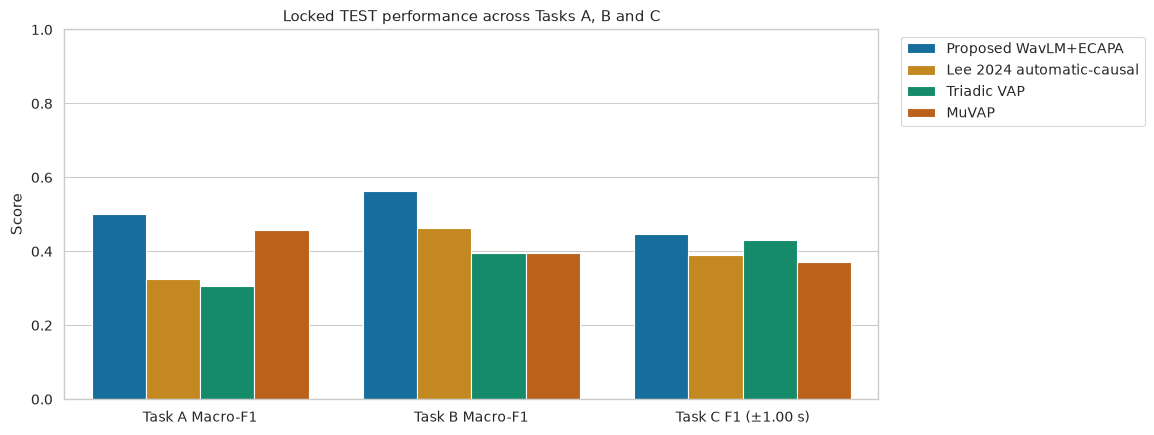

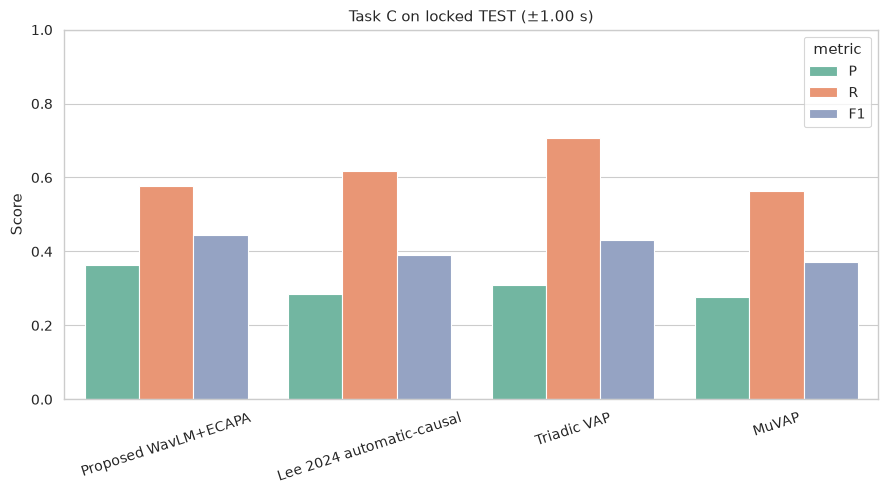

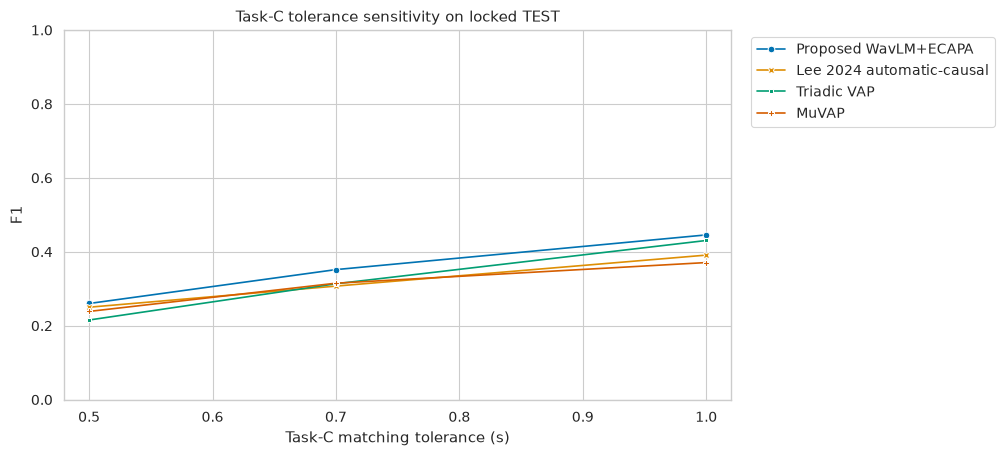

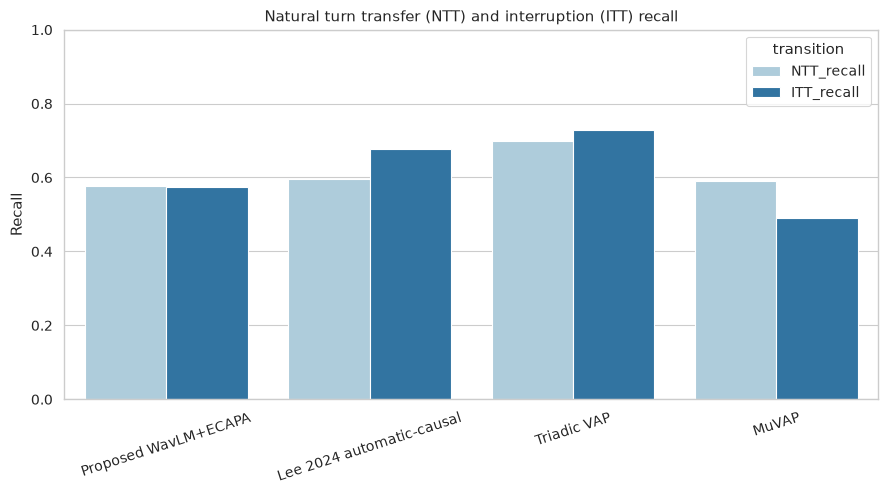

  artists = ax.bxp(**boxplot_kws)
  artists = ax.bxp(**boxplot_kws)
  artists = ax.bxp(**boxplot_kws)
  artists = ax.bxp(**boxplot_kws)
  artists = ax.bxp(**boxplot_kws)


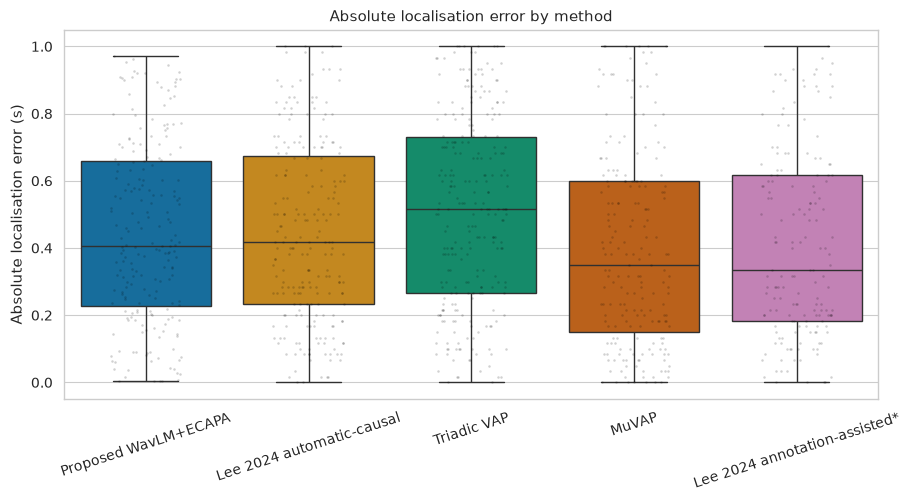

  artists = ax.bxp(**boxplot_kws)
  artists = ax.bxp(**boxplot_kws)
  artists = ax.bxp(**boxplot_kws)
  artists = ax.bxp(**boxplot_kws)
  artists = ax.bxp(**boxplot_kws)


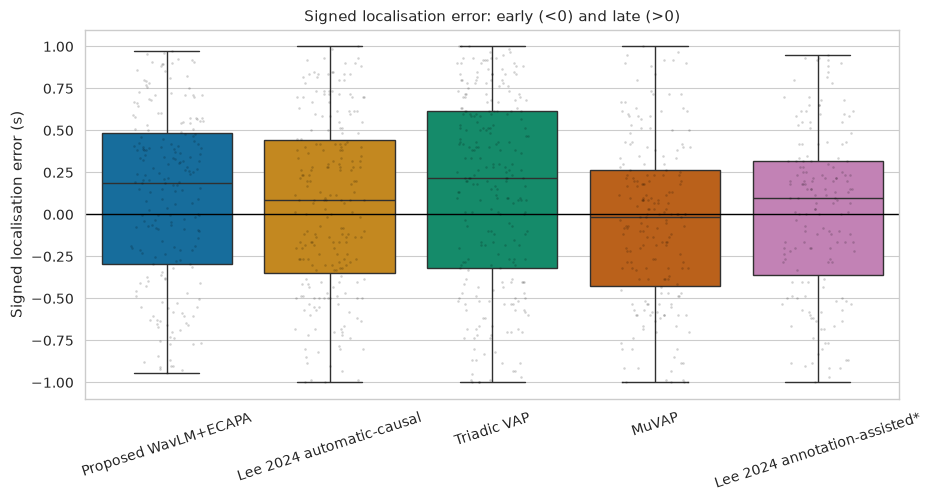

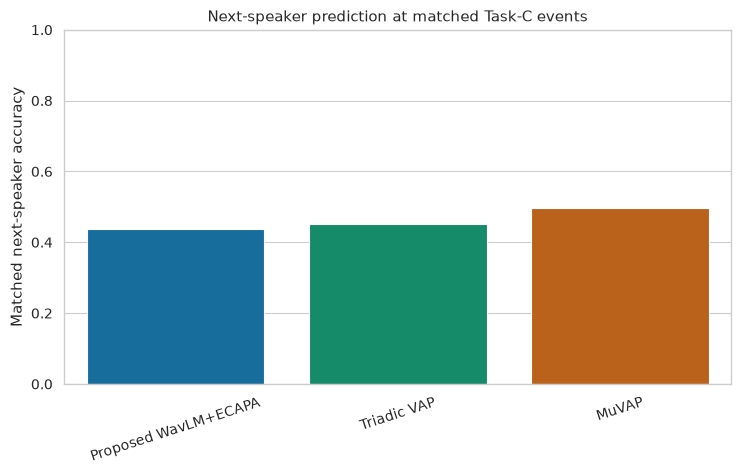

Article figures written: 14 files


In [50]:
# Article figures from committed TEST results
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="paper", font_scale=1.15)
METHOD_ORDER = [
    "Proposed_WavLM_ECAPA_frozen", "Lee2024_automatic_causal",
    "TriadicVAP_adapted", "MuVAP_adapted", "Lee2024_annotation_assisted",
]
HEADLINE_ORDER = METHOD_ORDER[:4]
METHOD_LABEL = {
    "Proposed_WavLM_ECAPA_frozen": "Proposed WavLM+ECAPA",
    "Lee2024_automatic_causal": "Lee 2024 automatic-causal",
    "TriadicVAP_adapted": "Triadic VAP",
    "MuVAP_adapted": "MuVAP",
    "Lee2024_annotation_assisted": "Lee 2024 annotation-assisted*",
}
PALETTE = dict(zip(METHOD_ORDER, sns.color_palette("colorblind", len(METHOD_ORDER))))

def save_article_figure(fig, stem):
    png = FINAL_FIG_ROOT / f"{stem}.png"
    pdf = FINAL_FIG_ROOT / f"{stem}.pdf"
    fig.savefig(png, dpi=300, bbox_inches="tight")
    fig.savefig(pdf, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    return str(png), str(pdf)

FIGURE_FILES = []

# Figure 1: Tasks A/B/C headline comparison (Macro-F1 for A/B; F1 for C).
_a = TASKA_RESULTS[["method", "MacroF1"]].rename(columns={"MacroF1": "score"}).assign(task="Task A Macro-F1")
_b = TASKB_RESULTS[["method", "MacroF1"]].rename(columns={"MacroF1": "score"}).assign(task="Task B Macro-F1")
_c = PRIMARY_TASKC[["method", "F1"]].rename(columns={"F1": "score"}).assign(task="Task C F1 (±1.00 s)")
_abc = pd.concat([_a, _b, _c], ignore_index=True)
_abc = _abc[_abc["method"].isin(HEADLINE_ORDER)].copy()
_abc["label"] = _abc["method"].map(METHOD_LABEL)
fig, ax = plt.subplots(figsize=(10.5, 4.8))
sns.barplot(data=_abc, x="task", y="score", hue="label", hue_order=[METHOD_LABEL[m] for m in HEADLINE_ORDER], palette=[PALETTE[m] for m in HEADLINE_ORDER], ax=ax)
ax.set_ylim(0, 1); ax.set_xlabel(""); ax.set_ylabel("Score"); ax.legend(title="", bbox_to_anchor=(1.02, 1), loc="upper left")
ax.set_title("Locked TEST performance across Tasks A, B and C")
FIGURE_FILES += list(save_article_figure(fig, "fig_final_test_tasks_ABC"))

# Figure 2: Task-C precision/recall/F1 at the primary tolerance.
_prf = PRIMARY_TASKC.melt(id_vars="method", value_vars=["P", "R", "F1"], var_name="metric", value_name="score")
_prf = _prf[_prf["method"].isin(HEADLINE_ORDER)].copy()
_prf["label"] = _prf["method"].map(METHOD_LABEL)
fig, ax = plt.subplots(figsize=(10.5, 4.8))
sns.barplot(data=_prf, x="label", y="score", hue="metric", palette="Set2", ax=ax)
ax.set_ylim(0, 1); ax.set_xlabel(""); ax.set_ylabel("Score"); ax.tick_params(axis="x", rotation=18); ax.set_title("Task C on locked TEST (±1.00 s)")
FIGURE_FILES += list(save_article_figure(fig, "fig_final_test_taskC_PRF"))

# Figure 3: tolerance sensitivity.
_tol = TASKC_RESULTS.copy(); _tol["label"] = _tol["method"].map(METHOD_LABEL)
_tol = _tol[_tol["method"].isin(HEADLINE_ORDER)].copy()
fig, ax = plt.subplots(figsize=(8.6, 4.8))
sns.lineplot(data=_tol, x="tolerance", y="F1", hue="label", style="label", markers=True, dashes=False, palette=[PALETTE[m] for m in HEADLINE_ORDER], ax=ax)
ax.set_xlim(.48, 1.02); ax.set_ylim(0, 1); ax.set_xlabel("Task-C matching tolerance (s)"); ax.set_ylabel("F1"); ax.set_title("Task-C tolerance sensitivity on locked TEST")
ax.legend(title="", bbox_to_anchor=(1.02, 1), loc="upper left")
FIGURE_FILES += list(save_article_figure(fig, "fig_final_test_taskC_tolerance"))

# Figure 4: NTT versus ITT recall.
_sub = PRIMARY_TASKC.melt(id_vars="method", value_vars=["NTT_recall", "ITT_recall"], var_name="transition", value_name="recall")
_sub = _sub[_sub["method"].isin(HEADLINE_ORDER)].copy()
_sub["label"] = _sub["method"].map(METHOD_LABEL)
fig, ax = plt.subplots(figsize=(10.5, 4.8))
sns.barplot(data=_sub, x="label", y="recall", hue="transition", palette="Paired", ax=ax)
ax.set_ylim(0, 1); ax.set_xlabel(""); ax.set_ylabel("Recall"); ax.tick_params(axis="x", rotation=18); ax.set_title("Natural turn transfer (NTT) and interruption (ITT) recall")
FIGURE_FILES += list(save_article_figure(fig, "fig_final_test_NTT_ITT"))

# Figures 5–6: localisation error distributions of matched events.
_loc = LOCALISATION_RESULTS[np.isclose(LOCALISATION_RESULTS["tolerance"].to_numpy(float), float(PRIMARY_EVENT_TOLERANCE))].copy()
_loc["label"] = _loc["method"].map(METHOD_LABEL)
for _value, _ylabel, _stem, _title in [
    ("abs_error", "Absolute localisation error (s)", "fig_final_test_localisation_absolute", "Absolute localisation error by method"),
    ("error", "Signed localisation error (s)", "fig_final_test_localisation_signed", "Signed localisation error: early (<0) and late (>0)"),
]:
    fig, ax = plt.subplots(figsize=(10.5, 4.8))
    if len(_loc):
        sns.boxplot(data=_loc, x="label", y=_value, order=[METHOD_LABEL[m] for m in METHOD_ORDER], hue="label", hue_order=[METHOD_LABEL[m] for m in METHOD_ORDER], palette=dict(zip([METHOD_LABEL[m] for m in METHOD_ORDER], [PALETTE[m] for m in METHOD_ORDER])), legend=False, showfliers=False, ax=ax)
        sns.stripplot(data=_loc, x="label", y=_value, order=[METHOD_LABEL[m] for m in METHOD_ORDER], color="black", alpha=.18, size=1.8, jitter=.22, ax=ax)
    else:
        ax.text(.5, .5, "No matched TEST events at this tolerance", ha="center", va="center", transform=ax.transAxes)
        ax.set_xticks([])
    if _value == "error": ax.axhline(0, color="black", lw=1)
    ax.set_xlabel(""); ax.set_ylabel(_ylabel); ax.tick_params(axis="x", rotation=18); ax.set_title(_title)
    FIGURE_FILES += list(save_article_figure(fig, _stem))

# Figure 7: matched next-speaker accuracy, where a method emits identities.
_nsp = PRIMARY_TASKC[["method", "matched_next_speaker_accuracy", "n_matched_next_speaker"]].dropna(subset=["matched_next_speaker_accuracy"]).copy()
_nsp["label"] = _nsp["method"].map(METHOD_LABEL)
fig, ax = plt.subplots(figsize=(8.6, 4.6))
if len(_nsp):
    sns.barplot(data=_nsp, x="label", y="matched_next_speaker_accuracy", hue="label", palette=dict(zip(_nsp["label"], [PALETTE[m] for m in _nsp["method"]])), legend=False, ax=ax)
else:
    ax.text(.5, .5, "No matched events with predicted speaker identities", ha="center", va="center", transform=ax.transAxes)
    ax.set_xticks([])
ax.set_ylim(0, 1); ax.set_xlabel(""); ax.set_ylabel("Matched next-speaker accuracy"); ax.tick_params(axis="x", rotation=18); ax.set_title("Next-speaker prediction at matched Task-C events")
FIGURE_FILES += list(save_article_figure(fig, "fig_final_test_next_speaker"))

pd.DataFrame({"figure_file": FIGURE_FILES}).to_csv(FINAL_RESULT_ROOT / "article_figure_manifest.csv", index=False)
print("Article figures written:", len(FIGURE_FILES), "files")

In [51]:
# Final checks
FINAL_AUDIT = []
def final_ck(name, condition, detail=""):
    FINAL_AUDIT.append({"check": name, "status": "PASS" if bool(condition) else "FAIL", "detail": str(detail)})

final_ck("final_mode", RUN_MODE == "final", RUN_MODE)
final_ck("locked_group", ACTIVE_SPLIT["test_group"] == FINAL_TEST_GROUP_ID, ACTIVE_SPLIT["test_group"])
final_ck("method_set_exact", set(METHOD_EVENTS) == set(HEADLINE_METHODS) | {"Lee2024_annotation_assisted"}, sorted(METHOD_EVENTS))
final_ck("headline_methods_exact", set(HEADLINE_METHODS) == {"Proposed_WavLM_ECAPA_frozen", "Lee2024_automatic_causal", "TriadicVAP_adapted", "MuVAP_adapted"}, sorted(HEADLINE_METHODS))
final_ck("annotation_secondary", "Lee2024_annotation_assisted" in METHOD_EVENTS and "Lee2024_annotation_assisted" not in HEADLINE_METHODS)
final_ck("prediction_commit_precedes_scoring", PREDICTION_COMMIT.get("created_before_test_event_scoring") is True)
final_ck("prediction_hashes_present", len(PREDICTION_HASHES) == 10, len(PREDICTION_HASHES))
final_ck(
    "continuous_prediction_hashes_unchanged",
    all(_v17_sha256_file(Path(path)) == PREDICTION_HASHES[key] for key, path in PREDICTION_FILES.items()),
)
final_ck("transition_event_labels_unlocked_only_after_commit", TEST_TRANSITION_EVENT_LABELS_UNLOCKED and GROUND_TRUTH_UNLOCK_COMMIT_FINGERPRINT == PREDICTION_COMMIT["commit_fingerprint"])
final_ck("taskAB_prediction_hashes_present", len(TASKAB_HASHES) == 10, len(TASKAB_HASHES))
final_ck(
    "taskAB_prediction_hashes_unchanged",
    all(_v17_sha256_file(Path(path)) == TASKAB_HASHES[key] for key, path in TASKAB_FILES.items()),
)
final_ck("comparator_split_frozen", FROZEN_COMPARATORS.get("split_fingerprint") == _active_comparator_split_fp)
final_ck("comparator_input_contracts_frozen", FROZEN_COMPARATORS.get("input_contracts") == dict(INPUT_CONTRACTS))
final_ck("lee24_automatic_external_artifact_used", isinstance(_lee24_automatic_artifact, dict) and LEE24_AUTOMATIC_FROZEN is _lee24_automatic_artifact["bundle"])
final_ck("taskA_all_methods", set(TASKA_RESULTS.method) == set(METHOD_EVENTS), sorted(TASKA_RESULTS.method))
final_ck("taskB_all_methods", set(TASKB_RESULTS.method) == set(METHOD_EVENTS), sorted(TASKB_RESULTS.method))
final_ck("taskC_all_tolerances", set(np.round(TASKC_RESULTS.tolerance, 2)) == {.5, .7, 1.0})
final_ck("taskC_all_methods", set(TASKC_RESULTS.method) == set(METHOD_EVENTS))
final_ck("localisation_saved", (FINAL_RESULT_ROOT / "final_test_localisation_matches.csv").is_file())
final_ck("next_speaker_reported", len(NEXT_SPEAKER_RESULTS) == 10 and (FINAL_RESULT_ROOT / "final_test_next_speaker.csv").is_file(), len(NEXT_SPEAKER_RESULTS))
final_ck("ntt_itt_reported", {"NTT_recall", "ITT_recall"}.issubset(TASKC_RESULTS.columns))
final_ck("figures_exist", len(FIGURE_FILES) >= 14 and all(Path(p).is_file() for p in FIGURE_FILES), len(FIGURE_FILES))
final_ck("no_force_retraining", not any(bool(globals()[n]) for n in globals() if n.startswith("FORCE_")))

# Every method must have every tolerance exactly once, not merely the union.
_expected_pairs = {(m, t) for m in METHOD_EVENTS for t in (.5, .7, 1.0)}
_actual_pairs = list(zip(TASKC_RESULTS.method.astype(str), TASKC_RESULTS.tolerance.astype(float)))
final_ck("taskC_exact_method_tolerance_product", len(_actual_pairs) == len(_expected_pairs) and set(_actual_pairs) == _expected_pairs)
_expected_nsp = {(m, setting) for m in METHOD_EVENTS for setting in ("TaskA_oracle_SHIFT", "TaskC_matched_events")}
final_ck("next_speaker_exact_method_setting_product", len(NEXT_SPEAKER_RESULTS) == len(_expected_nsp) and set(zip(NEXT_SPEAKER_RESULTS.method, NEXT_SPEAKER_RESULTS.setting)) == _expected_nsp)
final_ck("taskA_rows_unique", len(TASKA_RESULTS) == len(METHOD_EVENTS))
final_ck("taskB_rows_unique", len(TASKB_RESULTS) == len(METHOD_EVENTS))
_n_gt = sum(len(transition_events(str(s))) for s in TEST_SESSIONS)
final_ck("taskC_event_accounting", all(int(r.TP) + int(r.FP) == len(METHOD_EVENTS[r.method]) and int(r.TP) + int(r.FN) == _n_gt for r in TASKC_RESULTS.itertuples(index=False)))
verify_continuous_prediction_commit()
final_ck("continuous_manifest_and_live_predictions_verified", True)
_ab_disk = json.loads(TASKAB_COMMIT_PATH.read_text())
final_ck("taskAB_manifest_fingerprint_verified", _ab_disk == TASKAB_COMMIT and _ab_disk["commit_fingerprint"] == _v17_sha256_json({k: v for k, v in _ab_disk.items() if k != "commit_fingerprint"}, n=32))
final_ck("seven_nonempty_figure_pairs", len(FIGURE_FILES) == 14 and len(set(FIGURE_FILES)) == 14 and all(Path(p).stat().st_size > 0 for p in FIGURE_FILES))

final_ck(
    "disk_recovery_frames_bound_to_commit",
    (not RESUME_FROM_EXISTING_COMMIT) or all(
        frame.attrs.get("committed_key") == key and frame.attrs.get("committed_sha256") == PREDICTION_HASHES[key]
        for key, frame in {
            **{f"{m}:events": f for m, f in METHOD_EVENTS.items()},
            **{f"{m}:scores": f for m, f in METHOD_SCORES.items()},
        }.items()
    ),
    "resume=" + str(RESUME_FROM_EXISTING_COMMIT),
)

FINAL_AUDIT_DF = pd.DataFrame(FINAL_AUDIT)
display(FINAL_AUDIT_DF)
FINAL_AUDIT_DF.to_csv(FINAL_RESULT_ROOT / "final_locked_test_audit.csv", index=False)
if (FINAL_AUDIT_DF.status != "PASS").any():
    raise RuntimeError("FINAL LOCKED TEST AUDIT FAILED:\n" + FINAL_AUDIT_DF[FINAL_AUDIT_DF.status != "PASS"].to_string(index=False))
print("FINAL LOCKED TEST AUDIT: PASS")
print("Results:", FINAL_RESULT_ROOT)
print("Figures:", FINAL_FIG_ROOT)

,check,status,detail
0,final_mode,PASS,final
1,locked_group,PASS,01-28-2022
2,method_set_exact,PASS,"['Lee2024_annotation_assisted', 'Lee2024_autom..."
3,headline_methods_exact,PASS,"['Lee2024_automatic_causal', 'MuVAP_adapted', ..."
4,annotation_secondary,PASS,
5,prediction_commit_precedes_scoring,PASS,
6,prediction_hashes_present,PASS,10
7,continuous_prediction_hashes_unchanged,PASS,
8,transition_event_labels_unlocked_only_after_co...,PASS,
9,taskAB_prediction_hashes_present,PASS,10


FINAL LOCKED TEST AUDIT: PASS
Results: <MULTITPC_ROOT>/runs/MultiTPC_MASTER_R11_TASKABC_AUX_AUDIO_V7/comparators_final_v1/final_locked_test/results
Figures: <MULTITPC_ROOT>/runs/MultiTPC_MASTER_R11_TASKABC_AUX_AUDIO_V7/comparators_final_v1/final_locked_test/figures
